In [1]:
# ============================================================
# RARE26 GastroNet Extension — Cell 1
# Drive mount, folder verification, file inventory and SHA-256
# ============================================================

from google.colab import drive
drive.mount("/content/drive")

from pathlib import Path
import hashlib
import json
import os
import platform
from datetime import datetime, timezone

import pandas as pd
import torch

# ------------------------------------------------------------
# 1. Main project paths
# ------------------------------------------------------------
PROJECT_ROOT = Path(
    "/content/drive/MyDrive/RARE26_GastroNet_Weights"
)

SOURCE_DIR = PROJECT_ROOT / "source_checkpoints"
INVENTORY_DIR = PROJECT_ROOT / "inventory"

OUTPUT_DIRS = [
    INVENTORY_DIR,
    PROJECT_ROOT / "configs",
    PROJECT_ROOT / "models",
    PROJECT_ROOT / "logs",
    PROJECT_ROOT / "predictions",
    PROJECT_ROOT / "figures",
    PROJECT_ROOT / "thresholds",
    PROJECT_ROOT / "centre_analysis",
    PROJECT_ROOT / "ensembles",
    PROJECT_ROOT / "final_package",
]

for directory in OUTPUT_DIRS:
    directory.mkdir(parents=True, exist_ok=True)

if not SOURCE_DIR.exists():
    raise FileNotFoundError(
        f"Checkpoint folder not found:\n{SOURCE_DIR}"
    )

# ------------------------------------------------------------
# 2. Expected checkpoints
# ------------------------------------------------------------
expected_groups = {
    "RN50_Billion_Scale_GastroNet5M_DINOv1": {
        "RN50_Billion-Scale-SWSL%2BGastroNet-5M_DINOv1.pth",
        "RN50_Billion-Scale-SWSL+GastroNet-5M_DINOv1.pth",
    },
    "RN50_GastroNet1M_DINOv1": {
        "RN50_GastroNet-1M_DINOv1.pth",
    },
    "RN50_GastroNet200K_DINOv1": {
        "RN50_GastroNet-200K_DINOv1.pth",
    },
    "RN50_GastroNet5M_DINOv1": {
        "RN50_GastroNet-5M_DINOv1.pth",
    },
    "RN50_GastroNet5M_MOCOv2": {
        "RN50_GastroNet-5M_MOCOv2.pth",
    },
    "RN50_GastroNet5M_SIMCLRv2": {
        "RN50_GastroNet-5M_SIMCLRv2.pth",
    },
    "ViT_Base_DINOv2": {
        "dinov2.pth",
    },
    "ViT_Small_GastroNet5M_DINOv1": {
        "VITS_GastroNet-5M_DINOv1.pth",
    },
}

# ------------------------------------------------------------
# 3. Helper functions
# ------------------------------------------------------------
def sha256_file(file_path: Path, chunk_size: int = 8 * 1024 * 1024) -> str:
    """Calculate SHA-256 without loading the full checkpoint into RAM."""
    digest = hashlib.sha256()

    with file_path.open("rb") as file_handle:
        while True:
            chunk = file_handle.read(chunk_size)
            if not chunk:
                break
            digest.update(chunk)

    return digest.hexdigest()


def identify_checkpoint(filename: str) -> str:
    for model_id, allowed_names in expected_groups.items():
        if filename in allowed_names:
            return model_id
    return "UNRECOGNIZED"


# ------------------------------------------------------------
# 4. Scan checkpoint directory
# ------------------------------------------------------------
checkpoint_files = sorted(
    [
        file_path
        for file_path in SOURCE_DIR.iterdir()
        if file_path.is_file() and file_path.suffix.lower() == ".pth"
    ],
    key=lambda path: path.name.lower(),
)

print(f"Checkpoint directory:\n{SOURCE_DIR}")
print(f"\n.pth files found: {len(checkpoint_files)}")

if not checkpoint_files:
    raise RuntimeError("No .pth checkpoint files were found.")

# ------------------------------------------------------------
# 5. Build full inventory
# ------------------------------------------------------------
inventory_rows = []

for index, file_path in enumerate(checkpoint_files, start=1):
    file_size_bytes = file_path.stat().st_size
    model_id = identify_checkpoint(file_path.name)

    print(
        f"\n[{index}/{len(checkpoint_files)}] Processing:"
        f"\n{file_path.name}"
        f"\nSize: {file_size_bytes / (1024**2):.2f} MB"
    )

    checksum = sha256_file(file_path)

    inventory_rows.append(
        {
            "model_id": model_id,
            "filename": file_path.name,
            "extension": file_path.suffix.lower(),
            "size_bytes": file_size_bytes,
            "size_mb": round(file_size_bytes / (1024**2), 3),
            "sha256": checksum,
            "absolute_path": str(file_path),
            "modified_utc": datetime.fromtimestamp(
                file_path.stat().st_mtime,
                tz=timezone.utc,
            ).isoformat(),
            "recognized": model_id != "UNRECOGNIZED",
        }
    )

inventory_df = pd.DataFrame(inventory_rows)

# ------------------------------------------------------------
# 6. Confirm expected model groups
# ------------------------------------------------------------
found_model_ids = set(inventory_df["model_id"].tolist())

missing_model_ids = sorted(
    set(expected_groups.keys()) - found_model_ids
)

unrecognized_files = inventory_df.loc[
    inventory_df["model_id"] == "UNRECOGNIZED",
    "filename",
].tolist()

duplicate_model_ids = (
    inventory_df[
        inventory_df["model_id"] != "UNRECOGNIZED"
    ]
    .groupby("model_id")
    .size()
)

duplicate_model_ids = duplicate_model_ids[
    duplicate_model_ids > 1
].to_dict()

# ------------------------------------------------------------
# 7. Save inventory records
# ------------------------------------------------------------
csv_path = INVENTORY_DIR / "gastronet_checkpoint_inventory.csv"
json_path = INVENTORY_DIR / "gastronet_checkpoint_inventory.json"
environment_path = INVENTORY_DIR / "initial_environment_record.json"

inventory_df.to_csv(csv_path, index=False)

with json_path.open("w", encoding="utf-8") as file_handle:
    json.dump(
        inventory_rows,
        file_handle,
        indent=2,
        ensure_ascii=False,
    )

environment_record = {
    "created_utc": datetime.now(timezone.utc).isoformat(),
    "project_root": str(PROJECT_ROOT),
    "source_checkpoint_directory": str(SOURCE_DIR),
    "python_version": platform.python_version(),
    "pytorch_version": torch.__version__,
    "cuda_available": torch.cuda.is_available(),
    "cuda_device": (
        torch.cuda.get_device_name(0)
        if torch.cuda.is_available()
        else None
    ),
    "checkpoint_count": len(checkpoint_files),
    "missing_model_ids": missing_model_ids,
    "unrecognized_files": unrecognized_files,
    "duplicate_model_ids": duplicate_model_ids,
}

with environment_path.open("w", encoding="utf-8") as file_handle:
    json.dump(
        environment_record,
        file_handle,
        indent=2,
        ensure_ascii=False,
    )

# ------------------------------------------------------------
# 8. Display final verification report
# ------------------------------------------------------------
display(
    inventory_df[
        [
            "model_id",
            "filename",
            "size_mb",
            "sha256",
            "recognized",
        ]
    ]
)

print("\n" + "=" * 70)
print("FINAL CHECKPOINT VERIFICATION")
print("=" * 70)

print(f"Total .pth files: {len(checkpoint_files)}")
print(f"Recognized files: {int(inventory_df['recognized'].sum())}")

if missing_model_ids:
    print("\nMissing expected models:")
    for model_id in missing_model_ids:
        print(f"  - {model_id}")
else:
    print("\nAll 8 expected model variants were found.")

if unrecognized_files:
    print("\nUnrecognized filenames:")
    for filename in unrecognized_files:
        print(f"  - {filename}")
else:
    print("No unexpected checkpoint filename was found.")

if duplicate_model_ids:
    print("\nDuplicate model variants:")
    for model_id, count in duplicate_model_ids.items():
        print(f"  - {model_id}: {count} files")
else:
    print("No duplicate model variant was found.")

print("\nInventory saved to:")
print(csv_path)
print(json_path)
print(environment_path)

if (
    len(checkpoint_files) == 8
    and not missing_model_ids
    and not unrecognized_files
    and not duplicate_model_ids
):
    print("\nSTATUS: CHECKPOINT_INVENTORY_COMPLETE")
else:
    print("\nSTATUS: CHECKPOINT_INVENTORY_NEEDS_REVIEW")

Mounted at /content/drive
Checkpoint directory:
/content/drive/MyDrive/RARE26_GastroNet_Weights/source_checkpoints

.pth files found: 8

[1/8] Processing:
dinov2.pth
Size: 416.31 MB

[2/8] Processing:
RN50_Billion-Scale-SWSL%2BGastroNet-5M_DINOv1.pth
Size: 89.99 MB

[3/8] Processing:
RN50_GastroNet-1M_DINOv1.pth
Size: 89.98 MB

[4/8] Processing:
RN50_GastroNet-200K_DINOv1.pth
Size: 89.98 MB

[5/8] Processing:
RN50_GastroNet-5M_DINOv1.pth
Size: 89.98 MB

[6/8] Processing:
RN50_GastroNet-5M_MOCOv2.pth
Size: 89.98 MB

[7/8] Processing:
RN50_GastroNet-5M_SIMCLRv2.pth
Size: 89.98 MB

[8/8] Processing:
VITS_GastroNet-5M_DINOv1.pth
Size: 82.70 MB


,model_id,filename,size_mb,sha256,recognized
0,ViT_Base_DINOv2,dinov2.pth,416.310,20ab749ec4bfdd53a79fc82784d04d9480d87d9f122b87...,True
1,RN50_Billion_Scale_GastroNet5M_DINOv1,RN50_Billion-Scale-SWSL%2BGastroNet-5M_DINOv1.pth,89.985,5688929fea4437031604001495fb77fb18cdc2ff92ae24...,True
2,RN50_GastroNet1M_DINOv1,RN50_GastroNet-1M_DINOv1.pth,89.979,ced56c7b86f76b267c46220d17c30615f92c9a8e1202e9...,True
3,RN50_GastroNet200K_DINOv1,RN50_GastroNet-200K_DINOv1.pth,89.980,2dbf41d5123202c151467c361112ee4da8c18f96cf3e3e...,True
4,RN50_GastroNet5M_DINOv1,RN50_GastroNet-5M_DINOv1.pth,89.979,5ae8e09cea634179e8caf95dbead1a86d7ce05d1e934c8...,True
5,RN50_GastroNet5M_MOCOv2,RN50_GastroNet-5M_MOCOv2.pth,89.979,695b892942b8862c03bf80d00da9934eeb7040511a2775...,True
6,RN50_GastroNet5M_SIMCLRv2,RN50_GastroNet-5M_SIMCLRv2.pth,89.980,8d520d19ea72ca3fcb41cf737fc6f9842d5c25c9d1e17f...,True
7,ViT_Small_GastroNet5M_DINOv1,VITS_GastroNet-5M_DINOv1.pth,82.700,383c7a9a026cc7a8ecf0a201713714f91f51384fcacb0a...,True



FINAL CHECKPOINT VERIFICATION
Total .pth files: 8
Recognized files: 8

All 8 expected model variants were found.
No unexpected checkpoint filename was found.
No duplicate model variant was found.

Inventory saved to:
/content/drive/MyDrive/RARE26_GastroNet_Weights/inventory/gastronet_checkpoint_inventory.csv
/content/drive/MyDrive/RARE26_GastroNet_Weights/inventory/gastronet_checkpoint_inventory.json
/content/drive/MyDrive/RARE26_GastroNet_Weights/inventory/initial_environment_record.json

STATUS: CHECKPOINT_INVENTORY_COMPLETE


In [2]:
# ============================================================
# RARE26 GastroNet Extension — Cell 2
# Priority checkpoint structure and ResNet-50 compatibility
# ============================================================

from pathlib import Path
from collections.abc import Mapping
from datetime import datetime, timezone

import json
import pandas as pd
import torch
import torchvision
from torchvision.models import resnet50

# ------------------------------------------------------------
# 1. Paths
# ------------------------------------------------------------
PROJECT_ROOT = Path(
    "/content/drive/MyDrive/RARE26_GastroNet_Weights"
)

CHECKPOINT_PATH = (
    PROJECT_ROOT
    / "source_checkpoints"
    / "RN50_GastroNet-5M_DINOv1.pth"
)

INVENTORY_DIR = PROJECT_ROOT / "inventory"
RESULTS_DIR = PROJECT_ROOT / "results"

INVENTORY_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

if not CHECKPOINT_PATH.exists():
    raise FileNotFoundError(
        f"Priority checkpoint not found:\n{CHECKPOINT_PATH}"
    )

print("=" * 72)
print("CELL 2: GASTRONET RESNET-50 CHECKPOINT INSPECTION")
print("=" * 72)

print(f"\nCheckpoint:\n{CHECKPOINT_PATH}")
print(
    f"\nFile size: "
    f"{CHECKPOINT_PATH.stat().st_size / (1024 ** 2):.3f} MB"
)

# ------------------------------------------------------------
# 2. Load safely on CPU
# ------------------------------------------------------------
try:
    checkpoint = torch.load(
        CHECKPOINT_PATH,
        map_location="cpu",
        weights_only=True,
    )

except Exception as error:
    raise RuntimeError(
        "\nThe checkpoint could not be loaded with "
        "weights_only=True.\n"
        "Do not rerun with weights_only=False yet.\n"
        "Send the complete error output for review.\n\n"
        f"Original error:\n{type(error).__name__}: {error}"
    ) from error

print("\nCheckpoint loaded successfully with weights_only=True.")
print(f"Top-level Python type: {type(checkpoint).__name__}")

# ------------------------------------------------------------
# 3. Summarize top-level structure
# ------------------------------------------------------------
def describe_value(value):
    if torch.is_tensor(value):
        return {
            "type": "Tensor",
            "shape": list(value.shape),
            "dtype": str(value.dtype),
        }

    if isinstance(value, Mapping):
        return {
            "type": type(value).__name__,
            "number_of_items": len(value),
        }

    if isinstance(value, (list, tuple)):
        return {
            "type": type(value).__name__,
            "length": len(value),
        }

    return {
        "type": type(value).__name__,
        "preview": str(value)[:200],
    }


if isinstance(checkpoint, Mapping):
    top_level_summary = {
        str(key): describe_value(value)
        for key, value in checkpoint.items()
    }

    print(f"Top-level number of entries: {len(checkpoint)}")
    print("\nTop-level keys:")

    for key in list(checkpoint.keys())[:50]:
        print(f"  - {key}")

else:
    top_level_summary = {
        "root": describe_value(checkpoint)
    }

# ------------------------------------------------------------
# 4. Find possible tensor state dictionaries recursively
# ------------------------------------------------------------
candidate_state_dicts = []


def collect_tensor_dictionaries(
    obj,
    path="root",
    depth=0,
    maximum_depth=5,
):
    if depth > maximum_depth:
        return

    if not isinstance(obj, Mapping):
        return

    tensor_items = {
        str(key): value
        for key, value in obj.items()
        if isinstance(key, str) and torch.is_tensor(value)
    }

    if len(tensor_items) >= 10:
        candidate_state_dicts.append(
            {
                "path": path,
                "state_dict": tensor_items,
                "tensor_count": len(tensor_items),
            }
        )

    for key, value in obj.items():
        if isinstance(value, Mapping):
            collect_tensor_dictionaries(
                value,
                path=f"{path}.{key}",
                depth=depth + 1,
                maximum_depth=maximum_depth,
            )


collect_tensor_dictionaries(checkpoint)

if not candidate_state_dicts:
    raise RuntimeError(
        "No plausible tensor state dictionary was found "
        "inside the checkpoint."
    )

print(
    f"\nPossible tensor state dictionaries found: "
    f"{len(candidate_state_dicts)}"
)

# ------------------------------------------------------------
# 5. Create reference torchvision ResNet-50
# ------------------------------------------------------------
reference_model = resnet50(weights=None)
reference_state = reference_model.state_dict()

reference_keys = set(reference_state.keys())
backbone_reference_keys = {
    key
    for key in reference_keys
    if not key.startswith("fc.")
}

print(
    f"\nTorchvision version: {torchvision.__version__}"
)
print(
    f"Reference ResNet-50 state keys: "
    f"{len(reference_keys)}"
)
print(
    f"Reference backbone keys excluding fc: "
    f"{len(backbone_reference_keys)}"
)

# ------------------------------------------------------------
# 6. Normalize common self-supervised checkpoint prefixes
# ------------------------------------------------------------
REMOVABLE_PREFIXES = (
    "module.",
    "backbone.",
    "encoder.",
    "model.",
    "network.",
    "student.",
    "teacher.",
    "base_encoder.",
)


def normalize_key(original_key):
    cleaned_key = original_key
    changed = True

    while changed:
        changed = False

        for prefix in REMOVABLE_PREFIXES:
            if cleaned_key.startswith(prefix):
                cleaned_key = cleaned_key[len(prefix):]
                changed = True

    return cleaned_key


# ------------------------------------------------------------
# 7. Compare every candidate with torchvision ResNet-50
# ------------------------------------------------------------
candidate_reports = []
candidate_objects = {}

for candidate_number, candidate in enumerate(
    candidate_state_dicts,
    start=1,
):
    source_state = candidate["state_dict"]

    normalized_state = {}

    for original_key, tensor in source_state.items():
        normalized_key = normalize_key(original_key)

        # Preserve the first occurrence if normalization
        # produces an accidental duplicate.
        if normalized_key not in normalized_state:
            normalized_state[normalized_key] = tensor

    exact_shape_matches = {}
    shape_mismatches = {}
    unexpected_keys = []

    for key, tensor in normalized_state.items():
        if key not in reference_state:
            unexpected_keys.append(key)

        elif tuple(tensor.shape) == tuple(
            reference_state[key].shape
        ):
            exact_shape_matches[key] = tensor

        else:
            shape_mismatches[key] = {
                "checkpoint_shape": list(tensor.shape),
                "reference_shape": list(
                    reference_state[key].shape
                ),
            }

    matched_keys = set(exact_shape_matches.keys())

    matched_backbone_keys = (
        matched_keys & backbone_reference_keys
    )

    backbone_coverage = (
        len(matched_backbone_keys)
        / len(backbone_reference_keys)
    )

    total_reference_coverage = (
        len(matched_keys)
        / len(reference_keys)
    )

    matched_parameter_count = sum(
        tensor.numel()
        for tensor in exact_shape_matches.values()
    )

    report = {
        "candidate_number": candidate_number,
        "checkpoint_path_inside_object": candidate["path"],
        "source_tensor_count": len(source_state),
        "normalized_tensor_count": len(normalized_state),
        "exact_shape_match_count": len(exact_shape_matches),
        "matched_backbone_key_count": len(
            matched_backbone_keys
        ),
        "total_backbone_key_count": len(
            backbone_reference_keys
        ),
        "backbone_coverage": backbone_coverage,
        "total_reference_coverage": total_reference_coverage,
        "matched_parameter_count": matched_parameter_count,
        "shape_mismatch_count": len(shape_mismatches),
        "unexpected_key_count": len(unexpected_keys),
    }

    candidate_reports.append(report)

    candidate_objects[candidate_number] = {
        "normalized_state": normalized_state,
        "loadable_state": exact_shape_matches,
        "shape_mismatches": shape_mismatches,
        "unexpected_keys": unexpected_keys,
    }

candidate_df = pd.DataFrame(candidate_reports)

candidate_df = candidate_df.sort_values(
    by=[
        "matched_backbone_key_count",
        "matched_parameter_count",
        "exact_shape_match_count",
    ],
    ascending=False,
).reset_index(drop=True)

# ------------------------------------------------------------
# 8. Select best compatible candidate
# ------------------------------------------------------------
best_candidate_number = int(
    candidate_df.iloc[0]["candidate_number"]
)

best_report = candidate_df.iloc[0].to_dict()
best_object = candidate_objects[best_candidate_number]

loadable_state = best_object["loadable_state"]

# Test actual non-strict loading into a fresh ResNet-50.
compatibility_model = resnet50(weights=None)

load_result = compatibility_model.load_state_dict(
    loadable_state,
    strict=False,
)

missing_keys = list(load_result.missing_keys)
unexpected_during_load = list(
    load_result.unexpected_keys
)

backbone_coverage = float(
    best_report["backbone_coverage"]
)

if backbone_coverage >= 0.98:
    compatibility_status = (
        "RESNET50_BACKBONE_COMPATIBLE"
    )

elif backbone_coverage >= 0.90:
    compatibility_status = (
        "RESNET50_BACKBONE_MOSTLY_COMPATIBLE"
    )

else:
    compatibility_status = (
        "RESNET50_COMPATIBILITY_NEEDS_REVIEW"
    )

# ------------------------------------------------------------
# 9. Create detailed key-level audit
# ------------------------------------------------------------
key_audit_rows = []

normalized_best_state = best_object["normalized_state"]

for reference_key, reference_tensor in reference_state.items():
    if reference_key not in normalized_best_state:
        status = "missing_from_checkpoint"
        checkpoint_shape = None

    else:
        checkpoint_tensor = normalized_best_state[
            reference_key
        ]

        checkpoint_shape = list(
            checkpoint_tensor.shape
        )

        if tuple(checkpoint_tensor.shape) == tuple(
            reference_tensor.shape
        ):
            status = "exact_shape_match"
        else:
            status = "shape_mismatch"

    key_audit_rows.append(
        {
            "reference_key": reference_key,
            "reference_shape": list(
                reference_tensor.shape
            ),
            "checkpoint_shape": checkpoint_shape,
            "status": status,
            "is_classifier_key": reference_key.startswith(
                "fc."
            ),
        }
    )

key_audit_df = pd.DataFrame(key_audit_rows)

# ------------------------------------------------------------
# 10. Save all reports to Drive
# ------------------------------------------------------------
candidate_csv_path = (
    INVENTORY_DIR
    / "cell2_rn50_dinov1_candidate_state_dicts.csv"
)

key_audit_csv_path = (
    INVENTORY_DIR
    / "cell2_rn50_dinov1_key_compatibility.csv"
)

json_report_path = (
    INVENTORY_DIR
    / "cell2_rn50_dinov1_structure_report.json"
)

text_summary_path = (
    RESULTS_DIR
    / "cell2_rn50_dinov1_compatibility_summary.txt"
)

candidate_df.to_csv(
    candidate_csv_path,
    index=False,
)

key_audit_df.to_csv(
    key_audit_csv_path,
    index=False,
)

full_report = {
    "created_utc": datetime.now(
        timezone.utc
    ).isoformat(),
    "checkpoint_filename": CHECKPOINT_PATH.name,
    "checkpoint_path": str(CHECKPOINT_PATH),
    "checkpoint_size_bytes": (
        CHECKPOINT_PATH.stat().st_size
    ),
    "loaded_with_weights_only": True,
    "top_level_type": type(checkpoint).__name__,
    "top_level_summary": top_level_summary,
    "candidate_state_dictionary_count": len(
        candidate_state_dicts
    ),
    "selected_candidate_number": (
        best_candidate_number
    ),
    "selected_candidate_report": best_report,
    "compatibility_status": compatibility_status,
    "missing_keys_after_non_strict_load": (
        missing_keys
    ),
    "unexpected_keys_after_non_strict_load": (
        unexpected_during_load
    ),
    "shape_mismatches": best_object[
        "shape_mismatches"
    ],
    "sample_unexpected_checkpoint_keys": (
        best_object["unexpected_keys"][:100]
    ),
    "pytorch_version": torch.__version__,
    "torchvision_version": torchvision.__version__,
}

with json_report_path.open(
    "w",
    encoding="utf-8",
) as file_handle:
    json.dump(
        full_report,
        file_handle,
        indent=2,
        ensure_ascii=False,
    )

summary_lines = [
    "RARE26 GastroNet Cell 2 Compatibility Summary",
    "=" * 55,
    f"Checkpoint: {CHECKPOINT_PATH.name}",
    f"Selected internal path: "
    f"{best_report['checkpoint_path_inside_object']}",
    f"Source tensors: "
    f"{int(best_report['source_tensor_count'])}",
    f"Exact ResNet-50 key/shape matches: "
    f"{int(best_report['exact_shape_match_count'])}",
    f"Backbone matched keys: "
    f"{int(best_report['matched_backbone_key_count'])}"
    f"/{int(best_report['total_backbone_key_count'])}",
    f"Backbone coverage: "
    f"{backbone_coverage:.4%}",
    f"Shape mismatches: "
    f"{int(best_report['shape_mismatch_count'])}",
    f"Unexpected checkpoint keys: "
    f"{int(best_report['unexpected_key_count'])}",
    f"Missing keys after non-strict load: "
    f"{len(missing_keys)}",
    f"Compatibility status: "
    f"{compatibility_status}",
]

text_summary_path.write_text(
    "\n".join(summary_lines),
    encoding="utf-8",
)

# ------------------------------------------------------------
# 11. Display final output
# ------------------------------------------------------------
print("\nCandidate state dictionaries:")
display(candidate_df)

print("\nSelected candidate key audit summary:")
display(
    key_audit_df["status"]
    .value_counts()
    .rename_axis("status")
    .reset_index(name="count")
)

print("\n" + "=" * 72)
print("FINAL RESNET-50 COMPATIBILITY REPORT")
print("=" * 72)

print(
    f"Selected internal checkpoint path: "
    f"{best_report['checkpoint_path_inside_object']}"
)

print(
    f"Exact compatible keys: "
    f"{int(best_report['exact_shape_match_count'])}"
)

print(
    f"Backbone coverage: "
    f"{int(best_report['matched_backbone_key_count'])}"
    f"/{int(best_report['total_backbone_key_count'])} "
    f"({backbone_coverage:.2%})"
)

print(
    f"Shape mismatches: "
    f"{int(best_report['shape_mismatch_count'])}"
)

print(
    f"Missing keys after loading: "
    f"{len(missing_keys)}"
)

if missing_keys:
    print("\nFirst missing keys:")
    for key in missing_keys[:20]:
        print(f"  - {key}")

print(f"\nSTATUS: {compatibility_status}")

print("\nReports saved to:")
print(candidate_csv_path)
print(key_audit_csv_path)
print(json_report_path)
print(text_summary_path)

CELL 2: GASTRONET RESNET-50 CHECKPOINT INSPECTION

Checkpoint:
/content/drive/MyDrive/RARE26_GastroNet_Weights/source_checkpoints/RN50_GastroNet-5M_DINOv1.pth

File size: 89.979 MB

Checkpoint loaded successfully with weights_only=True.
Top-level Python type: OrderedDict
Top-level number of entries: 318

Top-level keys:
  - conv1.weight
  - bn1.weight
  - bn1.bias
  - bn1.running_mean
  - bn1.running_var
  - bn1.num_batches_tracked
  - layer1.0.conv1.weight
  - layer1.0.bn1.weight
  - layer1.0.bn1.bias
  - layer1.0.bn1.running_mean
  - layer1.0.bn1.running_var
  - layer1.0.bn1.num_batches_tracked
  - layer1.0.conv2.weight
  - layer1.0.bn2.weight
  - layer1.0.bn2.bias
  - layer1.0.bn2.running_mean
  - layer1.0.bn2.running_var
  - layer1.0.bn2.num_batches_tracked
  - layer1.0.conv3.weight
  - layer1.0.bn3.weight
  - layer1.0.bn3.bias
  - layer1.0.bn3.running_mean
  - layer1.0.bn3.running_var
  - layer1.0.bn3.num_batches_tracked
  - layer1.0.downsample.0.weight
  - layer1.0.downsample.1.w

,candidate_number,checkpoint_path_inside_object,source_tensor_count,normalized_tensor_count,exact_shape_match_count,matched_backbone_key_count,total_backbone_key_count,backbone_coverage,total_reference_coverage,matched_parameter_count,shape_mismatch_count,unexpected_key_count
0,1,root,318,318,318,318,318,1.0,0.99375,23561205,0,0



Selected candidate key audit summary:


,status,count
0,exact_shape_match,318
1,missing_from_checkpoint,2



FINAL RESNET-50 COMPATIBILITY REPORT
Selected internal checkpoint path: root
Exact compatible keys: 318
Backbone coverage: 318/318 (100.00%)
Shape mismatches: 0
Missing keys after loading: 2

First missing keys:
  - fc.weight
  - fc.bias

STATUS: RESNET50_BACKBONE_COMPATIBLE

Reports saved to:
/content/drive/MyDrive/RARE26_GastroNet_Weights/inventory/cell2_rn50_dinov1_candidate_state_dicts.csv
/content/drive/MyDrive/RARE26_GastroNet_Weights/inventory/cell2_rn50_dinov1_key_compatibility.csv
/content/drive/MyDrive/RARE26_GastroNet_Weights/inventory/cell2_rn50_dinov1_structure_report.json
/content/drive/MyDrive/RARE26_GastroNet_Weights/results/cell2_rn50_dinov1_compatibility_summary.txt


In [3]:
# ============================================================
# RARE26 GastroNet Extension — Cell 3
# Locked dataset and split integrity verification
# No training and no test-based model selection
# ============================================================

from pathlib import Path
from datetime import datetime, timezone
from collections import defaultdict

import json
import pandas as pd
from PIL import Image
from tqdm.auto import tqdm

# ------------------------------------------------------------
# 1. Project paths
# ------------------------------------------------------------
GASTRONET_ROOT = Path(
    "/content/drive/MyDrive/RARE26_GastroNet_Weights"
)

RARE26_ROOT = Path(
    "/content/drive/MyDrive/RARE26"
)

SPLIT_DIR = RARE26_ROOT / "splits"

TRAIN_CSV = SPLIT_DIR / "train_colab.csv"
VAL_CSV = SPLIT_DIR / "validation_colab.csv"
TEST_CSV = SPLIT_DIR / "test_colab.csv"

RESULTS_DIR = GASTRONET_ROOT / "results"
INVENTORY_DIR = GASTRONET_ROOT / "inventory"
CONFIG_DIR = GASTRONET_ROOT / "configs"

for directory in [
    RESULTS_DIR,
    INVENTORY_DIR,
    CONFIG_DIR,
]:
    directory.mkdir(parents=True, exist_ok=True)

required_split_files = {
    "train": TRAIN_CSV,
    "validation": VAL_CSV,
    "test": TEST_CSV,
}

for split_name, split_path in required_split_files.items():
    if not split_path.exists():
        raise FileNotFoundError(
            f"{split_name} split CSV not found:\n{split_path}"
        )

print("=" * 74)
print("CELL 3: LOCKED RARE26 DATASET AND SPLIT VERIFICATION")
print("=" * 74)

print("\nSplit directory:")
print(SPLIT_DIR)

# ------------------------------------------------------------
# 2. Load original locked CSV files
# ------------------------------------------------------------
split_frames = {}

for split_name, split_path in required_split_files.items():
    dataframe = pd.read_csv(split_path)
    dataframe["__split__"] = split_name
    dataframe["__row_number__"] = range(len(dataframe))

    split_frames[split_name] = dataframe

    print(
        f"\n{split_name.upper()} CSV:"
        f"\n  Path: {split_path}"
        f"\n  Rows: {len(dataframe)}"
        f"\n  Columns: {list(dataframe.columns)}"
    )

# ------------------------------------------------------------
# 3. Automatically identify important columns
# ------------------------------------------------------------
all_columns = list(split_frames["train"].columns)

PATH_CANDIDATES = [
    "filepath",
    "file_path",
    "image_path",
    "path",
    "filename",
    "file_name",
    "image",
    "image_name",
    "png_path",
]

LABEL_CANDIDATES = [
    "label",
    "target",
    "class",
    "diagnosis",
    "category",
    "y",
]

CENTRE_CANDIDATES = [
    "centre",
    "center",
    "centre_name",
    "center_name",
    "site",
    "hospital",
    "source_center",
    "source_centre",
]


def find_column(columns, candidates):
    lower_map = {
        str(column).lower(): column
        for column in columns
    }

    for candidate in candidates:
        if candidate.lower() in lower_map:
            return lower_map[candidate.lower()]

    return None


path_column = find_column(all_columns, PATH_CANDIDATES)
label_column = find_column(all_columns, LABEL_CANDIDATES)
centre_column = find_column(all_columns, CENTRE_CANDIDATES)

if path_column is None:
    raise RuntimeError(
        "Image path or filename column could not be detected.\n"
        f"Available columns: {all_columns}"
    )

if label_column is None:
    raise RuntimeError(
        "Label column could not be detected.\n"
        f"Available columns: {all_columns}"
    )

print("\nDetected columns:")
print(f"  Image/path column: {path_column}")
print(f"  Label column:      {label_column}")
print(f"  Centre column:     {centre_column}")

# ------------------------------------------------------------
# 4. Normalize labels and centre names
# ------------------------------------------------------------
def normalize_label(value):
    text = str(value).strip().lower()

    normal_values = {
        "0",
        "0.0",
        "ndbe",
        "normal",
        "negative",
        "non-dysplastic",
        "non_dysplastic",
        "non dysplastic",
    }

    positive_values = {
        "1",
        "1.0",
        "neo",
        "neoplasia",
        "positive",
        "abnormal",
        "dysplasia",
    }

    if text in normal_values:
        return 0

    if text in positive_values:
        return 1

    try:
        numeric_value = float(value)

        if numeric_value == 0:
            return 0

        if numeric_value == 1:
            return 1

    except Exception:
        pass

    return None


def normalize_centre(value):
    if value is None or pd.isna(value):
        return None

    text = str(value).strip().lower()

    text = (
        text.replace("-", "_")
        .replace(" ", "_")
        .replace("centre", "center")
    )

    center_1_values = {
        "1",
        "1.0",
        "c1",
        "center1",
        "center_1",
        "site1",
        "site_1",
    }

    center_2_values = {
        "2",
        "2.0",
        "c2",
        "center2",
        "center_2",
        "site2",
        "site_2",
    }

    if text in center_1_values:
        return "center_1"

    if text in center_2_values:
        return "center_2"

    return text


# ------------------------------------------------------------
# 5. Build image index from existing Drive folders
# ------------------------------------------------------------
candidate_image_roots = [
    RARE26_ROOT / "dataset",
    Path("/content/drive/MyDrive/RARE26 Phase2/input"),
    RARE26_ROOT,
]

image_extensions = {
    ".png",
    ".jpg",
    ".jpeg",
    ".bmp",
    ".tif",
    ".tiff",
}

basename_index = defaultdict(list)
full_path_index = {}

print("\nSearching existing Drive folders for image files...")

for candidate_root in candidate_image_roots:
    if not candidate_root.exists():
        print(f"  Skipped missing root: {candidate_root}")
        continue

    print(f"  Scanning: {candidate_root}")

    for image_path in candidate_root.rglob("*"):
        if (
            image_path.is_file()
            and image_path.suffix.lower() in image_extensions
        ):
            resolved_string = str(image_path.resolve())
            full_path_index[resolved_string] = image_path
            basename_index[image_path.name].append(image_path)

print(
    f"\nUnique image basenames indexed: "
    f"{len(basename_index)}"
)

# ------------------------------------------------------------
# 6. Resolve each split record to a real image
# ------------------------------------------------------------
def resolve_image_path(raw_value):
    if pd.isna(raw_value):
        return None, "missing_csv_value"

    raw_text = str(raw_value).strip()
    raw_path = Path(raw_text)

    direct_candidates = [
        raw_path,
        RARE26_ROOT / raw_text,
        RARE26_ROOT / "dataset" / raw_text,
    ]

    for candidate in direct_candidates:
        try:
            if candidate.exists() and candidate.is_file():
                return candidate, "direct_path"
        except OSError:
            pass

    basename = raw_path.name
    matches = basename_index.get(basename, [])

    if len(matches) == 1:
        return matches[0], "unique_basename"

    if len(matches) > 1:
        return None, "ambiguous_basename"

    return None, "not_found"


audit_rows = []

for split_name, dataframe in split_frames.items():
    for _, row in dataframe.iterrows():
        resolved_path, resolution_status = resolve_image_path(
            row[path_column]
        )

        normalized_label = normalize_label(
            row[label_column]
        )

        normalized_centre = (
            normalize_centre(row[centre_column])
            if centre_column is not None
            else None
        )

        audit_rows.append(
            {
                "split": split_name,
                "row_number": int(row["__row_number__"]),
                "original_path_value": str(row[path_column]),
                "basename": Path(
                    str(row[path_column])
                ).name,
                "resolved_path": (
                    str(resolved_path)
                    if resolved_path is not None
                    else None
                ),
                "resolution_status": resolution_status,
                "file_exists": (
                    resolved_path is not None
                    and resolved_path.exists()
                ),
                "raw_label": str(row[label_column]),
                "normalized_label": normalized_label,
                "raw_centre": (
                    str(row[centre_column])
                    if centre_column is not None
                    else None
                ),
                "normalized_centre": normalized_centre,
            }
        )

audit_df = pd.DataFrame(audit_rows)

# ------------------------------------------------------------
# 7. Verify image readability
# ------------------------------------------------------------
readability_status = []
image_modes = []
image_sizes = []

print("\nChecking image readability...")

for resolved_path in tqdm(
    audit_df["resolved_path"].tolist(),
    total=len(audit_df),
):
    if resolved_path is None or pd.isna(resolved_path):
        readability_status.append(False)
        image_modes.append(None)
        image_sizes.append(None)
        continue

    try:
        with Image.open(resolved_path) as image:
            image.verify()

        with Image.open(resolved_path) as image:
            image_modes.append(image.mode)
            image_sizes.append(
                f"{image.width}x{image.height}"
            )

        readability_status.append(True)

    except Exception:
        readability_status.append(False)
        image_modes.append(None)
        image_sizes.append(None)

audit_df["image_readable"] = readability_status
audit_df["image_mode"] = image_modes
audit_df["image_size"] = image_sizes

# ------------------------------------------------------------
# 8. Expected locked split counts
# ------------------------------------------------------------
expected_counts = {
    "train": {
        "total": 2159,
        "normal": 2050,
        "positive": 109,
    },
    "validation": {
        "total": 461,
        "normal": 438,
        "positive": 23,
    },
    "test": {
        "total": 468,
        "normal": 442,
        "positive": 26,
    },
}

summary_rows = []

for split_name in [
    "train",
    "validation",
    "test",
]:
    split_audit = audit_df[
        audit_df["split"] == split_name
    ]

    actual_total = len(split_audit)

    actual_normal = int(
        (split_audit["normalized_label"] == 0).sum()
    )

    actual_positive = int(
        (split_audit["normalized_label"] == 1).sum()
    )

    found_files = int(
        split_audit["file_exists"].sum()
    )

    readable_files = int(
        split_audit["image_readable"].sum()
    )

    unknown_labels = int(
        split_audit["normalized_label"].isna().sum()
    )

    summary_rows.append(
        {
            "split": split_name,
            "expected_total": expected_counts[
                split_name
            ]["total"],
            "actual_total": actual_total,
            "expected_normal": expected_counts[
                split_name
            ]["normal"],
            "actual_normal": actual_normal,
            "expected_positive": expected_counts[
                split_name
            ]["positive"],
            "actual_positive": actual_positive,
            "resolved_files": found_files,
            "readable_files": readable_files,
            "unknown_labels": unknown_labels,
            "count_match": (
                actual_total
                == expected_counts[split_name]["total"]
                and actual_normal
                == expected_counts[split_name]["normal"]
                and actual_positive
                == expected_counts[split_name]["positive"]
            ),
            "all_files_resolved": (
                found_files == actual_total
            ),
            "all_files_readable": (
                readable_files == actual_total
            ),
        }
    )

summary_df = pd.DataFrame(summary_rows)

# ------------------------------------------------------------
# 9. Check overlap between splits
# ------------------------------------------------------------
split_basename_sets = {
    split_name: set(
        audit_df.loc[
            audit_df["split"] == split_name,
            "basename",
        ].tolist()
    )
    for split_name in [
        "train",
        "validation",
        "test",
    ]
}

train_val_overlap = sorted(
    split_basename_sets["train"]
    & split_basename_sets["validation"]
)

train_test_overlap = sorted(
    split_basename_sets["train"]
    & split_basename_sets["test"]
)

val_test_overlap = sorted(
    split_basename_sets["validation"]
    & split_basename_sets["test"]
)

duplicate_rows_inside_split = (
    audit_df.groupby(
        ["split", "basename"]
    )
    .size()
    .reset_index(name="count")
)

duplicate_rows_inside_split = duplicate_rows_inside_split[
    duplicate_rows_inside_split["count"] > 1
]

ambiguous_files = audit_df[
    audit_df["resolution_status"]
    == "ambiguous_basename"
]

missing_files = audit_df[
    audit_df["file_exists"] == False
]

unreadable_files = audit_df[
    audit_df["image_readable"] == False
]

# ------------------------------------------------------------
# 10. Optional per-centre summary
# ------------------------------------------------------------
if centre_column is not None:
    centre_summary_df = (
        audit_df.groupby(
            [
                "split",
                "normalized_centre",
                "normalized_label",
            ],
            dropna=False,
        )
        .size()
        .reset_index(name="count")
    )
else:
    centre_summary_df = pd.DataFrame(
        columns=[
            "split",
            "normalized_centre",
            "normalized_label",
            "count",
        ]
    )

# ------------------------------------------------------------
# 11. Determine final verification status
# ------------------------------------------------------------
all_count_checks_passed = bool(
    summary_df["count_match"].all()
)

all_files_resolved = bool(
    summary_df["all_files_resolved"].all()
)

all_files_readable = bool(
    summary_df["all_files_readable"].all()
)

no_split_overlap = (
    len(train_val_overlap) == 0
    and len(train_test_overlap) == 0
    and len(val_test_overlap) == 0
)

no_internal_duplicates = (
    len(duplicate_rows_inside_split) == 0
)

all_labels_valid = (
    int(audit_df["normalized_label"].isna().sum())
    == 0
)

if (
    all_count_checks_passed
    and all_files_resolved
    and all_files_readable
    and no_split_overlap
    and no_internal_duplicates
    and all_labels_valid
):
    final_status = (
        "LOCKED_DATASET_AND_SPLITS_VERIFIED"
    )
else:
    final_status = (
        "DATASET_OR_SPLIT_VERIFICATION_NEEDS_REVIEW"
    )

# ------------------------------------------------------------
# 12. Save all outputs to Drive
# ------------------------------------------------------------
audit_csv_path = (
    INVENTORY_DIR
    / "cell3_locked_dataset_row_audit.csv"
)

summary_csv_path = (
    RESULTS_DIR
    / "cell3_locked_split_summary.csv"
)

centre_csv_path = (
    RESULTS_DIR
    / "cell3_locked_split_centre_summary.csv"
)

duplicate_csv_path = (
    INVENTORY_DIR
    / "cell3_duplicate_rows_inside_splits.csv"
)

missing_csv_path = (
    INVENTORY_DIR
    / "cell3_missing_or_unresolved_images.csv"
)

verification_json_path = (
    RESULTS_DIR
    / "cell3_locked_dataset_verification.json"
)

config_json_path = (
    CONFIG_DIR
    / "cell3_dataset_source_and_split_config.json"
)

audit_df.to_csv(
    audit_csv_path,
    index=False,
)

summary_df.to_csv(
    summary_csv_path,
    index=False,
)

centre_summary_df.to_csv(
    centre_csv_path,
    index=False,
)

duplicate_rows_inside_split.to_csv(
    duplicate_csv_path,
    index=False,
)

missing_files.to_csv(
    missing_csv_path,
    index=False,
)

verification_record = {
    "created_utc": datetime.now(
        timezone.utc
    ).isoformat(),
    "rare26_root": str(RARE26_ROOT),
    "split_directory": str(SPLIT_DIR),
    "train_csv": str(TRAIN_CSV),
    "validation_csv": str(VAL_CSV),
    "test_csv": str(TEST_CSV),
    "detected_path_column": str(path_column),
    "detected_label_column": str(label_column),
    "detected_centre_column": (
        str(centre_column)
        if centre_column is not None
        else None
    ),
    "total_rows": len(audit_df),
    "total_resolved_files": int(
        audit_df["file_exists"].sum()
    ),
    "total_readable_files": int(
        audit_df["image_readable"].sum()
    ),
    "unknown_label_count": int(
        audit_df["normalized_label"].isna().sum()
    ),
    "train_validation_overlap_count": len(
        train_val_overlap
    ),
    "train_test_overlap_count": len(
        train_test_overlap
    ),
    "validation_test_overlap_count": len(
        val_test_overlap
    ),
    "duplicate_rows_inside_split_count": len(
        duplicate_rows_inside_split
    ),
    "ambiguous_file_count": len(
        ambiguous_files
    ),
    "missing_file_count": len(
        missing_files
    ),
    "unreadable_file_count": len(
        unreadable_files
    ),
    "final_status": final_status,
}

with verification_json_path.open(
    "w",
    encoding="utf-8",
) as file_handle:
    json.dump(
        verification_record,
        file_handle,
        indent=2,
        ensure_ascii=False,
    )

config_record = {
    "project_name": "RARE26 GastroNet Extension",
    "dataset_source": "Existing locked RARE26 dataset",
    "split_policy": "Reuse original locked train/validation/test CSV files",
    "test_selection_allowed": False,
    "train_csv": str(TRAIN_CSV),
    "validation_csv": str(VAL_CSV),
    "test_csv": str(TEST_CSV),
    "path_column": str(path_column),
    "label_column": str(label_column),
    "centre_column": (
        str(centre_column)
        if centre_column is not None
        else None
    ),
}

with config_json_path.open(
    "w",
    encoding="utf-8",
) as file_handle:
    json.dump(
        config_record,
        file_handle,
        indent=2,
        ensure_ascii=False,
    )

# ------------------------------------------------------------
# 13. Display final report
# ------------------------------------------------------------
print("\nLocked split summary:")
display(summary_df)

if centre_column is not None:
    print("\nPer-centre split summary:")
    display(centre_summary_df)

print("\n" + "=" * 74)
print("FINAL DATASET AND SPLIT VERIFICATION")
print("=" * 74)

print(
    f"Total split records: {len(audit_df)}"
)
print(
    f"Resolved image files: "
    f"{int(audit_df['file_exists'].sum())}"
    f"/{len(audit_df)}"
)
print(
    f"Readable image files: "
    f"{int(audit_df['image_readable'].sum())}"
    f"/{len(audit_df)}"
)

print(
    f"Train-validation overlap: "
    f"{len(train_val_overlap)}"
)
print(
    f"Train-test overlap: "
    f"{len(train_test_overlap)}"
)
print(
    f"Validation-test overlap: "
    f"{len(val_test_overlap)}"
)
print(
    f"Duplicate rows inside splits: "
    f"{len(duplicate_rows_inside_split)}"
)
print(
    f"Unknown labels: "
    f"{int(audit_df['normalized_label'].isna().sum())}"
)
print(
    f"Unresolved images: "
    f"{len(missing_files)}"
)

print(f"\nSTATUS: {final_status}")

print("\nOutputs saved to:")
print(audit_csv_path)
print(summary_csv_path)
print(centre_csv_path)
print(verification_json_path)
print(config_json_path)

CELL 3: LOCKED RARE26 DATASET AND SPLIT VERIFICATION

Split directory:
/content/drive/MyDrive/RARE26/splits

TRAIN CSV:
  Path: /content/drive/MyDrive/RARE26/splits/train_colab.csv
  Rows: 2159
  Columns: ['file_path', 'relative_path', 'center', 'class', 'label', 'sha256', 'split', 'colab_path', 'file_exists', '__split__', '__row_number__']

VALIDATION CSV:
  Path: /content/drive/MyDrive/RARE26/splits/validation_colab.csv
  Rows: 461
  Columns: ['file_path', 'relative_path', 'center', 'class', 'label', 'sha256', 'split', 'colab_path', 'file_exists', '__split__', '__row_number__']

TEST CSV:
  Path: /content/drive/MyDrive/RARE26/splits/test_colab.csv
  Rows: 468
  Columns: ['file_path', 'relative_path', 'center', 'class', 'label', 'sha256', 'split', 'colab_path', 'file_exists', '__split__', '__row_number__']

Detected columns:
  Image/path column: file_path
  Label column:      label
  Centre column:     center

Searching existing Drive folders for image files...
  Scanning: /content/dr

  0%|          | 0/3088 [00:00<?, ?it/s]


Locked split summary:


,split,expected_total,actual_total,expected_normal,actual_normal,expected_positive,actual_positive,resolved_files,readable_files,unknown_labels,count_match,all_files_resolved,all_files_readable
0,train,2159,2159,2050,2050,109,109,0,0,0,True,False,False
1,validation,461,461,438,438,23,23,0,0,0,True,False,False
2,test,468,468,442,442,26,26,0,0,0,True,False,False



Per-centre split summary:


,split,normalized_centre,normalized_label,count
0,test,center_1,0,334
1,test,center_1,1,10
2,test,center_2,0,108
3,test,center_2,1,16
4,train,center_1,0,1552
5,train,center_1,1,42
6,train,center_2,0,498
7,train,center_2,1,67
8,validation,center_1,0,332
9,validation,center_1,1,9



FINAL DATASET AND SPLIT VERIFICATION
Total split records: 3088
Resolved image files: 0/3088
Readable image files: 0/3088
Train-validation overlap: 0
Train-test overlap: 0
Validation-test overlap: 0
Duplicate rows inside splits: 0
Unknown labels: 0
Unresolved images: 3088

STATUS: DATASET_OR_SPLIT_VERIFICATION_NEEDS_REVIEW

Outputs saved to:
/content/drive/MyDrive/RARE26_GastroNet_Weights/inventory/cell3_locked_dataset_row_audit.csv
/content/drive/MyDrive/RARE26_GastroNet_Weights/results/cell3_locked_split_summary.csv
/content/drive/MyDrive/RARE26_GastroNet_Weights/results/cell3_locked_split_centre_summary.csv
/content/drive/MyDrive/RARE26_GastroNet_Weights/results/cell3_locked_dataset_verification.json
/content/drive/MyDrive/RARE26_GastroNet_Weights/configs/cell3_dataset_source_and_split_config.json


In [4]:
# ============================================================
# RARE26 GastroNet Extension — Cell 3A
# Locate original dataset storage and inspect locked path columns
# Diagnostic only: no extraction, no training, no modification
# ============================================================

from pathlib import Path
import pandas as pd

RARE26_ROOT = Path("/content/drive/MyDrive/RARE26")
PHASE2_ROOT = Path("/content/drive/MyDrive/RARE26 Phase2")
SPLIT_DIR = RARE26_ROOT / "splits"

TRAIN_CSV = SPLIT_DIR / "train_colab.csv"
VAL_CSV = SPLIT_DIR / "validation_colab.csv"
TEST_CSV = SPLIT_DIR / "test_colab.csv"

print("=" * 76)
print("CELL 3A: LOCATE ORIGINAL RARE26 IMAGE STORAGE")
print("=" * 76)

# ------------------------------------------------------------
# 1. Inspect path-related values stored in locked CSVs
# ------------------------------------------------------------
train_df = pd.read_csv(TRAIN_CSV)
val_df = pd.read_csv(VAL_CSV)
test_df = pd.read_csv(TEST_CSV)

path_columns = [
    column
    for column in [
        "file_path",
        "relative_path",
        "colab_path",
        "center",
        "class",
        "label",
    ]
    if column in train_df.columns
]

print("\nAvailable relevant columns:")
print(path_columns)

print("\nFirst 5 TRAIN records:")
display(train_df[path_columns].head())

print("\nFirst 3 VALIDATION records:")
display(val_df[path_columns].head(3))

print("\nFirst 3 TEST records:")
display(test_df[path_columns].head(3))

# ------------------------------------------------------------
# 2. Show path examples separately
# ------------------------------------------------------------
for column in ["file_path", "relative_path", "colab_path"]:
    if column in train_df.columns:
        print(f"\nExample values from '{column}':")
        for value in train_df[column].dropna().astype(str).head(5):
            print(f"  - {value}")

# ------------------------------------------------------------
# 3. Search likely Drive roots for archives and image files
# ------------------------------------------------------------
search_roots = [
    RARE26_ROOT,
    PHASE2_ROOT,
]

archive_extensions = {
    ".zip",
    ".tar",
    ".gz",
    ".tgz",
    ".bz2",
    ".xz",
    ".7z",
    ".rar",
}

image_extensions = {
    ".png",
    ".jpg",
    ".jpeg",
    ".bmp",
    ".tif",
    ".tiff",
    ".webp",
}

archive_files = []
image_files = []
all_files = []

print("\nSearching Drive project folders...")

for root in search_roots:
    if not root.exists():
        print(f"\nMissing root: {root}")
        continue

    print(f"\nScanning: {root}")

    for path in root.rglob("*"):
        if not path.is_file():
            continue

        all_files.append(path)

        suffixes = "".join(path.suffixes).lower()
        suffix = path.suffix.lower()

        if (
            suffix in archive_extensions
            or suffixes.endswith(".tar.gz")
            or suffixes.endswith(".tar.bz2")
            or suffixes.endswith(".tar.xz")
        ):
            archive_files.append(path)

        if suffix in image_extensions:
            image_files.append(path)

print("\n" + "=" * 76)
print("STORAGE DISCOVERY SUMMARY")
print("=" * 76)

print(f"Total files found under project roots: {len(all_files)}")
print(f"Direct image files found: {len(image_files)}")
print(f"Archive files found: {len(archive_files)}")

# ------------------------------------------------------------
# 4. Display archive inventory
# ------------------------------------------------------------
if archive_files:
    archive_rows = []

    for path in sorted(archive_files):
        archive_rows.append(
            {
                "filename": path.name,
                "size_mb": round(
                    path.stat().st_size / (1024 ** 2),
                    3,
                ),
                "path": str(path),
            }
        )

    archive_df = pd.DataFrame(archive_rows)

    print("\nPossible dataset archives:")
    display(archive_df)

else:
    print("\nNo standard archive file was detected.")

# ------------------------------------------------------------
# 5. Show direct image distribution
# ------------------------------------------------------------
if image_files:
    image_root_summary = {}

    for path in image_files:
        try:
            relative = path.relative_to(
                RARE26_ROOT
                if str(path).startswith(str(RARE26_ROOT))
                else PHASE2_ROOT
            )

            top_folder = relative.parts[0] if relative.parts else "."
        except Exception:
            top_folder = str(path.parent)

        image_root_summary[top_folder] = (
            image_root_summary.get(top_folder, 0) + 1
        )

    image_summary_df = pd.DataFrame(
        [
            {
                "top_folder": folder,
                "image_count": count,
            }
            for folder, count in sorted(
                image_root_summary.items(),
                key=lambda item: item[1],
                reverse=True,
            )
        ]
    )

    print("\nDirect image-file distribution:")
    display(image_summary_df)

    print("\nFirst 20 direct image paths:")
    for path in image_files[:20]:
        print(f"  - {path}")

else:
    print("\nNo direct image files were detected.")

# ------------------------------------------------------------
# 6. Inspect immediate dataset/input folder contents
# ------------------------------------------------------------
folders_to_inspect = [
    RARE26_ROOT / "dataset",
    RARE26_ROOT / "splits",
    PHASE2_ROOT / "input",
]

for folder in folders_to_inspect:
    print("\n" + "-" * 76)
    print(f"Folder inspection: {folder}")

    if not folder.exists():
        print("Status: folder does not exist")
        continue

    immediate_items = sorted(folder.iterdir())

    print(f"Immediate item count: {len(immediate_items)}")

    for item in immediate_items[:100]:
        item_type = "DIR" if item.is_dir() else "FILE"

        size_text = ""

        if item.is_file():
            size_text = (
                f" | {item.stat().st_size / (1024 ** 2):.3f} MB"
            )

        print(f"  [{item_type}] {item.name}{size_text}")

print("\nSTATUS: DATASET_STORAGE_DISCOVERY_COMPLETE")

CELL 3A: LOCATE ORIGINAL RARE26 IMAGE STORAGE

Available relevant columns:
['file_path', 'relative_path', 'colab_path', 'center', 'class', 'label']

First 5 TRAIN records:


,file_path,relative_path,colab_path,center,class,label
0,C:\thesis\dataset\RARE25-train-data\center_1\n...,center_1/ndbe/af193b2896e542abb727eba4b15a453d...,/content/RARE26_data/center_1/ndbe/af193b2896e...,center_1,ndbe,0
1,C:\thesis\dataset\RARE25-train-data\center_1\n...,center_1/ndbe/7de471b77fdd4120abe7c05b98e404ec...,/content/RARE26_data/center_1/ndbe/7de471b77fd...,center_1,ndbe,0
2,C:\thesis\dataset\RARE25-train-data\center_1\n...,center_1/ndbe/7ca2ef852a1c40c69908168376866da8...,/content/RARE26_data/center_1/ndbe/7ca2ef852a1...,center_1,ndbe,0
3,C:\thesis\dataset\RARE25-train-data\center_1\n...,center_1/ndbe/9612fea866be4492a4339158a596a443...,/content/RARE26_data/center_1/ndbe/9612fea866b...,center_1,ndbe,0
4,C:\thesis\dataset\RARE25-train-data\center_1\n...,center_1/ndbe/48ead105875242b8b1eb8327d7b50688...,/content/RARE26_data/center_1/ndbe/48ead105875...,center_1,ndbe,0



First 3 VALIDATION records:


,file_path,relative_path,colab_path,center,class,label
0,C:\thesis\dataset\RARE25-train-data\center_1\n...,center_1/ndbe/6ae35f245d5a4a5c8c2c2daf3384f921...,/content/RARE26_data/center_1/ndbe/6ae35f245d5...,center_1,ndbe,0
1,C:\thesis\dataset\RARE25-train-data\center_1\n...,center_1/ndbe/4364ce4943784c1bbef94b6199968670...,/content/RARE26_data/center_1/ndbe/4364ce49437...,center_1,ndbe,0
2,C:\thesis\dataset\RARE25-train-data\center_1\n...,center_1/ndbe/3ae4fab4badc4842a049dc2c5af2dad7...,/content/RARE26_data/center_1/ndbe/3ae4fab4bad...,center_1,ndbe,0



First 3 TEST records:


...


Example values from 'file_path':
  - C:\thesis\dataset\RARE25-train-data\center_1\ndbe\af193b2896e542abb727eba4b15a453d.png
  - C:\thesis\dataset\RARE25-train-data\center_1\ndbe\7de471b77fdd4120abe7c05b98e404ec.png
  - C:\thesis\dataset\RARE25-train-data\center_1\ndbe\7ca2ef852a1c40c69908168376866da8.png
  - C:\thesis\dataset\RARE25-train-data\center_1\ndbe\9612fea866be4492a4339158a596a443.png
  - C:\thesis\dataset\RARE25-train-data\center_1\ndbe\48ead105875242b8b1eb8327d7b50688.png

Example values from 'relative_path':
  - center_1/ndbe/af193b2896e542abb727eba4b15a453d.png
  - center_1/ndbe/7de471b77fdd4120abe7c05b98e404ec.png
  - center_1/ndbe/7ca2ef852a1c40c69908168376866da8.png
  - center_1/ndbe/9612fea866be4492a4339158a596a443.png
  - center_1/ndbe/48ead105875242b8b1eb8327d7b50688.png

Example values from 'colab_path':
  - /content/RARE26_data/center_1/ndbe/af193b2896e542abb727eba4b15a453d.png
  - /content/RARE26_data/center_1/ndbe/7de471b77fdd4120abe7c05b98e404ec.png
  - /conten

,filename,size_mb,path
0,RARE25-train-data.zip,1206.599,/content/drive/MyDrive/RARE26/dataset/RARE25-t...



Direct image-file distribution:


,top_folder,image_count
0,results,35
1,/content/drive/MyDrive/RARE26 Phase2/figures,7
2,/content/drive/MyDrive/RARE26 Phase2/figures/p...,2



First 20 direct image paths:
  - /content/drive/MyDrive/RARE26/results/figures/baseline_loss_curve.png
  - /content/drive/MyDrive/RARE26/results/figures/baseline_accuracy_curve.png
  - /content/drive/MyDrive/RARE26/results/figures/baseline_confusion_matrix_default.png
  - /content/drive/MyDrive/RARE26/results/figures/baseline_confusion_matrix_high_recall.png
  - /content/drive/MyDrive/RARE26/results/figures/baseline_roc_curve.png
  - /content/drive/MyDrive/RARE26/results/figures/baseline_precision_recall_curve.png
  - /content/drive/MyDrive/RARE26/results/figures/baseline_vs_weighted_high_recall_scores.png
  - /content/drive/MyDrive/RARE26/results/figures/baseline_vs_weighted_false_positives.png
  - /content/drive/MyDrive/RARE26/results/figures/baseline_vs_weighted_auroc_auprc.png
  - /content/drive/MyDrive/RARE26/results/figures/three_model_high_recall_scores.png
  - /content/drive/MyDrive/RARE26/results/figures/three_model_high_recall_errors.png
  - /content/drive/MyDrive/RARE26/res

In [5]:
# ============================================================
# RARE26 GastroNet Extension — Cell 3B
# Restore exactly 3,088 locked images from the original ZIP
# Verify paths, readability, hashes, counts and split isolation
# ============================================================

from pathlib import Path, PurePosixPath
from datetime import datetime, timezone
import hashlib
import json
import shutil
import zipfile

import pandas as pd
from PIL import Image
from tqdm.auto import tqdm

# ------------------------------------------------------------
# 1. Canonical paths
# ------------------------------------------------------------
RARE26_ROOT = Path("/content/drive/MyDrive/RARE26")

GASTRONET_ROOT = Path(
    "/content/drive/MyDrive/RARE26_GastroNet_Weights"
)

ARCHIVE_PATH = (
    RARE26_ROOT
    / "dataset"
    / "RARE25-train-data.zip"
)

SPLIT_DIR = RARE26_ROOT / "splits"

SPLIT_PATHS = {
    "train": SPLIT_DIR / "train_colab.csv",
    "validation": SPLIT_DIR / "validation_colab.csv",
    "test": SPLIT_DIR / "test_colab.csv",
}

# Temporary Colab storage, matching the existing split CSV paths.
RUNTIME_ROOT = Path("/content/RARE26_data")

INVENTORY_DIR = GASTRONET_ROOT / "inventory"
RESULTS_DIR = GASTRONET_ROOT / "results"
CONFIG_DIR = GASTRONET_ROOT / "configs"
RUNTIME_SPLIT_DIR = CONFIG_DIR / "runtime_splits"

for directory in [
    INVENTORY_DIR,
    RESULTS_DIR,
    CONFIG_DIR,
    RUNTIME_SPLIT_DIR,
]:
    directory.mkdir(parents=True, exist_ok=True)

if not ARCHIVE_PATH.exists():
    raise FileNotFoundError(
        f"Original dataset ZIP not found:\n{ARCHIVE_PATH}"
    )

for split_name, split_path in SPLIT_PATHS.items():
    if not split_path.exists():
        raise FileNotFoundError(
            f"{split_name} split CSV not found:\n{split_path}"
        )

print("=" * 78)
print("CELL 3B: RESTORE AND VERIFY LOCKED RARE26 DATASET")
print("=" * 78)

print(f"\nArchive:\n{ARCHIVE_PATH}")
print(
    f"Archive size: "
    f"{ARCHIVE_PATH.stat().st_size / (1024 ** 2):.3f} MB"
)
print(f"\nTemporary runtime root:\n{RUNTIME_ROOT}")

# ------------------------------------------------------------
# 2. Load locked splits
# ------------------------------------------------------------
split_frames = []

for split_name, split_path in SPLIT_PATHS.items():
    dataframe = pd.read_csv(split_path).copy()
    dataframe["runtime_split"] = split_name

    if "relative_path" not in dataframe.columns:
        raise RuntimeError(
            f"'relative_path' is missing from {split_path}"
        )

    dataframe["normalized_relative_path"] = (
        dataframe["relative_path"]
        .astype(str)
        .str.replace("\\", "/", regex=False)
        .str.lstrip("./")
    )

    split_frames.append(dataframe)

all_records = pd.concat(
    split_frames,
    ignore_index=True,
)

print("\nLocked split records:")
print(
    all_records["runtime_split"]
    .value_counts()
    .reindex(["train", "validation", "test"])
)

# ------------------------------------------------------------
# 3. Validate locked split metadata before extraction
# ------------------------------------------------------------
expected_counts = {
    "train": {
        "total": 2159,
        "normal": 2050,
        "positive": 109,
    },
    "validation": {
        "total": 461,
        "normal": 438,
        "positive": 23,
    },
    "test": {
        "total": 468,
        "normal": 442,
        "positive": 26,
    },
}

metadata_summary_rows = []

for split_name in ["train", "validation", "test"]:
    subset = all_records[
        all_records["runtime_split"] == split_name
    ]

    actual_total = len(subset)
    actual_normal = int((subset["label"] == 0).sum())
    actual_positive = int((subset["label"] == 1).sum())

    expected = expected_counts[split_name]

    metadata_summary_rows.append(
        {
            "split": split_name,
            "expected_total": expected["total"],
            "actual_total": actual_total,
            "expected_normal": expected["normal"],
            "actual_normal": actual_normal,
            "expected_positive": expected["positive"],
            "actual_positive": actual_positive,
            "count_match": (
                actual_total == expected["total"]
                and actual_normal == expected["normal"]
                and actual_positive == expected["positive"]
            ),
        }
    )

metadata_summary_df = pd.DataFrame(
    metadata_summary_rows
)

duplicate_relative_paths = (
    all_records.groupby("normalized_relative_path")
    .size()
    .reset_index(name="count")
)

duplicate_relative_paths = duplicate_relative_paths[
    duplicate_relative_paths["count"] > 1
].copy()

unique_relative_paths = (
    all_records["normalized_relative_path"]
    .drop_duplicates()
    .tolist()
)

print(
    f"\nTotal locked records: {len(all_records)}"
)
print(
    f"Unique relative paths: {len(unique_relative_paths)}"
)
print(
    f"Duplicate relative paths across splits: "
    f"{len(duplicate_relative_paths)}"
)

if not metadata_summary_df["count_match"].all():
    raise RuntimeError(
        "Locked split class counts do not match the "
        "completed Phase 1/Phase 2 record."
    )

if len(all_records) != 3088:
    raise RuntimeError(
        f"Expected 3,088 locked records, found {len(all_records)}."
    )

if len(unique_relative_paths) != 3088:
    raise RuntimeError(
        "The locked split files do not contain exactly "
        "3,088 unique relative image paths."
    )

if len(duplicate_relative_paths) > 0:
    raise RuntimeError(
        "At least one image path appears in more than one split."
    )

# ------------------------------------------------------------
# 4. Verify centre/class metadata against relative paths
# ------------------------------------------------------------
def path_metadata(relative_path):
    parts = PurePosixPath(relative_path).parts

    if len(parts) < 3:
        return None, None

    return parts[-3], parts[-2]


path_centres = []
path_classes = []

for relative_path in all_records[
    "normalized_relative_path"
]:
    path_centre, path_class = path_metadata(relative_path)
    path_centres.append(path_centre)
    path_classes.append(path_class)

all_records["path_centre"] = path_centres
all_records["path_class"] = path_classes

all_records["centre_path_match"] = (
    all_records["center"].astype(str).str.lower()
    == all_records["path_centre"].astype(str).str.lower()
)

all_records["class_path_match"] = (
    all_records["class"].astype(str).str.lower()
    == all_records["path_class"].astype(str).str.lower()
)

centre_mismatch_count = int(
    (~all_records["centre_path_match"]).sum()
)

class_mismatch_count = int(
    (~all_records["class_path_match"]).sum()
)

print(
    f"Centre/path mismatches: {centre_mismatch_count}"
)
print(
    f"Class/path mismatches: {class_mismatch_count}"
)

if centre_mismatch_count > 0 or class_mismatch_count > 0:
    raise RuntimeError(
        "CSV centre/class metadata does not match "
        "the stored relative image paths."
    )

# ------------------------------------------------------------
# 5. Inspect ZIP and map each locked relative path
# ------------------------------------------------------------
def normalize_archive_name(name):
    return str(name).replace("\\", "/").lstrip("./")


def last_three_components(path_text):
    parts = PurePosixPath(path_text).parts

    if len(parts) < 3:
        return None

    return "/".join(parts[-3:])


zip_mapping_rows = []
resolved_member_map = {}
missing_archive_paths = []
ambiguous_archive_paths = []

print("\nReading ZIP member inventory...")

with zipfile.ZipFile(ARCHIVE_PATH, "r") as zip_file:
    file_members = [
        member
        for member in zip_file.infolist()
        if not member.is_dir()
    ]

    suffix_index = {}

    for member in file_members:
        normalized_member = normalize_archive_name(
            member.filename
        )

        suffix_key = last_three_components(
            normalized_member
        )

        if suffix_key is None:
            continue

        suffix_index.setdefault(
            suffix_key,
            [],
        ).append(member)

    print(
        f"Files stored inside ZIP: {len(file_members)}"
    )
    print(
        f"Unique three-component ZIP paths: "
        f"{len(suffix_index)}"
    )

    for relative_path in unique_relative_paths:
        key = last_three_components(relative_path)
        matches = suffix_index.get(key, [])

        if len(matches) == 1:
            resolved_member_map[relative_path] = matches[0]

            zip_mapping_rows.append(
                {
                    "relative_path": relative_path,
                    "archive_member": matches[0].filename,
                    "archive_size_bytes": matches[0].file_size,
                    "mapping_status": "unique_match",
                }
            )

        elif len(matches) == 0:
            missing_archive_paths.append(relative_path)

            zip_mapping_rows.append(
                {
                    "relative_path": relative_path,
                    "archive_member": None,
                    "archive_size_bytes": None,
                    "mapping_status": "missing",
                }
            )

        else:
            ambiguous_archive_paths.append(
                {
                    "relative_path": relative_path,
                    "candidate_members": [
                        member.filename
                        for member in matches
                    ],
                }
            )

            zip_mapping_rows.append(
                {
                    "relative_path": relative_path,
                    "archive_member": " | ".join(
                        member.filename
                        for member in matches
                    ),
                    "archive_size_bytes": None,
                    "mapping_status": "ambiguous",
                }
            )

zip_mapping_df = pd.DataFrame(zip_mapping_rows)

print(
    f"\nUnique locked-image ZIP matches: "
    f"{len(resolved_member_map)}/3088"
)
print(
    f"Missing locked images in ZIP: "
    f"{len(missing_archive_paths)}"
)
print(
    f"Ambiguous locked images in ZIP: "
    f"{len(ambiguous_archive_paths)}"
)

zip_mapping_path = (
    INVENTORY_DIR
    / "cell3b_zip_to_locked_split_mapping.csv"
)

zip_mapping_df.to_csv(
    zip_mapping_path,
    index=False,
)

if missing_archive_paths or ambiguous_archive_paths:
    issue_path = (
        INVENTORY_DIR
        / "cell3b_zip_mapping_issues.json"
    )

    issue_record = {
        "missing_archive_paths": missing_archive_paths,
        "ambiguous_archive_paths": ambiguous_archive_paths,
    }

    issue_path.write_text(
        json.dumps(
            issue_record,
            indent=2,
            ensure_ascii=False,
        ),
        encoding="utf-8",
    )

    raise RuntimeError(
        "The ZIP could not be mapped uniquely to all "
        "3,088 locked image paths. Review the saved issue file."
    )

# ------------------------------------------------------------
# 6. Extract exactly the 3,088 locked images
# ------------------------------------------------------------
RUNTIME_ROOT.mkdir(
    parents=True,
    exist_ok=True,
)

extracted_count = 0
reused_count = 0

print(
    "\nRestoring exactly 3,088 locked images "
    "to temporary Colab storage..."
)

with zipfile.ZipFile(ARCHIVE_PATH, "r") as zip_file:
    for relative_path in tqdm(
        unique_relative_paths,
        total=len(unique_relative_paths),
    ):
        member = resolved_member_map[relative_path]

        target_path = (
            RUNTIME_ROOT
            / Path(relative_path)
        )

        target_path.parent.mkdir(
            parents=True,
            exist_ok=True,
        )

        # Reuse only when the existing temporary file
        # has the exact size recorded inside the ZIP.
        if (
            target_path.exists()
            and target_path.is_file()
            and target_path.stat().st_size
            == member.file_size
        ):
            reused_count += 1
            continue

        with zip_file.open(member, "r") as source_file:
            with target_path.open("wb") as target_file:
                shutil.copyfileobj(
                    source_file,
                    target_file,
                    length=8 * 1024 * 1024,
                )

        extracted_count += 1

print(
    f"\nNewly extracted files: {extracted_count}"
)
print(
    f"Valid existing temporary files reused: {reused_count}"
)

# ------------------------------------------------------------
# 7. Verify readability and original SHA-256 hashes
# ------------------------------------------------------------
def calculate_sha256(
    file_path,
    chunk_size=8 * 1024 * 1024,
):
    digest = hashlib.sha256()

    with file_path.open("rb") as file_handle:
        while True:
            chunk = file_handle.read(chunk_size)

            if not chunk:
                break

            digest.update(chunk)

    return digest.hexdigest()


audit_rows = []

print(
    "\nVerifying all extracted images, labels and SHA-256 hashes..."
)

for _, row in tqdm(
    all_records.iterrows(),
    total=len(all_records),
):
    relative_path = row["normalized_relative_path"]

    runtime_path = (
        RUNTIME_ROOT
        / Path(relative_path)
    )

    exists = runtime_path.exists()
    readable = False
    image_mode = None
    image_width = None
    image_height = None
    actual_sha256 = None
    expected_sha256 = str(row["sha256"]).strip().lower()

    if exists:
        try:
            with Image.open(runtime_path) as image:
                image.verify()

            with Image.open(runtime_path) as image:
                image_mode = image.mode
                image_width = image.width
                image_height = image.height

            readable = True

        except Exception:
            readable = False

        if readable:
            actual_sha256 = calculate_sha256(
                runtime_path
            )

    hash_match = (
        actual_sha256 == expected_sha256
        if actual_sha256 is not None
        else False
    )

    expected_colab_path = str(
        RUNTIME_ROOT / Path(relative_path)
    )

    csv_colab_path_match = (
        str(row["colab_path"]) == expected_colab_path
    )

    audit_rows.append(
        {
            "split": row["runtime_split"],
            "relative_path": relative_path,
            "runtime_path": str(runtime_path),
            "file_exists": exists,
            "image_readable": readable,
            "image_mode": image_mode,
            "image_width": image_width,
            "image_height": image_height,
            "expected_sha256": expected_sha256,
            "actual_sha256": actual_sha256,
            "sha256_match": hash_match,
            "label": int(row["label"]),
            "center": row["center"],
            "class": row["class"],
            "csv_colab_path": row["colab_path"],
            "csv_colab_path_match": csv_colab_path_match,
        }
    )

audit_df = pd.DataFrame(audit_rows)

# ------------------------------------------------------------
# 8. Create final split summaries
# ------------------------------------------------------------
summary_rows = []

for split_name in ["train", "validation", "test"]:
    subset = audit_df[
        audit_df["split"] == split_name
    ]

    expected = expected_counts[split_name]

    actual_total = len(subset)
    actual_normal = int((subset["label"] == 0).sum())
    actual_positive = int((subset["label"] == 1).sum())

    summary_rows.append(
        {
            "split": split_name,
            "expected_total": expected["total"],
            "actual_total": actual_total,
            "expected_normal": expected["normal"],
            "actual_normal": actual_normal,
            "expected_positive": expected["positive"],
            "actual_positive": actual_positive,
            "resolved_files": int(
                subset["file_exists"].sum()
            ),
            "readable_files": int(
                subset["image_readable"].sum()
            ),
            "sha256_matches": int(
                subset["sha256_match"].sum()
            ),
            "colab_path_matches": int(
                subset["csv_colab_path_match"].sum()
            ),
            "count_match": (
                actual_total == expected["total"]
                and actual_normal == expected["normal"]
                and actual_positive == expected["positive"]
            ),
            "all_files_resolved": bool(
                subset["file_exists"].all()
            ),
            "all_files_readable": bool(
                subset["image_readable"].all()
            ),
            "all_hashes_match": bool(
                subset["sha256_match"].all()
            ),
            "all_colab_paths_match": bool(
                subset["csv_colab_path_match"].all()
            ),
        }
    )

summary_df = pd.DataFrame(summary_rows)

centre_summary_df = (
    audit_df.groupby(
        ["split", "center", "label"],
        dropna=False,
    )
    .size()
    .reset_index(name="count")
)

hash_mismatch_df = audit_df[
    ~audit_df["sha256_match"]
].copy()

unreadable_df = audit_df[
    ~audit_df["image_readable"]
].copy()

missing_runtime_df = audit_df[
    ~audit_df["file_exists"]
].copy()

# ------------------------------------------------------------
# 9. Save corrected canonical records
# ------------------------------------------------------------
# These overwrite the incomplete Cell 3 diagnostic records
# with the verified runtime records.
canonical_audit_path = (
    INVENTORY_DIR
    / "cell3_locked_dataset_row_audit.csv"
)

canonical_summary_path = (
    RESULTS_DIR
    / "cell3_locked_split_summary.csv"
)

canonical_centre_path = (
    RESULTS_DIR
    / "cell3_locked_split_centre_summary.csv"
)

verification_json_path = (
    RESULTS_DIR
    / "cell3_locked_dataset_verification.json"
)

hash_mismatch_path = (
    INVENTORY_DIR
    / "cell3b_sha256_mismatches.csv"
)

unreadable_path = (
    INVENTORY_DIR
    / "cell3b_unreadable_images.csv"
)

missing_runtime_path = (
    INVENTORY_DIR
    / "cell3b_missing_runtime_images.csv"
)

audit_df.to_csv(
    canonical_audit_path,
    index=False,
)

summary_df.to_csv(
    canonical_summary_path,
    index=False,
)

centre_summary_df.to_csv(
    canonical_centre_path,
    index=False,
)

hash_mismatch_df.to_csv(
    hash_mismatch_path,
    index=False,
)

unreadable_df.to_csv(
    unreadable_path,
    index=False,
)

missing_runtime_df.to_csv(
    missing_runtime_path,
    index=False,
)

# ------------------------------------------------------------
# 10. Save runtime versions of each locked split
# ------------------------------------------------------------
for split_name, split_path in SPLIT_PATHS.items():
    runtime_split_df = pd.read_csv(
        split_path
    ).copy()

    runtime_split_df["relative_path"] = (
        runtime_split_df["relative_path"]
        .astype(str)
        .str.replace("\\", "/", regex=False)
        .str.lstrip("./")
    )

    runtime_split_df["runtime_path"] = (
        runtime_split_df["relative_path"]
        .apply(
            lambda value: str(
                RUNTIME_ROOT / Path(value)
            )
        )
    )

    runtime_split_df["runtime_file_exists"] = (
        runtime_split_df["runtime_path"]
        .apply(lambda value: Path(value).exists())
    )

    runtime_split_output = (
        RUNTIME_SPLIT_DIR
        / f"{split_name}_runtime_verified.csv"
    )

    runtime_split_df.to_csv(
        runtime_split_output,
        index=False,
    )

# ------------------------------------------------------------
# 11. Determine final status
# ------------------------------------------------------------
all_checks_passed = (
    len(audit_df) == 3088
    and bool(summary_df["count_match"].all())
    and bool(summary_df["all_files_resolved"].all())
    and bool(summary_df["all_files_readable"].all())
    and bool(summary_df["all_hashes_match"].all())
    and bool(summary_df["all_colab_paths_match"].all())
    and len(hash_mismatch_df) == 0
    and len(unreadable_df) == 0
    and len(missing_runtime_df) == 0
    and len(duplicate_relative_paths) == 0
)

if all_checks_passed:
    final_status = (
        "LOCKED_DATASET_AND_SPLITS_VERIFIED"
    )
else:
    final_status = (
        "DATASET_OR_SPLIT_VERIFICATION_NEEDS_REVIEW"
    )

verification_record = {
    "created_utc": datetime.now(
        timezone.utc
    ).isoformat(),
    "archive_path": str(ARCHIVE_PATH),
    "archive_size_bytes": ARCHIVE_PATH.stat().st_size,
    "runtime_root": str(RUNTIME_ROOT),
    "locked_record_count": len(audit_df),
    "unique_relative_path_count": len(
        unique_relative_paths
    ),
    "archive_file_count": len(file_members),
    "archive_unique_locked_matches": len(
        resolved_member_map
    ),
    "newly_extracted_count": extracted_count,
    "reused_temporary_file_count": reused_count,
    "resolved_file_count": int(
        audit_df["file_exists"].sum()
    ),
    "readable_file_count": int(
        audit_df["image_readable"].sum()
    ),
    "sha256_match_count": int(
        audit_df["sha256_match"].sum()
    ),
    "csv_colab_path_match_count": int(
        audit_df["csv_colab_path_match"].sum()
    ),
    "centre_path_mismatch_count": centre_mismatch_count,
    "class_path_mismatch_count": class_mismatch_count,
    "cross_split_duplicate_path_count": len(
        duplicate_relative_paths
    ),
    "final_status": final_status,
    "scientific_rule": (
        "The held-out test set remains excluded from "
        "model, threshold, calibration and ensemble selection."
    ),
}

verification_json_path.write_text(
    json.dumps(
        verification_record,
        indent=2,
        ensure_ascii=False,
    ),
    encoding="utf-8",
)

# ------------------------------------------------------------
# 12. Display final verification
# ------------------------------------------------------------
print("\nVerified locked split summary:")
display(summary_df)

print("\nVerified per-centre summary:")
display(centre_summary_df)

print("\n" + "=" * 78)
print("FINAL RESTORATION AND INTEGRITY REPORT")
print("=" * 78)

print(
    f"Locked ZIP mappings: "
    f"{len(resolved_member_map)}/3088"
)
print(
    f"Runtime image files: "
    f"{int(audit_df['file_exists'].sum())}/3088"
)
print(
    f"Readable images: "
    f"{int(audit_df['image_readable'].sum())}/3088"
)
print(
    f"SHA-256 matches: "
    f"{int(audit_df['sha256_match'].sum())}/3088"
)
print(
    f"CSV Colab paths matched: "
    f"{int(audit_df['csv_colab_path_match'].sum())}/3088"
)
print(
    f"Hash mismatches: {len(hash_mismatch_df)}"
)
print(
    f"Unreadable images: {len(unreadable_df)}"
)
print(
    f"Missing runtime images: {len(missing_runtime_df)}"
)
print(
    f"Cross-split duplicate paths: "
    f"{len(duplicate_relative_paths)}"
)

print(f"\nSTATUS: {final_status}")

print("\nCanonical records saved to:")
print(canonical_audit_path)
print(canonical_summary_path)
print(canonical_centre_path)
print(verification_json_path)

print("\nVerified runtime splits saved under:")
print(RUNTIME_SPLIT_DIR)

CELL 3B: RESTORE AND VERIFY LOCKED RARE26 DATASET

Archive:
/content/drive/MyDrive/RARE26/dataset/RARE25-train-data.zip
Archive size: 1206.599 MB

Temporary runtime root:
/content/RARE26_data

Locked split records:
runtime_split
train         2159
validation     461
test           468
Name: count, dtype: int64

Total locked records: 3088
Unique relative paths: 3088
Duplicate relative paths across splits: 0
Centre/path mismatches: 0
Class/path mismatches: 0

Reading ZIP member inventory...
Files stored inside ZIP: 3095
Unique three-component ZIP paths: 3095

Unique locked-image ZIP matches: 3088/3088
Missing locked images in ZIP: 0
Ambiguous locked images in ZIP: 0

Restoring exactly 3,088 locked images to temporary Colab storage...


  0%|          | 0/3088 [00:00<?, ?it/s]


Newly extracted files: 3088
Valid existing temporary files reused: 0

Verifying all extracted images, labels and SHA-256 hashes...


  0%|          | 0/3088 [00:00<?, ?it/s]


Verified locked split summary:


,split,expected_total,actual_total,expected_normal,actual_normal,expected_positive,actual_positive,resolved_files,readable_files,sha256_matches,colab_path_matches,count_match,all_files_resolved,all_files_readable,all_hashes_match,all_colab_paths_match
0,train,2159,2159,2050,2050,109,109,2159,2159,2159,2159,True,True,True,True,True
1,validation,461,461,438,438,23,23,461,461,461,461,True,True,True,True,True
2,test,468,468,442,442,26,26,468,468,468,468,True,True,True,True,True



Verified per-centre summary:


,split,center,label,count
0,test,center_1,0,334
1,test,center_1,1,10
2,test,center_2,0,108
3,test,center_2,1,16
4,train,center_1,0,1552
5,train,center_1,1,42
6,train,center_2,0,498
7,train,center_2,1,67
8,validation,center_1,0,332
9,validation,center_1,1,9



FINAL RESTORATION AND INTEGRITY REPORT
Locked ZIP mappings: 3088/3088
Runtime image files: 3088/3088
Readable images: 3088/3088
SHA-256 matches: 3088/3088
CSV Colab paths matched: 3088/3088
Hash mismatches: 0
Unreadable images: 0
Missing runtime images: 0
Cross-split duplicate paths: 0

STATUS: LOCKED_DATASET_AND_SPLITS_VERIFIED

Canonical records saved to:
/content/drive/MyDrive/RARE26_GastroNet_Weights/inventory/cell3_locked_dataset_row_audit.csv
/content/drive/MyDrive/RARE26_GastroNet_Weights/results/cell3_locked_split_summary.csv
/content/drive/MyDrive/RARE26_GastroNet_Weights/results/cell3_locked_split_centre_summary.csv
/content/drive/MyDrive/RARE26_GastroNet_Weights/results/cell3_locked_dataset_verification.json

Verified runtime splits saved under:
/content/drive/MyDrive/RARE26_GastroNet_Weights/configs/runtime_splits


CELL 4: GASTRONET RESNET-50 DATA AND MODEL READINESS

Device: cuda
GPU: Tesla T4

Verified split sizes:
Train:      2159
Validation: 461

Class counts:
Train — normal: 2050, neoplasia: 109
Validation — normal: 438, neoplasia: 23

Calculated training pos_weight: 18.807339

Dataset objects:
Train dataset length: 2159
Validation dataset length: 461

DataLoader batches:
Train batches: 68
Validation batches: 15

Validation batch verification:
Image tensor shape: (32, 3, 224, 224)
Label tensor shape: (32,)
Image dtype: torch.float32
Label values in batch: [0.0]

Model initialization:
GastroNet backbone loaded: 318/318 compatible keys
New binary head: Linear(2048, 1)

Parameter counts:
Total parameters: 23,510,081
Backbone parameters: 23,508,032
Binary-head parameters: 2,049
Currently trainable: 23,510,081

Forward-pass test:
Input shape: (2, 3, 224, 224)
Output shape: (2, 1)
Initial untrained-head probabilities: [0.636426, 0.649551]


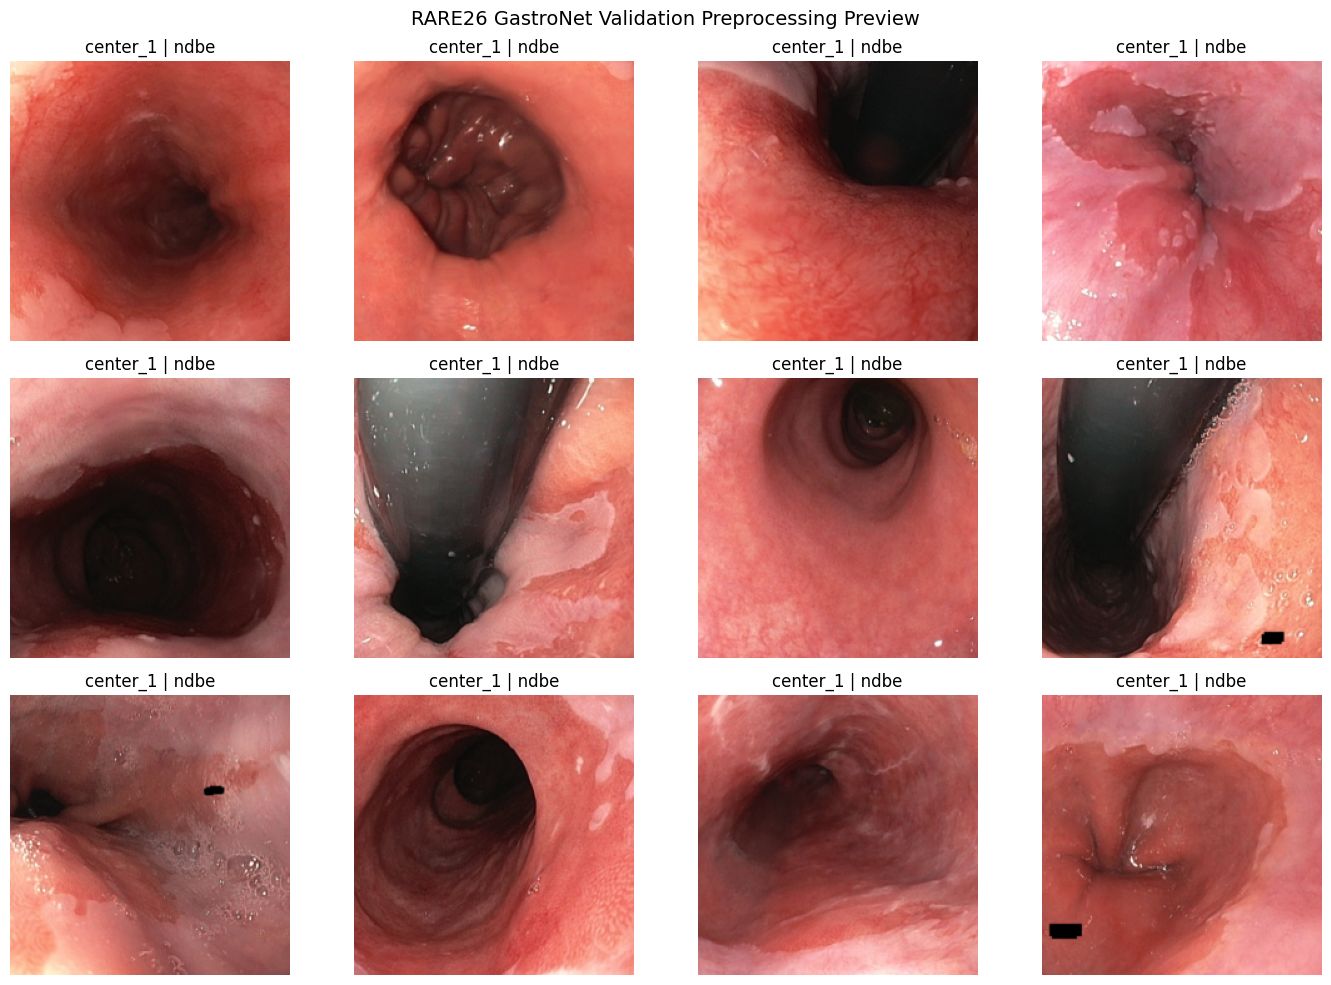


Preprocessing preview saved to:
/content/drive/MyDrive/RARE26_GastroNet_Weights/figures/cell4_validation_preprocessing_preview.png

FINAL CELL 4 READINESS REPORT
Train images ready: 2159/2159
Validation images ready: 461/461
Train batches: 68
Validation batches: 15
GastroNet backbone loaded: 318/318
Binary output shape: (2, 1)
Held-out test loader created: False
Training performed: False

STATUS: GASTRONET_RN50_DATA_AND_MODEL_READY

Records saved to:
/content/drive/MyDrive/RARE26_GastroNet_Weights/configs/cell4_rn50_dinov1_data_model_config.json
/content/drive/MyDrive/RARE26_GastroNet_Weights/results/cell4_rn50_dinov1_readiness_report.json
/content/drive/MyDrive/RARE26_GastroNet_Weights/results/cell4_rn50_dinov1_readiness_summary.txt
/content/drive/MyDrive/RARE26_GastroNet_Weights/figures/cell4_validation_preprocessing_preview.png


In [6]:
# ============================================================
# RARE26 GastroNet Extension — Cell 4
# Train/validation data loaders and GastroNet ResNet-50 setup
# No training and no held-out test evaluation
# ============================================================

from pathlib import Path
from datetime import datetime, timezone
import json
import os
import random
import platform

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
import torchvision
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from torchvision.transforms import InterpolationMode
from torchvision.models import resnet50

# ------------------------------------------------------------
# 1. Reproducibility
# ------------------------------------------------------------
SEED = 42

os.environ["PYTHONHASHSEED"] = str(SEED)

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed(SEED)
    torch.cuda.manual_seed_all(SEED)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("=" * 78)
print("CELL 4: GASTRONET RESNET-50 DATA AND MODEL READINESS")
print("=" * 78)

print(f"\nDevice: {device}")

if torch.cuda.is_available():
    print(
        f"GPU: {torch.cuda.get_device_name(0)}"
    )

# ------------------------------------------------------------
# 2. Paths
# ------------------------------------------------------------
PROJECT_ROOT = Path(
    "/content/drive/MyDrive/RARE26_GastroNet_Weights"
)

SOURCE_CHECKPOINT = (
    PROJECT_ROOT
    / "source_checkpoints"
    / "RN50_GastroNet-5M_DINOv1.pth"
)

RUNTIME_SPLIT_DIR = (
    PROJECT_ROOT
    / "configs"
    / "runtime_splits"
)

TRAIN_RUNTIME_CSV = (
    RUNTIME_SPLIT_DIR
    / "train_runtime_verified.csv"
)

VALIDATION_RUNTIME_CSV = (
    RUNTIME_SPLIT_DIR
    / "validation_runtime_verified.csv"
)

CONFIG_DIR = PROJECT_ROOT / "configs"
RESULTS_DIR = PROJECT_ROOT / "results"
FIGURES_DIR = PROJECT_ROOT / "figures"
LOGS_DIR = PROJECT_ROOT / "logs"

for directory in [
    CONFIG_DIR,
    RESULTS_DIR,
    FIGURES_DIR,
    LOGS_DIR,
]:
    directory.mkdir(
        parents=True,
        exist_ok=True,
    )

required_files = [
    SOURCE_CHECKPOINT,
    TRAIN_RUNTIME_CSV,
    VALIDATION_RUNTIME_CSV,
]

for required_file in required_files:
    if not required_file.exists():
        raise FileNotFoundError(
            f"Required file not found:\n{required_file}"
        )

# Confirm temporary dataset is still available.
RUNTIME_IMAGE_ROOT = Path(
    "/content/RARE26_data"
)

if not RUNTIME_IMAGE_ROOT.exists():
    raise FileNotFoundError(
        "Temporary dataset folder is missing:\n"
        f"{RUNTIME_IMAGE_ROOT}\n\n"
        "Run Cell 3B again before continuing."
    )

# ------------------------------------------------------------
# 3. Load verified train and validation split records
# ------------------------------------------------------------
train_df = pd.read_csv(
    TRAIN_RUNTIME_CSV
).copy()

validation_df = pd.read_csv(
    VALIDATION_RUNTIME_CSV
).copy()

required_columns = {
    "runtime_path",
    "label",
    "center",
    "class",
    "relative_path",
}

for split_name, dataframe in [
    ("train", train_df),
    ("validation", validation_df),
]:
    missing_columns = (
        required_columns
        - set(dataframe.columns)
    )

    if missing_columns:
        raise RuntimeError(
            f"{split_name} runtime CSV is missing "
            f"columns: {sorted(missing_columns)}"
        )

    dataframe["label"] = (
        dataframe["label"]
        .astype(int)
    )

    dataframe["runtime_exists_now"] = (
        dataframe["runtime_path"]
        .apply(
            lambda value: Path(value).exists()
        )
    )

    missing_runtime_count = int(
        (~dataframe["runtime_exists_now"]).sum()
    )

    if missing_runtime_count > 0:
        raise FileNotFoundError(
            f"{split_name} contains "
            f"{missing_runtime_count} missing runtime images.\n"
            "Run Cell 3B again."
        )

print("\nVerified split sizes:")
print(f"Train:      {len(train_df)}")
print(f"Validation: {len(validation_df)}")

if len(train_df) != 2159:
    raise RuntimeError(
        f"Expected 2,159 training records, "
        f"found {len(train_df)}."
    )

if len(validation_df) != 461:
    raise RuntimeError(
        f"Expected 461 validation records, "
        f"found {len(validation_df)}."
    )

train_normal_count = int(
    (train_df["label"] == 0).sum()
)

train_positive_count = int(
    (train_df["label"] == 1).sum()
)

validation_normal_count = int(
    (validation_df["label"] == 0).sum()
)

validation_positive_count = int(
    (validation_df["label"] == 1).sum()
)

print("\nClass counts:")
print(
    f"Train — normal: {train_normal_count}, "
    f"neoplasia: {train_positive_count}"
)
print(
    f"Validation — normal: "
    f"{validation_normal_count}, "
    f"neoplasia: {validation_positive_count}"
)

if (
    train_normal_count != 2050
    or train_positive_count != 109
    or validation_normal_count != 438
    or validation_positive_count != 23
):
    raise RuntimeError(
        "Train or validation class counts do not "
        "match the locked project record."
    )

# Positive-class weight for BCEWithLogitsLoss.
POS_WEIGHT_VALUE = (
    train_normal_count
    / train_positive_count
)

print(
    f"\nCalculated training pos_weight: "
    f"{POS_WEIGHT_VALUE:.6f}"
)

# ------------------------------------------------------------
# 4. Downstream preprocessing
# ------------------------------------------------------------
IMAGE_SIZE = 224

IMAGENET_MEAN = [
    0.485,
    0.456,
    0.406,
]

IMAGENET_STD = [
    0.229,
    0.224,
    0.225,
]

# The rotation fill approximates the ImageNet RGB mean,
# reducing artificial black triangular borders.
ROTATION_FILL = (
    124,
    116,
    104,
)

train_transform = transforms.Compose(
    [
        transforms.Resize(
            256,
            interpolation=InterpolationMode.BILINEAR,
            antialias=True,
        ),
        transforms.RandomResizedCrop(
            IMAGE_SIZE,
            scale=(0.85, 1.00),
            ratio=(0.90, 1.10),
            interpolation=InterpolationMode.BILINEAR,
            antialias=True,
        ),
        transforms.RandomHorizontalFlip(
            p=0.5
        ),
        transforms.RandomRotation(
            degrees=8,
            interpolation=InterpolationMode.BILINEAR,
            fill=ROTATION_FILL,
        ),
        transforms.ColorJitter(
            brightness=0.10,
            contrast=0.10,
            saturation=0.10,
            hue=0.02,
        ),
        transforms.ToTensor(),
        transforms.Normalize(
            mean=IMAGENET_MEAN,
            std=IMAGENET_STD,
        ),
    ]
)

validation_transform = transforms.Compose(
    [
        transforms.Resize(
            256,
            interpolation=InterpolationMode.BILINEAR,
            antialias=True,
        ),
        transforms.CenterCrop(
            IMAGE_SIZE
        ),
        transforms.ToTensor(),
        transforms.Normalize(
            mean=IMAGENET_MEAN,
            std=IMAGENET_STD,
        ),
    ]
)

# ------------------------------------------------------------
# 5. Dataset class
# ------------------------------------------------------------
class RARE26ImageDataset(Dataset):
    def __init__(
        self,
        dataframe,
        transform,
        split_name,
    ):
        self.dataframe = (
            dataframe
            .reset_index(drop=True)
            .copy()
        )

        self.transform = transform
        self.split_name = split_name

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):
        row = self.dataframe.iloc[index]

        image_path = Path(
            row["runtime_path"]
        )

        try:
            with Image.open(image_path) as image:
                image = image.convert("RGB")

        except Exception as error:
            raise RuntimeError(
                f"Could not read image:\n"
                f"{image_path}\n"
                f"Dataset index: {index}"
            ) from error

        if self.transform is not None:
            image = self.transform(image)

        label = torch.tensor(
            float(row["label"]),
            dtype=torch.float32,
        )

        return {
            "image": image,
            "label": label,
            "path": str(image_path),
            "relative_path": str(
                row["relative_path"]
            ),
            "center": str(row["center"]),
            "class_name": str(row["class"]),
            "split": self.split_name,
            "dataset_index": int(index),
        }

# ------------------------------------------------------------
# 6. Construct datasets
# ------------------------------------------------------------
train_dataset = RARE26ImageDataset(
    dataframe=train_df,
    transform=train_transform,
    split_name="train",
)

validation_dataset = RARE26ImageDataset(
    dataframe=validation_df,
    transform=validation_transform,
    split_name="validation",
)

print("\nDataset objects:")
print(
    f"Train dataset length: "
    f"{len(train_dataset)}"
)
print(
    f"Validation dataset length: "
    f"{len(validation_dataset)}"
)

# ------------------------------------------------------------
# 7. Deterministic DataLoader setup
# ------------------------------------------------------------
BATCH_SIZE = 32
NUM_WORKERS = 2

def seed_worker(worker_id):
    worker_seed = (
        SEED + worker_id
    )

    np.random.seed(worker_seed)
    random.seed(worker_seed)

train_generator = torch.Generator()
train_generator.manual_seed(SEED)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available(),
    drop_last=False,
    worker_init_fn=seed_worker,
    generator=train_generator,
    persistent_workers=(
        NUM_WORKERS > 0
    ),
)

validation_loader = DataLoader(
    validation_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available(),
    drop_last=False,
    worker_init_fn=seed_worker,
    persistent_workers=(
        NUM_WORKERS > 0
    ),
)

print("\nDataLoader batches:")
print(
    f"Train batches: "
    f"{len(train_loader)}"
)
print(
    f"Validation batches: "
    f"{len(validation_loader)}"
)

# ------------------------------------------------------------
# 8. Verify a validation batch
# ------------------------------------------------------------
validation_batch = next(
    iter(validation_loader)
)

batch_images = validation_batch["image"]
batch_labels = validation_batch["label"]

print("\nValidation batch verification:")
print(
    f"Image tensor shape: "
    f"{tuple(batch_images.shape)}"
)
print(
    f"Label tensor shape: "
    f"{tuple(batch_labels.shape)}"
)
print(
    f"Image dtype: "
    f"{batch_images.dtype}"
)
print(
    f"Label values in batch: "
    f"{sorted(batch_labels.unique().tolist())}"
)

if (
    batch_images.ndim != 4
    or batch_images.shape[1] != 3
    or batch_images.shape[2] != IMAGE_SIZE
    or batch_images.shape[3] != IMAGE_SIZE
):
    raise RuntimeError(
        "DataLoader returned an unexpected image shape."
    )

# ------------------------------------------------------------
# 9. Load GastroNet ResNet-50 backbone
# ------------------------------------------------------------
source_state = torch.load(
    SOURCE_CHECKPOINT,
    map_location="cpu",
    weights_only=True,
)

if not isinstance(source_state, dict):
    raise RuntimeError(
        "GastroNet checkpoint is not a state dictionary."
    )

gastronet_model = resnet50(
    weights=None
)

backbone_load_result = (
    gastronet_model.load_state_dict(
        source_state,
        strict=False,
    )
)

missing_backbone_load_keys = list(
    backbone_load_result.missing_keys
)

unexpected_backbone_load_keys = list(
    backbone_load_result.unexpected_keys
)

expected_missing_keys = {
    "fc.weight",
    "fc.bias",
}

if (
    set(missing_backbone_load_keys)
    != expected_missing_keys
):
    raise RuntimeError(
        "Unexpected missing model keys were found:\n"
        f"{missing_backbone_load_keys}"
    )

if unexpected_backbone_load_keys:
    raise RuntimeError(
        "Unexpected checkpoint keys were found:\n"
        f"{unexpected_backbone_load_keys}"
    )

# Replace the absent ImageNet head with one binary logit.
classifier_input_features = (
    gastronet_model.fc.in_features
)

gastronet_model.fc = nn.Linear(
    classifier_input_features,
    1,
)

gastronet_model = (
    gastronet_model.to(device)
)

# This global name will be used in later cells.
model = gastronet_model

print("\nModel initialization:")
print(
    "GastroNet backbone loaded: "
    "318/318 compatible keys"
)
print(
    f"New binary head: "
    f"Linear({classifier_input_features}, 1)"
)

# ------------------------------------------------------------
# 10. Model parameter counts
# ------------------------------------------------------------
total_parameter_count = sum(
    parameter.numel()
    for parameter in model.parameters()
)

trainable_parameter_count = sum(
    parameter.numel()
    for parameter in model.parameters()
    if parameter.requires_grad
)

backbone_parameter_count = (
    total_parameter_count
    - sum(
        parameter.numel()
        for parameter in model.fc.parameters()
    )
)

classifier_parameter_count = sum(
    parameter.numel()
    for parameter in model.fc.parameters()
)

print("\nParameter counts:")
print(
    f"Total parameters: "
    f"{total_parameter_count:,}"
)
print(
    f"Backbone parameters: "
    f"{backbone_parameter_count:,}"
)
print(
    f"Binary-head parameters: "
    f"{classifier_parameter_count:,}"
)
print(
    f"Currently trainable: "
    f"{trainable_parameter_count:,}"
)

# ------------------------------------------------------------
# 11. Forward-pass readiness test
# ------------------------------------------------------------
model.eval()

forward_test_images = (
    batch_images[:2]
    .to(
        device,
        non_blocking=True,
    )
)

with torch.no_grad():
    forward_logits = model(
        forward_test_images
    )

if tuple(forward_logits.shape) != (2, 1):
    raise RuntimeError(
        "Unexpected model output shape:\n"
        f"{tuple(forward_logits.shape)}"
    )

forward_probabilities = (
    torch.sigmoid(forward_logits)
    .detach()
    .cpu()
    .flatten()
    .tolist()
)

print("\nForward-pass test:")
print(
    f"Input shape: "
    f"{tuple(forward_test_images.shape)}"
)
print(
    f"Output shape: "
    f"{tuple(forward_logits.shape)}"
)
print(
    "Initial untrained-head probabilities: "
    f"{[round(value, 6) for value in forward_probabilities]}"
)

# Reset training mode for later cells.
model.train()

# ------------------------------------------------------------
# 12. Save a deterministic image preview
# ------------------------------------------------------------
def denormalize_image(tensor):
    mean_tensor = torch.tensor(
        IMAGENET_MEAN,
        dtype=tensor.dtype,
    ).view(3, 1, 1)

    std_tensor = torch.tensor(
        IMAGENET_STD,
        dtype=tensor.dtype,
    ).view(3, 1, 1)

    image = (
        tensor.cpu() * std_tensor
        + mean_tensor
    )

    return image.clamp(0, 1)

preview_indices = list(
    range(min(12, len(validation_dataset)))
)

preview_path = (
    FIGURES_DIR
    / "cell4_validation_preprocessing_preview.png"
)

figure, axes = plt.subplots(
    3,
    4,
    figsize=(14, 10),
)

axes = axes.flatten()

for axis_index, dataset_index in enumerate(
    preview_indices
):
    sample = validation_dataset[
        dataset_index
    ]

    image_tensor = denormalize_image(
        sample["image"]
    )

    displayed_image = (
        image_tensor
        .permute(1, 2, 0)
        .numpy()
    )

    axes[axis_index].imshow(
        displayed_image
    )

    axes[axis_index].set_title(
        f"{sample['center']} | "
        f"{sample['class_name']}"
    )

    axes[axis_index].axis("off")

for unused_axis in axes[
    len(preview_indices):
]:
    unused_axis.axis("off")

figure.suptitle(
    "RARE26 GastroNet Validation Preprocessing Preview",
    fontsize=14,
)

figure.tight_layout()

figure.savefig(
    preview_path,
    dpi=200,
    bbox_inches="tight",
)

plt.show()
plt.close(figure)

print(
    f"\nPreprocessing preview saved to:\n"
    f"{preview_path}"
)

# ------------------------------------------------------------
# 13. Save configuration
# ------------------------------------------------------------
config_path = (
    CONFIG_DIR
    / "cell4_rn50_dinov1_data_model_config.json"
)

readiness_report_path = (
    RESULTS_DIR
    / "cell4_rn50_dinov1_readiness_report.json"
)

text_summary_path = (
    RESULTS_DIR
    / "cell4_rn50_dinov1_readiness_summary.txt"
)

config_record = {
    "created_utc": datetime.now(
        timezone.utc
    ).isoformat(),
    "experiment_name": (
        "GastroNet-5M DINOv1 ResNet-50 Pilot"
    ),
    "checkpoint_path": str(
        SOURCE_CHECKPOINT
    ),
    "training_split_path": str(
        TRAIN_RUNTIME_CSV
    ),
    "validation_split_path": str(
        VALIDATION_RUNTIME_CSV
    ),
    "held_out_test_loaded": False,
    "selection_rule": (
        "Checkpoint and threshold selection must use "
        "validation evidence only."
    ),
    "seed": SEED,
    "image_size": IMAGE_SIZE,
    "resize_size": 256,
    "normalization_mean": IMAGENET_MEAN,
    "normalization_std": IMAGENET_STD,
    "training_augmentation": {
        "random_resized_crop_scale": [
            0.85,
            1.00,
        ],
        "random_resized_crop_ratio": [
            0.90,
            1.10,
        ],
        "horizontal_flip_probability": 0.5,
        "rotation_degrees": 8,
        "rotation_fill_rgb": list(
            ROTATION_FILL
        ),
        "brightness_jitter": 0.10,
        "contrast_jitter": 0.10,
        "saturation_jitter": 0.10,
        "hue_jitter": 0.02,
    },
    "validation_preprocessing": {
        "resize": 256,
        "center_crop": IMAGE_SIZE,
        "deterministic": True,
    },
    "batch_size": BATCH_SIZE,
    "num_workers": NUM_WORKERS,
    "train_count": len(train_dataset),
    "validation_count": len(
        validation_dataset
    ),
    "train_normal_count": (
        train_normal_count
    ),
    "train_positive_count": (
        train_positive_count
    ),
    "positive_class_weight": (
        POS_WEIGHT_VALUE
    ),
    "architecture": "torchvision_resnet50",
    "backbone_source": (
        "GastroNet-5M DINOv1 checkpoint"
    ),
    "output_head": (
        f"Linear({classifier_input_features}, 1)"
    ),
}

readiness_report = {
    "created_utc": datetime.now(
        timezone.utc
    ).isoformat(),
    "status": (
        "GASTRONET_RN50_DATA_AND_MODEL_READY"
    ),
    "device": str(device),
    "gpu_name": (
        torch.cuda.get_device_name(0)
        if torch.cuda.is_available()
        else None
    ),
    "python_version": (
        platform.python_version()
    ),
    "torch_version": torch.__version__,
    "torchvision_version": (
        torchvision.__version__
    ),
    "train_batches": len(train_loader),
    "validation_batches": len(
        validation_loader
    ),
    "forward_input_shape": list(
        forward_test_images.shape
    ),
    "forward_output_shape": list(
        forward_logits.shape
    ),
    "missing_checkpoint_keys": (
        missing_backbone_load_keys
    ),
    "unexpected_checkpoint_keys": (
        unexpected_backbone_load_keys
    ),
    "total_parameters": (
        total_parameter_count
    ),
    "backbone_parameters": (
        backbone_parameter_count
    ),
    "classifier_parameters": (
        classifier_parameter_count
    ),
    "test_loader_created": False,
    "test_evaluation_performed": False,
}

config_path.write_text(
    json.dumps(
        config_record,
        indent=2,
        ensure_ascii=False,
    ),
    encoding="utf-8",
)

readiness_report_path.write_text(
    json.dumps(
        readiness_report,
        indent=2,
        ensure_ascii=False,
    ),
    encoding="utf-8",
)

summary_lines = [
    "RARE26 GastroNet Cell 4 Readiness Summary",
    "=" * 58,
    "Experiment: GastroNet-5M DINOv1 ResNet-50 Pilot",
    f"Device: {device}",
    f"Train records: {len(train_dataset)}",
    f"Validation records: {len(validation_dataset)}",
    f"Image size: {IMAGE_SIZE}x{IMAGE_SIZE}",
    f"Batch size: {BATCH_SIZE}",
    f"Positive-class weight: {POS_WEIGHT_VALUE:.6f}",
    "Backbone keys loaded: 318/318",
    (
        "Binary head: "
        f"Linear({classifier_input_features}, 1)"
    ),
    (
        "Forward output shape: "
        f"{tuple(forward_logits.shape)}"
    ),
    "Held-out test loaded: False",
    "Training performed: False",
    (
        "Status: "
        "GASTRONET_RN50_DATA_AND_MODEL_READY"
    ),
]

text_summary_path.write_text(
    "\n".join(summary_lines),
    encoding="utf-8",
)

# ------------------------------------------------------------
# 14. Final readiness report
# ------------------------------------------------------------
print("\n" + "=" * 78)
print("FINAL CELL 4 READINESS REPORT")
print("=" * 78)

print(
    f"Train images ready: "
    f"{len(train_dataset)}/2159"
)

print(
    f"Validation images ready: "
    f"{len(validation_dataset)}/461"
)

print(
    f"Train batches: "
    f"{len(train_loader)}"
)

print(
    f"Validation batches: "
    f"{len(validation_loader)}"
)

print(
    "GastroNet backbone loaded: "
    "318/318"
)

print(
    f"Binary output shape: "
    f"{tuple(forward_logits.shape)}"
)

print(
    "Held-out test loader created: False"
)

print(
    "Training performed: False"
)

print(
    "\nSTATUS: "
    "GASTRONET_RN50_DATA_AND_MODEL_READY"
)

print("\nRecords saved to:")
print(config_path)
print(readiness_report_path)
print(text_summary_path)
print(preview_path)

In [7]:
# ============================================================
# RARE26 GastroNet Extension — Cell 5
# Lock the two-stage training protocol
# No training and no held-out test evaluation
# ============================================================

from pathlib import Path
from datetime import datetime, timezone
import json

import torch
import torch.nn as nn

# ------------------------------------------------------------
# 1. Confirm required objects from Cell 4
# ------------------------------------------------------------
required_global_objects = [
    "model",
    "train_loader",
    "validation_loader",
    "train_dataset",
    "validation_dataset",
    "device",
    "POS_WEIGHT_VALUE",
    "SEED",
]

missing_objects = [
    name
    for name in required_global_objects
    if name not in globals()
]

if missing_objects:
    raise RuntimeError(
        "Required Cell 4 objects are missing:\n"
        f"{missing_objects}\n\n"
        "Run Cell 4 again before running Cell 5."
    )

print("=" * 78)
print("CELL 5: LOCK GASTRONET RESNET-50 TRAINING PROTOCOL")
print("=" * 78)

# ------------------------------------------------------------
# 2. Project paths
# ------------------------------------------------------------
PROJECT_ROOT = Path(
    "/content/drive/MyDrive/RARE26_GastroNet_Weights"
)

CONFIG_DIR = PROJECT_ROOT / "configs"
RESULTS_DIR = PROJECT_ROOT / "results"
MODELS_DIR = PROJECT_ROOT / "models"
LOGS_DIR = PROJECT_ROOT / "logs"
PREDICTIONS_DIR = PROJECT_ROOT / "predictions"
THRESHOLDS_DIR = PROJECT_ROOT / "thresholds"
FIGURES_DIR = PROJECT_ROOT / "figures"

for directory in [
    CONFIG_DIR,
    RESULTS_DIR,
    MODELS_DIR,
    LOGS_DIR,
    PREDICTIONS_DIR,
    THRESHOLDS_DIR,
    FIGURES_DIR,
]:
    directory.mkdir(
        parents=True,
        exist_ok=True,
    )

# ------------------------------------------------------------
# 3. Locked experiment identity
# ------------------------------------------------------------
EXPERIMENT_ID = "exp01_rn50_gastronet5m_dinov1"

EXPERIMENT_NAME = (
    "GastroNet-5M DINOv1 ResNet-50 Two-Stage Pilot"
)

SOURCE_CHECKPOINT = (
    PROJECT_ROOT
    / "source_checkpoints"
    / "RN50_GastroNet-5M_DINOv1.pth"
)

if not SOURCE_CHECKPOINT.exists():
    raise FileNotFoundError(
        f"Source checkpoint missing:\n{SOURCE_CHECKPOINT}"
    )

# ------------------------------------------------------------
# 4. Locked training configuration
# ------------------------------------------------------------
TRAINING_CONFIG = {
    "experiment_id": EXPERIMENT_ID,
    "experiment_name": EXPERIMENT_NAME,

    "architecture": "torchvision_resnet50",
    "pretraining_source": (
        "GastroNet-5M DINOv1"
    ),
    "task": (
        "Binary NDBE versus neoplasia classification"
    ),

    "seed": int(SEED),

    "train_count": int(len(train_dataset)),
    "validation_count": int(
        len(validation_dataset)
    ),

    "test_loader_created": False,
    "test_evaluation_allowed_during_training": False,

    "image_size": 224,
    "batch_size": int(
        train_loader.batch_size
    ),

    "loss": "BCEWithLogitsLoss",
    "positive_class_weight": float(
        POS_WEIGHT_VALUE
    ),

    "stage_1": {
        "name": "linear_probe",
        "description": (
            "Freeze the full GastroNet ResNet-50 backbone "
            "and train only the new binary classification head."
        ),
        "epochs": 3,
        "optimizer": "AdamW",
        "head_learning_rate": 1e-3,
        "weight_decay": 1e-4,
        "scheduler": "CosineAnnealingLR",
        "scheduler_t_max": 3,
    },

    "stage_2": {
        "name": "partial_fine_tuning",
        "description": (
            "Unfreeze ResNet layer4 and the binary head. "
            "Keep conv1, bn1, layer1, layer2 and layer3 frozen."
        ),
        "maximum_epochs": 7,
        "optimizer": "AdamW",
        "layer4_learning_rate": 1e-5,
        "head_learning_rate": 1e-4,
        "weight_decay": 1e-4,
        "scheduler": "CosineAnnealingLR",
        "scheduler_t_max": 7,
    },

    "automatic_mixed_precision": True,
    "gradient_clipping_max_norm": 1.0,

    "checkpoint_selection_metric": (
        "validation_AUPRC"
    ),
    "checkpoint_selection_direction": "maximize",

    "early_stopping": {
        "enabled": True,
        "metric": "validation_AUPRC",
        "patience": 3,
        "minimum_improvement": 1e-4,
        "applies_to": "stage_2",
    },

    "threshold_selection": {
        "performed_during_training": False,
        "planned_after_checkpoint_lock": True,
        "selection_dataset": "validation_only",
        "minimum_overall_recall": 0.90,
        "minimum_per_centre_recall": 0.80,
        "primary_objective": (
            "highest validation precision among "
            "eligible thresholds"
        ),
    },

    "held_out_test_policy": (
        "The test set must not be used for checkpoint, "
        "epoch, threshold, calibration or ensemble selection."
    ),

    "full_backbone_fine_tuning": {
        "included_in_current_pilot": False,
        "future_condition": (
            "Only consider full fine-tuning if the "
            "validation evidence from partial fine-tuning "
            "is clearly promising."
        ),
    },
}

# ------------------------------------------------------------
# 5. Weighted loss
# ------------------------------------------------------------
positive_weight_tensor = torch.tensor(
    [POS_WEIGHT_VALUE],
    dtype=torch.float32,
    device=device,
)

criterion = nn.BCEWithLogitsLoss(
    pos_weight=positive_weight_tensor
)

# This global object will be reused in the training cell.
loss_function = criterion

print("\nLocked loss:")
print("BCEWithLogitsLoss")
print(
    f"Positive-class weight: "
    f"{POS_WEIGHT_VALUE:.6f}"
)

# ------------------------------------------------------------
# 6. Configure Stage 1 parameter freezing
# ------------------------------------------------------------
for parameter in model.parameters():
    parameter.requires_grad = False

for parameter in model.fc.parameters():
    parameter.requires_grad = True

# Keep the frozen backbone in evaluation mode so its
# BatchNorm running statistics are not changed in Stage 1.
model.eval()
model.fc.train()

stage1_trainable_names = [
    name
    for name, parameter in model.named_parameters()
    if parameter.requires_grad
]

stage1_trainable_parameter_count = sum(
    parameter.numel()
    for parameter in model.parameters()
    if parameter.requires_grad
)

stage1_frozen_parameter_count = sum(
    parameter.numel()
    for parameter in model.parameters()
    if not parameter.requires_grad
)

expected_stage1_names = {
    "fc.weight",
    "fc.bias",
}

if set(stage1_trainable_names) != expected_stage1_names:
    raise RuntimeError(
        "Stage 1 freezing produced unexpected "
        "trainable parameters:\n"
        f"{stage1_trainable_names}"
    )

# ------------------------------------------------------------
# 7. Calculate planned Stage 2 parameter counts
# ------------------------------------------------------------
stage2_trainable_prefixes = (
    "layer4.",
    "fc.",
)

stage2_trainable_names = [
    name
    for name, _ in model.named_parameters()
    if name.startswith(
        stage2_trainable_prefixes
    )
]

stage2_trainable_parameter_count = sum(
    parameter.numel()
    for name, parameter in model.named_parameters()
    if name.startswith(
        stage2_trainable_prefixes
    )
)

total_parameter_count = sum(
    parameter.numel()
    for parameter in model.parameters()
)

stage2_frozen_parameter_count = (
    total_parameter_count
    - stage2_trainable_parameter_count
)

# ------------------------------------------------------------
# 8. Lock expected output filenames
# ------------------------------------------------------------
OUTPUT_FILES = {
    "best_checkpoint": str(
        MODELS_DIR
        / f"{EXPERIMENT_ID}_best.pth"
    ),
    "latest_checkpoint": str(
        MODELS_DIR
        / f"{EXPERIMENT_ID}_latest.pth"
    ),
    "training_history": str(
        LOGS_DIR
        / f"{EXPERIMENT_ID}_training_history.csv"
    ),
    "validation_predictions": str(
        PREDICTIONS_DIR
        / f"{EXPERIMENT_ID}_validation_predictions.csv"
    ),
    "validation_metrics": str(
        RESULTS_DIR
        / f"{EXPERIMENT_ID}_validation_metrics.csv"
    ),
    "training_curves": str(
        FIGURES_DIR
        / f"{EXPERIMENT_ID}_training_curves.png"
    ),
    "threshold_search": str(
        THRESHOLDS_DIR
        / f"{EXPERIMENT_ID}_validation_threshold_search.csv"
    ),
}

TRAINING_CONFIG["output_files"] = OUTPUT_FILES

TRAINING_CONFIG["parameter_counts"] = {
    "total_parameters": int(
        total_parameter_count
    ),
    "stage_1_trainable_parameters": int(
        stage1_trainable_parameter_count
    ),
    "stage_1_frozen_parameters": int(
        stage1_frozen_parameter_count
    ),
    "stage_2_planned_trainable_parameters": int(
        stage2_trainable_parameter_count
    ),
    "stage_2_planned_frozen_parameters": int(
        stage2_frozen_parameter_count
    ),
}

# ------------------------------------------------------------
# 9. Save locked protocol
# ------------------------------------------------------------
config_json_path = (
    CONFIG_DIR
    / f"{EXPERIMENT_ID}_locked_training_config.json"
)

protocol_text_path = (
    RESULTS_DIR
    / f"{EXPERIMENT_ID}_locked_training_protocol.txt"
)

status_json_path = (
    RESULTS_DIR
    / f"{EXPERIMENT_ID}_protocol_lock_status.json"
)

config_json_path.write_text(
    json.dumps(
        TRAINING_CONFIG,
        indent=2,
        ensure_ascii=False,
    ),
    encoding="utf-8",
)

protocol_lines = [
    "RARE26 GastroNet Experiment 01",
    "=" * 62,
    f"Experiment: {EXPERIMENT_NAME}",
    f"Source checkpoint: {SOURCE_CHECKPOINT.name}",
    "",
    "Stage 1 — Linear probe",
    "Backbone frozen: Yes",
    "Trainable module: fc only",
    "Epochs: 3",
    "Head learning rate: 1e-3",
    "",
    "Stage 2 — Partial fine-tuning",
    "Trainable modules: layer4 and fc",
    "Maximum epochs: 7",
    "Layer4 learning rate: 1e-5",
    "Head learning rate: 1e-4",
    "",
    f"Loss: BCEWithLogitsLoss",
    f"Positive class weight: {POS_WEIGHT_VALUE:.6f}",
    "Checkpoint selection: Highest validation AUPRC",
    "Early stopping patience: 3",
    "Held-out test used: No",
    "Threshold selection: Validation only, after model lock",
    "",
    "Status: TRAINING_PROTOCOL_LOCKED",
]

protocol_text_path.write_text(
    "\n".join(protocol_lines),
    encoding="utf-8",
)

status_record = {
    "created_utc": datetime.now(
        timezone.utc
    ).isoformat(),
    "experiment_id": EXPERIMENT_ID,
    "status": "TRAINING_PROTOCOL_LOCKED",
    "stage_1_ready": True,
    "training_started": False,
    "held_out_test_loaded": False,
    "held_out_test_evaluated": False,
}

status_json_path.write_text(
    json.dumps(
        status_record,
        indent=2,
        ensure_ascii=False,
    ),
    encoding="utf-8",
)

# ------------------------------------------------------------
# 10. Final report
# ------------------------------------------------------------
print("\nStage 1 parameter lock:")
print(
    f"Trainable parameters: "
    f"{stage1_trainable_parameter_count:,}"
)
print(
    f"Frozen parameters: "
    f"{stage1_frozen_parameter_count:,}"
)
print(
    f"Trainable names: "
    f"{stage1_trainable_names}"
)

print("\nPlanned Stage 2:")
print(
    f"Trainable parameters: "
    f"{stage2_trainable_parameter_count:,}"
)
print(
    f"Frozen parameters: "
    f"{stage2_frozen_parameter_count:,}"
)

print("\nLocked training sequence:")
print("1. Linear head only: 3 epochs")
print("2. Layer4 + head: maximum 7 epochs")
print("3. Select best checkpoint by validation AUPRC")
print("4. Select threshold later from validation only")
print("5. Held-out test remains untouched")

print("\nRecords saved to:")
print(config_json_path)
print(protocol_text_path)
print(status_json_path)

print("\nTraining performed: False")
print("Held-out test loaded: False")
print("\nSTATUS: TRAINING_PROTOCOL_LOCKED")

CELL 5: LOCK GASTRONET RESNET-50 TRAINING PROTOCOL

Locked loss:
BCEWithLogitsLoss
Positive-class weight: 18.807339

Stage 1 parameter lock:
Trainable parameters: 2,049
Frozen parameters: 23,508,032
Trainable names: ['fc.weight', 'fc.bias']

Planned Stage 2:
Trainable parameters: 14,966,785
Frozen parameters: 8,543,296

Locked training sequence:
1. Linear head only: 3 epochs
2. Layer4 + head: maximum 7 epochs
3. Select best checkpoint by validation AUPRC
4. Select threshold later from validation only
5. Held-out test remains untouched

Records saved to:
/content/drive/MyDrive/RARE26_GastroNet_Weights/configs/exp01_rn50_gastronet5m_dinov1_locked_training_config.json
/content/drive/MyDrive/RARE26_GastroNet_Weights/results/exp01_rn50_gastronet5m_dinov1_locked_training_protocol.txt
/content/drive/MyDrive/RARE26_GastroNet_Weights/results/exp01_rn50_gastronet5m_dinov1_protocol_lock_status.json

Training performed: False
Held-out test loaded: False

STATUS: TRAINING_PROTOCOL_LOCKED


CELL 6: TWO-STAGE GASTRONET RESNET-50 TRAINING

Experiment ID: exp01_rn50_gastronet5m_dinov1
Device: cuda
GPU: Tesla T4

Automatic mixed precision: True

------------------------------------------------------------------------------
STARTING STAGE_1
------------------------------------------------------------------------------
Trainable parameters: 2,049


stage_1 | global epoch 1 | training:   0%|          | 0/68 [00:00<?, ?it/s]

stage_1 | global epoch 1 | validation:   0%|          | 0/15 [00:00<?, ?it/s]


stage_1 | epoch 1/3 | global 1
Train loss: 1.351704
Train AUPRC: 0.402767
Validation loss: 0.587694
Validation AUPRC: 0.797914
Validation AUROC: 0.965207
Default 0.5 metrics — Recall: 0.7826, Precision: 0.5806, Specificity: 0.9703
New global best: True
Best validation AUPRC so far: 0.797914


stage_1 | global epoch 2 | training:   0%|          | 0/68 [00:00<?, ?it/s]

...


stage_2 | epoch 5/7 | global 8
Train loss: 0.138015
Train AUPRC: 0.993692
Validation loss: 1.089471
Validation AUPRC: 0.931367
Validation AUROC: 0.993647
Default 0.5 metrics — Recall: 0.8261, Precision: 1.0000, Specificity: 1.0000
New global best: False
Best validation AUPRC so far: 0.941969
Stage 2 early-stopping counter: 2/3


stage_2 | global epoch 9 | training:   0%|          | 0/68 [00:00<?, ?it/s]

stage_2 | global epoch 9 | validation:   0%|          | 0/15 [00:00<?, ?it/s]


stage_2 | epoch 6/7 | global 9
Train loss: 0.062486
Train AUPRC: 0.998510
Validation loss: 1.104510
Validation AUPRC: 0.933333
Validation AUROC: 0.992555
Default 0.5 metrics — Recall: 0.8261, Precision: 1.0000, Specificity: 1.0000
New global best: False
Best validation AUPRC so far: 0.941969
Stage 2 early-stopping counter: 3/3

Stage 2 early stopping activated.

STAGE_2 COMPLETE

RESTORING FINAL VALIDATION-SELECTED CHECKPOINT
Best stage: stage_2
Best stage epoch: 3
Best global epoch: 6
Best validation AUPRC: 0.941969


stage_2 | global epoch 6 | validation:   0%|          | 0/15 [00:00<?, ?it/s]

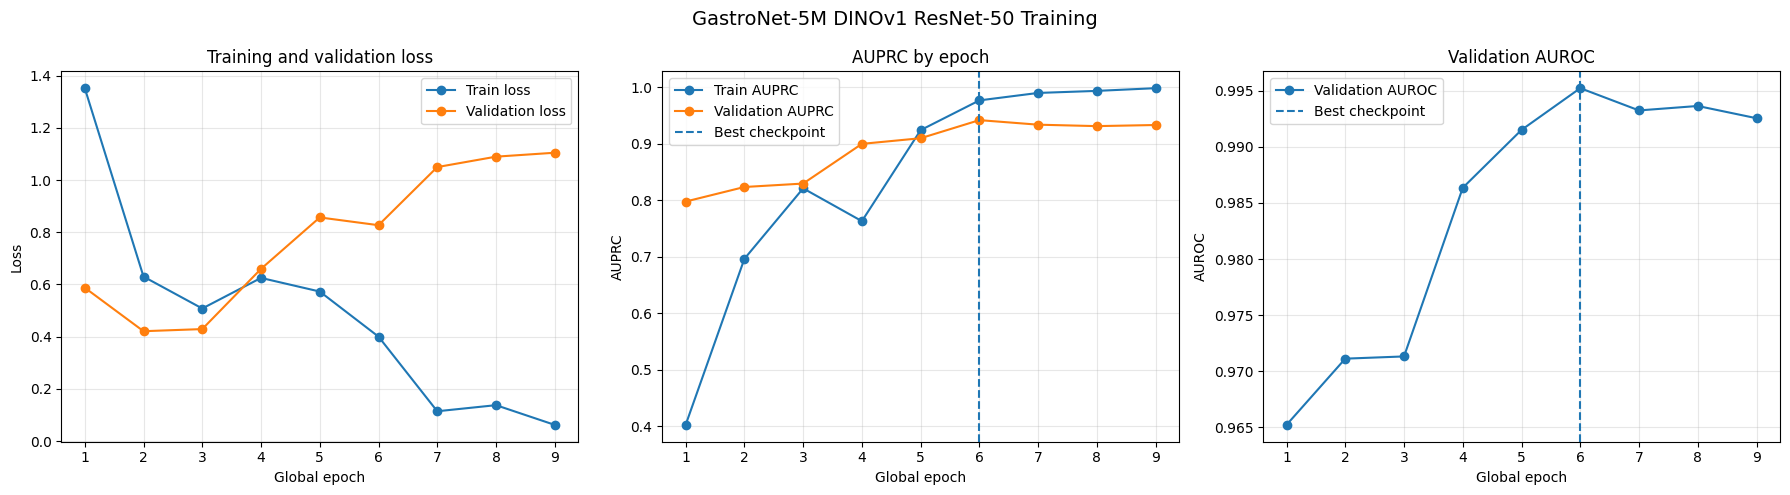


FINAL CELL 6 TRAINING REPORT
Epochs completed: 9
Stage 1 epochs: 3
Stage 2 epochs: 6
Best stage: stage_2
Best global epoch: 6
Best validation AUPRC: 0.941969
Best validation AUROC: 0.995235
Threshold selected: False
Held-out test loaded: False
Held-out test evaluated: False

STATUS: TRAINING_COMPLETE_VALIDATION_CHECKPOINT_LOCKED

Saved records:
/content/drive/MyDrive/RARE26_GastroNet_Weights/models/exp01_rn50_gastronet5m_dinov1_best.pth
/content/drive/MyDrive/RARE26_GastroNet_Weights/models/exp01_rn50_gastronet5m_dinov1_latest.pth
/content/drive/MyDrive/RARE26_GastroNet_Weights/logs/exp01_rn50_gastronet5m_dinov1_training_history.csv
/content/drive/MyDrive/RARE26_GastroNet_Weights/predictions/exp01_rn50_gastronet5m_dinov1_validation_predictions.csv
/content/drive/MyDrive/RARE26_GastroNet_Weights/results/exp01_rn50_gastronet5m_dinov1_validation_metrics.csv
/content/drive/MyDrive/RARE26_GastroNet_Weights/centre_analysis/exp01_rn50_gastronet5m_dinov1_validation_per_centre_metrics.csv
/con

In [8]:
# ============================================================
# RARE26 GastroNet Extension — Cell 6
# Two-stage GastroNet ResNet-50 training
# Validation-only checkpoint selection
# Held-out test remains untouched
# ============================================================

from pathlib import Path
from datetime import datetime, timezone
import gc
import json
import math
import os
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
from torch.optim import AdamW
from torch.optim.lr_scheduler import CosineAnnealingLR

from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
)

from tqdm.auto import tqdm

# ------------------------------------------------------------
# 1. Confirm objects from previous cells
# ------------------------------------------------------------
required_objects = [
    "model",
    "train_loader",
    "validation_loader",
    "loss_function",
    "device",
    "TRAINING_CONFIG",
    "EXPERIMENT_ID",
    "EXPERIMENT_NAME",
    "SEED",
]

missing_objects = [
    name
    for name in required_objects
    if name not in globals()
]

if missing_objects:
    raise RuntimeError(
        "Required objects are missing:\n"
        f"{missing_objects}\n\n"
        "Run Cells 4 and 5 again before Cell 6."
    )

print("=" * 78)
print("CELL 6: TWO-STAGE GASTRONET RESNET-50 TRAINING")
print("=" * 78)

print(f"\nExperiment ID: {EXPERIMENT_ID}")
print(f"Device: {device}")

if torch.cuda.is_available():
    print(
        f"GPU: {torch.cuda.get_device_name(0)}"
    )

# ------------------------------------------------------------
# 2. Output paths
# ------------------------------------------------------------
PROJECT_ROOT = Path(
    "/content/drive/MyDrive/RARE26_GastroNet_Weights"
)

MODELS_DIR = PROJECT_ROOT / "models"
LOGS_DIR = PROJECT_ROOT / "logs"
RESULTS_DIR = PROJECT_ROOT / "results"
PREDICTIONS_DIR = PROJECT_ROOT / "predictions"
FIGURES_DIR = PROJECT_ROOT / "figures"
CENTRE_DIR = PROJECT_ROOT / "centre_analysis"

for directory in [
    MODELS_DIR,
    LOGS_DIR,
    RESULTS_DIR,
    PREDICTIONS_DIR,
    FIGURES_DIR,
    CENTRE_DIR,
]:
    directory.mkdir(
        parents=True,
        exist_ok=True,
    )

BEST_CHECKPOINT_PATH = (
    MODELS_DIR
    / f"{EXPERIMENT_ID}_best.pth"
)

LATEST_CHECKPOINT_PATH = (
    MODELS_DIR
    / f"{EXPERIMENT_ID}_latest.pth"
)

HISTORY_PATH = (
    LOGS_DIR
    / f"{EXPERIMENT_ID}_training_history.csv"
)

BEST_VALIDATION_PREDICTIONS_PATH = (
    PREDICTIONS_DIR
    / f"{EXPERIMENT_ID}_validation_predictions.csv"
)

BEST_VALIDATION_METRICS_PATH = (
    RESULTS_DIR
    / f"{EXPERIMENT_ID}_validation_metrics.csv"
)

BEST_CENTRE_METRICS_PATH = (
    CENTRE_DIR
    / f"{EXPERIMENT_ID}_validation_per_centre_metrics.csv"
)

TRAINING_CURVES_PATH = (
    FIGURES_DIR
    / f"{EXPERIMENT_ID}_training_curves.png"
)

TRAINING_STATUS_PATH = (
    RESULTS_DIR
    / f"{EXPERIMENT_ID}_training_status.json"
)

TRAINING_SUMMARY_PATH = (
    RESULTS_DIR
    / f"{EXPERIMENT_ID}_training_summary.txt"
)

# ------------------------------------------------------------
# 3. Prevent accidental overwrite
# ------------------------------------------------------------
existing_training_outputs = [
    path
    for path in [
        BEST_CHECKPOINT_PATH,
        LATEST_CHECKPOINT_PATH,
        HISTORY_PATH,
    ]
    if path.exists()
]

if existing_training_outputs:
    print("\nExisting training outputs were found:")

    for path in existing_training_outputs:
        print(f"  - {path}")

    raise FileExistsError(
        "\nTraining has already started or completed for this "
        "experiment. Do not overwrite it.\n"
        "Send this output before continuing."
    )

# ------------------------------------------------------------
# 4. Reproducibility
# ------------------------------------------------------------
torch.manual_seed(SEED)
np.random.seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed(SEED)
    torch.cuda.manual_seed_all(SEED)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

# ------------------------------------------------------------
# 5. Mixed precision
# ------------------------------------------------------------
AMP_ENABLED = (
    torch.cuda.is_available()
    and device.type == "cuda"
)

try:
    gradient_scaler = torch.amp.GradScaler(
        "cuda",
        enabled=AMP_ENABLED,
    )

except TypeError:
    gradient_scaler = torch.cuda.amp.GradScaler(
        enabled=AMP_ENABLED,
    )

print(
    f"\nAutomatic mixed precision: "
    f"{AMP_ENABLED}"
)

# ------------------------------------------------------------
# 6. Metric utilities
# ------------------------------------------------------------
def safe_auroc(labels, probabilities):
    labels = np.asarray(labels)
    probabilities = np.asarray(probabilities)

    if len(np.unique(labels)) < 2:
        return float("nan")

    return float(
        roc_auc_score(
            labels,
            probabilities,
        )
    )


def safe_auprc(labels, probabilities):
    labels = np.asarray(labels)
    probabilities = np.asarray(probabilities)

    if len(np.unique(labels)) < 2:
        return float("nan")

    return float(
        average_precision_score(
            labels,
            probabilities,
        )
    )


def calculate_binary_metrics(
    labels,
    probabilities,
    threshold=0.5,
):
    labels = np.asarray(
        labels,
        dtype=int,
    )

    probabilities = np.asarray(
        probabilities,
        dtype=float,
    )

    predictions = (
        probabilities >= threshold
    ).astype(int)

    true_positive = int(
        ((labels == 1) & (predictions == 1)).sum()
    )

    true_negative = int(
        ((labels == 0) & (predictions == 0)).sum()
    )

    false_positive = int(
        ((labels == 0) & (predictions == 1)).sum()
    )

    false_negative = int(
        ((labels == 1) & (predictions == 0)).sum()
    )

    recall = (
        true_positive
        / (true_positive + false_negative)
        if (true_positive + false_negative) > 0
        else float("nan")
    )

    precision = (
        true_positive
        / (true_positive + false_positive)
        if (true_positive + false_positive) > 0
        else 0.0
    )

    specificity = (
        true_negative
        / (true_negative + false_positive)
        if (true_negative + false_positive) > 0
        else float("nan")
    )

    accuracy = (
        (true_positive + true_negative)
        / len(labels)
        if len(labels) > 0
        else float("nan")
    )

    return {
        "threshold": float(threshold),
        "recall": float(recall),
        "precision": float(precision),
        "specificity": float(specificity),
        "accuracy": float(accuracy),
        "tp": true_positive,
        "tn": true_negative,
        "fp": false_positive,
        "fn": false_negative,
    }


# ------------------------------------------------------------
# 7. Stage parameter configuration
# ------------------------------------------------------------
def configure_stage(stage_name):
    for parameter in model.parameters():
        parameter.requires_grad = False

    if stage_name == "stage_1":
        for parameter in model.fc.parameters():
            parameter.requires_grad = True

    elif stage_name == "stage_2":
        for parameter in model.layer4.parameters():
            parameter.requires_grad = True

        for parameter in model.fc.parameters():
            parameter.requires_grad = True

    else:
        raise ValueError(
            f"Unknown training stage: {stage_name}"
        )


def set_stage_training_mode(stage_name):
    # Keep all frozen BatchNorm layers in evaluation mode.
    model.eval()

    if stage_name == "stage_1":
        model.fc.train()

    elif stage_name == "stage_2":
        model.layer4.train()
        model.fc.train()

    else:
        raise ValueError(
            f"Unknown training stage: {stage_name}"
        )


def get_trainable_parameter_count():
    return int(
        sum(
            parameter.numel()
            for parameter in model.parameters()
            if parameter.requires_grad
        )
    )


# ------------------------------------------------------------
# 8. Atomic checkpoint saving
# ------------------------------------------------------------
def atomic_torch_save(
    checkpoint_object,
    destination_path,
):
    temporary_path = Path(
        str(destination_path) + ".tmp"
    )

    torch.save(
        checkpoint_object,
        temporary_path,
    )

    os.replace(
        temporary_path,
        destination_path,
    )


def create_checkpoint_payload(
    stage_name,
    stage_epoch,
    global_epoch,
    optimizer,
    scheduler,
    validation_metrics,
):
    return {
        "created_utc": datetime.now(
            timezone.utc
        ).isoformat(),

        "experiment_id": EXPERIMENT_ID,
        "experiment_name": EXPERIMENT_NAME,

        "stage": stage_name,
        "stage_epoch": int(stage_epoch),
        "global_epoch": int(global_epoch),

        "model_state_dict": (
            model.state_dict()
        ),

        "optimizer_state_dict": (
            optimizer.state_dict()
        ),

        "scheduler_state_dict": (
            scheduler.state_dict()
        ),

        "validation_metrics": (
            validation_metrics
        ),

        "training_config": (
            TRAINING_CONFIG
        ),

        "held_out_test_loaded": False,
        "held_out_test_evaluated": False,
    }


# ------------------------------------------------------------
# 9. One training epoch
# ------------------------------------------------------------
def train_one_epoch(
    stage_name,
    optimizer,
    global_epoch,
):
    set_stage_training_mode(stage_name)

    running_loss = 0.0
    processed_count = 0

    training_labels = []
    training_probabilities = []

    progress_bar = tqdm(
        train_loader,
        desc=(
            f"{stage_name} | "
            f"global epoch {global_epoch} | training"
        ),
        leave=False,
    )

    for batch in progress_bar:
        images = batch["image"].to(
            device,
            non_blocking=True,
        )

        labels = batch["label"].to(
            device,
            non_blocking=True,
        ).float()

        optimizer.zero_grad(
            set_to_none=True
        )

        with torch.autocast(
            device_type=device.type,
            dtype=torch.float16,
            enabled=AMP_ENABLED,
        ):
            logits = model(
                images
            ).squeeze(1)

            loss = loss_function(
                logits,
                labels,
            )

        gradient_scaler.scale(
            loss
        ).backward()

        gradient_scaler.unscale_(
            optimizer
        )

        torch.nn.utils.clip_grad_norm_(
            [
                parameter
                for parameter in model.parameters()
                if parameter.requires_grad
            ],
            max_norm=1.0,
        )

        gradient_scaler.step(
            optimizer
        )

        gradient_scaler.update()

        batch_size = images.size(0)

        running_loss += (
            float(loss.item())
            * batch_size
        )

        processed_count += batch_size

        probabilities = (
            torch.sigmoid(logits)
            .detach()
            .cpu()
            .numpy()
        )

        training_labels.extend(
            labels.detach()
            .cpu()
            .numpy()
            .tolist()
        )

        training_probabilities.extend(
            probabilities.tolist()
        )

        progress_bar.set_postfix(
            loss=f"{loss.item():.4f}"
        )

    average_loss = (
        running_loss / processed_count
    )

    training_auprc = safe_auprc(
        training_labels,
        training_probabilities,
    )

    training_auroc = safe_auroc(
        training_labels,
        training_probabilities,
    )

    return {
        "train_loss": float(average_loss),
        "train_auprc": float(training_auprc),
        "train_auroc": float(training_auroc),
    }


# ------------------------------------------------------------
# 10. Validation evaluation
# ------------------------------------------------------------
def evaluate_validation(
    stage_name,
    stage_epoch,
    global_epoch,
):
    model.eval()

    running_loss = 0.0
    processed_count = 0

    labels_all = []
    logits_all = []
    probabilities_all = []

    prediction_rows = []

    with torch.no_grad():
        progress_bar = tqdm(
            validation_loader,
            desc=(
                f"{stage_name} | "
                f"global epoch {global_epoch} | validation"
            ),
            leave=False,
        )

        for batch in progress_bar:
            images = batch["image"].to(
                device,
                non_blocking=True,
            )

            labels = batch["label"].to(
                device,
                non_blocking=True,
            ).float()

            with torch.autocast(
                device_type=device.type,
                dtype=torch.float16,
                enabled=AMP_ENABLED,
            ):
                logits = model(
                    images
                ).squeeze(1)

                loss = loss_function(
                    logits,
                    labels,
                )

            probabilities = torch.sigmoid(
                logits
            )

            batch_size = images.size(0)

            running_loss += (
                float(loss.item())
                * batch_size
            )

            processed_count += batch_size

            labels_numpy = (
                labels.detach()
                .cpu()
                .numpy()
            )

            logits_numpy = (
                logits.detach()
                .cpu()
                .float()
                .numpy()
            )

            probabilities_numpy = (
                probabilities.detach()
                .cpu()
                .float()
                .numpy()
            )

            labels_all.extend(
                labels_numpy.tolist()
            )

            logits_all.extend(
                logits_numpy.tolist()
            )

            probabilities_all.extend(
                probabilities_numpy.tolist()
            )

            for item_index in range(
                batch_size
            ):
                prediction_rows.append(
                    {
                        "stage": stage_name,
                        "stage_epoch": int(
                            stage_epoch
                        ),
                        "global_epoch": int(
                            global_epoch
                        ),
                        "dataset_index": int(
                            batch["dataset_index"][
                                item_index
                            ]
                        ),
                        "path": batch["path"][
                            item_index
                        ],
                        "relative_path": (
                            batch["relative_path"][
                                item_index
                            ]
                        ),
                        "center": batch["center"][
                            item_index
                        ],
                        "class_name": (
                            batch["class_name"][
                                item_index
                            ]
                        ),
                        "label": int(
                            labels_numpy[
                                item_index
                            ]
                        ),
                        "logit": float(
                            logits_numpy[
                                item_index
                            ]
                        ),
                        "probability": float(
                            probabilities_numpy[
                                item_index
                            ]
                        ),
                    }
                )

    average_loss = (
        running_loss / processed_count
    )

    validation_auprc = safe_auprc(
        labels_all,
        probabilities_all,
    )

    validation_auroc = safe_auroc(
        labels_all,
        probabilities_all,
    )

    default_metrics = (
        calculate_binary_metrics(
            labels_all,
            probabilities_all,
            threshold=0.5,
        )
    )

    validation_metrics = {
        "validation_loss": float(
            average_loss
        ),
        "validation_auprc": float(
            validation_auprc
        ),
        "validation_auroc": float(
            validation_auroc
        ),
        "validation_default_recall": (
            default_metrics["recall"]
        ),
        "validation_default_precision": (
            default_metrics["precision"]
        ),
        "validation_default_specificity": (
            default_metrics["specificity"]
        ),
        "validation_default_accuracy": (
            default_metrics["accuracy"]
        ),
        "validation_default_tp": (
            default_metrics["tp"]
        ),
        "validation_default_tn": (
            default_metrics["tn"]
        ),
        "validation_default_fp": (
            default_metrics["fp"]
        ),
        "validation_default_fn": (
            default_metrics["fn"]
        ),
    }

    prediction_dataframe = pd.DataFrame(
        prediction_rows
    ).sort_values(
        by="dataset_index"
    ).reset_index(
        drop=True
    )

    return (
        validation_metrics,
        prediction_dataframe,
    )


# ------------------------------------------------------------
# 11. History and best-model tracking
# ------------------------------------------------------------
history_rows = []

best_validation_auprc = -math.inf
best_global_epoch = None
best_stage = None
best_stage_epoch = None

global_epoch_counter = 0

training_start_time = time.time()

# ------------------------------------------------------------
# 12. General stage runner
# ------------------------------------------------------------
def run_training_stage(
    stage_name,
    number_of_epochs,
    optimizer,
    scheduler,
    early_stopping_enabled=False,
    early_stopping_patience=None,
    minimum_improvement=1e-4,
):
    global history_rows
    global best_validation_auprc
    global best_global_epoch
    global best_stage
    global best_stage_epoch
    global global_epoch_counter

    epochs_without_meaningful_improvement = 0

    early_stopping_reference = (
        best_validation_auprc
    )

    print("\n" + "-" * 78)
    print(
        f"STARTING {stage_name.upper()}"
    )
    print("-" * 78)

    print(
        f"Trainable parameters: "
        f"{get_trainable_parameter_count():,}"
    )

    for stage_epoch in range(
        1,
        number_of_epochs + 1,
    ):
        global_epoch_counter += 1

        current_learning_rates = [
            float(
                parameter_group["lr"]
            )
            for parameter_group
            in optimizer.param_groups
        ]

        epoch_start_time = time.time()

        training_metrics = train_one_epoch(
            stage_name=stage_name,
            optimizer=optimizer,
            global_epoch=global_epoch_counter,
        )

        (
            validation_metrics,
            validation_predictions,
        ) = evaluate_validation(
            stage_name=stage_name,
            stage_epoch=stage_epoch,
            global_epoch=global_epoch_counter,
        )

        epoch_duration_seconds = (
            time.time() - epoch_start_time
        )

        current_validation_auprc = float(
            validation_metrics[
                "validation_auprc"
            ]
        )

        is_new_global_best = (
            current_validation_auprc
            > best_validation_auprc
        )

        if is_new_global_best:
            best_validation_auprc = (
                current_validation_auprc
            )

            best_global_epoch = (
                global_epoch_counter
            )

            best_stage = stage_name
            best_stage_epoch = stage_epoch

        history_row = {
            "stage": stage_name,
            "stage_epoch": int(
                stage_epoch
            ),
            "global_epoch": int(
                global_epoch_counter
            ),
            "epoch_duration_seconds": float(
                epoch_duration_seconds
            ),
            "learning_rates": (
                "|".join(
                    f"{value:.10g}"
                    for value
                    in current_learning_rates
                )
            ),
            "trainable_parameters": (
                get_trainable_parameter_count()
            ),
            **training_metrics,
            **validation_metrics,
            "is_new_global_best": bool(
                is_new_global_best
            ),
        }

        history_rows.append(
            history_row
        )

        pd.DataFrame(
            history_rows
        ).to_csv(
            HISTORY_PATH,
            index=False,
        )

        checkpoint_payload = (
            create_checkpoint_payload(
                stage_name=stage_name,
                stage_epoch=stage_epoch,
                global_epoch=global_epoch_counter,
                optimizer=optimizer,
                scheduler=scheduler,
                validation_metrics=validation_metrics,
            )
        )

        atomic_torch_save(
            checkpoint_payload,
            LATEST_CHECKPOINT_PATH,
        )

        if is_new_global_best:
            atomic_torch_save(
                checkpoint_payload,
                BEST_CHECKPOINT_PATH,
            )

            validation_predictions.to_csv(
                BEST_VALIDATION_PREDICTIONS_PATH,
                index=False,
            )

        scheduler.step()

        print(
            f"\n{stage_name} | "
            f"epoch {stage_epoch}/{number_of_epochs} "
            f"| global {global_epoch_counter}"
        )

        print(
            f"Train loss: "
            f"{training_metrics['train_loss']:.6f}"
        )

        print(
            f"Train AUPRC: "
            f"{training_metrics['train_auprc']:.6f}"
        )

        print(
            f"Validation loss: "
            f"{validation_metrics['validation_loss']:.6f}"
        )

        print(
            f"Validation AUPRC: "
            f"{current_validation_auprc:.6f}"
        )

        print(
            f"Validation AUROC: "
            f"{validation_metrics['validation_auroc']:.6f}"
        )

        print(
            "Default 0.5 metrics — "
            f"Recall: "
            f"{validation_metrics['validation_default_recall']:.4f}, "
            f"Precision: "
            f"{validation_metrics['validation_default_precision']:.4f}, "
            f"Specificity: "
            f"{validation_metrics['validation_default_specificity']:.4f}"
        )

        print(
            f"New global best: "
            f"{is_new_global_best}"
        )

        print(
            f"Best validation AUPRC so far: "
            f"{best_validation_auprc:.6f}"
        )

        if early_stopping_enabled:
            meaningful_improvement = (
                current_validation_auprc
                > (
                    early_stopping_reference
                    + minimum_improvement
                )
            )

            if meaningful_improvement:
                early_stopping_reference = (
                    current_validation_auprc
                )

                epochs_without_meaningful_improvement = 0

            else:
                epochs_without_meaningful_improvement += 1

            print(
                "Stage 2 early-stopping counter: "
                f"{epochs_without_meaningful_improvement}"
                f"/{early_stopping_patience}"
            )

            if (
                epochs_without_meaningful_improvement
                >= early_stopping_patience
            ):
                print(
                    "\nStage 2 early stopping activated."
                )

                break

    print(
        f"\n{stage_name.upper()} COMPLETE"
    )


# ------------------------------------------------------------
# 13. Stage 1 — train binary head only
# ------------------------------------------------------------
configure_stage(
    "stage_1"
)

stage1_optimizer = AdamW(
    model.fc.parameters(),
    lr=1e-3,
    weight_decay=1e-4,
)

stage1_scheduler = CosineAnnealingLR(
    stage1_optimizer,
    T_max=3,
)

run_training_stage(
    stage_name="stage_1",
    number_of_epochs=3,
    optimizer=stage1_optimizer,
    scheduler=stage1_scheduler,
    early_stopping_enabled=False,
)

# ------------------------------------------------------------
# 14. Restore best Stage 1 checkpoint before Stage 2
# ------------------------------------------------------------
if not BEST_CHECKPOINT_PATH.exists():
    raise RuntimeError(
        "No best checkpoint was created during Stage 1."
    )

best_stage1_checkpoint = torch.load(
    BEST_CHECKPOINT_PATH,
    map_location=device,
    weights_only=False,
)

model.load_state_dict(
    best_stage1_checkpoint[
        "model_state_dict"
    ]
)

print(
    "\nBest Stage 1 checkpoint restored before Stage 2:"
)
print(
    f"Global epoch: "
    f"{best_stage1_checkpoint['global_epoch']}"
)
print(
    f"Validation AUPRC: "
    f"{best_stage1_checkpoint['validation_metrics']['validation_auprc']:.6f}"
)

# ------------------------------------------------------------
# 15. Stage 2 — layer4 and binary head
# ------------------------------------------------------------
configure_stage(
    "stage_2"
)

stage2_optimizer = AdamW(
    [
        {
            "params": model.layer4.parameters(),
            "lr": 1e-5,
        },
        {
            "params": model.fc.parameters(),
            "lr": 1e-4,
        },
    ],
    weight_decay=1e-4,
)

stage2_scheduler = CosineAnnealingLR(
    stage2_optimizer,
    T_max=7,
)

run_training_stage(
    stage_name="stage_2",
    number_of_epochs=7,
    optimizer=stage2_optimizer,
    scheduler=stage2_scheduler,
    early_stopping_enabled=True,
    early_stopping_patience=3,
    minimum_improvement=1e-4,
)

# ------------------------------------------------------------
# 16. Load final validation-selected best checkpoint
# ------------------------------------------------------------
best_checkpoint = torch.load(
    BEST_CHECKPOINT_PATH,
    map_location=device,
    weights_only=False,
)

model.load_state_dict(
    best_checkpoint[
        "model_state_dict"
    ]
)

best_stage = best_checkpoint["stage"]
best_stage_epoch = int(
    best_checkpoint["stage_epoch"]
)
best_global_epoch = int(
    best_checkpoint["global_epoch"]
)

print("\n" + "=" * 78)
print("RESTORING FINAL VALIDATION-SELECTED CHECKPOINT")
print("=" * 78)

print(f"Best stage: {best_stage}")
print(
    f"Best stage epoch: "
    f"{best_stage_epoch}"
)
print(
    f"Best global epoch: "
    f"{best_global_epoch}"
)
print(
    f"Best validation AUPRC: "
    f"{best_checkpoint['validation_metrics']['validation_auprc']:.6f}"
)

# ------------------------------------------------------------
# 17. Re-evaluate best checkpoint on validation only
# ------------------------------------------------------------
(
    final_validation_metrics,
    final_validation_predictions,
) = evaluate_validation(
    stage_name=best_stage,
    stage_epoch=best_stage_epoch,
    global_epoch=best_global_epoch,
)

final_validation_predictions.to_csv(
    BEST_VALIDATION_PREDICTIONS_PATH,
    index=False,
)

overall_metrics_row = {
    "experiment_id": EXPERIMENT_ID,
    "best_stage": best_stage,
    "best_stage_epoch": best_stage_epoch,
    "best_global_epoch": best_global_epoch,
    **final_validation_metrics,
    "checkpoint_path": str(
        BEST_CHECKPOINT_PATH
    ),
    "held_out_test_loaded": False,
    "held_out_test_evaluated": False,
}

pd.DataFrame(
    [overall_metrics_row]
).to_csv(
    BEST_VALIDATION_METRICS_PATH,
    index=False,
)

# ------------------------------------------------------------
# 18. Best-checkpoint per-centre validation metrics
# ------------------------------------------------------------
centre_metric_rows = []

for centre_name, centre_group in (
    final_validation_predictions.groupby(
        "center"
    )
):
    centre_labels = (
        centre_group["label"]
        .astype(int)
        .to_numpy()
    )

    centre_probabilities = (
        centre_group["probability"]
        .astype(float)
        .to_numpy()
    )

    centre_default_metrics = (
        calculate_binary_metrics(
            centre_labels,
            centre_probabilities,
            threshold=0.5,
        )
    )

    centre_metric_rows.append(
        {
            "center": centre_name,
            "sample_count": len(
                centre_group
            ),
            "positive_count": int(
                centre_labels.sum()
            ),
            "negative_count": int(
                (centre_labels == 0).sum()
            ),
            "auprc": safe_auprc(
                centre_labels,
                centre_probabilities,
            ),
            "auroc": safe_auroc(
                centre_labels,
                centre_probabilities,
            ),
            "default_threshold": 0.5,
            "default_recall": (
                centre_default_metrics[
                    "recall"
                ]
            ),
            "default_precision": (
                centre_default_metrics[
                    "precision"
                ]
            ),
            "default_specificity": (
                centre_default_metrics[
                    "specificity"
                ]
            ),
            "default_fp": (
                centre_default_metrics["fp"]
            ),
            "default_fn": (
                centre_default_metrics["fn"]
            ),
        }
    )

centre_metrics_df = pd.DataFrame(
    centre_metric_rows
)

centre_metrics_df.to_csv(
    BEST_CENTRE_METRICS_PATH,
    index=False,
)

# ------------------------------------------------------------
# 19. Save training curves
# ------------------------------------------------------------
history_df = pd.DataFrame(
    history_rows
)

history_df.to_csv(
    HISTORY_PATH,
    index=False,
)

figure, axes = plt.subplots(
    1,
    3,
    figsize=(18, 5),
)

axes[0].plot(
    history_df["global_epoch"],
    history_df["train_loss"],
    marker="o",
    label="Train loss",
)

axes[0].plot(
    history_df["global_epoch"],
    history_df["validation_loss"],
    marker="o",
    label="Validation loss",
)

axes[0].set_xlabel(
    "Global epoch"
)
axes[0].set_ylabel(
    "Loss"
)
axes[0].set_title(
    "Training and validation loss"
)
axes[0].legend()
axes[0].grid(
    alpha=0.3
)

axes[1].plot(
    history_df["global_epoch"],
    history_df["train_auprc"],
    marker="o",
    label="Train AUPRC",
)

axes[1].plot(
    history_df["global_epoch"],
    history_df["validation_auprc"],
    marker="o",
    label="Validation AUPRC",
)

axes[1].axvline(
    best_global_epoch,
    linestyle="--",
    label="Best checkpoint",
)

axes[1].set_xlabel(
    "Global epoch"
)
axes[1].set_ylabel(
    "AUPRC"
)
axes[1].set_title(
    "AUPRC by epoch"
)
axes[1].legend()
axes[1].grid(
    alpha=0.3
)

axes[2].plot(
    history_df["global_epoch"],
    history_df["validation_auroc"],
    marker="o",
    label="Validation AUROC",
)

axes[2].axvline(
    best_global_epoch,
    linestyle="--",
    label="Best checkpoint",
)

axes[2].set_xlabel(
    "Global epoch"
)
axes[2].set_ylabel(
    "AUROC"
)
axes[2].set_title(
    "Validation AUROC"
)
axes[2].legend()
axes[2].grid(
    alpha=0.3
)

figure.suptitle(
    "GastroNet-5M DINOv1 ResNet-50 Training",
    fontsize=14,
)

figure.tight_layout()

figure.savefig(
    TRAINING_CURVES_PATH,
    dpi=200,
    bbox_inches="tight",
)

plt.show()
plt.close(figure)

# ------------------------------------------------------------
# 20. Save final training status and summary
# ------------------------------------------------------------
training_duration_seconds = (
    time.time() - training_start_time
)

training_status = {
    "created_utc": datetime.now(
        timezone.utc
    ).isoformat(),
    "experiment_id": EXPERIMENT_ID,
    "experiment_name": EXPERIMENT_NAME,
    "status": (
        "TRAINING_COMPLETE_VALIDATION_CHECKPOINT_LOCKED"
    ),
    "epochs_completed": int(
        len(history_df)
    ),
    "stage_1_epochs_completed": int(
        (history_df["stage"] == "stage_1").sum()
    ),
    "stage_2_epochs_completed": int(
        (history_df["stage"] == "stage_2").sum()
    ),
    "training_duration_seconds": float(
        training_duration_seconds
    ),
    "best_stage": best_stage,
    "best_stage_epoch": best_stage_epoch,
    "best_global_epoch": best_global_epoch,
    "best_validation_auprc": float(
        final_validation_metrics[
            "validation_auprc"
        ]
    ),
    "best_validation_auroc": float(
        final_validation_metrics[
            "validation_auroc"
        ]
    ),
    "best_checkpoint_path": str(
        BEST_CHECKPOINT_PATH
    ),
    "latest_checkpoint_path": str(
        LATEST_CHECKPOINT_PATH
    ),
    "held_out_test_loaded": False,
    "held_out_test_evaluated": False,
    "threshold_selected": False,
}

TRAINING_STATUS_PATH.write_text(
    json.dumps(
        training_status,
        indent=2,
        ensure_ascii=False,
    ),
    encoding="utf-8",
)

summary_lines = [
    "RARE26 GastroNet Experiment 01 Training Summary",
    "=" * 62,
    f"Experiment: {EXPERIMENT_NAME}",
    f"Epochs completed: {len(history_df)}",
    (
        "Stage 1 epochs: "
        f"{int((history_df['stage'] == 'stage_1').sum())}"
    ),
    (
        "Stage 2 epochs: "
        f"{int((history_df['stage'] == 'stage_2').sum())}"
    ),
    f"Best stage: {best_stage}",
    f"Best stage epoch: {best_stage_epoch}",
    f"Best global epoch: {best_global_epoch}",
    (
        "Best validation AUPRC: "
        f"{final_validation_metrics['validation_auprc']:.6f}"
    ),
    (
        "Best validation AUROC: "
        f"{final_validation_metrics['validation_auroc']:.6f}"
    ),
    (
        "Default validation recall: "
        f"{final_validation_metrics['validation_default_recall']:.6f}"
    ),
    (
        "Default validation precision: "
        f"{final_validation_metrics['validation_default_precision']:.6f}"
    ),
    (
        "Default validation specificity: "
        f"{final_validation_metrics['validation_default_specificity']:.6f}"
    ),
    f"Best checkpoint: {BEST_CHECKPOINT_PATH}",
    "Threshold selected: No",
    "Held-out test loaded: No",
    "Held-out test evaluated: No",
    (
        "Status: "
        "TRAINING_COMPLETE_VALIDATION_CHECKPOINT_LOCKED"
    ),
]

TRAINING_SUMMARY_PATH.write_text(
    "\n".join(summary_lines),
    encoding="utf-8",
)

# ------------------------------------------------------------
# 21. Memory cleanup and final report
# ------------------------------------------------------------
gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()

print("\n" + "=" * 78)
print("FINAL CELL 6 TRAINING REPORT")
print("=" * 78)

print(
    f"Epochs completed: "
    f"{len(history_df)}"
)

print(
    f"Stage 1 epochs: "
    f"{int((history_df['stage'] == 'stage_1').sum())}"
)

print(
    f"Stage 2 epochs: "
    f"{int((history_df['stage'] == 'stage_2').sum())}"
)

print(
    f"Best stage: "
    f"{best_stage}"
)

print(
    f"Best global epoch: "
    f"{best_global_epoch}"
)

print(
    f"Best validation AUPRC: "
    f"{final_validation_metrics['validation_auprc']:.6f}"
)

print(
    f"Best validation AUROC: "
    f"{final_validation_metrics['validation_auroc']:.6f}"
)

print(
    "Threshold selected: False"
)

print(
    "Held-out test loaded: False"
)

print(
    "Held-out test evaluated: False"
)

print(
    "\nSTATUS: "
    "TRAINING_COMPLETE_VALIDATION_CHECKPOINT_LOCKED"
)

print("\nSaved records:")
print(BEST_CHECKPOINT_PATH)
print(LATEST_CHECKPOINT_PATH)
print(HISTORY_PATH)
print(BEST_VALIDATION_PREDICTIONS_PATH)
print(BEST_VALIDATION_METRICS_PATH)
print(BEST_CENTRE_METRICS_PATH)
print(TRAINING_CURVES_PATH)
print(TRAINING_STATUS_PATH)
print(TRAINING_SUMMARY_PATH)

CELL 7: VALIDATION-ONLY THRESHOLD SEARCH AND LOCK

Predictions source:
/content/drive/MyDrive/RARE26_GastroNet_Weights/predictions/exp01_rn50_gastronet5m_dinov1_validation_predictions.csv

Locked validation records verified:
Total:      461
Normal:     438
Neoplasia: 23
Validation AUPRC: 0.941969
Validation AUROC: 0.995235

Candidate validation thresholds: 365

Selection mode:
overall_recall_0.90_and_minimum_centre_recall_0.80
Strict centre-aware eligible thresholds: 338
Total thresholds considered eligible: 338


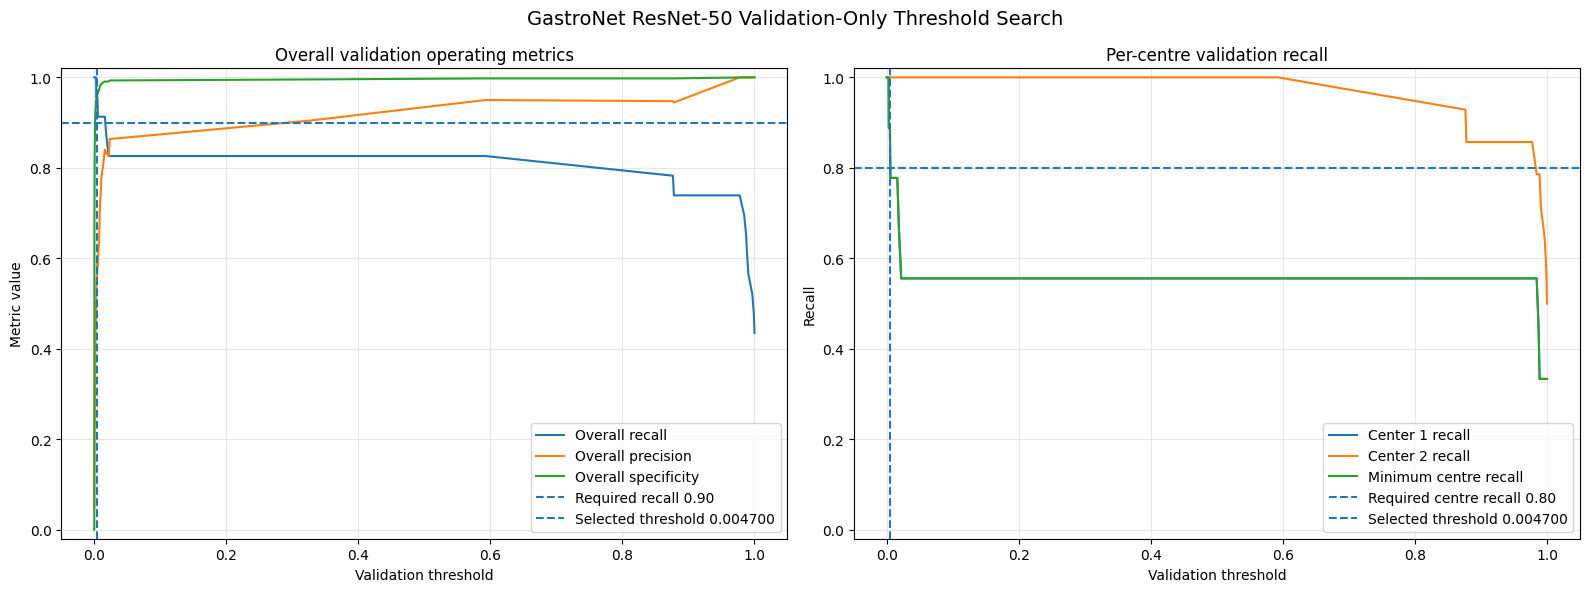


FINAL CELL 7 THRESHOLD LOCK REPORT
Selected validation threshold: 0.004699707031
Validation recall: 0.956522
Validation precision: 0.594595
Validation specificity: 0.965753
Validation TP: 22
Validation FP: 15
Validation FN: 1
Center 1 recall: 0.888889
Center 2 recall: 1.000000
Minimum centre recall: 0.888889

Threshold selected from test: False
Held-out test loaded: False
Held-out test evaluated: False

STATUS: VALIDATION_THRESHOLD_LOCKED

Saved records:
/content/drive/MyDrive/RARE26_GastroNet_Weights/thresholds/exp01_rn50_gastronet5m_dinov1_validation_threshold_search.csv
/content/drive/MyDrive/RARE26_GastroNet_Weights/thresholds/exp01_rn50_gastronet5m_dinov1_validation_operating_point.csv
/content/drive/MyDrive/RARE26_GastroNet_Weights/thresholds/exp01_rn50_gastronet5m_dinov1_threshold_lock.json
/content/drive/MyDrive/RARE26_GastroNet_Weights/predictions/exp01_rn50_gastronet5m_dinov1_validation_predictions_locked_threshold.csv
/content/drive/MyDrive/RARE26_GastroNet_Weights/centre_a

In [9]:
# ============================================================
# RARE26 GastroNet Extension — Cell 7
# Validation-only threshold search and operating-point lock
# Held-out test remains completely untouched
# ============================================================

from pathlib import Path
from datetime import datetime, timezone
import json
import math

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
)

# ------------------------------------------------------------
# 1. Experiment paths
# ------------------------------------------------------------
PROJECT_ROOT = Path(
    "/content/drive/MyDrive/RARE26_GastroNet_Weights"
)

EXPERIMENT_ID = "exp01_rn50_gastronet5m_dinov1"

PREDICTIONS_DIR = PROJECT_ROOT / "predictions"
THRESHOLDS_DIR = PROJECT_ROOT / "thresholds"
RESULTS_DIR = PROJECT_ROOT / "results"
CENTRE_DIR = PROJECT_ROOT / "centre_analysis"
FIGURES_DIR = PROJECT_ROOT / "figures"

for directory in [
    PREDICTIONS_DIR,
    THRESHOLDS_DIR,
    RESULTS_DIR,
    CENTRE_DIR,
    FIGURES_DIR,
]:
    directory.mkdir(parents=True, exist_ok=True)

VALIDATION_PREDICTIONS_PATH = (
    PREDICTIONS_DIR
    / f"{EXPERIMENT_ID}_validation_predictions.csv"
)

THRESHOLD_SEARCH_PATH = (
    THRESHOLDS_DIR
    / f"{EXPERIMENT_ID}_validation_threshold_search.csv"
)

OPERATING_POINT_PATH = (
    THRESHOLDS_DIR
    / f"{EXPERIMENT_ID}_validation_operating_point.csv"
)

THRESHOLD_LOCK_PATH = (
    THRESHOLDS_DIR
    / f"{EXPERIMENT_ID}_threshold_lock.json"
)

SELECTED_PREDICTIONS_PATH = (
    PREDICTIONS_DIR
    / f"{EXPERIMENT_ID}_validation_predictions_locked_threshold.csv"
)

CENTRE_OPERATING_POINT_PATH = (
    CENTRE_DIR
    / f"{EXPERIMENT_ID}_validation_locked_threshold_per_centre.csv"
)

SUMMARY_PATH = (
    RESULTS_DIR
    / f"{EXPERIMENT_ID}_threshold_lock_summary.txt"
)

FIGURE_PATH = (
    FIGURES_DIR
    / f"{EXPERIMENT_ID}_validation_threshold_analysis.png"
)

if not VALIDATION_PREDICTIONS_PATH.exists():
    raise FileNotFoundError(
        "Best-checkpoint validation predictions were not found:\n"
        f"{VALIDATION_PREDICTIONS_PATH}\n\n"
        "Run Cell 6 successfully before Cell 7."
    )

print("=" * 80)
print("CELL 7: VALIDATION-ONLY THRESHOLD SEARCH AND LOCK")
print("=" * 80)

print(f"\nPredictions source:\n{VALIDATION_PREDICTIONS_PATH}")

# ------------------------------------------------------------
# 2. Load and verify validation predictions
# ------------------------------------------------------------
validation_df = pd.read_csv(
    VALIDATION_PREDICTIONS_PATH
).copy()

required_columns = {
    "label",
    "probability",
    "center",
    "relative_path",
}

missing_columns = (
    required_columns
    - set(validation_df.columns)
)

if missing_columns:
    raise RuntimeError(
        "Validation predictions are missing columns:\n"
        f"{sorted(missing_columns)}"
    )

validation_df["label"] = (
    validation_df["label"].astype(int)
)

validation_df["probability"] = (
    validation_df["probability"].astype(float)
)

if validation_df["probability"].isna().any():
    raise RuntimeError(
        "Validation probabilities contain missing values."
    )

if not validation_df["probability"].between(
    0.0,
    1.0,
    inclusive="both",
).all():
    raise RuntimeError(
        "At least one probability is outside [0, 1]."
    )

if len(validation_df) != 461:
    raise RuntimeError(
        f"Expected 461 validation predictions, "
        f"found {len(validation_df)}."
    )

normal_count = int(
    (validation_df["label"] == 0).sum()
)

positive_count = int(
    (validation_df["label"] == 1).sum()
)

if normal_count != 438 or positive_count != 23:
    raise RuntimeError(
        "Validation class counts do not match the locked split.\n"
        f"Normal: {normal_count}, positive: {positive_count}"
    )

expected_centre_counts = {
    "center_1": {
        "normal": 332,
        "positive": 9,
    },
    "center_2": {
        "normal": 106,
        "positive": 14,
    },
}

for centre_name, expected in expected_centre_counts.items():
    centre_subset = validation_df[
        validation_df["center"] == centre_name
    ]

    actual_normal = int(
        (centre_subset["label"] == 0).sum()
    )

    actual_positive = int(
        (centre_subset["label"] == 1).sum()
    )

    if (
        actual_normal != expected["normal"]
        or actual_positive != expected["positive"]
    ):
        raise RuntimeError(
            f"{centre_name} counts do not match the "
            "locked validation split."
        )

labels = validation_df["label"].to_numpy(
    dtype=int
)

probabilities = validation_df[
    "probability"
].to_numpy(
    dtype=float
)

overall_auprc = float(
    average_precision_score(
        labels,
        probabilities,
    )
)

overall_auroc = float(
    roc_auc_score(
        labels,
        probabilities,
    )
)

print("\nLocked validation records verified:")
print(f"Total:      {len(validation_df)}")
print(f"Normal:     {normal_count}")
print(f"Neoplasia: {positive_count}")
print(f"Validation AUPRC: {overall_auprc:.6f}")
print(f"Validation AUROC: {overall_auroc:.6f}")

# ------------------------------------------------------------
# 3. Metric helper
# ------------------------------------------------------------
def calculate_operating_metrics(
    true_labels,
    predicted_probabilities,
    threshold,
):
    true_labels = np.asarray(
        true_labels,
        dtype=int,
    )

    predicted_probabilities = np.asarray(
        predicted_probabilities,
        dtype=float,
    )

    predicted_labels = (
        predicted_probabilities >= threshold
    ).astype(int)

    tp = int(
        (
            (true_labels == 1)
            & (predicted_labels == 1)
        ).sum()
    )

    tn = int(
        (
            (true_labels == 0)
            & (predicted_labels == 0)
        ).sum()
    )

    fp = int(
        (
            (true_labels == 0)
            & (predicted_labels == 1)
        ).sum()
    )

    fn = int(
        (
            (true_labels == 1)
            & (predicted_labels == 0)
        ).sum()
    )

    recall = (
        tp / (tp + fn)
        if (tp + fn) > 0
        else float("nan")
    )

    precision = (
        tp / (tp + fp)
        if (tp + fp) > 0
        else 0.0
    )

    specificity = (
        tn / (tn + fp)
        if (tn + fp) > 0
        else float("nan")
    )

    negative_predictive_value = (
        tn / (tn + fn)
        if (tn + fn) > 0
        else float("nan")
    )

    accuracy = (
        (tp + tn) / len(true_labels)
        if len(true_labels) > 0
        else float("nan")
    )

    predicted_positive_count = int(
        predicted_labels.sum()
    )

    return {
        "threshold": float(threshold),
        "recall": float(recall),
        "precision": float(precision),
        "specificity": float(specificity),
        "npv": float(negative_predictive_value),
        "accuracy": float(accuracy),
        "tp": tp,
        "tn": tn,
        "fp": fp,
        "fn": fn,
        "predicted_positive_count": (
            predicted_positive_count
        ),
    }

# ------------------------------------------------------------
# 4. Candidate thresholds
# ------------------------------------------------------------
# Every unique validation probability represents a possible
# change in predictions when using probability >= threshold.
candidate_thresholds = np.unique(
    np.concatenate(
        [
            np.array([0.0], dtype=float),
            probabilities,
            np.array([1.0], dtype=float),
        ]
    )
)

candidate_thresholds = np.sort(
    candidate_thresholds
)

print(
    f"\nCandidate validation thresholds: "
    f"{len(candidate_thresholds)}"
)

# ------------------------------------------------------------
# 5. Full overall and per-centre threshold search
# ------------------------------------------------------------
threshold_rows = []

for threshold in candidate_thresholds:
    overall_metrics = calculate_operating_metrics(
        labels,
        probabilities,
        threshold,
    )

    centre_results = {}

    for centre_name in [
        "center_1",
        "center_2",
    ]:
        centre_mask = (
            validation_df["center"].to_numpy()
            == centre_name
        )

        centre_labels = labels[
            centre_mask
        ]

        centre_probabilities = probabilities[
            centre_mask
        ]

        centre_results[centre_name] = (
            calculate_operating_metrics(
                centre_labels,
                centre_probabilities,
                threshold,
            )
        )

    centre_1_recall = (
        centre_results["center_1"]["recall"]
    )

    centre_2_recall = (
        centre_results["center_2"]["recall"]
    )

    minimum_centre_recall = min(
        centre_1_recall,
        centre_2_recall,
    )

    strict_eligible = bool(
        overall_metrics["recall"] >= 0.90
        and minimum_centre_recall >= 0.80
    )

    overall_recall_eligible = bool(
        overall_metrics["recall"] >= 0.90
    )

    threshold_rows.append(
        {
            "threshold": float(threshold),

            "overall_recall": (
                overall_metrics["recall"]
            ),
            "overall_precision": (
                overall_metrics["precision"]
            ),
            "overall_specificity": (
                overall_metrics["specificity"]
            ),
            "overall_npv": (
                overall_metrics["npv"]
            ),
            "overall_accuracy": (
                overall_metrics["accuracy"]
            ),
            "overall_tp": overall_metrics["tp"],
            "overall_tn": overall_metrics["tn"],
            "overall_fp": overall_metrics["fp"],
            "overall_fn": overall_metrics["fn"],
            "overall_predicted_positive_count": (
                overall_metrics[
                    "predicted_positive_count"
                ]
            ),

            "center_1_recall": (
                centre_results[
                    "center_1"
                ]["recall"]
            ),
            "center_1_precision": (
                centre_results[
                    "center_1"
                ]["precision"]
            ),
            "center_1_specificity": (
                centre_results[
                    "center_1"
                ]["specificity"]
            ),
            "center_1_tp": (
                centre_results[
                    "center_1"
                ]["tp"]
            ),
            "center_1_tn": (
                centre_results[
                    "center_1"
                ]["tn"]
            ),
            "center_1_fp": (
                centre_results[
                    "center_1"
                ]["fp"]
            ),
            "center_1_fn": (
                centre_results[
                    "center_1"
                ]["fn"]
            ),

            "center_2_recall": (
                centre_results[
                    "center_2"
                ]["recall"]
            ),
            "center_2_precision": (
                centre_results[
                    "center_2"
                ]["precision"]
            ),
            "center_2_specificity": (
                centre_results[
                    "center_2"
                ]["specificity"]
            ),
            "center_2_tp": (
                centre_results[
                    "center_2"
                ]["tp"]
            ),
            "center_2_tn": (
                centre_results[
                    "center_2"
                ]["tn"]
            ),
            "center_2_fp": (
                centre_results[
                    "center_2"
                ]["fp"]
            ),
            "center_2_fn": (
                centre_results[
                    "center_2"
                ]["fn"]
            ),

            "minimum_centre_recall": (
                minimum_centre_recall
            ),

            "overall_recall_eligible": (
                overall_recall_eligible
            ),
            "strict_centre_aware_eligible": (
                strict_eligible
            ),

            "validation_auprc": overall_auprc,
            "validation_auroc": overall_auroc,
        }
    )

threshold_df = pd.DataFrame(
    threshold_rows
)

threshold_df.to_csv(
    THRESHOLD_SEARCH_PATH,
    index=False,
)

# ------------------------------------------------------------
# 6. Select operating point using locked rules
# ------------------------------------------------------------
strict_candidates = threshold_df[
    threshold_df[
        "strict_centre_aware_eligible"
    ]
].copy()

if len(strict_candidates) > 0:
    eligible_candidates = strict_candidates
    selection_mode = (
        "overall_recall_0.90_and_minimum_"
        "centre_recall_0.80"
    )

else:
    eligible_candidates = threshold_df[
        threshold_df[
            "overall_recall_eligible"
        ]
    ].copy()

    selection_mode = (
        "overall_recall_0.90_fallback_"
        "because_centre_constraint_not_feasible"
    )

if len(eligible_candidates) == 0:
    raise RuntimeError(
        "No threshold achieved at least 90% "
        "validation recall."
    )

# Locked ordering:
# 1. highest validation precision
# 2. highest minimum centre recall
# 3. highest specificity
# 4. highest threshold as deterministic final tie-break
eligible_candidates = eligible_candidates.sort_values(
    by=[
        "overall_precision",
        "minimum_centre_recall",
        "overall_specificity",
        "threshold",
    ],
    ascending=[
        False,
        False,
        False,
        False,
    ],
).reset_index(drop=True)

selected_row = eligible_candidates.iloc[0].copy()

SELECTED_THRESHOLD = float(
    selected_row["threshold"]
)

print("\nSelection mode:")
print(selection_mode)

print(
    f"Strict centre-aware eligible thresholds: "
    f"{len(strict_candidates)}"
)

print(
    f"Total thresholds considered eligible: "
    f"{len(eligible_candidates)}"
)

# ------------------------------------------------------------
# 7. Apply selected threshold to validation predictions
# ------------------------------------------------------------
validation_df[
    "locked_threshold"
] = SELECTED_THRESHOLD

validation_df[
    "locked_prediction"
] = (
    validation_df["probability"]
    >= SELECTED_THRESHOLD
).astype(int)

validation_df[
    "locked_prediction_correct"
] = (
    validation_df["locked_prediction"]
    == validation_df["label"]
)

validation_df.to_csv(
    SELECTED_PREDICTIONS_PATH,
    index=False,
)

# ------------------------------------------------------------
# 8. Save one-row locked operating point
# ------------------------------------------------------------
operating_point_record = {
    "experiment_id": EXPERIMENT_ID,
    "threshold": SELECTED_THRESHOLD,
    "threshold_source": (
        "validation_predictions_only"
    ),
    "selection_mode": selection_mode,

    "minimum_required_overall_recall": 0.90,
    "minimum_required_per_centre_recall": 0.80,

    "validation_auprc": overall_auprc,
    "validation_auroc": overall_auroc,

    "validation_recall": float(
        selected_row["overall_recall"]
    ),
    "validation_precision": float(
        selected_row["overall_precision"]
    ),
    "validation_specificity": float(
        selected_row["overall_specificity"]
    ),

    "validation_tp": int(
        selected_row["overall_tp"]
    ),
    "validation_tn": int(
        selected_row["overall_tn"]
    ),
    "validation_fp": int(
        selected_row["overall_fp"]
    ),
    "validation_fn": int(
        selected_row["overall_fn"]
    ),

    "minimum_centre_recall": float(
        selected_row[
            "minimum_centre_recall"
        ]
    ),

    "center_1_recall": float(
        selected_row["center_1_recall"]
    ),
    "center_1_precision": float(
        selected_row["center_1_precision"]
    ),
    "center_1_specificity": float(
        selected_row[
            "center_1_specificity"
        ]
    ),
    "center_1_fp": int(
        selected_row["center_1_fp"]
    ),
    "center_1_fn": int(
        selected_row["center_1_fn"]
    ),

    "center_2_recall": float(
        selected_row["center_2_recall"]
    ),
    "center_2_precision": float(
        selected_row["center_2_precision"]
    ),
    "center_2_specificity": float(
        selected_row[
            "center_2_specificity"
        ]
    ),
    "center_2_fp": int(
        selected_row["center_2_fp"]
    ),
    "center_2_fn": int(
        selected_row["center_2_fn"]
    ),

    "held_out_test_loaded": False,
    "held_out_test_evaluated": False,
}

operating_point_df = pd.DataFrame(
    [operating_point_record]
)

operating_point_df.to_csv(
    OPERATING_POINT_PATH,
    index=False,
)

# ------------------------------------------------------------
# 9. Save per-centre locked operating point
# ------------------------------------------------------------
centre_rows = []

for centre_name in [
    "center_1",
    "center_2",
]:
    centre_subset = validation_df[
        validation_df["center"] == centre_name
    ]

    centre_metrics = calculate_operating_metrics(
        centre_subset["label"].to_numpy(
            dtype=int
        ),
        centre_subset["probability"].to_numpy(
            dtype=float
        ),
        SELECTED_THRESHOLD,
    )

    centre_rows.append(
        {
            "experiment_id": EXPERIMENT_ID,
            "center": centre_name,
            "threshold": SELECTED_THRESHOLD,
            "sample_count": len(
                centre_subset
            ),
            "positive_count": int(
                centre_subset["label"].sum()
            ),
            "negative_count": int(
                (
                    centre_subset["label"]
                    == 0
                ).sum()
            ),
            **centre_metrics,
        }
    )

centre_operating_df = pd.DataFrame(
    centre_rows
)

centre_operating_df.to_csv(
    CENTRE_OPERATING_POINT_PATH,
    index=False,
)

# ------------------------------------------------------------
# 10. Save immutable-style threshold lock record
# ------------------------------------------------------------
threshold_lock_record = {
    "created_utc": datetime.now(
        timezone.utc
    ).isoformat(),

    "experiment_id": EXPERIMENT_ID,

    "status": (
        "VALIDATION_THRESHOLD_LOCKED"
    ),

    "selected_threshold": (
        SELECTED_THRESHOLD
    ),

    "threshold_source": (
        "best_checkpoint_validation_predictions_only"
    ),

    "selection_mode": selection_mode,

    "candidate_threshold_count": int(
        len(threshold_df)
    ),

    "strict_eligible_threshold_count": int(
        len(strict_candidates)
    ),

    "selected_validation_metrics": {
        "recall": float(
            selected_row["overall_recall"]
        ),
        "precision": float(
            selected_row["overall_precision"]
        ),
        "specificity": float(
            selected_row["overall_specificity"]
        ),
        "tp": int(
            selected_row["overall_tp"]
        ),
        "tn": int(
            selected_row["overall_tn"]
        ),
        "fp": int(
            selected_row["overall_fp"]
        ),
        "fn": int(
            selected_row["overall_fn"]
        ),
        "minimum_centre_recall": float(
            selected_row[
                "minimum_centre_recall"
            ]
        ),
    },

    "selection_order": [
        "highest_validation_precision",
        "highest_minimum_centre_recall",
        "highest_validation_specificity",
        "highest_threshold_deterministic_tie_break",
    ],

    "test_used_for_threshold_selection": False,
    "held_out_test_loaded": False,
    "held_out_test_evaluated": False,

    "scientific_rule": (
        "This threshold must not be changed after "
        "viewing held-out test predictions."
    ),
}

THRESHOLD_LOCK_PATH.write_text(
    json.dumps(
        threshold_lock_record,
        indent=2,
        ensure_ascii=False,
    ),
    encoding="utf-8",
)

# ------------------------------------------------------------
# 11. Create threshold analysis figure
# ------------------------------------------------------------
plot_df = threshold_df.sort_values(
    "threshold"
)

figure, axes = plt.subplots(
    1,
    2,
    figsize=(16, 6),
)

axes[0].plot(
    plot_df["threshold"],
    plot_df["overall_recall"],
    label="Overall recall",
)

axes[0].plot(
    plot_df["threshold"],
    plot_df["overall_precision"],
    label="Overall precision",
)

axes[0].plot(
    plot_df["threshold"],
    plot_df["overall_specificity"],
    label="Overall specificity",
)

axes[0].axhline(
    0.90,
    linestyle="--",
    label="Required recall 0.90",
)

axes[0].axvline(
    SELECTED_THRESHOLD,
    linestyle="--",
    label=(
        f"Selected threshold "
        f"{SELECTED_THRESHOLD:.6f}"
    ),
)

axes[0].set_xlabel(
    "Validation threshold"
)
axes[0].set_ylabel(
    "Metric value"
)
axes[0].set_title(
    "Overall validation operating metrics"
)
axes[0].set_ylim(
    -0.02,
    1.02,
)
axes[0].legend()
axes[0].grid(
    alpha=0.3
)

axes[1].plot(
    plot_df["threshold"],
    plot_df["center_1_recall"],
    label="Center 1 recall",
)

axes[1].plot(
    plot_df["threshold"],
    plot_df["center_2_recall"],
    label="Center 2 recall",
)

axes[1].plot(
    plot_df["threshold"],
    plot_df["minimum_centre_recall"],
    label="Minimum centre recall",
)

axes[1].axhline(
    0.80,
    linestyle="--",
    label="Required centre recall 0.80",
)

axes[1].axvline(
    SELECTED_THRESHOLD,
    linestyle="--",
    label=(
        f"Selected threshold "
        f"{SELECTED_THRESHOLD:.6f}"
    ),
)

axes[1].set_xlabel(
    "Validation threshold"
)
axes[1].set_ylabel(
    "Recall"
)
axes[1].set_title(
    "Per-centre validation recall"
)
axes[1].set_ylim(
    -0.02,
    1.02,
)
axes[1].legend()
axes[1].grid(
    alpha=0.3
)

figure.suptitle(
    "GastroNet ResNet-50 Validation-Only Threshold Search",
    fontsize=14,
)

figure.tight_layout()

figure.savefig(
    FIGURE_PATH,
    dpi=200,
    bbox_inches="tight",
)

plt.show()
plt.close(figure)

# ------------------------------------------------------------
# 12. Save human-readable summary
# ------------------------------------------------------------
summary_lines = [
    "RARE26 GastroNet Experiment 01 Threshold Lock",
    "=" * 64,
    f"Selected threshold: {SELECTED_THRESHOLD:.12f}",
    f"Selection mode: {selection_mode}",
    "",
    f"Validation AUPRC: {overall_auprc:.6f}",
    f"Validation AUROC: {overall_auroc:.6f}",
    "",
    (
        "Validation recall: "
        f"{selected_row['overall_recall']:.6f}"
    ),
    (
        "Validation precision: "
        f"{selected_row['overall_precision']:.6f}"
    ),
    (
        "Validation specificity: "
        f"{selected_row['overall_specificity']:.6f}"
    ),
    (
        "Validation TP / FP / FN / TN: "
        f"{int(selected_row['overall_tp'])} / "
        f"{int(selected_row['overall_fp'])} / "
        f"{int(selected_row['overall_fn'])} / "
        f"{int(selected_row['overall_tn'])}"
    ),
    "",
    (
        "Center 1 recall: "
        f"{selected_row['center_1_recall']:.6f}"
    ),
    (
        "Center 2 recall: "
        f"{selected_row['center_2_recall']:.6f}"
    ),
    (
        "Minimum centre recall: "
        f"{selected_row['minimum_centre_recall']:.6f}"
    ),
    "",
    "Threshold source: Validation predictions only",
    "Held-out test loaded: No",
    "Held-out test evaluated: No",
    "",
    "Status: VALIDATION_THRESHOLD_LOCKED",
]

SUMMARY_PATH.write_text(
    "\n".join(summary_lines),
    encoding="utf-8",
)

# ------------------------------------------------------------
# 13. Final report
# ------------------------------------------------------------
print("\n" + "=" * 80)
print("FINAL CELL 7 THRESHOLD LOCK REPORT")
print("=" * 80)

print(
    f"Selected validation threshold: "
    f"{SELECTED_THRESHOLD:.12f}"
)

print(
    f"Validation recall: "
    f"{selected_row['overall_recall']:.6f}"
)

print(
    f"Validation precision: "
    f"{selected_row['overall_precision']:.6f}"
)

print(
    f"Validation specificity: "
    f"{selected_row['overall_specificity']:.6f}"
)

print(
    f"Validation TP: "
    f"{int(selected_row['overall_tp'])}"
)

print(
    f"Validation FP: "
    f"{int(selected_row['overall_fp'])}"
)

print(
    f"Validation FN: "
    f"{int(selected_row['overall_fn'])}"
)

print(
    f"Center 1 recall: "
    f"{selected_row['center_1_recall']:.6f}"
)

print(
    f"Center 2 recall: "
    f"{selected_row['center_2_recall']:.6f}"
)

print(
    f"Minimum centre recall: "
    f"{selected_row['minimum_centre_recall']:.6f}"
)

print("\nThreshold selected from test: False")
print("Held-out test loaded: False")
print("Held-out test evaluated: False")

print(
    "\nSTATUS: VALIDATION_THRESHOLD_LOCKED"
)

print("\nSaved records:")
print(THRESHOLD_SEARCH_PATH)
print(OPERATING_POINT_PATH)
print(THRESHOLD_LOCK_PATH)
print(SELECTED_PREDICTIONS_PATH)
print(CENTRE_OPERATING_POINT_PATH)
print(FIGURE_PATH)
print(SUMMARY_PATH)

CELL 8: ONE-TIME HELD-OUT TEST EVALUATION

Locked operating point:
Threshold: 0.004699707031
Threshold source: validation predictions only

Locked held-out test split verified:
Total:      468
Normal:     442
Neoplasia: 26

Test loader:
Test images: 468
Test batches: 15

Validation-selected checkpoint restored:
Stage: stage_2
Stage epoch: 3
Global epoch: 6
Validation AUPRC: 0.941969

Running locked held-out test inference...


Locked held-out test:   0%|          | 0/15 [00:00<?, ?it/s]

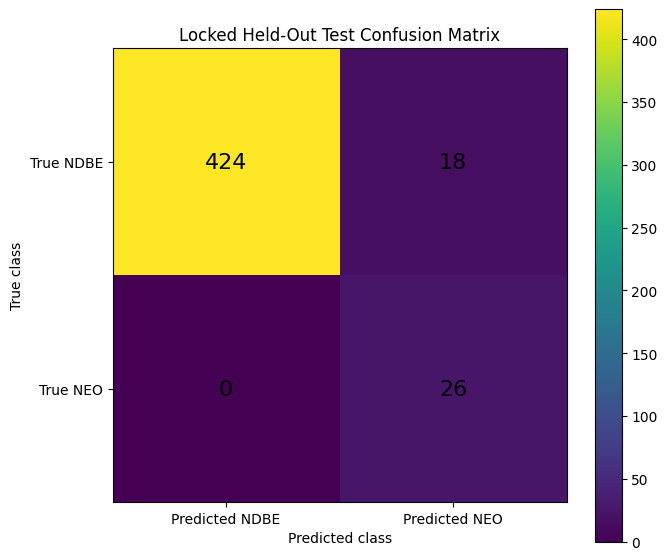

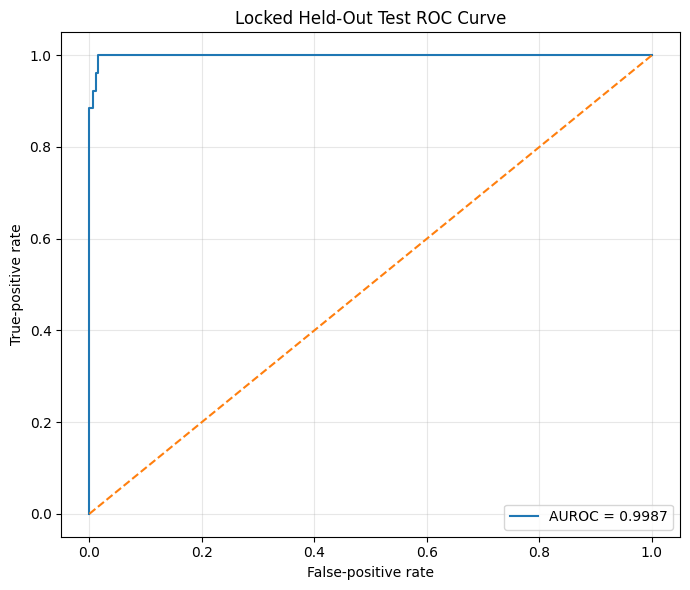

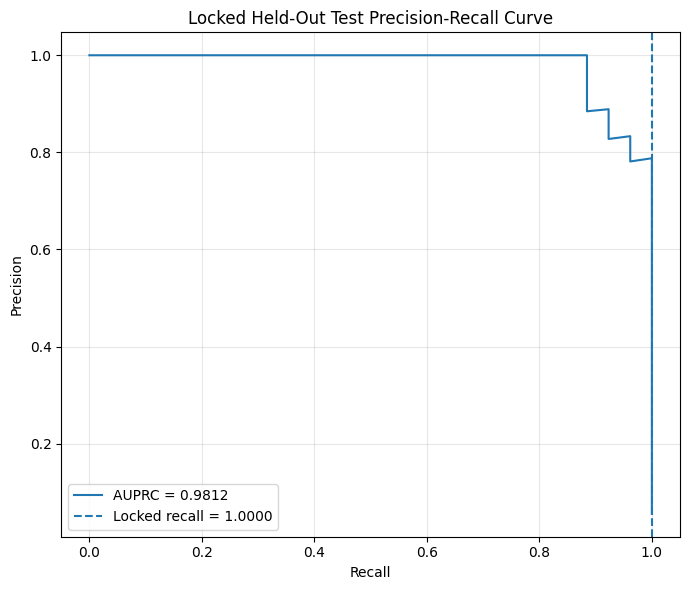


FINAL CELL 8 HELD-OUT TEST REPORT
Locked threshold: 0.004699707031
Test recall: 1.000000
Test PPV/precision: 0.590909
Test specificity: 0.959276
Test AUROC: 0.998695
Test AUPRC: 0.981158
TP: 26
FP: 18
FN: 0
TN: 424

Per-centre test metrics:


,experiment_id,center,sample_count,normal_count,positive_count,threshold,recall,precision,specificity,npv,accuracy,balanced_accuracy,f1_score,auroc,auprc,tp,tn,fp,fn
0,exp01_rn50_gastronet5m_dinov1,center_1,344,334,10,0.0047,1.0,0.625000,0.982036,1.0,0.982558,0.991018,0.769231,0.998503,0.95404,10,328,6,0
1,exp01_rn50_gastronet5m_dinov1,center_2,124,108,16,0.0047,1.0,0.571429,0.888889,1.0,0.903226,0.944444,0.727273,1.000000,1.00000,16,96,12,0



Test threshold sweep performed: False
Test used for checkpoint selection: False
Test used for threshold selection: False

STATUS: LOCKED_HELD_OUT_TEST_EVALUATION_COMPLETE

Saved records:
/content/drive/MyDrive/RARE26_GastroNet_Weights/predictions/exp01_rn50_gastronet5m_dinov1_locked_test_predictions.csv
/content/drive/MyDrive/RARE26_GastroNet_Weights/results/exp01_rn50_gastronet5m_dinov1_locked_test_metrics.csv
/content/drive/MyDrive/RARE26_GastroNet_Weights/centre_analysis/exp01_rn50_gastronet5m_dinov1_locked_test_per_centre_metrics.csv
/content/drive/MyDrive/RARE26_GastroNet_Weights/results/exp01_rn50_gastronet5m_dinov1_held_out_test_evaluation_status.json
/content/drive/MyDrive/RARE26_GastroNet_Weights/results/exp01_rn50_gastronet5m_dinov1_locked_test_summary.txt
/content/drive/MyDrive/RARE26_GastroNet_Weights/figures/exp01_rn50_gastronet5m_dinov1_locked_test_confusion_matrix.png
/content/drive/MyDrive/RARE26_GastroNet_Weights/figures/exp01_rn50_gastronet5m_dinov1_locked_test_roc_c

In [10]:
# ============================================================
# RARE26 GastroNet Extension — Cell 8
# One-time held-out test evaluation
# Locked checkpoint + locked validation threshold only
# No test-based tuning, threshold sweep, or model reselection
# ============================================================

from pathlib import Path
from datetime import datetime, timezone
import json
import os
import math

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
from torch.utils.data import DataLoader

from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    precision_recall_curve,
    roc_curve,
)

from tqdm.auto import tqdm

# ------------------------------------------------------------
# 1. Confirm required notebook objects
# ------------------------------------------------------------
required_objects = [
    "model",
    "device",
    "RARE26ImageDataset",
    "validation_transform",
    "seed_worker",
    "SEED",
]

missing_objects = [
    object_name
    for object_name in required_objects
    if object_name not in globals()
]

if missing_objects:
    raise RuntimeError(
        "Required objects are missing:\n"
        f"{missing_objects}\n\n"
        "Run Cell 4 again before running Cell 8."
    )

print("=" * 80)
print("CELL 8: ONE-TIME HELD-OUT TEST EVALUATION")
print("=" * 80)

# ------------------------------------------------------------
# 2. Canonical project paths
# ------------------------------------------------------------
PROJECT_ROOT = Path(
    "/content/drive/MyDrive/RARE26_GastroNet_Weights"
)

EXPERIMENT_ID = "exp01_rn50_gastronet5m_dinov1"

BEST_CHECKPOINT_PATH = (
    PROJECT_ROOT
    / "models"
    / f"{EXPERIMENT_ID}_best.pth"
)

THRESHOLD_LOCK_PATH = (
    PROJECT_ROOT
    / "thresholds"
    / f"{EXPERIMENT_ID}_threshold_lock.json"
)

TEST_RUNTIME_CSV = (
    PROJECT_ROOT
    / "configs"
    / "runtime_splits"
    / "test_runtime_verified.csv"
)

PREDICTIONS_DIR = PROJECT_ROOT / "predictions"
RESULTS_DIR = PROJECT_ROOT / "results"
CENTRE_DIR = PROJECT_ROOT / "centre_analysis"
FIGURES_DIR = PROJECT_ROOT / "figures"
FINAL_PACKAGE_DIR = PROJECT_ROOT / "final_package"

for directory in [
    PREDICTIONS_DIR,
    RESULTS_DIR,
    CENTRE_DIR,
    FIGURES_DIR,
    FINAL_PACKAGE_DIR,
]:
    directory.mkdir(
        parents=True,
        exist_ok=True,
    )

required_files = [
    BEST_CHECKPOINT_PATH,
    THRESHOLD_LOCK_PATH,
    TEST_RUNTIME_CSV,
]

for required_file in required_files:
    if not required_file.exists():
        raise FileNotFoundError(
            f"Required file not found:\n{required_file}"
        )

# ------------------------------------------------------------
# 3. Final output paths
# ------------------------------------------------------------
TEST_PREDICTIONS_PATH = (
    PREDICTIONS_DIR
    / f"{EXPERIMENT_ID}_locked_test_predictions.csv"
)

TEST_METRICS_PATH = (
    RESULTS_DIR
    / f"{EXPERIMENT_ID}_locked_test_metrics.csv"
)

TEST_CENTRE_METRICS_PATH = (
    CENTRE_DIR
    / f"{EXPERIMENT_ID}_locked_test_per_centre_metrics.csv"
)

TEST_STATUS_PATH = (
    RESULTS_DIR
    / f"{EXPERIMENT_ID}_held_out_test_evaluation_status.json"
)

TEST_SUMMARY_PATH = (
    RESULTS_DIR
    / f"{EXPERIMENT_ID}_locked_test_summary.txt"
)

CONFUSION_FIGURE_PATH = (
    FIGURES_DIR
    / f"{EXPERIMENT_ID}_locked_test_confusion_matrix.png"
)

ROC_FIGURE_PATH = (
    FIGURES_DIR
    / f"{EXPERIMENT_ID}_locked_test_roc_curve.png"
)

PR_FIGURE_PATH = (
    FIGURES_DIR
    / f"{EXPERIMENT_ID}_locked_test_precision_recall_curve.png"
)

final_output_paths = [
    TEST_PREDICTIONS_PATH,
    TEST_METRICS_PATH,
    TEST_CENTRE_METRICS_PATH,
    TEST_STATUS_PATH,
]

existing_outputs = [
    path
    for path in final_output_paths
    if path.exists()
]

if existing_outputs:
    print("\nExisting held-out test outputs were found:")

    for path in existing_outputs:
        print(f"  - {path}")

    raise FileExistsError(
        "\nThe locked held-out test evaluation appears to have "
        "already been completed.\n"
        "Do not overwrite or repeat it without reviewing the "
        "existing records."
    )

# ------------------------------------------------------------
# 4. Load immutable threshold lock
# ------------------------------------------------------------
with THRESHOLD_LOCK_PATH.open(
    "r",
    encoding="utf-8",
) as file_handle:
    threshold_lock = json.load(
        file_handle
    )

if threshold_lock.get("status") != "VALIDATION_THRESHOLD_LOCKED":
    raise RuntimeError(
        "Threshold lock status is not valid:\n"
        f"{threshold_lock.get('status')}"
    )

if threshold_lock.get(
    "test_used_for_threshold_selection"
) is not False:
    raise RuntimeError(
        "Threshold record does not confirm validation-only selection."
    )

LOCKED_THRESHOLD = float(
    threshold_lock["selected_threshold"]
)

print("\nLocked operating point:")
print(
    f"Threshold: {LOCKED_THRESHOLD:.12f}"
)
print(
    "Threshold source: validation predictions only"
)

# ------------------------------------------------------------
# 5. Load and verify test split
# ------------------------------------------------------------
test_df = pd.read_csv(
    TEST_RUNTIME_CSV
).copy()

required_test_columns = {
    "runtime_path",
    "relative_path",
    "label",
    "center",
    "class",
}

missing_test_columns = (
    required_test_columns
    - set(test_df.columns)
)

if missing_test_columns:
    raise RuntimeError(
        "Test runtime CSV is missing columns:\n"
        f"{sorted(missing_test_columns)}"
    )

test_df["label"] = (
    test_df["label"].astype(int)
)

test_df["runtime_exists_now"] = (
    test_df["runtime_path"]
    .apply(
        lambda path_value: Path(path_value).exists()
    )
)

missing_test_images = int(
    (~test_df["runtime_exists_now"]).sum()
)

if missing_test_images > 0:
    raise FileNotFoundError(
        f"{missing_test_images} test images are missing from "
        "temporary Colab storage.\n"
        "Run Cell 3B again."
    )

test_total = len(test_df)
test_normal = int(
    (test_df["label"] == 0).sum()
)
test_positive = int(
    (test_df["label"] == 1).sum()
)

if (
    test_total != 468
    or test_normal != 442
    or test_positive != 26
):
    raise RuntimeError(
        "Test split counts do not match the locked project record.\n"
        f"Total={test_total}, normal={test_normal}, "
        f"positive={test_positive}"
    )

expected_centre_counts = {
    "center_1": {
        "normal": 334,
        "positive": 10,
    },
    "center_2": {
        "normal": 108,
        "positive": 16,
    },
}

for centre_name, expected_counts in expected_centre_counts.items():
    centre_subset = test_df[
        test_df["center"] == centre_name
    ]

    centre_normal = int(
        (centre_subset["label"] == 0).sum()
    )

    centre_positive = int(
        (centre_subset["label"] == 1).sum()
    )

    if (
        centre_normal != expected_counts["normal"]
        or centre_positive != expected_counts["positive"]
    ):
        raise RuntimeError(
            f"{centre_name} test counts do not match "
            "the locked project record."
        )

print("\nLocked held-out test split verified:")
print(f"Total:      {test_total}")
print(f"Normal:     {test_normal}")
print(f"Neoplasia: {test_positive}")

# ------------------------------------------------------------
# 6. Construct deterministic test dataset and loader
# ------------------------------------------------------------
test_dataset = RARE26ImageDataset(
    dataframe=test_df,
    transform=validation_transform,
    split_name="test",
)

TEST_BATCH_SIZE = 32
TEST_NUM_WORKERS = 2

test_loader = DataLoader(
    test_dataset,
    batch_size=TEST_BATCH_SIZE,
    shuffle=False,
    num_workers=TEST_NUM_WORKERS,
    pin_memory=torch.cuda.is_available(),
    drop_last=False,
    worker_init_fn=seed_worker,
    persistent_workers=(
        TEST_NUM_WORKERS > 0
    ),
)

print("\nTest loader:")
print(
    f"Test images: {len(test_dataset)}"
)
print(
    f"Test batches: {len(test_loader)}"
)

# ------------------------------------------------------------
# 7. Restore validation-selected checkpoint
# ------------------------------------------------------------
best_checkpoint = torch.load(
    BEST_CHECKPOINT_PATH,
    map_location=device,
    weights_only=False,
)

required_checkpoint_keys = {
    "model_state_dict",
    "stage",
    "stage_epoch",
    "global_epoch",
    "validation_metrics",
}

missing_checkpoint_keys = (
    required_checkpoint_keys
    - set(best_checkpoint.keys())
)

if missing_checkpoint_keys:
    raise RuntimeError(
        "Best checkpoint is missing fields:\n"
        f"{sorted(missing_checkpoint_keys)}"
    )

model.load_state_dict(
    best_checkpoint["model_state_dict"]
)

model = model.to(device)
model.eval()

BEST_STAGE = str(
    best_checkpoint["stage"]
)

BEST_STAGE_EPOCH = int(
    best_checkpoint["stage_epoch"]
)

BEST_GLOBAL_EPOCH = int(
    best_checkpoint["global_epoch"]
)

BEST_VALIDATION_AUPRC = float(
    best_checkpoint[
        "validation_metrics"
    ]["validation_auprc"]
)

print("\nValidation-selected checkpoint restored:")
print(f"Stage: {BEST_STAGE}")
print(
    f"Stage epoch: {BEST_STAGE_EPOCH}"
)
print(
    f"Global epoch: {BEST_GLOBAL_EPOCH}"
)
print(
    f"Validation AUPRC: "
    f"{BEST_VALIDATION_AUPRC:.6f}"
)

# ------------------------------------------------------------
# 8. Metric helper
# ------------------------------------------------------------
def calculate_locked_metrics(
    true_labels,
    predicted_probabilities,
    threshold,
):
    true_labels = np.asarray(
        true_labels,
        dtype=int,
    )

    predicted_probabilities = np.asarray(
        predicted_probabilities,
        dtype=float,
    )

    predicted_labels = (
        predicted_probabilities >= threshold
    ).astype(int)

    tp = int(
        (
            (true_labels == 1)
            & (predicted_labels == 1)
        ).sum()
    )

    tn = int(
        (
            (true_labels == 0)
            & (predicted_labels == 0)
        ).sum()
    )

    fp = int(
        (
            (true_labels == 0)
            & (predicted_labels == 1)
        ).sum()
    )

    fn = int(
        (
            (true_labels == 1)
            & (predicted_labels == 0)
        ).sum()
    )

    recall = (
        tp / (tp + fn)
        if (tp + fn) > 0
        else float("nan")
    )

    precision = (
        tp / (tp + fp)
        if (tp + fp) > 0
        else 0.0
    )

    specificity = (
        tn / (tn + fp)
        if (tn + fp) > 0
        else float("nan")
    )

    npv = (
        tn / (tn + fn)
        if (tn + fn) > 0
        else float("nan")
    )

    accuracy = (
        (tp + tn) / len(true_labels)
        if len(true_labels) > 0
        else float("nan")
    )

    balanced_accuracy = (
        (recall + specificity) / 2
    )

    f1_score = (
        2 * precision * recall
        / (precision + recall)
        if (precision + recall) > 0
        else 0.0
    )

    auroc = (
        float(
            roc_auc_score(
                true_labels,
                predicted_probabilities,
            )
        )
        if len(np.unique(true_labels)) == 2
        else float("nan")
    )

    auprc = (
        float(
            average_precision_score(
                true_labels,
                predicted_probabilities,
            )
        )
        if len(np.unique(true_labels)) == 2
        else float("nan")
    )

    return {
        "threshold": float(threshold),
        "recall": float(recall),
        "precision": float(precision),
        "specificity": float(specificity),
        "npv": float(npv),
        "accuracy": float(accuracy),
        "balanced_accuracy": float(
            balanced_accuracy
        ),
        "f1_score": float(f1_score),
        "auroc": float(auroc),
        "auprc": float(auprc),
        "tp": tp,
        "tn": tn,
        "fp": fp,
        "fn": fn,
    }

# ------------------------------------------------------------
# 9. Run one-time held-out inference
# ------------------------------------------------------------
AMP_ENABLED = (
    torch.cuda.is_available()
    and device.type == "cuda"
)

prediction_rows = []

print(
    "\nRunning locked held-out test inference..."
)

with torch.no_grad():
    progress_bar = tqdm(
        test_loader,
        total=len(test_loader),
        desc="Locked held-out test",
    )

    for batch in progress_bar:
        images = batch["image"].to(
            device,
            non_blocking=True,
        )

        with torch.autocast(
            device_type=device.type,
            dtype=torch.float16,
            enabled=AMP_ENABLED,
        ):
            logits = model(
                images
            ).squeeze(1)

        probabilities = torch.sigmoid(
            logits
        )

        logits_numpy = (
            logits.detach()
            .cpu()
            .float()
            .numpy()
        )

        probabilities_numpy = (
            probabilities.detach()
            .cpu()
            .float()
            .numpy()
        )

        labels_numpy = (
            batch["label"]
            .detach()
            .cpu()
            .numpy()
            .astype(int)
        )

        batch_size = len(
            labels_numpy
        )

        for item_index in range(batch_size):
            probability = float(
                probabilities_numpy[
                    item_index
                ]
            )

            predicted_label = int(
                probability
                >= LOCKED_THRESHOLD
            )

            true_label = int(
                labels_numpy[
                    item_index
                ]
            )

            prediction_rows.append(
                {
                    "experiment_id": EXPERIMENT_ID,
                    "dataset_index": int(
                        batch["dataset_index"][
                            item_index
                        ]
                    ),
                    "path": batch["path"][
                        item_index
                    ],
                    "relative_path": (
                        batch["relative_path"][
                            item_index
                        ]
                    ),
                    "center": batch["center"][
                        item_index
                    ],
                    "class_name": (
                        batch["class_name"][
                            item_index
                        ]
                    ),
                    "label": true_label,
                    "logit": float(
                        logits_numpy[
                            item_index
                        ]
                    ),
                    "probability": probability,
                    "locked_threshold": (
                        LOCKED_THRESHOLD
                    ),
                    "prediction": (
                        predicted_label
                    ),
                    "prediction_correct": bool(
                        predicted_label
                        == true_label
                    ),
                    "error_type": (
                        "TP"
                        if true_label == 1
                        and predicted_label == 1
                        else "TN"
                        if true_label == 0
                        and predicted_label == 0
                        else "FP"
                        if true_label == 0
                        and predicted_label == 1
                        else "FN"
                    ),
                }
            )

test_predictions_df = pd.DataFrame(
    prediction_rows
).sort_values(
    by="dataset_index"
).reset_index(
    drop=True
)

if len(test_predictions_df) != 468:
    raise RuntimeError(
        "Inference did not return exactly 468 predictions."
    )

# ------------------------------------------------------------
# 10. Calculate overall locked test metrics
# ------------------------------------------------------------
test_labels = (
    test_predictions_df["label"]
    .to_numpy(dtype=int)
)

test_probabilities = (
    test_predictions_df["probability"]
    .to_numpy(dtype=float)
)

overall_metrics = calculate_locked_metrics(
    test_labels,
    test_probabilities,
    LOCKED_THRESHOLD,
)

overall_metrics_record = {
    "experiment_id": EXPERIMENT_ID,
    "model_name": (
        "GastroNet-5M DINOv1 ResNet-50"
    ),
    "checkpoint_selection_source": (
        "validation_AUPRC"
    ),
    "best_stage": BEST_STAGE,
    "best_stage_epoch": BEST_STAGE_EPOCH,
    "best_global_epoch": BEST_GLOBAL_EPOCH,
    "best_validation_auprc": (
        BEST_VALIDATION_AUPRC
    ),
    "threshold": LOCKED_THRESHOLD,
    "threshold_source": (
        "validation_predictions_only"
    ),
    "test_sample_count": test_total,
    "test_normal_count": test_normal,
    "test_positive_count": test_positive,
    **overall_metrics,
    "test_threshold_sweep_performed": False,
    "test_used_for_model_selection": False,
    "test_used_for_threshold_selection": False,
}

overall_metrics_df = pd.DataFrame(
    [overall_metrics_record]
)

# ------------------------------------------------------------
# 11. Calculate per-centre locked test metrics
# ------------------------------------------------------------
centre_metric_rows = []

for centre_name, centre_group in (
    test_predictions_df.groupby(
        "center"
    )
):
    centre_labels = (
        centre_group["label"]
        .to_numpy(dtype=int)
    )

    centre_probabilities = (
        centre_group["probability"]
        .to_numpy(dtype=float)
    )

    centre_metrics = calculate_locked_metrics(
        centre_labels,
        centre_probabilities,
        LOCKED_THRESHOLD,
    )

    centre_metric_rows.append(
        {
            "experiment_id": EXPERIMENT_ID,
            "center": centre_name,
            "sample_count": len(
                centre_group
            ),
            "normal_count": int(
                (centre_labels == 0).sum()
            ),
            "positive_count": int(
                (centre_labels == 1).sum()
            ),
            **centre_metrics,
        }
    )

centre_metrics_df = pd.DataFrame(
    centre_metric_rows
)

# ------------------------------------------------------------
# 12. Scientific consistency checks
# ------------------------------------------------------------
error_counts = (
    test_predictions_df[
        "error_type"
    ]
    .value_counts()
    .to_dict()
)

if int(
    error_counts.get("TP", 0)
) != overall_metrics["tp"]:
    raise RuntimeError(
        "TP consistency check failed."
    )

if int(
    error_counts.get("TN", 0)
) != overall_metrics["tn"]:
    raise RuntimeError(
        "TN consistency check failed."
    )

if int(
    error_counts.get("FP", 0)
) != overall_metrics["fp"]:
    raise RuntimeError(
        "FP consistency check failed."
    )

if int(
    error_counts.get("FN", 0)
) != overall_metrics["fn"]:
    raise RuntimeError(
        "FN consistency check failed."
    )

if (
    overall_metrics["tp"]
    + overall_metrics["tn"]
    + overall_metrics["fp"]
    + overall_metrics["fn"]
) != 468:
    raise RuntimeError(
        "Confusion-matrix totals do not equal 468."
    )

# ------------------------------------------------------------
# 13. Atomic output helpers
# ------------------------------------------------------------
def atomic_csv_save(
    dataframe,
    destination_path,
):
    temporary_path = Path(
        str(destination_path) + ".tmp"
    )

    dataframe.to_csv(
        temporary_path,
        index=False,
    )

    os.replace(
        temporary_path,
        destination_path,
    )


def atomic_json_save(
    record,
    destination_path,
):
    temporary_path = Path(
        str(destination_path) + ".tmp"
    )

    temporary_path.write_text(
        json.dumps(
            record,
            indent=2,
            ensure_ascii=False,
        ),
        encoding="utf-8",
    )

    os.replace(
        temporary_path,
        destination_path,
    )


def atomic_text_save(
    text,
    destination_path,
):
    temporary_path = Path(
        str(destination_path) + ".tmp"
    )

    temporary_path.write_text(
        text,
        encoding="utf-8",
    )

    os.replace(
        temporary_path,
        destination_path,
    )

# ------------------------------------------------------------
# 14. Save predictions and metrics
# ------------------------------------------------------------
atomic_csv_save(
    test_predictions_df,
    TEST_PREDICTIONS_PATH,
)

atomic_csv_save(
    overall_metrics_df,
    TEST_METRICS_PATH,
)

atomic_csv_save(
    centre_metrics_df,
    TEST_CENTRE_METRICS_PATH,
)

# ------------------------------------------------------------
# 15. Confusion-matrix figure
# ------------------------------------------------------------
confusion_matrix_array = np.array(
    [
        [
            overall_metrics["tn"],
            overall_metrics["fp"],
        ],
        [
            overall_metrics["fn"],
            overall_metrics["tp"],
        ],
    ]
)

figure = plt.figure(
    figsize=(7, 6)
)

plt.imshow(
    confusion_matrix_array,
    interpolation="nearest",
)

plt.title(
    "Locked Held-Out Test Confusion Matrix"
)

plt.xticks(
    [0, 1],
    ["Predicted NDBE", "Predicted NEO"],
)

plt.yticks(
    [0, 1],
    ["True NDBE", "True NEO"],
)

for row_index in range(2):
    for column_index in range(2):
        plt.text(
            column_index,
            row_index,
            str(
                confusion_matrix_array[
                    row_index,
                    column_index,
                ]
            ),
            horizontalalignment="center",
            verticalalignment="center",
            fontsize=16,
        )

plt.xlabel(
    "Predicted class"
)

plt.ylabel(
    "True class"
)

plt.colorbar()
plt.tight_layout()

temporary_confusion_path = Path(
    str(CONFUSION_FIGURE_PATH) + ".tmp.png"
)

figure.savefig(
    temporary_confusion_path,
    dpi=200,
    bbox_inches="tight",
)

plt.show()
plt.close(figure)

os.replace(
    temporary_confusion_path,
    CONFUSION_FIGURE_PATH,
)

# ------------------------------------------------------------
# 16. ROC curve
# ------------------------------------------------------------
false_positive_rates, true_positive_rates, _ = roc_curve(
    test_labels,
    test_probabilities,
)

figure = plt.figure(
    figsize=(7, 6)
)

plt.plot(
    false_positive_rates,
    true_positive_rates,
    label=(
        f"AUROC = "
        f"{overall_metrics['auroc']:.4f}"
    ),
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
)

plt.xlabel(
    "False-positive rate"
)

plt.ylabel(
    "True-positive rate"
)

plt.title(
    "Locked Held-Out Test ROC Curve"
)

plt.legend()
plt.grid(
    alpha=0.3
)

plt.tight_layout()

temporary_roc_path = Path(
    str(ROC_FIGURE_PATH) + ".tmp.png"
)

figure.savefig(
    temporary_roc_path,
    dpi=200,
    bbox_inches="tight",
)

plt.show()
plt.close(figure)

os.replace(
    temporary_roc_path,
    ROC_FIGURE_PATH,
)

# ------------------------------------------------------------
# 17. Precision-recall curve
# ------------------------------------------------------------
precision_values, recall_values, _ = (
    precision_recall_curve(
        test_labels,
        test_probabilities,
    )
)

figure = plt.figure(
    figsize=(7, 6)
)

plt.plot(
    recall_values,
    precision_values,
    label=(
        f"AUPRC = "
        f"{overall_metrics['auprc']:.4f}"
    ),
)

plt.axvline(
    overall_metrics["recall"],
    linestyle="--",
    label=(
        f"Locked recall = "
        f"{overall_metrics['recall']:.4f}"
    ),
)

plt.xlabel(
    "Recall"
)

plt.ylabel(
    "Precision"
)

plt.title(
    "Locked Held-Out Test Precision-Recall Curve"
)

plt.legend()
plt.grid(
    alpha=0.3
)

plt.tight_layout()

temporary_pr_path = Path(
    str(PR_FIGURE_PATH) + ".tmp.png"
)

figure.savefig(
    temporary_pr_path,
    dpi=200,
    bbox_inches="tight",
)

plt.show()
plt.close(figure)

os.replace(
    temporary_pr_path,
    PR_FIGURE_PATH,
)

# ------------------------------------------------------------
# 18. Save final status and readable summary
# ------------------------------------------------------------
evaluation_status = {
    "created_utc": datetime.now(
        timezone.utc
    ).isoformat(),

    "experiment_id": EXPERIMENT_ID,

    "status": (
        "LOCKED_HELD_OUT_TEST_EVALUATION_COMPLETE"
    ),

    "checkpoint_path": str(
        BEST_CHECKPOINT_PATH
    ),

    "threshold_lock_path": str(
        THRESHOLD_LOCK_PATH
    ),

    "locked_threshold": (
        LOCKED_THRESHOLD
    ),

    "checkpoint_selection_source": (
        "validation_AUPRC"
    ),

    "threshold_selection_source": (
        "validation_predictions_only"
    ),

    "test_evaluation_count_in_this_record": 1,

    "test_threshold_sweep_performed": False,

    "test_used_for_checkpoint_selection": False,

    "test_used_for_threshold_selection": False,

    "overall_test_metrics": (
        overall_metrics
    ),

    "scientific_rule": (
        "The locked model and threshold must not be changed "
        "because of these held-out test results."
    ),
}

atomic_json_save(
    evaluation_status,
    TEST_STATUS_PATH,
)

summary_lines = [
    "RARE26 GastroNet Experiment 01",
    "Locked Held-Out Test Evaluation",
    "=" * 66,
    (
        "Model: GastroNet-5M DINOv1 "
        "ResNet-50"
    ),
    (
        f"Best checkpoint: Stage "
        f"{BEST_STAGE}, global epoch "
        f"{BEST_GLOBAL_EPOCH}"
    ),
    (
        "Best validation AUPRC: "
        f"{BEST_VALIDATION_AUPRC:.6f}"
    ),
    (
        "Locked validation threshold: "
        f"{LOCKED_THRESHOLD:.12f}"
    ),
    "",
    (
        "Test recall: "
        f"{overall_metrics['recall']:.6f}"
    ),
    (
        "Test PPV/precision: "
        f"{overall_metrics['precision']:.6f}"
    ),
    (
        "Test specificity: "
        f"{overall_metrics['specificity']:.6f}"
    ),
    (
        "Test AUROC: "
        f"{overall_metrics['auroc']:.6f}"
    ),
    (
        "Test AUPRC: "
        f"{overall_metrics['auprc']:.6f}"
    ),
    (
        "Test TP / FP / FN / TN: "
        f"{overall_metrics['tp']} / "
        f"{overall_metrics['fp']} / "
        f"{overall_metrics['fn']} / "
        f"{overall_metrics['tn']}"
    ),
    "",
    "Test threshold sweep performed: No",
    "Test used for checkpoint selection: No",
    "Test used for threshold selection: No",
    "",
    (
        "Status: "
        "LOCKED_HELD_OUT_TEST_EVALUATION_COMPLETE"
    ),
]

atomic_text_save(
    "\n".join(summary_lines),
    TEST_SUMMARY_PATH,
)

# ------------------------------------------------------------
# 19. Final report
# ------------------------------------------------------------
print("\n" + "=" * 80)
print("FINAL CELL 8 HELD-OUT TEST REPORT")
print("=" * 80)

print(
    f"Locked threshold: "
    f"{LOCKED_THRESHOLD:.12f}"
)

print(
    f"Test recall: "
    f"{overall_metrics['recall']:.6f}"
)

print(
    f"Test PPV/precision: "
    f"{overall_metrics['precision']:.6f}"
)

print(
    f"Test specificity: "
    f"{overall_metrics['specificity']:.6f}"
)

print(
    f"Test AUROC: "
    f"{overall_metrics['auroc']:.6f}"
)

print(
    f"Test AUPRC: "
    f"{overall_metrics['auprc']:.6f}"
)

print(
    f"TP: {overall_metrics['tp']}"
)

print(
    f"FP: {overall_metrics['fp']}"
)

print(
    f"FN: {overall_metrics['fn']}"
)

print(
    f"TN: {overall_metrics['tn']}"
)

print("\nPer-centre test metrics:")
display(centre_metrics_df)

print("\nTest threshold sweep performed: False")
print("Test used for checkpoint selection: False")
print("Test used for threshold selection: False")

print(
    "\nSTATUS: "
    "LOCKED_HELD_OUT_TEST_EVALUATION_COMPLETE"
)

print("\nSaved records:")
print(TEST_PREDICTIONS_PATH)
print(TEST_METRICS_PATH)
print(TEST_CENTRE_METRICS_PATH)
print(TEST_STATUS_PATH)
print(TEST_SUMMARY_PATH)
print(CONFUSION_FIGURE_PATH)
print(ROC_FIGURE_PATH)
print(PR_FIGURE_PATH)

In [11]:
# ============================================================
# RARE26 GastroNet Extension — Cell 9A
# Locate the saved Phase 2 hybrid prediction file
# Diagnostic only: no inference, threshold search, or tuning
# ============================================================

from pathlib import Path
from datetime import datetime, timezone
import json

import pandas as pd

# ------------------------------------------------------------
# 1. Project paths
# ------------------------------------------------------------
PHASE2_ROOT = Path(
    "/content/drive/MyDrive/RARE26 Phase2"
)

PHASE1_ROOT = Path(
    "/content/drive/MyDrive/RARE26"
)

GASTRONET_ROOT = Path(
    "/content/drive/MyDrive/RARE26_GastroNet_Weights"
)

INVENTORY_DIR = GASTRONET_ROOT / "inventory"
RESULTS_DIR = GASTRONET_ROOT / "results"

INVENTORY_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

RESULTS_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

if not PHASE2_ROOT.exists():
    raise FileNotFoundError(
        f"Phase 2 folder not found:\n{PHASE2_ROOT}"
    )

print("=" * 80)
print("CELL 9A: LOCATE PHASE 2 HYBRID TEST PREDICTIONS")
print("=" * 80)

# ------------------------------------------------------------
# 2. Search likely project folders for CSV files
# ------------------------------------------------------------
search_roots = [
    PHASE2_ROOT,
    PHASE1_ROOT / "results",
]

csv_files = []

for search_root in search_roots:
    if not search_root.exists():
        print(f"\nSkipped missing folder: {search_root}")
        continue

    print(f"\nScanning: {search_root}")

    csv_files.extend(
        sorted(search_root.rglob("*.csv"))
    )

# Remove duplicate paths.
csv_files = sorted(
    set(csv_files),
    key=lambda path: str(path).lower(),
)

print(f"\nTotal CSV files found: {len(csv_files)}")

# ------------------------------------------------------------
# 3. Column-name patterns
# ------------------------------------------------------------
LABEL_NAMES = {
    "label",
    "target",
    "true_label",
    "y_true",
    "ground_truth",
}

PROBABILITY_KEYWORDS = [
    "prob",
    "score",
    "hybrid",
    "ensemble",
    "prediction_probability",
]

PATH_KEYWORDS = [
    "path",
    "file",
    "image",
    "relative_path",
]

CENTRE_NAMES = {
    "center",
    "centre",
    "site",
    "hospital",
}

# ------------------------------------------------------------
# 4. Inspect each CSV safely
# ------------------------------------------------------------
inventory_rows = []
read_errors = []

for file_path in csv_files:
    try:
        # Skip unexpectedly large diagnostic files.
        size_mb = (
            file_path.stat().st_size
            / (1024 ** 2)
        )

        if size_mb > 250:
            read_errors.append(
                {
                    "path": str(file_path),
                    "error": (
                        f"Skipped because file size "
                        f"is {size_mb:.2f} MB"
                    ),
                }
            )
            continue

        dataframe = pd.read_csv(
            file_path,
            low_memory=False,
        )

        original_columns = [
            str(column)
            for column in dataframe.columns
        ]

        lower_columns = [
            column.lower()
            for column in original_columns
        ]

        filename_lower = (
            file_path.name.lower()
        )

        has_label_column = any(
            column in LABEL_NAMES
            or "label" in column
            or "target" in column
            for column in lower_columns
        )

        probability_columns = [
            original_column
            for original_column, lower_column
            in zip(
                original_columns,
                lower_columns,
            )
            if any(
                keyword in lower_column
                for keyword in PROBABILITY_KEYWORDS
            )
        ]

        has_probability_column = (
            len(probability_columns) > 0
        )

        has_path_column = any(
            any(
                keyword in lower_column
                for keyword in PATH_KEYWORDS
            )
            for lower_column in lower_columns
        )

        has_centre_column = any(
            lower_column in CENTRE_NAMES
            or "center" in lower_column
            or "centre" in lower_column
            for lower_column in lower_columns
        )

        row_count = len(dataframe)

        # Candidate score is only for locating a file.
        # It is not model or threshold selection.
        candidate_score = 0

        if row_count == 468:
            candidate_score += 6

        if has_label_column:
            candidate_score += 3

        if has_probability_column:
            candidate_score += 3

        if has_path_column:
            candidate_score += 1

        if has_centre_column:
            candidate_score += 1

        if "hybrid" in filename_lower:
            candidate_score += 4

        if "test" in filename_lower:
            candidate_score += 2

        if "prediction" in filename_lower:
            candidate_score += 2

        if "phase2" in filename_lower:
            candidate_score += 1

        if "final" in filename_lower:
            candidate_score += 1

        inventory_rows.append(
            {
                "candidate_score": (
                    candidate_score
                ),
                "row_count": row_count,
                "file_size_mb": round(
                    size_mb,
                    4,
                ),
                "filename": file_path.name,
                "path": str(file_path),
                "has_label_column": (
                    has_label_column
                ),
                "has_probability_column": (
                    has_probability_column
                ),
                "probability_columns": (
                    " | ".join(
                        probability_columns
                    )
                ),
                "has_path_column": (
                    has_path_column
                ),
                "has_centre_column": (
                    has_centre_column
                ),
                "all_columns": (
                    " | ".join(
                        original_columns
                    )
                ),
            }
        )

    except Exception as error:
        read_errors.append(
            {
                "path": str(file_path),
                "error": (
                    f"{type(error).__name__}: "
                    f"{error}"
                ),
            }
        )

inventory_df = pd.DataFrame(
    inventory_rows
)

if inventory_df.empty:
    raise RuntimeError(
        "No readable CSV files were found."
    )

inventory_df = inventory_df.sort_values(
    by=[
        "candidate_score",
        "row_count",
        "filename",
    ],
    ascending=[
        False,
        False,
        True,
    ],
).reset_index(drop=True)

# ------------------------------------------------------------
# 5. Select likely files for manual review
# ------------------------------------------------------------
candidate_df = inventory_df[
    (
        inventory_df["row_count"] == 468
    )
    & (
        inventory_df[
            "has_label_column"
        ]
    )
    & (
        inventory_df[
            "has_probability_column"
        ]
    )
].copy()

# Keep additional high-scoring possibilities visible.
high_score_df = inventory_df[
    inventory_df["candidate_score"] >= 9
].copy()

review_df = pd.concat(
    [
        candidate_df,
        high_score_df,
    ],
    ignore_index=True,
).drop_duplicates(
    subset=["path"]
).sort_values(
    by=[
        "candidate_score",
        "filename",
    ],
    ascending=[
        False,
        True,
    ],
).reset_index(drop=True)

# ------------------------------------------------------------
# 6. Save inventory
# ------------------------------------------------------------
full_inventory_path = (
    INVENTORY_DIR
    / "cell9a_phase2_csv_inventory.csv"
)

candidate_inventory_path = (
    INVENTORY_DIR
    / "cell9a_phase2_prediction_candidates.csv"
)

error_path = (
    INVENTORY_DIR
    / "cell9a_phase2_csv_read_errors.csv"
)

status_path = (
    RESULTS_DIR
    / "cell9a_phase2_prediction_discovery.json"
)

inventory_df.to_csv(
    full_inventory_path,
    index=False,
)

review_df.to_csv(
    candidate_inventory_path,
    index=False,
)

pd.DataFrame(
    read_errors
).to_csv(
    error_path,
    index=False,
)

status_record = {
    "created_utc": datetime.now(
        timezone.utc
    ).isoformat(),
    "csv_files_scanned": len(csv_files),
    "readable_csv_files": len(
        inventory_df
    ),
    "candidate_file_count": len(
        review_df
    ),
    "status": (
        "PHASE2_PREDICTION_CANDIDATES_LOCATED"
        if len(review_df) > 0
        else "PHASE2_PREDICTION_FILE_NOT_LOCATED"
    ),
    "new_inference_performed": False,
    "test_threshold_search_performed": False,
    "model_selection_performed": False,
}

status_path.write_text(
    json.dumps(
        status_record,
        indent=2,
        ensure_ascii=False,
    ),
    encoding="utf-8",
)

# ------------------------------------------------------------
# 7. Display candidate files
# ------------------------------------------------------------
print("\nLikely Phase 2 prediction files:")

if len(review_df) > 0:
    display(
        review_df[
            [
                "candidate_score",
                "row_count",
                "filename",
                "probability_columns",
                "has_label_column",
                "has_centre_column",
                "path",
            ]
        ]
    )
else:
    print(
        "No obvious 468-row prediction CSV "
        "was found."
    )

print("\nTop 15 CSV files by diagnostic score:")

display(
    inventory_df.head(15)[
        [
            "candidate_score",
            "row_count",
            "filename",
            "probability_columns",
            "path",
        ]
    ]
)

print("\n" + "=" * 80)
print("FINAL CELL 9A DISCOVERY REPORT")
print("=" * 80)

print(
    f"CSV files scanned: "
    f"{len(csv_files)}"
)

print(
    f"Readable CSV files: "
    f"{len(inventory_df)}"
)

print(
    f"Likely prediction candidates: "
    f"{len(review_df)}"
)

print(
    "New model inference performed: False"
)

print(
    "Test threshold search performed: False"
)

print(
    "Model selection performed: False"
)

print(
    "\nSTATUS: "
    + (
        "PHASE2_PREDICTION_CANDIDATES_LOCATED"
        if len(review_df) > 0
        else "PHASE2_PREDICTION_FILE_NOT_LOCATED"
    )
)

print("\nSaved records:")
print(full_inventory_path)
print(candidate_inventory_path)
print(error_path)
print(status_path)

CELL 9A: LOCATE PHASE 2 HYBRID TEST PREDICTIONS

Scanning: /content/drive/MyDrive/RARE26 Phase2

Scanning: /content/drive/MyDrive/RARE26/results

Total CSV files found: 88

Likely Phase 2 prediction files:


,candidate_score,row_count,filename,probability_columns,has_label_column,has_centre_column,path
0,23,468,phase2a_hybrid_ensemble_test_predictions.csv,baseline_probability | weighted_aug_probabilit...,True,True,/content/drive/MyDrive/RARE26 Phase2/results/p...
1,19,468,phase2a_hybrid_error_audit_cases.csv,baseline_probability | weighted_aug_probabilit...,True,True,/content/drive/MyDrive/RARE26 Phase2/results/p...
2,18,468,asymmetric_referral_test_predictions.csv,baseline_probability | augmentation_probabilit...,True,True,/content/drive/MyDrive/RARE26/results/asymmetr...
3,18,468,baseline_augmentation_ensemble_test_prediction...,baseline_probability | augmentation_probabilit...,True,True,/content/drive/MyDrive/RARE26/results/baseline...
4,18,468,calibrated_ensemble_test_predictions.csv,baseline_probability | augmentation_probabilit...,True,True,/content/drive/MyDrive/RARE26/results/calibrat...
5,18,468,ensemble_uncertainty_test_predictions.csv,baseline_probability | augmentation_probabilit...,True,True,/content/drive/MyDrive/RARE26/results/ensemble...
6,18,468,maxvit_tiny_384_pilot_test_predictions.csv,maxvit_probability,True,True,/content/drive/MyDrive/RARE26 Phase2/results/m...
7,18,468,resnet18_center_artifact_robust_test_predictio...,neoplasia_probability,True,True,/content/drive/MyDrive/RARE26/results/resnet18...
8,18,468,weighted_augmentation_per_center_test_predicti...,neoplasia_probability,True,True,/content/drive/MyDrive/RARE26/results/weighted...
9,16,468,resnet18_balanced_sampler_test_predictions.csv,neoplasia_probability,True,False,/content/drive/MyDrive/RARE26/results/resnet18...



Top 15 CSV files by diagnostic score:


,candidate_score,row_count,filename,probability_columns,path
0,23,468,phase2a_hybrid_ensemble_test_predictions.csv,baseline_probability | weighted_aug_probabilit...,/content/drive/MyDrive/RARE26 Phase2/results/p...
1,19,468,phase2a_hybrid_error_audit_cases.csv,baseline_probability | weighted_aug_probabilit...,/content/drive/MyDrive/RARE26 Phase2/results/p...
2,18,468,asymmetric_referral_test_predictions.csv,baseline_probability | augmentation_probabilit...,/content/drive/MyDrive/RARE26/results/asymmetr...
3,18,468,baseline_augmentation_ensemble_test_prediction...,baseline_probability | augmentation_probabilit...,/content/drive/MyDrive/RARE26/results/baseline...
4,18,468,calibrated_ensemble_test_predictions.csv,baseline_probability | augmentation_probabilit...,/content/drive/MyDrive/RARE26/results/calibrat...
5,18,468,ensemble_uncertainty_test_predictions.csv,baseline_probability | augmentation_probabilit...,/content/drive/MyDrive/RARE26/results/ensemble...
6,18,468,maxvit_tiny_384_pilot_test_predictions.csv,maxvit_probability,/content/drive/MyDrive/RARE26 Phase2/results/m...
7,18,468,resnet18_center_artifact_robust_test_predictio...,neoplasia_probability,/content/drive/MyDrive/RARE26/results/resnet18...
8,18,468,weighted_augmentation_per_center_test_predicti...,neoplasia_probability,/content/drive/MyDrive/RARE26/results/weighted...
9,16,468,resnet18_balanced_sampler_test_predictions.csv,neoplasia_probability,/content/drive/MyDrive/RARE26/results/resnet18...



FINAL CELL 9A DISCOVERY REPORT
CSV files scanned: 88
Readable CSV files: 87
Likely prediction candidates: 22
New model inference performed: False
Test threshold search performed: False
Model selection performed: False

STATUS: PHASE2_PREDICTION_CANDIDATES_LOCATED

Saved records:
/content/drive/MyDrive/RARE26_GastroNet_Weights/inventory/cell9a_phase2_csv_inventory.csv
/content/drive/MyDrive/RARE26_GastroNet_Weights/inventory/cell9a_phase2_prediction_candidates.csv
/content/drive/MyDrive/RARE26_GastroNet_Weights/inventory/cell9a_phase2_csv_read_errors.csv
/content/drive/MyDrive/RARE26_GastroNet_Weights/results/cell9a_phase2_prediction_discovery.json


CELL 9B: LOCKED PHASE 2 VS GASTRONET COMPARISON

Phase 2 predictions:
/content/drive/MyDrive/RARE26 Phase2/results/phase2a_hybrid_ensemble_test_predictions.csv

GastroNet predictions:
/content/drive/MyDrive/RARE26_GastroNet_Weights/predictions/exp01_rn50_gastronet5m_dinov1_locked_test_predictions.csv

Locked thresholds:
Phase 2 hybrid: 0.027517492243
GastroNet RN50: 0.004699707031

Raw file dimensions:
Phase 2: (468, 17)
GastroNet: (468, 13)

Detected Phase 2 columns:
Identity:    relative_path
Label:       label
Center:      center
Probability: hybrid_probability
Prediction:  hybrid_prediction

Phase 2 stored-vs-locked prediction disagreements: 0
GastroNet stored-vs-locked prediction disagreements: 0

Locked result verification passed:
Phase 2 hybrid: TP=25, TN=389, FP=53, FN=1
GastroNet RN50: TP=26, TN=424, FP=18, FN=0


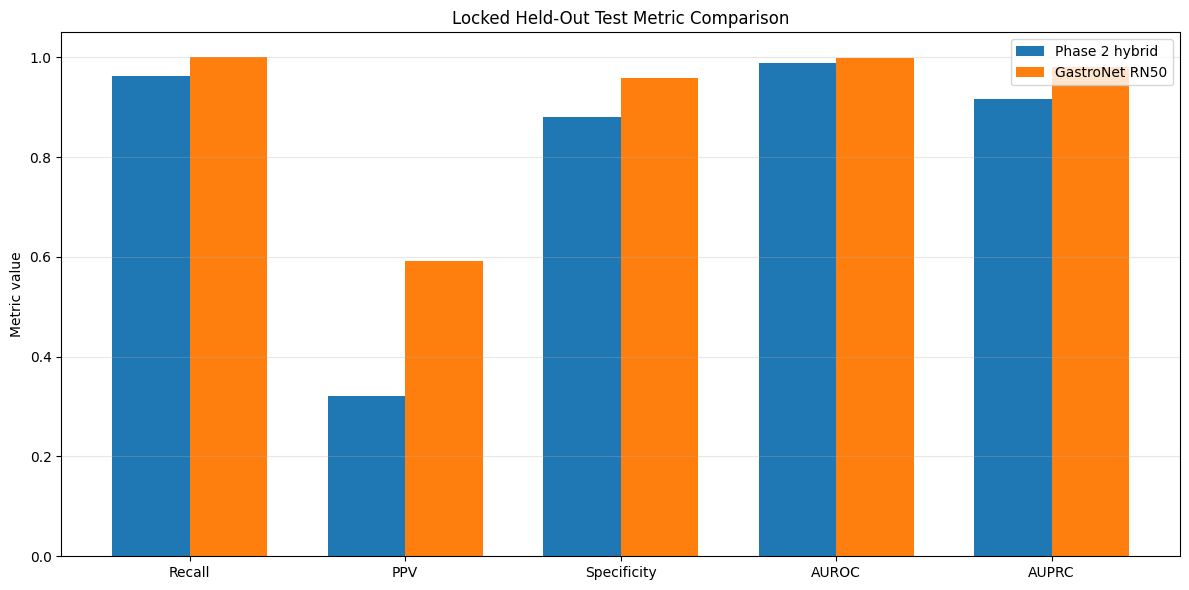

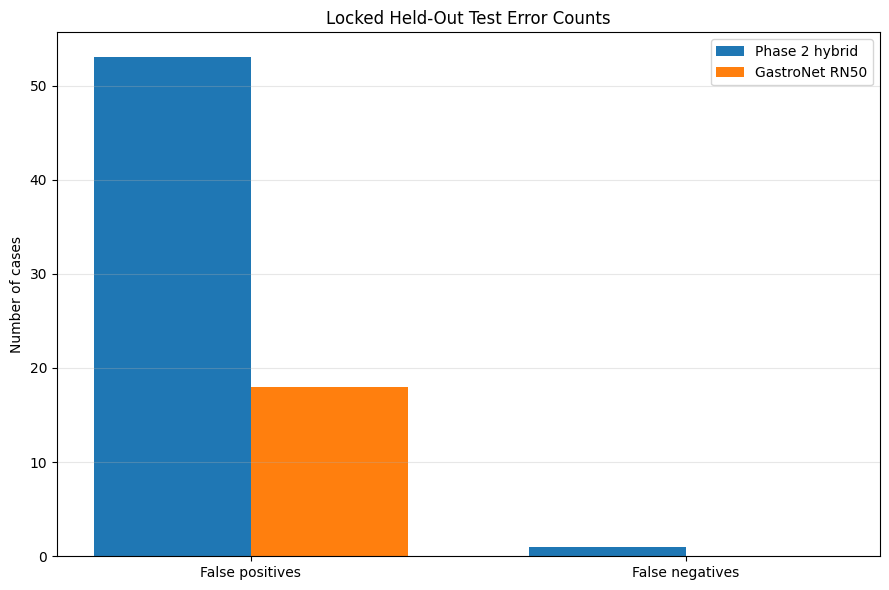

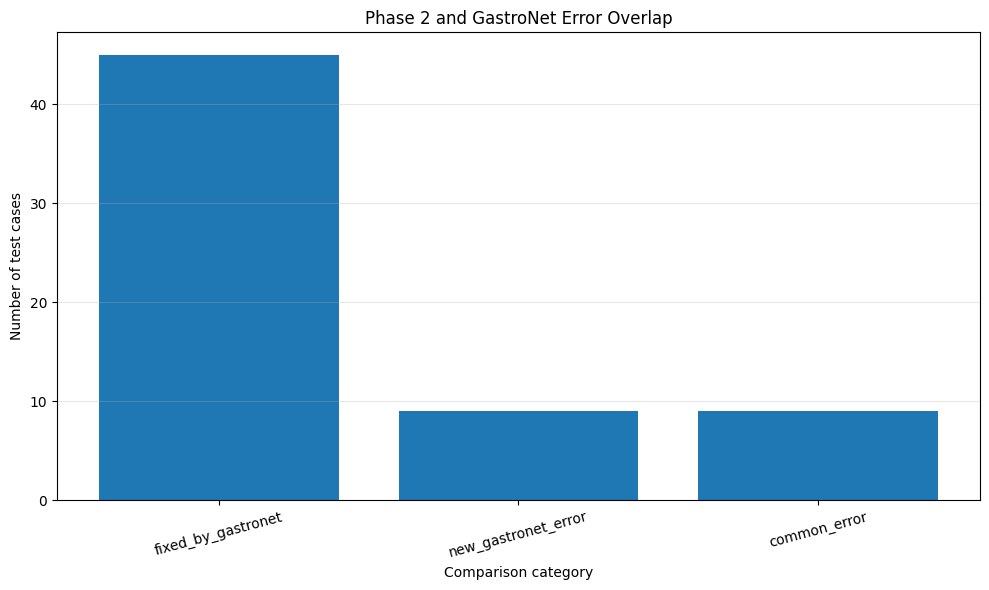


Overall locked metric comparison:


,metric,phase2_hybrid,gastronet_rn50,absolute_change
0,recall,0.961538,1.000000,0.038462
1,precision,0.320513,0.590909,0.270396
2,specificity,0.880090,0.959276,0.079186
3,auroc,0.988775,0.998695,0.009920
4,auprc,0.915444,0.981158,0.065714
5,tp,25.000000,26.000000,1.000000
6,tn,389.000000,424.000000,35.000000
7,fp,53.000000,18.000000,-35.000000
8,fn,1.000000,0.000000,-1.000000



Error-overlap summary:


,measure,count
0,phase2_total_errors,54
1,gastronet_total_errors,18
2,common_errors,9
3,phase2_errors_fixed_by_gastronet,45
4,new_gastronet_errors,9
5,common_false_positives,9
6,phase2_false_positives_fixed,44
7,new_gastronet_false_positives,9
8,phase2_false_negative_recovered,1



Per-centre locked comparison:


,center,model,sample_count,positive_count,negative_count,recall,precision,specificity,auroc,auprc,tp,tn,fp,fn
0,center_1,phase2_hybrid,344,10,334,0.9,0.290323,0.934132,0.985629,0.787291,9,312,22,1
1,center_1,gastronet_rn50,344,10,334,1.0,0.625000,0.982036,0.998503,0.954040,10,328,6,0
2,center_2,phase2_hybrid,124,16,108,1.0,0.340426,0.712963,1.000000,1.000000,16,77,31,0
3,center_2,gastronet_rn50,124,16,108,1.0,0.571429,0.888889,1.000000,1.000000,16,96,12,0



FINAL CELL 9B COMPARISON REPORT
Matched cases: 468/468
Phase 2 total errors: 54
GastroNet total errors: 18
False-positive reduction: 35
False-negative reduction: 1
Relative PPV improvement: 84.36%
Common false positives: 9
Phase 2 false positives fixed: 44
New GastroNet false positives: 9
Phase 2 false negative recovered: 1

New inference performed: False
Test threshold search performed: False
Model or ensemble selection performed: False

STATUS: LOCKED_DESCRIPTIVE_COMPARISON_COMPLETE

Saved records:
/content/drive/MyDrive/RARE26_GastroNet_Weights/ensembles/cell9b_phase2_vs_gastronet_all_case_comparison.csv
/content/drive/MyDrive/RARE26_GastroNet_Weights/results/cell9b_phase2_vs_gastronet_metric_comparison.csv
/content/drive/MyDrive/RARE26_GastroNet_Weights/centre_analysis/cell9b_phase2_vs_gastronet_per_centre_comparison.csv
/content/drive/MyDrive/RARE26_GastroNet_Weights/results/cell9b_phase2_vs_gastronet_error_overlap_summary.csv
/content/drive/MyDrive/RARE26_GastroNet_Weights/ensem

In [12]:
# ============================================================
# RARE26 GastroNet Extension — Cell 9B
# Locked GastroNet vs locked Phase 2 hybrid comparison
# Descriptive held-out error overlap only
# No model selection, threshold tuning, or new inference
# ============================================================

from pathlib import Path
from datetime import datetime, timezone
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
)

# ------------------------------------------------------------
# 1. Project paths
# ------------------------------------------------------------
PHASE2_ROOT = Path(
    "/content/drive/MyDrive/RARE26 Phase2"
)

GASTRONET_ROOT = Path(
    "/content/drive/MyDrive/RARE26_GastroNet_Weights"
)

EXPERIMENT_ID = "exp01_rn50_gastronet5m_dinov1"

GASTRONET_PREDICTIONS_PATH = (
    GASTRONET_ROOT
    / "predictions"
    / f"{EXPERIMENT_ID}_locked_test_predictions.csv"
)

GASTRONET_THRESHOLD_LOCK_PATH = (
    GASTRONET_ROOT
    / "thresholds"
    / f"{EXPERIMENT_ID}_threshold_lock.json"
)

RESULTS_DIR = GASTRONET_ROOT / "results"
CENTRE_DIR = GASTRONET_ROOT / "centre_analysis"
ENSEMBLES_DIR = GASTRONET_ROOT / "ensembles"
FIGURES_DIR = GASTRONET_ROOT / "figures"

for directory in [
    RESULTS_DIR,
    CENTRE_DIR,
    ENSEMBLES_DIR,
    FIGURES_DIR,
]:
    directory.mkdir(
        parents=True,
        exist_ok=True,
    )

# Locate the exact Phase 2 prediction file.
phase2_matches = list(
    PHASE2_ROOT.rglob(
        "phase2a_hybrid_ensemble_test_predictions.csv"
    )
)

if len(phase2_matches) == 0:
    raise FileNotFoundError(
        "Phase 2 hybrid prediction file was not found."
    )

if len(phase2_matches) > 1:
    raise RuntimeError(
        "Multiple Phase 2 hybrid prediction files were found:\n"
        + "\n".join(str(path) for path in phase2_matches)
    )

PHASE2_PREDICTIONS_PATH = phase2_matches[0]

required_files = [
    PHASE2_PREDICTIONS_PATH,
    GASTRONET_PREDICTIONS_PATH,
    GASTRONET_THRESHOLD_LOCK_PATH,
]

for required_file in required_files:
    if not required_file.exists():
        raise FileNotFoundError(
            f"Required file not found:\n{required_file}"
        )

print("=" * 82)
print("CELL 9B: LOCKED PHASE 2 VS GASTRONET COMPARISON")
print("=" * 82)

print("\nPhase 2 predictions:")
print(PHASE2_PREDICTIONS_PATH)

print("\nGastroNet predictions:")
print(GASTRONET_PREDICTIONS_PATH)

# ------------------------------------------------------------
# 2. Locked thresholds
# ------------------------------------------------------------
PHASE2_LOCKED_THRESHOLD = 0.0275174922426231

with GASTRONET_THRESHOLD_LOCK_PATH.open(
    "r",
    encoding="utf-8",
) as file_handle:
    gastronet_threshold_record = json.load(
        file_handle
    )

if (
    gastronet_threshold_record.get("status")
    != "VALIDATION_THRESHOLD_LOCKED"
):
    raise RuntimeError(
        "GastroNet threshold record is not locked."
    )

GASTRONET_LOCKED_THRESHOLD = float(
    gastronet_threshold_record[
        "selected_threshold"
    ]
)

print("\nLocked thresholds:")
print(
    f"Phase 2 hybrid: "
    f"{PHASE2_LOCKED_THRESHOLD:.12f}"
)
print(
    f"GastroNet RN50: "
    f"{GASTRONET_LOCKED_THRESHOLD:.12f}"
)

# ------------------------------------------------------------
# 3. Load prediction files
# ------------------------------------------------------------
phase2_df = pd.read_csv(
    PHASE2_PREDICTIONS_PATH,
    low_memory=False,
).copy()

gastronet_df = pd.read_csv(
    GASTRONET_PREDICTIONS_PATH,
    low_memory=False,
).copy()

print("\nRaw file dimensions:")
print(
    f"Phase 2: {phase2_df.shape}"
)
print(
    f"GastroNet: {gastronet_df.shape}"
)

if len(phase2_df) != 468:
    raise RuntimeError(
        f"Phase 2 file should contain 468 rows, "
        f"but contains {len(phase2_df)}."
    )

if len(gastronet_df) != 468:
    raise RuntimeError(
        f"GastroNet file should contain 468 rows, "
        f"but contains {len(gastronet_df)}."
    )

# ------------------------------------------------------------
# 4. Column detection helpers
# ------------------------------------------------------------
def find_exact_column(
    dataframe,
    candidate_names,
):
    lower_map = {
        str(column).lower(): column
        for column in dataframe.columns
    }

    for candidate_name in candidate_names:
        if candidate_name.lower() in lower_map:
            return lower_map[
                candidate_name.lower()
            ]

    return None


def find_hybrid_probability_column(
    dataframe,
):
    exact_candidates = [
        "hybrid_probability",
        "phase2_hybrid_probability",
        "final_hybrid_probability",
        "ensemble_probability",
        "final_probability",
    ]

    exact_match = find_exact_column(
        dataframe,
        exact_candidates,
    )

    if exact_match is not None:
        return exact_match

    hybrid_probability_candidates = [
        column
        for column in dataframe.columns
        if (
            "hybrid" in str(column).lower()
            and (
                "prob" in str(column).lower()
                or "score" in str(column).lower()
            )
        )
    ]

    if len(hybrid_probability_candidates) == 1:
        return hybrid_probability_candidates[0]

    raise RuntimeError(
        "Could not uniquely identify the Phase 2 "
        "hybrid probability column.\n"
        f"Columns: {list(dataframe.columns)}"
    )


def find_prediction_column(
    dataframe,
    model_keyword=None,
):
    preferred_candidates = []

    if model_keyword is not None:
        preferred_candidates.extend(
            [
                f"{model_keyword}_prediction",
                f"{model_keyword}_predicted_label",
                f"{model_keyword}_class",
            ]
        )

    preferred_candidates.extend(
        [
            "prediction",
            "predicted_label",
            "final_prediction",
            "binary_prediction",
        ]
    )

    return find_exact_column(
        dataframe,
        preferred_candidates,
    )


def find_identity_column(
    dataframe,
):
    return find_exact_column(
        dataframe,
        [
            "relative_path",
            "image_path",
            "path",
            "colab_path",
            "file_path",
            "filename",
            "file_name",
        ],
    )


def canonical_case_id(
    path_value,
):
    normalized = (
        str(path_value)
        .replace("\\", "/")
        .strip()
    )

    parts = [
        part
        for part in normalized.split("/")
        if part not in {"", "."}
    ]

    if len(parts) >= 3:
        return "/".join(
            parts[-3:]
        ).lower()

    if len(parts) >= 1:
        return parts[-1].lower()

    return normalized.lower()


def normalize_center(
    value,
):
    text = (
        str(value)
        .strip()
        .lower()
        .replace("centre", "center")
        .replace("-", "_")
        .replace(" ", "_")
    )

    if text in {
        "1",
        "1.0",
        "c1",
        "center1",
        "center_1",
    }:
        return "center_1"

    if text in {
        "2",
        "2.0",
        "c2",
        "center2",
        "center_2",
    }:
        return "center_2"

    return text

# ------------------------------------------------------------
# 5. Detect Phase 2 columns
# ------------------------------------------------------------
phase2_identity_column = find_identity_column(
    phase2_df
)

phase2_label_column = find_exact_column(
    phase2_df,
    [
        "label",
        "target",
        "true_label",
        "y_true",
    ],
)

phase2_center_column = find_exact_column(
    phase2_df,
    [
        "center",
        "centre",
        "site",
    ],
)

phase2_probability_column = (
    find_hybrid_probability_column(
        phase2_df
    )
)

phase2_prediction_column = (
    find_prediction_column(
        phase2_df,
        model_keyword="hybrid",
    )
)

required_phase2_columns = {
    "identity": phase2_identity_column,
    "label": phase2_label_column,
    "center": phase2_center_column,
    "probability": phase2_probability_column,
}

missing_phase2_columns = [
    name
    for name, column
    in required_phase2_columns.items()
    if column is None
]

if missing_phase2_columns:
    raise RuntimeError(
        "Required Phase 2 columns were not detected:\n"
        f"{missing_phase2_columns}\n"
        f"Available columns: {list(phase2_df.columns)}"
    )

print("\nDetected Phase 2 columns:")
print(
    f"Identity:    {phase2_identity_column}"
)
print(
    f"Label:       {phase2_label_column}"
)
print(
    f"Center:      {phase2_center_column}"
)
print(
    f"Probability: {phase2_probability_column}"
)
print(
    f"Prediction:  {phase2_prediction_column}"
)

# ------------------------------------------------------------
# 6. Detect GastroNet columns
# ------------------------------------------------------------
gastronet_identity_column = find_identity_column(
    gastronet_df
)

gastronet_label_column = find_exact_column(
    gastronet_df,
    [
        "label",
        "target",
        "true_label",
    ],
)

gastronet_center_column = find_exact_column(
    gastronet_df,
    [
        "center",
        "centre",
    ],
)

gastronet_probability_column = find_exact_column(
    gastronet_df,
    [
        "probability",
        "gastronet_probability",
    ],
)

gastronet_prediction_column = find_exact_column(
    gastronet_df,
    [
        "prediction",
        "predicted_label",
    ],
)

required_gastronet_columns = {
    "identity": gastronet_identity_column,
    "label": gastronet_label_column,
    "center": gastronet_center_column,
    "probability": gastronet_probability_column,
    "prediction": gastronet_prediction_column,
}

missing_gastronet_columns = [
    name
    for name, column
    in required_gastronet_columns.items()
    if column is None
]

if missing_gastronet_columns:
    raise RuntimeError(
        "Required GastroNet columns were not detected:\n"
        f"{missing_gastronet_columns}"
    )

# ------------------------------------------------------------
# 7. Standardize Phase 2 records
# ------------------------------------------------------------
phase2_standard = pd.DataFrame(
    {
        "case_id": (
            phase2_df[
                phase2_identity_column
            ].apply(canonical_case_id)
        ),
        "phase2_original_path": (
            phase2_df[
                phase2_identity_column
            ].astype(str)
        ),
        "phase2_label": (
            phase2_df[
                phase2_label_column
            ].astype(int)
        ),
        "phase2_center": (
            phase2_df[
                phase2_center_column
            ].apply(normalize_center)
        ),
        "phase2_probability": (
            phase2_df[
                phase2_probability_column
            ].astype(float)
        ),
    }
)

phase2_derived_prediction = (
    phase2_standard[
        "phase2_probability"
    ]
    >= PHASE2_LOCKED_THRESHOLD
).astype(int)

if phase2_prediction_column is not None:
    phase2_stored_prediction = (
        phase2_df[
            phase2_prediction_column
        ].astype(int)
    )

    phase2_prediction_disagreements = int(
        (
            phase2_stored_prediction.to_numpy()
            != phase2_derived_prediction.to_numpy()
        ).sum()
    )

    print(
        "\nPhase 2 stored-vs-locked prediction "
        f"disagreements: "
        f"{phase2_prediction_disagreements}"
    )

    if phase2_prediction_disagreements > 0:
        raise RuntimeError(
            "Stored Phase 2 predictions do not agree "
            "with the locked threshold."
        )

phase2_standard[
    "phase2_prediction"
] = phase2_derived_prediction

# ------------------------------------------------------------
# 8. Standardize GastroNet records
# ------------------------------------------------------------
gastronet_standard = pd.DataFrame(
    {
        "case_id": (
            gastronet_df[
                gastronet_identity_column
            ].apply(canonical_case_id)
        ),
        "gastronet_original_path": (
            gastronet_df[
                gastronet_identity_column
            ].astype(str)
        ),
        "gastronet_label": (
            gastronet_df[
                gastronet_label_column
            ].astype(int)
        ),
        "gastronet_center": (
            gastronet_df[
                gastronet_center_column
            ].apply(normalize_center)
        ),
        "gastronet_probability": (
            gastronet_df[
                gastronet_probability_column
            ].astype(float)
        ),
        "gastronet_prediction": (
            gastronet_df[
                gastronet_prediction_column
            ].astype(int)
        ),
    }
)

gastronet_derived_prediction = (
    gastronet_standard[
        "gastronet_probability"
    ]
    >= GASTRONET_LOCKED_THRESHOLD
).astype(int)

gastronet_prediction_disagreements = int(
    (
        gastronet_standard[
            "gastronet_prediction"
        ].to_numpy()
        != gastronet_derived_prediction.to_numpy()
    ).sum()
)

print(
    "GastroNet stored-vs-locked prediction "
    f"disagreements: "
    f"{gastronet_prediction_disagreements}"
)

if gastronet_prediction_disagreements > 0:
    raise RuntimeError(
        "Stored GastroNet predictions do not agree "
        "with the locked threshold."
    )

# ------------------------------------------------------------
# 9. Identity and uniqueness checks
# ------------------------------------------------------------
for model_name, dataframe in [
    ("Phase 2", phase2_standard),
    ("GastroNet", gastronet_standard),
]:
    duplicate_count = int(
        dataframe["case_id"].duplicated().sum()
    )

    if duplicate_count > 0:
        raise RuntimeError(
            f"{model_name} contains "
            f"{duplicate_count} duplicate case IDs."
        )

# ------------------------------------------------------------
# 10. One-to-one merge
# ------------------------------------------------------------
comparison_df = phase2_standard.merge(
    gastronet_standard,
    on="case_id",
    how="inner",
    validate="one_to_one",
)

if len(comparison_df) != 468:
    phase2_only = sorted(
        set(phase2_standard["case_id"])
        - set(gastronet_standard["case_id"])
    )

    gastronet_only = sorted(
        set(gastronet_standard["case_id"])
        - set(phase2_standard["case_id"])
    )

    raise RuntimeError(
        "The two files could not be aligned for all "
        "468 test cases.\n"
        f"Matched: {len(comparison_df)}\n"
        f"Phase-2-only: {len(phase2_only)}\n"
        f"GastroNet-only: {len(gastronet_only)}"
    )

label_mismatch_count = int(
    (
        comparison_df["phase2_label"]
        != comparison_df["gastronet_label"]
    ).sum()
)

center_mismatch_count = int(
    (
        comparison_df["phase2_center"]
        != comparison_df["gastronet_center"]
    ).sum()
)

if label_mismatch_count > 0:
    raise RuntimeError(
        f"Label mismatch count: "
        f"{label_mismatch_count}"
    )

if center_mismatch_count > 0:
    raise RuntimeError(
        f"Center mismatch count: "
        f"{center_mismatch_count}"
    )

comparison_df["label"] = (
    comparison_df["phase2_label"]
)

comparison_df["center"] = (
    comparison_df["phase2_center"]
)

# ------------------------------------------------------------
# 11. Metric helper
# ------------------------------------------------------------
def calculate_metrics(
    labels,
    probabilities,
    predictions,
):
    labels = np.asarray(
        labels,
        dtype=int,
    )

    probabilities = np.asarray(
        probabilities,
        dtype=float,
    )

    predictions = np.asarray(
        predictions,
        dtype=int,
    )

    tp = int(
        (
            (labels == 1)
            & (predictions == 1)
        ).sum()
    )

    tn = int(
        (
            (labels == 0)
            & (predictions == 0)
        ).sum()
    )

    fp = int(
        (
            (labels == 0)
            & (predictions == 1)
        ).sum()
    )

    fn = int(
        (
            (labels == 1)
            & (predictions == 0)
        ).sum()
    )

    recall = (
        tp / (tp + fn)
        if (tp + fn) > 0
        else float("nan")
    )

    precision = (
        tp / (tp + fp)
        if (tp + fp) > 0
        else 0.0
    )

    specificity = (
        tn / (tn + fp)
        if (tn + fp) > 0
        else float("nan")
    )

    auroc = float(
        roc_auc_score(
            labels,
            probabilities,
        )
    )

    auprc = float(
        average_precision_score(
            labels,
            probabilities,
        )
    )

    return {
        "recall": recall,
        "precision": precision,
        "specificity": specificity,
        "auroc": auroc,
        "auprc": auprc,
        "tp": tp,
        "tn": tn,
        "fp": fp,
        "fn": fn,
    }


phase2_metrics = calculate_metrics(
    comparison_df["label"],
    comparison_df["phase2_probability"],
    comparison_df["phase2_prediction"],
)

gastronet_metrics = calculate_metrics(
    comparison_df["label"],
    comparison_df["gastronet_probability"],
    comparison_df["gastronet_prediction"],
)

# ------------------------------------------------------------
# 12. Verify known locked results
# ------------------------------------------------------------
expected_phase2_confusion = {
    "tp": 25,
    "tn": 389,
    "fp": 53,
    "fn": 1,
}

expected_gastronet_confusion = {
    "tp": 26,
    "tn": 424,
    "fp": 18,
    "fn": 0,
}

for key, expected_value in (
    expected_phase2_confusion.items()
):
    if phase2_metrics[key] != expected_value:
        raise RuntimeError(
            "Phase 2 locked metrics do not match "
            "the completed project record.\n"
            f"{key}: calculated "
            f"{phase2_metrics[key]}, "
            f"expected {expected_value}"
        )

for key, expected_value in (
    expected_gastronet_confusion.items()
):
    if gastronet_metrics[key] != expected_value:
        raise RuntimeError(
            "GastroNet locked metrics do not match "
            "Cell 8.\n"
            f"{key}: calculated "
            f"{gastronet_metrics[key]}, "
            f"expected {expected_value}"
        )

print("\nLocked result verification passed:")
print(
    "Phase 2 hybrid: TP=25, TN=389, "
    "FP=53, FN=1"
)
print(
    "GastroNet RN50: TP=26, TN=424, "
    "FP=18, FN=0"
)

# ------------------------------------------------------------
# 13. Error labels and overlap categories
# ------------------------------------------------------------
def assign_error_type(
    label,
    prediction,
):
    if label == 1 and prediction == 1:
        return "TP"

    if label == 0 and prediction == 0:
        return "TN"

    if label == 0 and prediction == 1:
        return "FP"

    return "FN"


comparison_df["phase2_error_type"] = [
    assign_error_type(label, prediction)
    for label, prediction in zip(
        comparison_df["label"],
        comparison_df["phase2_prediction"],
    )
]

comparison_df["gastronet_error_type"] = [
    assign_error_type(label, prediction)
    for label, prediction in zip(
        comparison_df["label"],
        comparison_df["gastronet_prediction"],
    )
]

comparison_df["phase2_is_error"] = (
    comparison_df["phase2_prediction"]
    != comparison_df["label"]
)

comparison_df["gastronet_is_error"] = (
    comparison_df["gastronet_prediction"]
    != comparison_df["label"]
)

conditions = [
    (
        ~comparison_df["phase2_is_error"]
        & ~comparison_df["gastronet_is_error"]
    ),
    (
        comparison_df["phase2_is_error"]
        & ~comparison_df["gastronet_is_error"]
    ),
    (
        ~comparison_df["phase2_is_error"]
        & comparison_df["gastronet_is_error"]
    ),
    (
        comparison_df["phase2_is_error"]
        & comparison_df["gastronet_is_error"]
    ),
]

category_names = [
    "both_correct",
    "fixed_by_gastronet",
    "new_gastronet_error",
    "common_error",
]

comparison_df["comparison_category"] = np.select(
    conditions,
    category_names,
    default="unclassified",
)

comparison_df["error_transition"] = (
    comparison_df["phase2_error_type"]
    + "_to_"
    + comparison_df["gastronet_error_type"]
)

# ------------------------------------------------------------
# 14. Overall comparison table
# ------------------------------------------------------------
metric_names = [
    "recall",
    "precision",
    "specificity",
    "auroc",
    "auprc",
    "tp",
    "tn",
    "fp",
    "fn",
]

comparison_rows = []

for metric_name in metric_names:
    phase2_value = phase2_metrics[
        metric_name
    ]

    gastronet_value = gastronet_metrics[
        metric_name
    ]

    comparison_rows.append(
        {
            "metric": metric_name,
            "phase2_hybrid": phase2_value,
            "gastronet_rn50": gastronet_value,
            "absolute_change": (
                gastronet_value
                - phase2_value
            ),
        }
    )

metric_comparison_df = pd.DataFrame(
    comparison_rows
)

ppv_relative_improvement = (
    (
        gastronet_metrics["precision"]
        - phase2_metrics["precision"]
    )
    / phase2_metrics["precision"]
)

fp_reduction = (
    phase2_metrics["fp"]
    - gastronet_metrics["fp"]
)

fn_reduction = (
    phase2_metrics["fn"]
    - gastronet_metrics["fn"]
)

# ------------------------------------------------------------
# 15. Error overlap summaries
# ------------------------------------------------------------
category_summary_df = (
    comparison_df[
        "comparison_category"
    ]
    .value_counts()
    .reindex(
        category_names,
        fill_value=0,
    )
    .rename_axis(
        "comparison_category"
    )
    .reset_index(
        name="case_count"
    )
)

transition_summary_df = (
    comparison_df[
        "error_transition"
    ]
    .value_counts()
    .rename_axis(
        "error_transition"
    )
    .reset_index(
        name="case_count"
    )
)

phase2_error_df = comparison_df[
    comparison_df["phase2_is_error"]
].copy()

gastronet_error_df = comparison_df[
    comparison_df["gastronet_is_error"]
].copy()

fixed_by_gastronet_df = comparison_df[
    comparison_df["comparison_category"]
    == "fixed_by_gastronet"
].copy()

new_gastronet_error_df = comparison_df[
    comparison_df["comparison_category"]
    == "new_gastronet_error"
].copy()

common_error_df = comparison_df[
    comparison_df["comparison_category"]
    == "common_error"
].copy()

common_fp_count = int(
    (
        (comparison_df["phase2_error_type"] == "FP")
        & (
            comparison_df["gastronet_error_type"]
            == "FP"
        )
    ).sum()
)

phase2_fp_fixed_count = int(
    (
        (comparison_df["phase2_error_type"] == "FP")
        & (
            comparison_df["gastronet_error_type"]
            == "TN"
        )
    ).sum()
)

gastronet_new_fp_count = int(
    (
        (comparison_df["phase2_error_type"] == "TN")
        & (
            comparison_df["gastronet_error_type"]
            == "FP"
        )
    ).sum()
)

phase2_fn_recovered_count = int(
    (
        (comparison_df["phase2_error_type"] == "FN")
        & (
            comparison_df["gastronet_error_type"]
            == "TP"
        )
    ).sum()
)

error_overlap_summary_df = pd.DataFrame(
    [
        {
            "measure": "phase2_total_errors",
            "count": int(
                phase2_error_df.shape[0]
            ),
        },
        {
            "measure": "gastronet_total_errors",
            "count": int(
                gastronet_error_df.shape[0]
            ),
        },
        {
            "measure": "common_errors",
            "count": int(
                common_error_df.shape[0]
            ),
        },
        {
            "measure": "phase2_errors_fixed_by_gastronet",
            "count": int(
                fixed_by_gastronet_df.shape[0]
            ),
        },
        {
            "measure": "new_gastronet_errors",
            "count": int(
                new_gastronet_error_df.shape[0]
            ),
        },
        {
            "measure": "common_false_positives",
            "count": common_fp_count,
        },
        {
            "measure": "phase2_false_positives_fixed",
            "count": phase2_fp_fixed_count,
        },
        {
            "measure": "new_gastronet_false_positives",
            "count": gastronet_new_fp_count,
        },
        {
            "measure": "phase2_false_negative_recovered",
            "count": phase2_fn_recovered_count,
        },
    ]
)

# ------------------------------------------------------------
# 16. Per-centre comparison
# ------------------------------------------------------------
centre_rows = []

for center_name, center_group in (
    comparison_df.groupby(
        "center"
    )
):
    phase2_center_metrics = (
        calculate_metrics(
            center_group["label"],
            center_group[
                "phase2_probability"
            ],
            center_group[
                "phase2_prediction"
            ],
        )
    )

    gastronet_center_metrics = (
        calculate_metrics(
            center_group["label"],
            center_group[
                "gastronet_probability"
            ],
            center_group[
                "gastronet_prediction"
            ],
        )
    )

    for model_name, metrics in [
        (
            "phase2_hybrid",
            phase2_center_metrics,
        ),
        (
            "gastronet_rn50",
            gastronet_center_metrics,
        ),
    ]:
        centre_rows.append(
            {
                "center": center_name,
                "model": model_name,
                "sample_count": len(
                    center_group
                ),
                "positive_count": int(
                    center_group[
                        "label"
                    ].sum()
                ),
                "negative_count": int(
                    (
                        center_group["label"]
                        == 0
                    ).sum()
                ),
                **metrics,
            }
        )

centre_comparison_df = pd.DataFrame(
    centre_rows
)

# ------------------------------------------------------------
# 17. Save comparison records
# ------------------------------------------------------------
ALL_CASES_PATH = (
    ENSEMBLES_DIR
    / "cell9b_phase2_vs_gastronet_all_case_comparison.csv"
)

METRIC_COMPARISON_PATH = (
    RESULTS_DIR
    / "cell9b_phase2_vs_gastronet_metric_comparison.csv"
)

CENTRE_COMPARISON_PATH = (
    CENTRE_DIR
    / "cell9b_phase2_vs_gastronet_per_centre_comparison.csv"
)

CATEGORY_SUMMARY_PATH = (
    RESULTS_DIR
    / "cell9b_phase2_vs_gastronet_category_summary.csv"
)

TRANSITION_SUMMARY_PATH = (
    RESULTS_DIR
    / "cell9b_phase2_vs_gastronet_error_transitions.csv"
)

ERROR_OVERLAP_SUMMARY_PATH = (
    RESULTS_DIR
    / "cell9b_phase2_vs_gastronet_error_overlap_summary.csv"
)

FIXED_CASES_PATH = (
    ENSEMBLES_DIR
    / "cell9b_phase2_errors_fixed_by_gastronet.csv"
)

NEW_ERRORS_PATH = (
    ENSEMBLES_DIR
    / "cell9b_new_gastronet_errors.csv"
)

COMMON_ERRORS_PATH = (
    ENSEMBLES_DIR
    / "cell9b_common_errors.csv"
)

STATUS_PATH = (
    RESULTS_DIR
    / "cell9b_phase2_vs_gastronet_comparison_status.json"
)

SUMMARY_PATH = (
    RESULTS_DIR
    / "cell9b_phase2_vs_gastronet_conclusion.txt"
)

comparison_df.to_csv(
    ALL_CASES_PATH,
    index=False,
)

metric_comparison_df.to_csv(
    METRIC_COMPARISON_PATH,
    index=False,
)

centre_comparison_df.to_csv(
    CENTRE_COMPARISON_PATH,
    index=False,
)

category_summary_df.to_csv(
    CATEGORY_SUMMARY_PATH,
    index=False,
)

transition_summary_df.to_csv(
    TRANSITION_SUMMARY_PATH,
    index=False,
)

error_overlap_summary_df.to_csv(
    ERROR_OVERLAP_SUMMARY_PATH,
    index=False,
)

fixed_by_gastronet_df.to_csv(
    FIXED_CASES_PATH,
    index=False,
)

new_gastronet_error_df.to_csv(
    NEW_ERRORS_PATH,
    index=False,
)

common_error_df.to_csv(
    COMMON_ERRORS_PATH,
    index=False,
)

# ------------------------------------------------------------
# 18. Overall metric comparison figure
# ------------------------------------------------------------
figure_path_metrics = (
    FIGURES_DIR
    / "cell9b_phase2_vs_gastronet_metric_comparison.png"
)

display_metrics = [
    "recall",
    "precision",
    "specificity",
    "auroc",
    "auprc",
]

x_positions = np.arange(
    len(display_metrics)
)

bar_width = 0.36

phase2_values = [
    phase2_metrics[metric]
    for metric in display_metrics
]

gastronet_values = [
    gastronet_metrics[metric]
    for metric in display_metrics
]

figure = plt.figure(
    figsize=(12, 6)
)

plt.bar(
    x_positions - bar_width / 2,
    phase2_values,
    width=bar_width,
    label="Phase 2 hybrid",
)

plt.bar(
    x_positions + bar_width / 2,
    gastronet_values,
    width=bar_width,
    label="GastroNet RN50",
)

plt.xticks(
    x_positions,
    [
        "Recall",
        "PPV",
        "Specificity",
        "AUROC",
        "AUPRC",
    ],
)

plt.ylim(
    0,
    1.05,
)

plt.ylabel(
    "Metric value"
)

plt.title(
    "Locked Held-Out Test Metric Comparison"
)

plt.legend()
plt.grid(
    axis="y",
    alpha=0.3,
)

plt.tight_layout()

figure.savefig(
    figure_path_metrics,
    dpi=200,
    bbox_inches="tight",
)

plt.show()
plt.close(figure)

# ------------------------------------------------------------
# 19. FP/FN comparison figure
# ------------------------------------------------------------
figure_path_errors = (
    FIGURES_DIR
    / "cell9b_phase2_vs_gastronet_error_counts.png"
)

figure = plt.figure(
    figsize=(9, 6)
)

error_x = np.arange(2)

plt.bar(
    error_x - bar_width / 2,
    [
        phase2_metrics["fp"],
        phase2_metrics["fn"],
    ],
    width=bar_width,
    label="Phase 2 hybrid",
)

plt.bar(
    error_x + bar_width / 2,
    [
        gastronet_metrics["fp"],
        gastronet_metrics["fn"],
    ],
    width=bar_width,
    label="GastroNet RN50",
)

plt.xticks(
    error_x,
    [
        "False positives",
        "False negatives",
    ],
)

plt.ylabel(
    "Number of cases"
)

plt.title(
    "Locked Held-Out Test Error Counts"
)

plt.legend()
plt.grid(
    axis="y",
    alpha=0.3,
)

plt.tight_layout()

figure.savefig(
    figure_path_errors,
    dpi=200,
    bbox_inches="tight",
)

plt.show()
plt.close(figure)

# ------------------------------------------------------------
# 20. Error-overlap figure
# ------------------------------------------------------------
figure_path_overlap = (
    FIGURES_DIR
    / "cell9b_phase2_vs_gastronet_error_overlap.png"
)

overlap_plot_df = category_summary_df[
    category_summary_df[
        "comparison_category"
    ].isin(
        [
            "fixed_by_gastronet",
            "new_gastronet_error",
            "common_error",
        ]
    )
].copy()

figure = plt.figure(
    figsize=(10, 6)
)

plt.bar(
    overlap_plot_df[
        "comparison_category"
    ],
    overlap_plot_df[
        "case_count"
    ],
)

plt.ylabel(
    "Number of test cases"
)

plt.xlabel(
    "Comparison category"
)

plt.title(
    "Phase 2 and GastroNet Error Overlap"
)

plt.xticks(
    rotation=15,
)

plt.grid(
    axis="y",
    alpha=0.3,
)

plt.tight_layout()

figure.savefig(
    figure_path_overlap,
    dpi=200,
    bbox_inches="tight",
)

plt.show()
plt.close(figure)

# ------------------------------------------------------------
# 21. Save status and conclusion
# ------------------------------------------------------------
status_record = {
    "created_utc": datetime.now(
        timezone.utc
    ).isoformat(),
    "status": (
        "LOCKED_DESCRIPTIVE_COMPARISON_COMPLETE"
    ),
    "phase2_prediction_path": str(
        PHASE2_PREDICTIONS_PATH
    ),
    "gastronet_prediction_path": str(
        GASTRONET_PREDICTIONS_PATH
    ),
    "phase2_threshold": (
        PHASE2_LOCKED_THRESHOLD
    ),
    "gastronet_threshold": (
        GASTRONET_LOCKED_THRESHOLD
    ),
    "matched_test_cases": int(
        len(comparison_df)
    ),
    "phase2_metrics": {
        key: float(value)
        for key, value in phase2_metrics.items()
    },
    "gastronet_metrics": {
        key: float(value)
        for key, value in gastronet_metrics.items()
    },
    "ppv_relative_improvement": float(
        ppv_relative_improvement
    ),
    "false_positive_reduction": int(
        fp_reduction
    ),
    "false_negative_reduction": int(
        fn_reduction
    ),
    "common_false_positives": int(
        common_fp_count
    ),
    "phase2_false_positives_fixed": int(
        phase2_fp_fixed_count
    ),
    "new_gastronet_false_positives": int(
        gastronet_new_fp_count
    ),
    "phase2_false_negative_recovered": int(
        phase2_fn_recovered_count
    ),
    "new_inference_performed": False,
    "test_threshold_search_performed": False,
    "model_or_ensemble_selection_performed": False,
    "scientific_rule": (
        "This held-out comparison is descriptive only "
        "and must not be used to tune thresholds, "
        "weights, epochs, or ensemble composition."
    ),
}

STATUS_PATH.write_text(
    json.dumps(
        status_record,
        indent=2,
        ensure_ascii=False,
    ),
    encoding="utf-8",
)

summary_lines = [
    "RARE26 GastroNet Experiment 01",
    "Locked Phase 2 Hybrid Comparison",
    "=" * 68,
    "",
    "Phase 2 hybrid:",
    (
        f"Recall {phase2_metrics['recall']:.6f}, "
        f"PPV {phase2_metrics['precision']:.6f}, "
        f"specificity {phase2_metrics['specificity']:.6f}, "
        f"AUROC {phase2_metrics['auroc']:.6f}, "
        f"AUPRC {phase2_metrics['auprc']:.6f}, "
        f"FP {phase2_metrics['fp']}, "
        f"FN {phase2_metrics['fn']}."
    ),
    "",
    "GastroNet ResNet-50:",
    (
        f"Recall {gastronet_metrics['recall']:.6f}, "
        f"PPV {gastronet_metrics['precision']:.6f}, "
        f"specificity {gastronet_metrics['specificity']:.6f}, "
        f"AUROC {gastronet_metrics['auroc']:.6f}, "
        f"AUPRC {gastronet_metrics['auprc']:.6f}, "
        f"FP {gastronet_metrics['fp']}, "
        f"FN {gastronet_metrics['fn']}."
    ),
    "",
    (
        f"False-positive reduction: "
        f"{fp_reduction}"
    ),
    (
        f"False-negative reduction: "
        f"{fn_reduction}"
    ),
    (
        f"Relative PPV improvement: "
        f"{ppv_relative_improvement * 100:.2f}%"
    ),
    (
        f"Common false positives: "
        f"{common_fp_count}"
    ),
    (
        f"Phase 2 false positives fixed: "
        f"{phase2_fp_fixed_count}"
    ),
    (
        f"New GastroNet false positives: "
        f"{gastronet_new_fp_count}"
    ),
    (
        f"Phase 2 false negative recovered: "
        f"{phase2_fn_recovered_count}"
    ),
    "",
    (
        "This comparison is descriptive only. "
        "No model, epoch, threshold, calibration "
        "setting, or ensemble weight was selected "
        "from held-out test evidence."
    ),
    "",
    "Status: LOCKED_DESCRIPTIVE_COMPARISON_COMPLETE",
]

SUMMARY_PATH.write_text(
    "\n".join(summary_lines),
    encoding="utf-8",
)

# ------------------------------------------------------------
# 22. Final report
# ------------------------------------------------------------
print("\nOverall locked metric comparison:")
display(metric_comparison_df)

print("\nError-overlap summary:")
display(error_overlap_summary_df)

print("\nPer-centre locked comparison:")
display(centre_comparison_df)

print("\n" + "=" * 82)
print("FINAL CELL 9B COMPARISON REPORT")
print("=" * 82)

print(
    f"Matched cases: "
    f"{len(comparison_df)}/468"
)

print(
    f"Phase 2 total errors: "
    f"{len(phase2_error_df)}"
)

print(
    f"GastroNet total errors: "
    f"{len(gastronet_error_df)}"
)

print(
    f"False-positive reduction: "
    f"{fp_reduction}"
)

print(
    f"False-negative reduction: "
    f"{fn_reduction}"
)

print(
    f"Relative PPV improvement: "
    f"{ppv_relative_improvement * 100:.2f}%"
)

print(
    f"Common false positives: "
    f"{common_fp_count}"
)

print(
    f"Phase 2 false positives fixed: "
    f"{phase2_fp_fixed_count}"
)

print(
    f"New GastroNet false positives: "
    f"{gastronet_new_fp_count}"
)

print(
    f"Phase 2 false negative recovered: "
    f"{phase2_fn_recovered_count}"
)

print("\nNew inference performed: False")
print("Test threshold search performed: False")
print("Model or ensemble selection performed: False")

print(
    "\nSTATUS: "
    "LOCKED_DESCRIPTIVE_COMPARISON_COMPLETE"
)

print("\nSaved records:")
print(ALL_CASES_PATH)
print(METRIC_COMPARISON_PATH)
print(CENTRE_COMPARISON_PATH)
print(ERROR_OVERLAP_SUMMARY_PATH)
print(FIXED_CASES_PATH)
print(NEW_ERRORS_PATH)
print(COMMON_ERRORS_PATH)
print(STATUS_PATH)
print(SUMMARY_PATH)
print(figure_path_metrics)
print(figure_path_errors)
print(figure_path_overlap)

CELL 10: PAIRED STRATIFIED BOOTSTRAP RELIABILITY

Bootstrap iterations: 1000
Random seed: 42
Sampling remains paired between the two locked models.

Locked test records verified:
Total cases: 468
Normal: 442
Neoplasia: 26

Centre/class strata:


,center,label,count
0,center_1,0,334
1,center_1,1,10
2,center_2,0,108
3,center_2,1,16



Running overall paired stratified bootstrap...
Running per-centre paired stratified bootstrap...


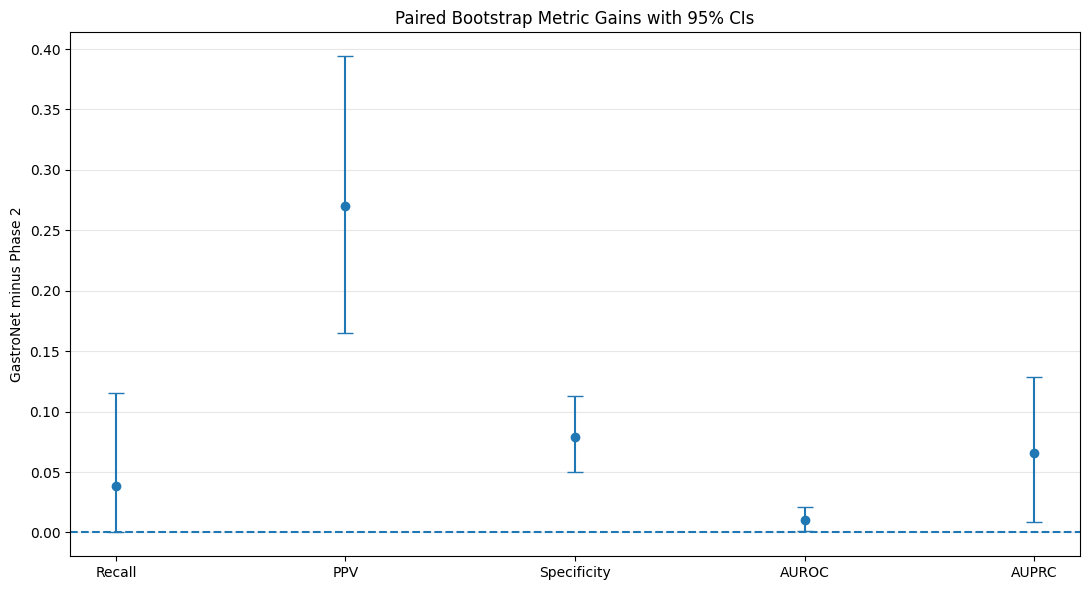

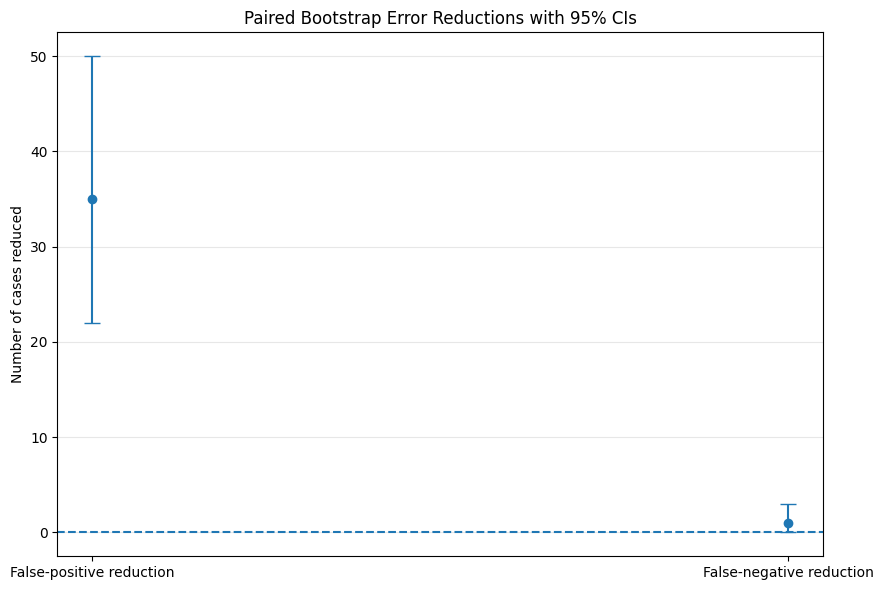


Overall paired bootstrap confidence intervals:


,measure,observed_change,bootstrap_mean,bootstrap_median,ci_2_5_percent,ci_97_5_percent,proportion_above_zero,proportion_at_or_above_zero,interpretation
0,recall_gain,0.038462,0.038654,0.038462,0.000000,0.115385,0.641,1.000,CI_includes_zero
1,ppv_gain,0.270396,0.274569,0.271318,0.165197,0.394092,1.000,1.000,CI_above_zero
2,specificity_gain,0.079186,0.079636,0.079186,0.049774,0.113122,1.000,1.000,CI_above_zero
3,auroc_gain,0.009920,0.009858,0.009485,0.001564,0.020801,0.991,0.991,CI_above_zero
4,auprc_gain,0.065714,0.064309,0.062785,0.008616,0.128980,0.987,0.987,CI_above_zero
5,fp_reduction,35.000000,35.199000,35.000000,22.000000,50.000000,1.000,1.000,CI_above_zero
6,fn_reduction,1.000000,1.005000,1.000000,0.000000,3.000000,0.641,1.000,CI_includes_zero



Per-centre paired bootstrap confidence intervals:


,center,measure,observed_change,bootstrap_mean,bootstrap_median,ci_2_5_percent,ci_97_5_percent,proportion_above_zero,proportion_at_or_above_zero,interpretation
0,center_1,recall_gain,0.100000,9.610000e-02,0.100000,0.000000e+00,3.000000e-01,0.635,1.000,CI_includes_zero
1,center_1,ppv_gain,0.334677,3.371465e-01,0.325000,1.635898e-01,5.630931e-01,1.000,1.000,CI_above_zero
2,center_1,specificity_gain,0.047904,4.702695e-02,0.047904,2.095808e-02,7.485030e-02,1.000,1.000,CI_above_zero
3,center_1,auroc_gain,0.012874,1.248174e-02,0.011677,5.988024e-04,2.994012e-02,0.985,0.990,CI_above_zero
4,center_1,auprc_gain,0.166750,1.599540e-01,0.154156,1.899351e-04,3.662911e-01,0.975,0.978,CI_above_zero
5,center_1,fp_reduction,16.000000,1.570700e+01,16.000000,7.000000e+00,2.500000e+01,1.000,1.000,CI_above_zero
6,center_1,fn_reduction,1.000000,9.610000e-01,1.000000,0.000000e+00,3.000000e+00,0.635,1.000,CI_includes_zero
7,center_2,recall_gain,0.000000,0.000000e+00,0.000000,0.000000e+00,0.000000e+00,0.000,1.000,CI_includes_zero
8,center_2,ppv_gain,0.231003,2.346774e-01,0.231724,1.126805e-01,3.691216e-01,1.000,1.000,CI_above_zero
9,center_2,specificity_gain,0.175926,1.750000e-01,0.175926,9.259259e-02,2.592593e-01,1.000,1.000,CI_above_zero



FINAL CELL 10 BOOTSTRAP REPORT
recall_gain: observed=0.038462, 95% CI=[0.000000, 0.115385]
ppv_gain: observed=0.270396, 95% CI=[0.165197, 0.394092]
specificity_gain: observed=0.079186, 95% CI=[0.049774, 0.113122]
auroc_gain: observed=0.009920, 95% CI=[0.001564, 0.020801]
auprc_gain: observed=0.065714, 95% CI=[0.008616, 0.128980]
fp_reduction: observed=35.000000, 95% CI=[22.000000, 50.000000]
fn_reduction: observed=1.000000, 95% CI=[0.000000, 3.000000]

New inference performed: False
Threshold search performed: False
Model selection performed: False
Test predictions modified: False

STATUS: PAIRED_STRATIFIED_BOOTSTRAP_COMPLETE

Saved records:
/content/drive/MyDrive/RARE26_GastroNet_Weights/results/cell10_paired_bootstrap_overall_samples.csv
/content/drive/MyDrive/RARE26_GastroNet_Weights/results/cell10_paired_bootstrap_overall_ci_summary.csv
/content/drive/MyDrive/RARE26_GastroNet_Weights/centre_analysis/cell10_paired_bootstrap_per_centre_samples.csv
/content/drive/MyDrive/RARE26_Gastr

In [13]:
# ============================================================
# RARE26 GastroNet Extension — Cell 10
# Paired stratified bootstrap comparison
# Existing locked predictions only
# No inference, tuning, threshold search, or model selection
# ============================================================

from pathlib import Path
from datetime import datetime, timezone
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
)

# ------------------------------------------------------------
# 1. Paths and settings
# ------------------------------------------------------------
PROJECT_ROOT = Path(
    "/content/drive/MyDrive/RARE26_GastroNet_Weights"
)

COMPARISON_PATH = (
    PROJECT_ROOT
    / "ensembles"
    / "cell9b_phase2_vs_gastronet_all_case_comparison.csv"
)

RESULTS_DIR = PROJECT_ROOT / "results"
CENTRE_DIR = PROJECT_ROOT / "centre_analysis"
FIGURES_DIR = PROJECT_ROOT / "figures"

for directory in [
    RESULTS_DIR,
    CENTRE_DIR,
    FIGURES_DIR,
]:
    directory.mkdir(parents=True, exist_ok=True)

OVERALL_SAMPLES_PATH = (
    RESULTS_DIR
    / "cell10_paired_bootstrap_overall_samples.csv"
)

OVERALL_SUMMARY_PATH = (
    RESULTS_DIR
    / "cell10_paired_bootstrap_overall_ci_summary.csv"
)

CENTRE_SAMPLES_PATH = (
    CENTRE_DIR
    / "cell10_paired_bootstrap_per_centre_samples.csv"
)

CENTRE_SUMMARY_PATH = (
    CENTRE_DIR
    / "cell10_paired_bootstrap_per_centre_ci_summary.csv"
)

STATUS_PATH = (
    RESULTS_DIR
    / "cell10_paired_bootstrap_status.json"
)

CONCLUSION_PATH = (
    RESULTS_DIR
    / "cell10_paired_bootstrap_conclusion.txt"
)

METRIC_FIGURE_PATH = (
    FIGURES_DIR
    / "cell10_paired_bootstrap_metric_gain_ci.png"
)

ERROR_FIGURE_PATH = (
    FIGURES_DIR
    / "cell10_paired_bootstrap_error_reduction_ci.png"
)

if not COMPARISON_PATH.exists():
    raise FileNotFoundError(
        f"Cell 9B comparison file not found:\n{COMPARISON_PATH}"
    )

existing_outputs = [
    path
    for path in [
        OVERALL_SAMPLES_PATH,
        OVERALL_SUMMARY_PATH,
        CENTRE_SAMPLES_PATH,
        CENTRE_SUMMARY_PATH,
        STATUS_PATH,
    ]
    if path.exists()
]

if existing_outputs:
    raise FileExistsError(
        "Cell 10 outputs already exist. Do not overwrite them:\n"
        + "\n".join(str(path) for path in existing_outputs)
    )

SEED = 42
NUMBER_OF_BOOTSTRAPS = 1000
LOWER_PERCENTILE = 2.5
UPPER_PERCENTILE = 97.5

rng = np.random.default_rng(SEED)

print("=" * 82)
print("CELL 10: PAIRED STRATIFIED BOOTSTRAP RELIABILITY")
print("=" * 82)

print(f"\nBootstrap iterations: {NUMBER_OF_BOOTSTRAPS}")
print(f"Random seed: {SEED}")
print("Sampling remains paired between the two locked models.")

# ------------------------------------------------------------
# 2. Load and verify locked comparison records
# ------------------------------------------------------------
comparison_df = pd.read_csv(
    COMPARISON_PATH,
    low_memory=False,
).copy()

required_columns = {
    "case_id",
    "center",
    "label",
    "phase2_probability",
    "phase2_prediction",
    "gastronet_probability",
    "gastronet_prediction",
}

missing_columns = (
    required_columns
    - set(comparison_df.columns)
)

if missing_columns:
    raise RuntimeError(
        f"Missing comparison columns: {sorted(missing_columns)}"
    )

if len(comparison_df) != 468:
    raise RuntimeError(
        f"Expected 468 cases, found {len(comparison_df)}."
    )

if comparison_df["case_id"].duplicated().any():
    raise RuntimeError(
        "Duplicate case IDs were found."
    )

comparison_df["label"] = (
    comparison_df["label"].astype(int)
)

for column in [
    "phase2_prediction",
    "gastronet_prediction",
]:
    comparison_df[column] = (
        comparison_df[column].astype(int)
    )

for column in [
    "phase2_probability",
    "gastronet_probability",
]:
    comparison_df[column] = (
        comparison_df[column].astype(float)
    )

print("\nLocked test records verified:")
print(f"Total cases: {len(comparison_df)}")
print(
    f"Normal: {(comparison_df['label'] == 0).sum()}"
)
print(
    f"Neoplasia: {(comparison_df['label'] == 1).sum()}"
)

print("\nCentre/class strata:")
display(
    comparison_df.groupby(
        ["center", "label"]
    ).size().reset_index(name="count")
)

# ------------------------------------------------------------
# 3. Metric function
# ------------------------------------------------------------
def calculate_metrics(
    labels,
    probabilities,
    predictions,
):
    labels = np.asarray(labels, dtype=int)
    probabilities = np.asarray(
        probabilities,
        dtype=float,
    )
    predictions = np.asarray(
        predictions,
        dtype=int,
    )

    tp = int(
        ((labels == 1) & (predictions == 1)).sum()
    )
    tn = int(
        ((labels == 0) & (predictions == 0)).sum()
    )
    fp = int(
        ((labels == 0) & (predictions == 1)).sum()
    )
    fn = int(
        ((labels == 1) & (predictions == 0)).sum()
    )

    recall = (
        tp / (tp + fn)
        if (tp + fn) > 0
        else np.nan
    )

    precision = (
        tp / (tp + fp)
        if (tp + fp) > 0
        else 0.0
    )

    specificity = (
        tn / (tn + fp)
        if (tn + fp) > 0
        else np.nan
    )

    auroc = float(
        roc_auc_score(
            labels,
            probabilities,
        )
    )

    auprc = float(
        average_precision_score(
            labels,
            probabilities,
        )
    )

    return {
        "recall": float(recall),
        "precision": float(precision),
        "specificity": float(specificity),
        "auroc": auroc,
        "auprc": auprc,
        "tp": tp,
        "tn": tn,
        "fp": fp,
        "fn": fn,
    }

# ------------------------------------------------------------
# 4. Paired stratified resampling
# ------------------------------------------------------------
def paired_stratified_sample(
    dataframe,
    random_generator,
    strata_columns,
):
    sampled_parts = []

    for _, group in dataframe.groupby(
        strata_columns,
        sort=True,
        dropna=False,
    ):
        sampled_positions = (
            random_generator.integers(
                low=0,
                high=len(group),
                size=len(group),
            )
        )

        sampled_parts.append(
            group.iloc[
                sampled_positions
            ].copy()
        )

    return pd.concat(
        sampled_parts,
        ignore_index=True,
    )

# ------------------------------------------------------------
# 5. Original observed metrics
# ------------------------------------------------------------
observed_phase2 = calculate_metrics(
    comparison_df["label"],
    comparison_df["phase2_probability"],
    comparison_df["phase2_prediction"],
)

observed_gastronet = calculate_metrics(
    comparison_df["label"],
    comparison_df["gastronet_probability"],
    comparison_df["gastronet_prediction"],
)

observed_differences = {
    "recall_gain": (
        observed_gastronet["recall"]
        - observed_phase2["recall"]
    ),
    "ppv_gain": (
        observed_gastronet["precision"]
        - observed_phase2["precision"]
    ),
    "specificity_gain": (
        observed_gastronet["specificity"]
        - observed_phase2["specificity"]
    ),
    "auroc_gain": (
        observed_gastronet["auroc"]
        - observed_phase2["auroc"]
    ),
    "auprc_gain": (
        observed_gastronet["auprc"]
        - observed_phase2["auprc"]
    ),
    "fp_reduction": (
        observed_phase2["fp"]
        - observed_gastronet["fp"]
    ),
    "fn_reduction": (
        observed_phase2["fn"]
        - observed_gastronet["fn"]
    ),
}

# ------------------------------------------------------------
# 6. Overall paired bootstrap
# ------------------------------------------------------------
overall_bootstrap_rows = []

print("\nRunning overall paired stratified bootstrap...")

for bootstrap_index in range(
    1,
    NUMBER_OF_BOOTSTRAPS + 1,
):
    sampled_df = paired_stratified_sample(
        comparison_df,
        random_generator=rng,
        strata_columns=["center", "label"],
    )

    phase2_metrics = calculate_metrics(
        sampled_df["label"],
        sampled_df["phase2_probability"],
        sampled_df["phase2_prediction"],
    )

    gastronet_metrics = calculate_metrics(
        sampled_df["label"],
        sampled_df["gastronet_probability"],
        sampled_df["gastronet_prediction"],
    )

    overall_bootstrap_rows.append(
        {
            "bootstrap_iteration": bootstrap_index,

            "phase2_recall": phase2_metrics["recall"],
            "gastronet_recall": gastronet_metrics["recall"],
            "recall_gain": (
                gastronet_metrics["recall"]
                - phase2_metrics["recall"]
            ),

            "phase2_ppv": phase2_metrics["precision"],
            "gastronet_ppv": gastronet_metrics["precision"],
            "ppv_gain": (
                gastronet_metrics["precision"]
                - phase2_metrics["precision"]
            ),

            "phase2_specificity": (
                phase2_metrics["specificity"]
            ),
            "gastronet_specificity": (
                gastronet_metrics["specificity"]
            ),
            "specificity_gain": (
                gastronet_metrics["specificity"]
                - phase2_metrics["specificity"]
            ),

            "phase2_auroc": phase2_metrics["auroc"],
            "gastronet_auroc": gastronet_metrics["auroc"],
            "auroc_gain": (
                gastronet_metrics["auroc"]
                - phase2_metrics["auroc"]
            ),

            "phase2_auprc": phase2_metrics["auprc"],
            "gastronet_auprc": gastronet_metrics["auprc"],
            "auprc_gain": (
                gastronet_metrics["auprc"]
                - phase2_metrics["auprc"]
            ),

            "phase2_fp": phase2_metrics["fp"],
            "gastronet_fp": gastronet_metrics["fp"],
            "fp_reduction": (
                phase2_metrics["fp"]
                - gastronet_metrics["fp"]
            ),

            "phase2_fn": phase2_metrics["fn"],
            "gastronet_fn": gastronet_metrics["fn"],
            "fn_reduction": (
                phase2_metrics["fn"]
                - gastronet_metrics["fn"]
            ),
        }
    )

overall_bootstrap_df = pd.DataFrame(
    overall_bootstrap_rows
)

# ------------------------------------------------------------
# 7. Per-centre paired bootstrap
# ------------------------------------------------------------
centre_bootstrap_rows = []

print("Running per-centre paired stratified bootstrap...")

for center_name, center_df in comparison_df.groupby(
    "center",
    sort=True,
):
    center_rng = np.random.default_rng(
        SEED
        + (
            1
            if center_name == "center_1"
            else 2
        )
    )

    for bootstrap_index in range(
        1,
        NUMBER_OF_BOOTSTRAPS + 1,
    ):
        sampled_df = paired_stratified_sample(
            center_df,
            random_generator=center_rng,
            strata_columns=["label"],
        )

        phase2_metrics = calculate_metrics(
            sampled_df["label"],
            sampled_df["phase2_probability"],
            sampled_df["phase2_prediction"],
        )

        gastronet_metrics = calculate_metrics(
            sampled_df["label"],
            sampled_df["gastronet_probability"],
            sampled_df["gastronet_prediction"],
        )

        centre_bootstrap_rows.append(
            {
                "center": center_name,
                "bootstrap_iteration": bootstrap_index,
                "recall_gain": (
                    gastronet_metrics["recall"]
                    - phase2_metrics["recall"]
                ),
                "ppv_gain": (
                    gastronet_metrics["precision"]
                    - phase2_metrics["precision"]
                ),
                "specificity_gain": (
                    gastronet_metrics["specificity"]
                    - phase2_metrics["specificity"]
                ),
                "auroc_gain": (
                    gastronet_metrics["auroc"]
                    - phase2_metrics["auroc"]
                ),
                "auprc_gain": (
                    gastronet_metrics["auprc"]
                    - phase2_metrics["auprc"]
                ),
                "fp_reduction": (
                    phase2_metrics["fp"]
                    - gastronet_metrics["fp"]
                ),
                "fn_reduction": (
                    phase2_metrics["fn"]
                    - gastronet_metrics["fn"]
                ),
            }
        )

centre_bootstrap_df = pd.DataFrame(
    centre_bootstrap_rows
)

# ------------------------------------------------------------
# 8. Confidence interval summaries
# ------------------------------------------------------------
difference_columns = [
    "recall_gain",
    "ppv_gain",
    "specificity_gain",
    "auroc_gain",
    "auprc_gain",
    "fp_reduction",
    "fn_reduction",
]

def summarize_difference(
    values,
    observed_value,
):
    values = np.asarray(
        values,
        dtype=float,
    )

    lower_ci = float(
        np.percentile(
            values,
            LOWER_PERCENTILE,
        )
    )

    upper_ci = float(
        np.percentile(
            values,
            UPPER_PERCENTILE,
        )
    )

    if lower_ci > 0:
        interpretation = "CI_above_zero"
    elif upper_ci < 0:
        interpretation = "CI_below_zero"
    else:
        interpretation = "CI_includes_zero"

    return {
        "observed_change": float(
            observed_value
        ),
        "bootstrap_mean": float(
            np.mean(values)
        ),
        "bootstrap_median": float(
            np.median(values)
        ),
        "ci_2_5_percent": lower_ci,
        "ci_97_5_percent": upper_ci,
        "proportion_above_zero": float(
            np.mean(values > 0)
        ),
        "proportion_at_or_above_zero": float(
            np.mean(values >= 0)
        ),
        "interpretation": interpretation,
    }

overall_summary_rows = []

for column in difference_columns:
    overall_summary_rows.append(
        {
            "measure": column,
            **summarize_difference(
                overall_bootstrap_df[column],
                observed_differences[column],
            ),
        }
    )

overall_summary_df = pd.DataFrame(
    overall_summary_rows
)

centre_summary_rows = []

for center_name, center_group in (
    centre_bootstrap_df.groupby(
        "center",
        sort=True,
    )
):
    original_center_df = comparison_df[
        comparison_df["center"] == center_name
    ]

    original_phase2 = calculate_metrics(
        original_center_df["label"],
        original_center_df["phase2_probability"],
        original_center_df["phase2_prediction"],
    )

    original_gastronet = calculate_metrics(
        original_center_df["label"],
        original_center_df["gastronet_probability"],
        original_center_df["gastronet_prediction"],
    )

    center_observed = {
        "recall_gain": (
            original_gastronet["recall"]
            - original_phase2["recall"]
        ),
        "ppv_gain": (
            original_gastronet["precision"]
            - original_phase2["precision"]
        ),
        "specificity_gain": (
            original_gastronet["specificity"]
            - original_phase2["specificity"]
        ),
        "auroc_gain": (
            original_gastronet["auroc"]
            - original_phase2["auroc"]
        ),
        "auprc_gain": (
            original_gastronet["auprc"]
            - original_phase2["auprc"]
        ),
        "fp_reduction": (
            original_phase2["fp"]
            - original_gastronet["fp"]
        ),
        "fn_reduction": (
            original_phase2["fn"]
            - original_gastronet["fn"]
        ),
    }

    for column in difference_columns:
        centre_summary_rows.append(
            {
                "center": center_name,
                "measure": column,
                **summarize_difference(
                    center_group[column],
                    center_observed[column],
                ),
            }
        )

centre_summary_df = pd.DataFrame(
    centre_summary_rows
)

# ------------------------------------------------------------
# 9. Save CSV records
# ------------------------------------------------------------
overall_bootstrap_df.to_csv(
    OVERALL_SAMPLES_PATH,
    index=False,
)

overall_summary_df.to_csv(
    OVERALL_SUMMARY_PATH,
    index=False,
)

centre_bootstrap_df.to_csv(
    CENTRE_SAMPLES_PATH,
    index=False,
)

centre_summary_df.to_csv(
    CENTRE_SUMMARY_PATH,
    index=False,
)

# ------------------------------------------------------------
# 10. Confidence interval figures
# ------------------------------------------------------------
metric_measures = [
    "recall_gain",
    "ppv_gain",
    "specificity_gain",
    "auroc_gain",
    "auprc_gain",
]

metric_plot_df = (
    overall_summary_df[
        overall_summary_df["measure"].isin(
            metric_measures
        )
    ]
    .set_index("measure")
    .loc[metric_measures]
    .reset_index()
)

metric_labels = [
    "Recall",
    "PPV",
    "Specificity",
    "AUROC",
    "AUPRC",
]

x_positions = np.arange(
    len(metric_plot_df)
)

observed_values = (
    metric_plot_df[
        "observed_change"
    ].to_numpy()
)

lower_errors = (
    observed_values
    - metric_plot_df[
        "ci_2_5_percent"
    ].to_numpy()
)

upper_errors = (
    metric_plot_df[
        "ci_97_5_percent"
    ].to_numpy()
    - observed_values
)

figure = plt.figure(
    figsize=(11, 6)
)

plt.errorbar(
    x_positions,
    observed_values,
    yerr=[
        lower_errors,
        upper_errors,
    ],
    fmt="o",
    capsize=6,
)

plt.axhline(
    0,
    linestyle="--",
)

plt.xticks(
    x_positions,
    metric_labels,
)

plt.ylabel(
    "GastroNet minus Phase 2"
)

plt.title(
    "Paired Bootstrap Metric Gains with 95% CIs"
)

plt.grid(
    axis="y",
    alpha=0.3,
)

plt.tight_layout()

figure.savefig(
    METRIC_FIGURE_PATH,
    dpi=200,
    bbox_inches="tight",
)

plt.show()
plt.close(figure)

error_measures = [
    "fp_reduction",
    "fn_reduction",
]

error_plot_df = (
    overall_summary_df[
        overall_summary_df["measure"].isin(
            error_measures
        )
    ]
    .set_index("measure")
    .loc[error_measures]
    .reset_index()
)

error_labels = [
    "False-positive reduction",
    "False-negative reduction",
]

error_positions = np.arange(
    len(error_plot_df)
)

error_observed = (
    error_plot_df[
        "observed_change"
    ].to_numpy()
)

error_lower = (
    error_observed
    - error_plot_df[
        "ci_2_5_percent"
    ].to_numpy()
)

error_upper = (
    error_plot_df[
        "ci_97_5_percent"
    ].to_numpy()
    - error_observed
)

figure = plt.figure(
    figsize=(9, 6)
)

plt.errorbar(
    error_positions,
    error_observed,
    yerr=[
        error_lower,
        error_upper,
    ],
    fmt="o",
    capsize=6,
)

plt.axhline(
    0,
    linestyle="--",
)

plt.xticks(
    error_positions,
    error_labels,
)

plt.ylabel(
    "Number of cases reduced"
)

plt.title(
    "Paired Bootstrap Error Reductions with 95% CIs"
)

plt.grid(
    axis="y",
    alpha=0.3,
)

plt.tight_layout()

figure.savefig(
    ERROR_FIGURE_PATH,
    dpi=200,
    bbox_inches="tight",
)

plt.show()
plt.close(figure)

# ------------------------------------------------------------
# 11. Save status and conclusion
# ------------------------------------------------------------
status_record = {
    "created_utc": datetime.now(
        timezone.utc
    ).isoformat(),
    "status": (
        "PAIRED_STRATIFIED_BOOTSTRAP_COMPLETE"
    ),
    "bootstrap_iterations": NUMBER_OF_BOOTSTRAPS,
    "random_seed": SEED,
    "sampling_method": (
        "Paired resampling with replacement, "
        "stratified by centre and class."
    ),
    "comparison_source": str(
        COMPARISON_PATH
    ),
    "new_inference_performed": False,
    "threshold_search_performed": False,
    "model_selection_performed": False,
    "test_predictions_modified": False,
}

STATUS_PATH.write_text(
    json.dumps(
        status_record,
        indent=2,
        ensure_ascii=False,
    ),
    encoding="utf-8",
)

summary_lookup = (
    overall_summary_df
    .set_index("measure")
    .to_dict(orient="index")
)

conclusion_lines = [
    "RARE26 GastroNet Experiment 01",
    "Paired Stratified Bootstrap Comparison",
    "=" * 68,
    "",
    (
        "The analysis used 1,000 paired bootstrap samples "
        "stratified by centre and class."
    ),
    "",
]

for measure in difference_columns:
    record = summary_lookup[measure]

    conclusion_lines.append(
        (
            f"{measure}: observed "
            f"{record['observed_change']:.6f}, "
            f"bootstrap mean "
            f"{record['bootstrap_mean']:.6f}, "
            f"95% CI "
            f"[{record['ci_2_5_percent']:.6f}, "
            f"{record['ci_97_5_percent']:.6f}], "
            f"{record['interpretation']}."
        )
    )

conclusion_lines.extend(
    [
        "",
        (
            "This bootstrap analysis is descriptive and "
            "does not alter the locked model, checkpoint, "
            "threshold, or ensemble."
        ),
        "",
        "Status: PAIRED_STRATIFIED_BOOTSTRAP_COMPLETE",
    ]
)

CONCLUSION_PATH.write_text(
    "\n".join(conclusion_lines),
    encoding="utf-8",
)

# ------------------------------------------------------------
# 12. Final report
# ------------------------------------------------------------
print("\nOverall paired bootstrap confidence intervals:")
display(overall_summary_df)

print("\nPer-centre paired bootstrap confidence intervals:")
display(centre_summary_df)

print("\n" + "=" * 82)
print("FINAL CELL 10 BOOTSTRAP REPORT")
print("=" * 82)

for measure in difference_columns:
    record = summary_lookup[measure]

    print(
        f"{measure}: "
        f"observed={record['observed_change']:.6f}, "
        f"95% CI="
        f"[{record['ci_2_5_percent']:.6f}, "
        f"{record['ci_97_5_percent']:.6f}]"
    )

print("\nNew inference performed: False")
print("Threshold search performed: False")
print("Model selection performed: False")
print("Test predictions modified: False")

print(
    "\nSTATUS: "
    "PAIRED_STRATIFIED_BOOTSTRAP_COMPLETE"
)

print("\nSaved records:")
print(OVERALL_SAMPLES_PATH)
print(OVERALL_SUMMARY_PATH)
print(CENTRE_SAMPLES_PATH)
print(CENTRE_SUMMARY_PATH)
print(STATUS_PATH)
print(CONCLUSION_PATH)
print(METRIC_FIGURE_PATH)
print(ERROR_FIGURE_PATH)

In [1]:
# ============================================================
# RARE26 GastroNet Extension — Cell 11A
# Generate and verify 3-fold development splits
# Uses original locked TRAIN + VALIDATION only
# Original held-out TEST is not loaded or used
# No training and no model inference
# ============================================================

from pathlib import Path
from datetime import datetime, timezone
import json
import platform

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import sklearn
from sklearn.model_selection import StratifiedKFold

# ------------------------------------------------------------
# 1. Project paths
# ------------------------------------------------------------
PROJECT_ROOT = Path(
    "/content/drive/MyDrive/RARE26_GastroNet_Weights"
)

RUNTIME_SPLIT_DIR = (
    PROJECT_ROOT
    / "configs"
    / "runtime_splits"
)

ORIGINAL_TRAIN_CSV = (
    RUNTIME_SPLIT_DIR
    / "train_runtime_verified.csv"
)

ORIGINAL_VALIDATION_CSV = (
    RUNTIME_SPLIT_DIR
    / "validation_runtime_verified.csv"
)

CV_ROOT = (
    PROJECT_ROOT
    / "configs"
    / "cross_validation"
)

RESULTS_DIR = PROJECT_ROOT / "results"
FIGURES_DIR = PROJECT_ROOT / "figures"

CV_ROOT.mkdir(
    parents=True,
    exist_ok=True,
)

RESULTS_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

FIGURES_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

required_files = [
    ORIGINAL_TRAIN_CSV,
    ORIGINAL_VALIDATION_CSV,
]

for required_file in required_files:
    if not required_file.exists():
        raise FileNotFoundError(
            f"Required verified split file not found:\n"
            f"{required_file}\n\n"
            "Run Cell 3B again if runtime split files "
            "have not been created."
        )

print("=" * 82)
print("CELL 11A: GENERATE LOCKED 3-FOLD DEVELOPMENT SPLITS")
print("=" * 82)

print("\nDevelopment sources:")
print(ORIGINAL_TRAIN_CSV)
print(ORIGINAL_VALIDATION_CSV)

print("\nHeld-out test CSV loaded: False")
print("Model training performed: False")
print("Model inference performed: False")

# ------------------------------------------------------------
# 2. Cross-validation configuration
# ------------------------------------------------------------
NUMBER_OF_FOLDS = 3
CV_SEED = 42

CV_CONFIG = {
    "number_of_folds": NUMBER_OF_FOLDS,
    "random_seed": CV_SEED,
    "shuffle": True,
    "splitter": "StratifiedKFold",
    "stratification_key": "center_plus_label",
    "development_sources": [
        str(ORIGINAL_TRAIN_CSV),
        str(ORIGINAL_VALIDATION_CSV),
    ],
    "held_out_test_loaded": False,
    "held_out_test_used": False,
    "checkpoint_source": (
        "RN50_GastroNet-5M_DINOv1.pth"
    ),
    "planned_training_protocol": (
        "Same locked two-stage protocol used in Experiment 01"
    ),
}

# ------------------------------------------------------------
# 3. Load original locked train and validation records
# ------------------------------------------------------------
original_train_df = pd.read_csv(
    ORIGINAL_TRAIN_CSV,
    low_memory=False,
).copy()

original_validation_df = pd.read_csv(
    ORIGINAL_VALIDATION_CSV,
    low_memory=False,
).copy()

original_train_df[
    "source_locked_split"
] = "original_train"

original_validation_df[
    "source_locked_split"
] = "original_validation"

development_df = pd.concat(
    [
        original_train_df,
        original_validation_df,
    ],
    ignore_index=True,
)

print("\nOriginal development records:")
print(
    f"Original train:      "
    f"{len(original_train_df)}"
)
print(
    f"Original validation: "
    f"{len(original_validation_df)}"
)
print(
    f"Combined pool:       "
    f"{len(development_df)}"
)

if len(original_train_df) != 2159:
    raise RuntimeError(
        "Original train record count is not 2,159."
    )

if len(original_validation_df) != 461:
    raise RuntimeError(
        "Original validation record count is not 461."
    )

if len(development_df) != 2620:
    raise RuntimeError(
        "Combined development pool must contain "
        "exactly 2,620 records."
    )

# ------------------------------------------------------------
# 4. Verify required metadata
# ------------------------------------------------------------
required_columns = {
    "relative_path",
    "runtime_path",
    "label",
    "center",
    "class",
}

missing_columns = (
    required_columns
    - set(development_df.columns)
)

if missing_columns:
    raise RuntimeError(
        "Development records are missing columns:\n"
        f"{sorted(missing_columns)}"
    )

development_df["label"] = (
    development_df["label"]
    .astype(int)
)

development_df["center"] = (
    development_df["center"]
    .astype(str)
    .str.strip()
    .str.lower()
    .str.replace("centre", "center", regex=False)
    .str.replace("-", "_", regex=False)
    .str.replace(" ", "_", regex=False)
)

development_df["relative_path"] = (
    development_df["relative_path"]
    .astype(str)
    .str.replace("\\", "/", regex=False)
    .str.lstrip("./")
)

# ------------------------------------------------------------
# 5. Verify class and centre counts
# ------------------------------------------------------------
expected_development_counts = {
    "total": 2620,
    "normal": 2488,
    "positive": 132,
    "center_1_normal": 1884,
    "center_1_positive": 51,
    "center_2_normal": 604,
    "center_2_positive": 81,
}

actual_counts = {
    "total": len(development_df),

    "normal": int(
        (development_df["label"] == 0).sum()
    ),

    "positive": int(
        (development_df["label"] == 1).sum()
    ),

    "center_1_normal": int(
        (
            (development_df["center"] == "center_1")
            & (development_df["label"] == 0)
        ).sum()
    ),

    "center_1_positive": int(
        (
            (development_df["center"] == "center_1")
            & (development_df["label"] == 1)
        ).sum()
    ),

    "center_2_normal": int(
        (
            (development_df["center"] == "center_2")
            & (development_df["label"] == 0)
        ).sum()
    ),

    "center_2_positive": int(
        (
            (development_df["center"] == "center_2")
            & (development_df["label"] == 1)
        ).sum()
    ),
}

print("\nCombined development distribution:")

for key, value in actual_counts.items():
    print(f"{key}: {value}")

if actual_counts != expected_development_counts:
    raise RuntimeError(
        "Development pool counts do not match the "
        "locked Phase 1/Phase 2 records.\n\n"
        f"Expected:\n{expected_development_counts}\n\n"
        f"Actual:\n{actual_counts}"
    )

# ------------------------------------------------------------
# 6. Confirm runtime images still exist
# ------------------------------------------------------------
development_df[
    "runtime_file_exists_now"
] = (
    development_df["runtime_path"]
    .apply(
        lambda value: Path(str(value)).exists()
    )
)

missing_runtime_images = int(
    (~development_df[
        "runtime_file_exists_now"
    ]).sum()
)

print(
    f"\nMissing temporary runtime images: "
    f"{missing_runtime_images}"
)

if missing_runtime_images > 0:
    raise FileNotFoundError(
        f"{missing_runtime_images} development images "
        "are missing from /content runtime storage.\n"
        "Run Cell 3B again before continuing."
    )

# ------------------------------------------------------------
# 7. Build immutable case identity
# ------------------------------------------------------------
has_complete_sha256 = (
    "sha256" in development_df.columns
    and development_df["sha256"].notna().all()
    and development_df[
        "sha256"
    ].astype(str).str.strip().ne("").all()
)

if has_complete_sha256:
    development_df["cv_case_id"] = (
        development_df["sha256"]
        .astype(str)
        .str.strip()
        .str.lower()
    )

    case_identity_source = "sha256"

else:
    development_df["cv_case_id"] = (
        development_df["relative_path"]
        .astype(str)
        .str.strip()
        .str.lower()
    )

    case_identity_source = "relative_path"

duplicate_case_ids = development_df[
    development_df["cv_case_id"].duplicated(
        keep=False
    )
].copy()

print(
    f"Case identity source: "
    f"{case_identity_source}"
)

print(
    f"Duplicate development case IDs: "
    f"{len(duplicate_case_ids)}"
)

if len(duplicate_case_ids) > 0:
    duplicate_output = (
        CV_ROOT
        / "cell11a_duplicate_case_ids.csv"
    )

    duplicate_case_ids.to_csv(
        duplicate_output,
        index=False,
    )

    raise RuntimeError(
        "Duplicate cases were found in the "
        "development pool.\n"
        f"Review:\n{duplicate_output}"
    )

# ------------------------------------------------------------
# 8. Create joint centre/class stratification key
# ------------------------------------------------------------
development_df[
    "cv_stratum"
] = (
    development_df["center"]
    + "__label_"
    + development_df["label"].astype(str)
)

stratum_counts = (
    development_df[
        "cv_stratum"
    ]
    .value_counts()
    .sort_index()
)

print("\nJoint centre/class strata:")

for stratum_name, stratum_count in (
    stratum_counts.items()
):
    print(
        f"{stratum_name}: "
        f"{stratum_count}"
    )

if stratum_counts.min() < NUMBER_OF_FOLDS:
    raise RuntimeError(
        "At least one centre/class stratum contains "
        "fewer cases than the number of folds."
    )

# ------------------------------------------------------------
# 9. Generate deterministic 3-fold assignments
# ------------------------------------------------------------
splitter = StratifiedKFold(
    n_splits=NUMBER_OF_FOLDS,
    shuffle=True,
    random_state=CV_SEED,
)

stratification_labels = (
    development_df[
        "cv_stratum"
    ].to_numpy()
)

fold_assignments = np.full(
    len(development_df),
    fill_value=-1,
    dtype=int,
)

fold_train_paths = []
fold_validation_paths = []
fold_summary_rows = []
fold_distribution_rows = []

for fold_number, (
    fold_train_indices,
    fold_validation_indices,
) in enumerate(
    splitter.split(
        np.zeros(
            len(development_df)
        ),
        stratification_labels,
    ),
    start=1,
):
    fold_assignments[
        fold_validation_indices
    ] = fold_number

    fold_train_df = (
        development_df.iloc[
            fold_train_indices
        ]
        .copy()
        .reset_index(drop=True)
    )

    fold_validation_df = (
        development_df.iloc[
            fold_validation_indices
        ]
        .copy()
        .reset_index(drop=True)
    )

    fold_train_df["cv_fold"] = (
        fold_number
    )

    fold_train_df["cv_role"] = (
        "train"
    )

    fold_validation_df["cv_fold"] = (
        fold_number
    )

    fold_validation_df["cv_role"] = (
        "validation"
    )

    # --------------------------------------------------------
    # 9A. Verify no overlap within this fold
    # --------------------------------------------------------
    train_case_ids = set(
        fold_train_df["cv_case_id"]
    )

    validation_case_ids = set(
        fold_validation_df["cv_case_id"]
    )

    overlap_case_ids = (
        train_case_ids
        & validation_case_ids
    )

    if overlap_case_ids:
        raise RuntimeError(
            f"Fold {fold_number} contains "
            f"{len(overlap_case_ids)} overlapping cases."
        )

    if (
        len(fold_train_df)
        + len(fold_validation_df)
        != 2620
    ):
        raise RuntimeError(
            f"Fold {fold_number} does not cover "
            "all 2,620 development cases."
        )

    # --------------------------------------------------------
    # 9B. Save fold CSV files
    # --------------------------------------------------------
    fold_directory = (
        CV_ROOT
        / f"fold_{fold_number}"
    )

    fold_directory.mkdir(
        parents=True,
        exist_ok=True,
    )

    fold_train_path = (
        fold_directory
        / f"fold_{fold_number}_train_runtime.csv"
    )

    fold_validation_path = (
        fold_directory
        / f"fold_{fold_number}_validation_runtime.csv"
    )

    fold_train_df.to_csv(
        fold_train_path,
        index=False,
    )

    fold_validation_df.to_csv(
        fold_validation_path,
        index=False,
    )

    fold_train_paths.append(
        str(fold_train_path)
    )

    fold_validation_paths.append(
        str(fold_validation_path)
    )

    # --------------------------------------------------------
    # 9C. Fold-level summary
    # --------------------------------------------------------
    fold_summary_rows.append(
        {
            "fold": fold_number,

            "train_total": len(
                fold_train_df
            ),

            "train_normal": int(
                (
                    fold_train_df[
                        "label"
                    ] == 0
                ).sum()
            ),

            "train_positive": int(
                (
                    fold_train_df[
                        "label"
                    ] == 1
                ).sum()
            ),

            "validation_total": len(
                fold_validation_df
            ),

            "validation_normal": int(
                (
                    fold_validation_df[
                        "label"
                    ] == 0
                ).sum()
            ),

            "validation_positive": int(
                (
                    fold_validation_df[
                        "label"
                    ] == 1
                ).sum()
            ),

            "validation_center_1_normal": int(
                (
                    (
                        fold_validation_df[
                            "center"
                        ] == "center_1"
                    )
                    & (
                        fold_validation_df[
                            "label"
                        ] == 0
                    )
                ).sum()
            ),

            "validation_center_1_positive": int(
                (
                    (
                        fold_validation_df[
                            "center"
                        ] == "center_1"
                    )
                    & (
                        fold_validation_df[
                            "label"
                        ] == 1
                    )
                ).sum()
            ),

            "validation_center_2_normal": int(
                (
                    (
                        fold_validation_df[
                            "center"
                        ] == "center_2"
                    )
                    & (
                        fold_validation_df[
                            "label"
                        ] == 0
                    )
                ).sum()
            ),

            "validation_center_2_positive": int(
                (
                    (
                        fold_validation_df[
                            "center"
                        ] == "center_2"
                    )
                    & (
                        fold_validation_df[
                            "label"
                        ] == 1
                    )
                ).sum()
            ),

            "train_validation_overlap": len(
                overlap_case_ids
            ),

            "all_train_runtime_files_exist": bool(
                fold_train_df[
                    "runtime_file_exists_now"
                ].all()
            ),

            "all_validation_runtime_files_exist": bool(
                fold_validation_df[
                    "runtime_file_exists_now"
                ].all()
            ),

            "train_csv": str(
                fold_train_path
            ),

            "validation_csv": str(
                fold_validation_path
            ),
        }
    )

    # --------------------------------------------------------
    # 9D. Detailed centre/class distribution
    # --------------------------------------------------------
    for role_name, role_df in [
        ("train", fold_train_df),
        (
            "validation",
            fold_validation_df,
        ),
    ]:
        role_distribution = (
            role_df.groupby(
                [
                    "center",
                    "label",
                ],
                dropna=False,
            )
            .size()
            .reset_index(
                name="case_count"
            )
        )

        for _, distribution_row in (
            role_distribution.iterrows()
        ):
            fold_distribution_rows.append(
                {
                    "fold": fold_number,
                    "role": role_name,
                    "center": (
                        distribution_row[
                            "center"
                        ]
                    ),
                    "label": int(
                        distribution_row[
                            "label"
                        ]
                    ),
                    "case_count": int(
                        distribution_row[
                            "case_count"
                        ]
                    ),
                }
            )

# ------------------------------------------------------------
# 10. Add validation-fold assignment to master manifest
# ------------------------------------------------------------
development_df[
    "cv_validation_fold"
] = fold_assignments

if (
    development_df[
        "cv_validation_fold"
    ] < 1
).any():
    raise RuntimeError(
        "At least one development case was not "
        "assigned to a validation fold."
    )

assignment_counts = (
    development_df[
        "cv_validation_fold"
    ]
    .value_counts()
    .sort_index()
)

print("\nValidation assignment counts:")
print(assignment_counts)

# Each case must be validation exactly once.
if len(development_df) != (
    assignment_counts.sum()
):
    raise RuntimeError(
        "Validation-fold assignments do not "
        "cover all development cases."
    )

# ------------------------------------------------------------
# 11. Verify validation-fold balance
# ------------------------------------------------------------
validation_distribution_df = (
    development_df.groupby(
        [
            "cv_validation_fold",
            "center",
            "label",
        ]
    )
    .size()
    .reset_index(
        name="case_count"
    )
)

balance_checks = []

for (
    center_name,
    label_value,
), group in validation_distribution_df.groupby(
    [
        "center",
        "label",
    ]
):
    minimum_count = int(
        group["case_count"].min()
    )

    maximum_count = int(
        group["case_count"].max()
    )

    difference = (
        maximum_count
        - minimum_count
    )

    balance_checks.append(
        {
            "center": center_name,
            "label": int(label_value),
            "minimum_fold_count": minimum_count,
            "maximum_fold_count": maximum_count,
            "maximum_difference": difference,
            "balanced_within_one_case": (
                difference <= 1
            ),
        }
    )

balance_check_df = pd.DataFrame(
    balance_checks
)

if not balance_check_df[
    "balanced_within_one_case"
].all():
    raise RuntimeError(
        "At least one centre/class stratum differs "
        "by more than one case across validation folds."
    )

# ------------------------------------------------------------
# 12. Save manifests and summaries
# ------------------------------------------------------------
MASTER_MANIFEST_PATH = (
    CV_ROOT
    / "cell11a_3fold_assignment_manifest.csv"
)

FOLD_SUMMARY_PATH = (
    RESULTS_DIR
    / "cell11a_3fold_split_summary.csv"
)

FOLD_DISTRIBUTION_PATH = (
    RESULTS_DIR
    / "cell11a_3fold_distribution.csv"
)

BALANCE_CHECK_PATH = (
    RESULTS_DIR
    / "cell11a_3fold_balance_check.csv"
)

CONFIG_PATH = (
    CV_ROOT
    / "cell11a_3fold_configuration.json"
)

STATUS_PATH = (
    RESULTS_DIR
    / "cell11a_3fold_split_status.json"
)

SUMMARY_TEXT_PATH = (
    RESULTS_DIR
    / "cell11a_3fold_split_summary.txt"
)

development_df.to_csv(
    MASTER_MANIFEST_PATH,
    index=False,
)

fold_summary_df = pd.DataFrame(
    fold_summary_rows
)

fold_distribution_df = pd.DataFrame(
    fold_distribution_rows
)

fold_summary_df.to_csv(
    FOLD_SUMMARY_PATH,
    index=False,
)

fold_distribution_df.to_csv(
    FOLD_DISTRIBUTION_PATH,
    index=False,
)

balance_check_df.to_csv(
    BALANCE_CHECK_PATH,
    index=False,
)

CV_CONFIG.update(
    {
        "created_utc": datetime.now(
            timezone.utc
        ).isoformat(),

        "python_version": (
            platform.python_version()
        ),

        "sklearn_version": (
            sklearn.__version__
        ),

        "case_identity_source": (
            case_identity_source
        ),

        "development_record_count": int(
            len(development_df)
        ),

        "development_normal_count": (
            actual_counts["normal"]
        ),

        "development_positive_count": (
            actual_counts["positive"]
        ),

        "fold_train_paths": (
            fold_train_paths
        ),

        "fold_validation_paths": (
            fold_validation_paths
        ),

        "master_assignment_manifest": str(
            MASTER_MANIFEST_PATH
        ),

        "patient_or_procedure_group_id_available": False,

        "grouping_limitation": (
            "The available split metadata does not "
            "contain a patient or procedure identifier; "
            "folding is therefore performed at the "
            "deduplicated image level."
        ),
    }
)

CONFIG_PATH.write_text(
    json.dumps(
        CV_CONFIG,
        indent=2,
        ensure_ascii=False,
    ),
    encoding="utf-8",
)

# ------------------------------------------------------------
# 13. Create fold distribution figure
# ------------------------------------------------------------
validation_plot_df = (
    validation_distribution_df.copy()
)

validation_plot_df[
    "stratum"
] = (
    validation_plot_df["center"]
    + " | label "
    + validation_plot_df[
        "label"
    ].astype(str)
)

validation_pivot = (
    validation_plot_df.pivot(
        index="cv_validation_fold",
        columns="stratum",
        values="case_count",
    )
    .fillna(0)
)

FIGURE_PATH = (
    FIGURES_DIR
    / "cell11a_3fold_validation_distribution.png"
)

axis = validation_pivot.plot(
    kind="bar",
    figsize=(13, 7),
)

axis.set_title(
    "Three-Fold Validation Centre/Class Distribution"
)

axis.set_xlabel(
    "Validation fold"
)

axis.set_ylabel(
    "Number of images"
)

axis.grid(
    axis="y",
    alpha=0.3,
)

axis.legend(
    title="Centre and class"
)

plt.xticks(
    rotation=0
)

plt.tight_layout()

plt.savefig(
    FIGURE_PATH,
    dpi=200,
    bbox_inches="tight",
)

plt.show()
plt.close()

# ------------------------------------------------------------
# 14. Determine final verification status
# ------------------------------------------------------------
all_fold_checks_passed = (
    len(development_df) == 2620
    and len(duplicate_case_ids) == 0
    and missing_runtime_images == 0
    and set(
        development_df[
            "cv_validation_fold"
        ].unique()
    ) == {1, 2, 3}
    and bool(
        balance_check_df[
            "balanced_within_one_case"
        ].all()
    )
    and bool(
        fold_summary_df[
            "all_train_runtime_files_exist"
        ].all()
    )
    and bool(
        fold_summary_df[
            "all_validation_runtime_files_exist"
        ].all()
    )
    and int(
        fold_summary_df[
            "train_validation_overlap"
        ].sum()
    ) == 0
)

if all_fold_checks_passed:
    final_status = (
        "THREE_FOLD_DEVELOPMENT_SPLITS_VERIFIED"
    )
else:
    final_status = (
        "THREE_FOLD_SPLITS_NEED_REVIEW"
    )

status_record = {
    "created_utc": datetime.now(
        timezone.utc
    ).isoformat(),

    "status": final_status,

    "development_pool_count": int(
        len(development_df)
    ),

    "fold_count": NUMBER_OF_FOLDS,

    "duplicate_case_count": int(
        len(duplicate_case_ids)
    ),

    "missing_runtime_image_count": (
        missing_runtime_images
    ),

    "all_cases_assigned_once_to_validation": bool(
        (
            development_df[
                "cv_validation_fold"
            ].between(
                1,
                NUMBER_OF_FOLDS,
            )
        ).all()
    ),

    "all_strata_balanced_within_one_case": bool(
        balance_check_df[
            "balanced_within_one_case"
        ].all()
    ),

    "held_out_test_loaded": False,
    "held_out_test_used": False,

    "training_performed": False,
    "model_inference_performed": False,

    "model_for_future_fold_training": (
        "RN50_GastroNet-5M_DINOv1.pth"
    ),
}

STATUS_PATH.write_text(
    json.dumps(
        status_record,
        indent=2,
        ensure_ascii=False,
    ),
    encoding="utf-8",
)

summary_lines = [
    "RARE26 GastroNet Three-Fold Split Summary",
    "=" * 64,
    "",
    (
        "Model planned for all folds: "
        "RN50_GastroNet-5M_DINOv1.pth"
    ),
    "",
    (
        f"Development pool: "
        f"{len(development_df)}"
    ),
    (
        f"Normal cases: "
        f"{actual_counts['normal']}"
    ),
    (
        f"Neoplasia cases: "
        f"{actual_counts['positive']}"
    ),
    (
        f"Number of folds: "
        f"{NUMBER_OF_FOLDS}"
    ),
    (
        f"Random seed: "
        f"{CV_SEED}"
    ),
    (
        f"Case identity source: "
        f"{case_identity_source}"
    ),
    "",
    "Stratification: centre plus label",
    "Held-out test loaded: No",
    "Held-out test used: No",
    "Training performed: No",
    "Inference performed: No",
    "",
    (
        "Limitation: no patient or procedure identifier "
        "is available in the current split metadata, "
        "so folds are created at deduplicated image level."
    ),
    "",
    f"Status: {final_status}",
]

SUMMARY_TEXT_PATH.write_text(
    "\n".join(summary_lines),
    encoding="utf-8",
)

# ------------------------------------------------------------
# 15. Final report
# ------------------------------------------------------------
print("\nFold-level summary:")
display(fold_summary_df)

print("\nValidation centre/class distribution:")
display(validation_distribution_df)

print("\nBalance verification:")
display(balance_check_df)

print("\n" + "=" * 82)
print("FINAL CELL 11A THREE-FOLD SPLIT REPORT")
print("=" * 82)

print(
    f"Development cases: "
    f"{len(development_df)}/2620"
)

print(
    f"Normal cases: "
    f"{actual_counts['normal']}/2488"
)

print(
    f"Neoplasia cases: "
    f"{actual_counts['positive']}/132"
)

print(
    f"Duplicate cases: "
    f"{len(duplicate_case_ids)}"
)

print(
    f"Missing runtime images: "
    f"{missing_runtime_images}"
)

print(
    "Each case assigned to validation exactly once: "
    "True"
)

print(
    "Every fold train/validation overlap: 0"
)

print(
    "Centre/class balance difference across folds: "
    "maximum 1 case"
)

print(
    "\nHeld-out test loaded: False"
)

print(
    "Held-out test used: False"
)

print(
    "Training performed: False"
)

print(
    "Model inference performed: False"
)

print(
    "\nSTATUS: "
    f"{final_status}"
)

print("\nSaved records:")
print(MASTER_MANIFEST_PATH)
print(FOLD_SUMMARY_PATH)
print(FOLD_DISTRIBUTION_PATH)
print(BALANCE_CHECK_PATH)
print(CONFIG_PATH)
print(STATUS_PATH)
print(SUMMARY_TEXT_PATH)
print(FIGURE_PATH)

print("\nFold files saved under:")
print(CV_ROOT)

FileNotFoundError: Required verified split file not found:
/content/drive/MyDrive/RARE26_GastroNet_Weights/configs/runtime_splits/train_runtime_verified.csv

Run Cell 3B again if runtime split files have not been created.

In [2]:
# ============================================================
# RARE26 GastroNet Extension — Cell 3B
# Restore and verify exactly 3,088 locked RARE26 images
# Uses Phase 1 ZIP; no permanent dataset duplication
# ============================================================

from google.colab import drive
drive.mount("/content/drive")

from pathlib import Path, PurePosixPath
from datetime import datetime, timezone
import hashlib
import json
import shutil
import zipfile

import pandas as pd
from PIL import Image
from tqdm.auto import tqdm

# ------------------------------------------------------------
# 1. Canonical paths
# ------------------------------------------------------------
RARE26_ROOT = Path(
    "/content/drive/MyDrive/RARE26"
)

GASTRONET_ROOT = Path(
    "/content/drive/MyDrive/RARE26_GastroNet_Weights"
)

ARCHIVE_PATH = (
    RARE26_ROOT
    / "dataset"
    / "RARE25-train-data.zip"
)

SPLIT_DIR = RARE26_ROOT / "splits"

SPLIT_PATHS = {
    "train": SPLIT_DIR / "train_colab.csv",
    "validation": SPLIT_DIR / "validation_colab.csv",
    "test": SPLIT_DIR / "test_colab.csv",
}

# Temporary Colab storage only.
# This does not consume permanent Google Drive storage.
RUNTIME_ROOT = Path(
    "/content/RARE26_data"
)

INVENTORY_DIR = (
    GASTRONET_ROOT / "inventory"
)

RESULTS_DIR = (
    GASTRONET_ROOT / "results"
)

CONFIG_DIR = (
    GASTRONET_ROOT / "configs"
)

RUNTIME_SPLIT_DIR = (
    CONFIG_DIR / "runtime_splits"
)

for directory in [
    INVENTORY_DIR,
    RESULTS_DIR,
    CONFIG_DIR,
    RUNTIME_SPLIT_DIR,
]:
    directory.mkdir(
        parents=True,
        exist_ok=True,
    )

if not ARCHIVE_PATH.exists():
    raise FileNotFoundError(
        f"Original Phase 1 dataset ZIP not found:\n"
        f"{ARCHIVE_PATH}"
    )

for split_name, split_path in SPLIT_PATHS.items():
    if not split_path.exists():
        raise FileNotFoundError(
            f"{split_name} split CSV not found:\n"
            f"{split_path}"
        )

print("=" * 78)
print("CELL 3B: RESTORE AND VERIFY LOCKED RARE26 DATASET")
print("=" * 78)

print(f"\nArchive:\n{ARCHIVE_PATH}")
print(
    f"Archive size: "
    f"{ARCHIVE_PATH.stat().st_size / (1024 ** 2):.3f} MB"
)

print(f"\nTemporary runtime root:\n{RUNTIME_ROOT}")

# ------------------------------------------------------------
# 2. Load the original locked splits
# ------------------------------------------------------------
split_frames = []

for split_name, split_path in SPLIT_PATHS.items():
    dataframe = pd.read_csv(
        split_path
    ).copy()

    dataframe["runtime_split"] = split_name

    required_columns = {
        "relative_path",
        "colab_path",
        "center",
        "class",
        "label",
        "sha256",
    }

    missing_columns = (
        required_columns
        - set(dataframe.columns)
    )

    if missing_columns:
        raise RuntimeError(
            f"{split_name} CSV is missing columns:\n"
            f"{sorted(missing_columns)}"
        )

    dataframe["normalized_relative_path"] = (
        dataframe["relative_path"]
        .astype(str)
        .str.replace("\\", "/", regex=False)
        .str.lstrip("./")
    )

    dataframe["label"] = (
        dataframe["label"].astype(int)
    )

    split_frames.append(dataframe)

all_records = pd.concat(
    split_frames,
    ignore_index=True,
)

print("\nLocked split records:")

print(
    all_records["runtime_split"]
    .value_counts()
    .reindex(
        ["train", "validation", "test"]
    )
)

# ------------------------------------------------------------
# 3. Verify locked split counts
# ------------------------------------------------------------
expected_counts = {
    "train": {
        "total": 2159,
        "normal": 2050,
        "positive": 109,
    },
    "validation": {
        "total": 461,
        "normal": 438,
        "positive": 23,
    },
    "test": {
        "total": 468,
        "normal": 442,
        "positive": 26,
    },
}

for split_name in [
    "train",
    "validation",
    "test",
]:
    subset = all_records[
        all_records["runtime_split"]
        == split_name
    ]

    actual_total = len(subset)

    actual_normal = int(
        (subset["label"] == 0).sum()
    )

    actual_positive = int(
        (subset["label"] == 1).sum()
    )

    expected = expected_counts[
        split_name
    ]

    if (
        actual_total != expected["total"]
        or actual_normal != expected["normal"]
        or actual_positive != expected["positive"]
    ):
        raise RuntimeError(
            f"{split_name} counts do not match "
            f"the locked project record.\n"
            f"Actual: total={actual_total}, "
            f"normal={actual_normal}, "
            f"positive={actual_positive}"
        )

unique_relative_paths = (
    all_records[
        "normalized_relative_path"
    ]
    .drop_duplicates()
    .tolist()
)

duplicate_relative_paths = (
    all_records.groupby(
        "normalized_relative_path"
    )
    .size()
    .reset_index(name="count")
)

duplicate_relative_paths = (
    duplicate_relative_paths[
        duplicate_relative_paths["count"] > 1
    ]
)

print(
    f"\nTotal locked records: "
    f"{len(all_records)}"
)

print(
    f"Unique relative paths: "
    f"{len(unique_relative_paths)}"
)

print(
    f"Duplicate relative paths across splits: "
    f"{len(duplicate_relative_paths)}"
)

if len(all_records) != 3088:
    raise RuntimeError(
        f"Expected 3,088 records, "
        f"found {len(all_records)}."
    )

if len(unique_relative_paths) != 3088:
    raise RuntimeError(
        "Expected 3,088 unique image paths."
    )

if len(duplicate_relative_paths) > 0:
    raise RuntimeError(
        "An image appears in more than one split."
    )

# ------------------------------------------------------------
# 4. Verify centre/class against path structure
# ------------------------------------------------------------
def get_path_metadata(relative_path):
    parts = PurePosixPath(
        relative_path
    ).parts

    if len(parts) < 3:
        return None, None

    return parts[-3], parts[-2]


path_centres = []
path_classes = []

for relative_path in all_records[
    "normalized_relative_path"
]:
    path_centre, path_class = (
        get_path_metadata(relative_path)
    )

    path_centres.append(path_centre)
    path_classes.append(path_class)

all_records["path_centre"] = (
    path_centres
)

all_records["path_class"] = (
    path_classes
)

all_records["centre_path_match"] = (
    all_records["center"]
    .astype(str)
    .str.lower()
    ==
    all_records["path_centre"]
    .astype(str)
    .str.lower()
)

all_records["class_path_match"] = (
    all_records["class"]
    .astype(str)
    .str.lower()
    ==
    all_records["path_class"]
    .astype(str)
    .str.lower()
)

centre_mismatch_count = int(
    (~all_records["centre_path_match"]).sum()
)

class_mismatch_count = int(
    (~all_records["class_path_match"]).sum()
)

print(
    f"Centre/path mismatches: "
    f"{centre_mismatch_count}"
)

print(
    f"Class/path mismatches: "
    f"{class_mismatch_count}"
)

if (
    centre_mismatch_count > 0
    or class_mismatch_count > 0
):
    raise RuntimeError(
        "Centre/class metadata does not "
        "match the relative paths."
    )

# ------------------------------------------------------------
# 5. Map all locked paths to ZIP members
# ------------------------------------------------------------
def normalize_archive_name(name):
    return (
        str(name)
        .replace("\\", "/")
        .lstrip("./")
    )


def last_three_components(path_text):
    parts = PurePosixPath(
        path_text
    ).parts

    if len(parts) < 3:
        return None

    return "/".join(
        parts[-3:]
    )


zip_mapping_rows = []
resolved_member_map = {}
missing_archive_paths = []
ambiguous_archive_paths = []

print("\nReading ZIP member inventory...")

with zipfile.ZipFile(
    ARCHIVE_PATH,
    "r",
) as zip_file:

    file_members = [
        member
        for member in zip_file.infolist()
        if not member.is_dir()
    ]

    suffix_index = {}

    for member in file_members:
        normalized_member = (
            normalize_archive_name(
                member.filename
            )
        )

        suffix_key = (
            last_three_components(
                normalized_member
            )
        )

        if suffix_key is None:
            continue

        suffix_index.setdefault(
            suffix_key,
            [],
        ).append(member)

    print(
        f"Files stored inside ZIP: "
        f"{len(file_members)}"
    )

    print(
        f"Unique three-component ZIP paths: "
        f"{len(suffix_index)}"
    )

    for relative_path in unique_relative_paths:
        key = last_three_components(
            relative_path
        )

        matches = suffix_index.get(
            key,
            [],
        )

        if len(matches) == 1:
            resolved_member_map[
                relative_path
            ] = matches[0]

            zip_mapping_rows.append(
                {
                    "relative_path": relative_path,
                    "archive_member": (
                        matches[0].filename
                    ),
                    "archive_size_bytes": (
                        matches[0].file_size
                    ),
                    "mapping_status": (
                        "unique_match"
                    ),
                }
            )

        elif len(matches) == 0:
            missing_archive_paths.append(
                relative_path
            )

        else:
            ambiguous_archive_paths.append(
                {
                    "relative_path": (
                        relative_path
                    ),
                    "candidate_members": [
                        member.filename
                        for member in matches
                    ],
                }
            )

zip_mapping_df = pd.DataFrame(
    zip_mapping_rows
)

zip_mapping_path = (
    INVENTORY_DIR
    / "cell3b_zip_to_locked_split_mapping.csv"
)

zip_mapping_df.to_csv(
    zip_mapping_path,
    index=False,
)

print(
    f"\nUnique locked-image ZIP matches: "
    f"{len(resolved_member_map)}/3088"
)

print(
    f"Missing locked images in ZIP: "
    f"{len(missing_archive_paths)}"
)

print(
    f"Ambiguous locked images in ZIP: "
    f"{len(ambiguous_archive_paths)}"
)

if (
    missing_archive_paths
    or ambiguous_archive_paths
):
    issue_path = (
        INVENTORY_DIR
        / "cell3b_zip_mapping_issues.json"
    )

    issue_path.write_text(
        json.dumps(
            {
                "missing_archive_paths": (
                    missing_archive_paths
                ),
                "ambiguous_archive_paths": (
                    ambiguous_archive_paths
                ),
            },
            indent=2,
            ensure_ascii=False,
        ),
        encoding="utf-8",
    )

    raise RuntimeError(
        "Could not uniquely map all "
        "3,088 locked images to the ZIP."
    )

# ------------------------------------------------------------
# 6. Restore exactly 3,088 images to /content
# ------------------------------------------------------------
RUNTIME_ROOT.mkdir(
    parents=True,
    exist_ok=True,
)

extracted_count = 0
reused_count = 0

print(
    "\nRestoring exactly 3,088 locked images "
    "to temporary Colab storage..."
)

with zipfile.ZipFile(
    ARCHIVE_PATH,
    "r",
) as zip_file:

    for relative_path in tqdm(
        unique_relative_paths,
        total=len(unique_relative_paths),
    ):
        member = resolved_member_map[
            relative_path
        ]

        target_path = (
            RUNTIME_ROOT
            / Path(relative_path)
        )

        target_path.parent.mkdir(
            parents=True,
            exist_ok=True,
        )

        if (
            target_path.exists()
            and target_path.is_file()
            and target_path.stat().st_size
            == member.file_size
        ):
            reused_count += 1
            continue

        with zip_file.open(
            member,
            "r",
        ) as source_file:

            with target_path.open(
                "wb"
            ) as target_file:

                shutil.copyfileobj(
                    source_file,
                    target_file,
                    length=8 * 1024 * 1024,
                )

        extracted_count += 1

print(
    f"\nNewly extracted files: "
    f"{extracted_count}"
)

print(
    f"Valid temporary files reused: "
    f"{reused_count}"
)

# ------------------------------------------------------------
# 7. Verify readability and SHA-256
# ------------------------------------------------------------
def calculate_sha256(
    file_path,
    chunk_size=8 * 1024 * 1024,
):
    digest = hashlib.sha256()

    with file_path.open(
        "rb"
    ) as file_handle:

        while True:
            chunk = file_handle.read(
                chunk_size
            )

            if not chunk:
                break

            digest.update(chunk)

    return digest.hexdigest()


audit_rows = []

print(
    "\nVerifying all images and SHA-256 hashes..."
)

for _, row in tqdm(
    all_records.iterrows(),
    total=len(all_records),
):
    relative_path = (
        row["normalized_relative_path"]
    )

    runtime_path = (
        RUNTIME_ROOT
        / Path(relative_path)
    )

    exists = runtime_path.exists()
    readable = False
    image_mode = None
    image_width = None
    image_height = None
    actual_sha256 = None

    expected_sha256 = (
        str(row["sha256"])
        .strip()
        .lower()
    )

    if exists:
        try:
            with Image.open(
                runtime_path
            ) as image:
                image.verify()

            with Image.open(
                runtime_path
            ) as image:
                image_mode = image.mode
                image_width = image.width
                image_height = image.height

            readable = True

        except Exception:
            readable = False

        if readable:
            actual_sha256 = (
                calculate_sha256(
                    runtime_path
                )
            )

    hash_match = bool(
        actual_sha256 is not None
        and actual_sha256
        == expected_sha256
    )

    expected_colab_path = str(
        RUNTIME_ROOT
        / Path(relative_path)
    )

    csv_colab_path_match = bool(
        str(row["colab_path"])
        == expected_colab_path
    )

    audit_rows.append(
        {
            "split": row["runtime_split"],
            "relative_path": relative_path,
            "runtime_path": str(
                runtime_path
            ),
            "file_exists": exists,
            "image_readable": readable,
            "image_mode": image_mode,
            "image_width": image_width,
            "image_height": image_height,
            "expected_sha256": (
                expected_sha256
            ),
            "actual_sha256": (
                actual_sha256
            ),
            "sha256_match": hash_match,
            "label": int(
                row["label"]
            ),
            "center": row["center"],
            "class": row["class"],
            "csv_colab_path": (
                row["colab_path"]
            ),
            "csv_colab_path_match": (
                csv_colab_path_match
            ),
        }
    )

audit_df = pd.DataFrame(
    audit_rows
)

# ------------------------------------------------------------
# 8. Build verified summaries
# ------------------------------------------------------------
summary_rows = []

for split_name in [
    "train",
    "validation",
    "test",
]:
    subset = audit_df[
        audit_df["split"] == split_name
    ]

    expected = expected_counts[
        split_name
    ]

    summary_rows.append(
        {
            "split": split_name,
            "expected_total": (
                expected["total"]
            ),
            "actual_total": len(subset),
            "expected_normal": (
                expected["normal"]
            ),
            "actual_normal": int(
                (subset["label"] == 0).sum()
            ),
            "expected_positive": (
                expected["positive"]
            ),
            "actual_positive": int(
                (subset["label"] == 1).sum()
            ),
            "resolved_files": int(
                subset["file_exists"].sum()
            ),
            "readable_files": int(
                subset["image_readable"].sum()
            ),
            "sha256_matches": int(
                subset["sha256_match"].sum()
            ),
            "colab_path_matches": int(
                subset[
                    "csv_colab_path_match"
                ].sum()
            ),
            "count_match": bool(
                len(subset)
                == expected["total"]
            ),
            "all_files_resolved": bool(
                subset["file_exists"].all()
            ),
            "all_files_readable": bool(
                subset["image_readable"].all()
            ),
            "all_hashes_match": bool(
                subset["sha256_match"].all()
            ),
            "all_colab_paths_match": bool(
                subset[
                    "csv_colab_path_match"
                ].all()
            ),
        }
    )

summary_df = pd.DataFrame(
    summary_rows
)

centre_summary_df = (
    audit_df.groupby(
        [
            "split",
            "center",
            "label",
        ],
        dropna=False,
    )
    .size()
    .reset_index(name="count")
)

hash_mismatch_df = audit_df[
    ~audit_df["sha256_match"]
].copy()

unreadable_df = audit_df[
    ~audit_df["image_readable"]
].copy()

missing_runtime_df = audit_df[
    ~audit_df["file_exists"]
].copy()

# ------------------------------------------------------------
# 9. Save canonical audit records
# ------------------------------------------------------------
canonical_audit_path = (
    INVENTORY_DIR
    / "cell3_locked_dataset_row_audit.csv"
)

canonical_summary_path = (
    RESULTS_DIR
    / "cell3_locked_split_summary.csv"
)

canonical_centre_path = (
    RESULTS_DIR
    / "cell3_locked_split_centre_summary.csv"
)

verification_json_path = (
    RESULTS_DIR
    / "cell3_locked_dataset_verification.json"
)

audit_df.to_csv(
    canonical_audit_path,
    index=False,
)

summary_df.to_csv(
    canonical_summary_path,
    index=False,
)

centre_summary_df.to_csv(
    canonical_centre_path,
    index=False,
)

hash_mismatch_df.to_csv(
    INVENTORY_DIR
    / "cell3b_sha256_mismatches.csv",
    index=False,
)

unreadable_df.to_csv(
    INVENTORY_DIR
    / "cell3b_unreadable_images.csv",
    index=False,
)

missing_runtime_df.to_csv(
    INVENTORY_DIR
    / "cell3b_missing_runtime_images.csv",
    index=False,
)

# ------------------------------------------------------------
# 10. Recreate runtime split CSV files
# ------------------------------------------------------------
for split_name, split_path in (
    SPLIT_PATHS.items()
):
    runtime_split_df = pd.read_csv(
        split_path
    ).copy()

    runtime_split_df["relative_path"] = (
        runtime_split_df[
            "relative_path"
        ]
        .astype(str)
        .str.replace(
            "\\",
            "/",
            regex=False,
        )
        .str.lstrip("./")
    )

    runtime_split_df["runtime_path"] = (
        runtime_split_df[
            "relative_path"
        ].apply(
            lambda value: str(
                RUNTIME_ROOT
                / Path(value)
            )
        )
    )

    runtime_split_df[
        "runtime_file_exists"
    ] = (
        runtime_split_df[
            "runtime_path"
        ].apply(
            lambda value: (
                Path(value).exists()
            )
        )
    )

    runtime_split_output = (
        RUNTIME_SPLIT_DIR
        / f"{split_name}_runtime_verified.csv"
    )

    runtime_split_df.to_csv(
        runtime_split_output,
        index=False,
    )

# ------------------------------------------------------------
# 11. Final status
# ------------------------------------------------------------
all_checks_passed = bool(
    len(audit_df) == 3088
    and summary_df[
        "count_match"
    ].all()
    and summary_df[
        "all_files_resolved"
    ].all()
    and summary_df[
        "all_files_readable"
    ].all()
    and summary_df[
        "all_hashes_match"
    ].all()
    and summary_df[
        "all_colab_paths_match"
    ].all()
    and len(hash_mismatch_df) == 0
    and len(unreadable_df) == 0
    and len(missing_runtime_df) == 0
    and len(duplicate_relative_paths) == 0
)

final_status = (
    "LOCKED_DATASET_AND_SPLITS_VERIFIED"
    if all_checks_passed
    else
    "DATASET_OR_SPLIT_VERIFICATION_NEEDS_REVIEW"
)

verification_record = {
    "created_utc": datetime.now(
        timezone.utc
    ).isoformat(),
    "archive_path": str(
        ARCHIVE_PATH
    ),
    "runtime_root": str(
        RUNTIME_ROOT
    ),
    "locked_record_count": int(
        len(audit_df)
    ),
    "unique_relative_path_count": int(
        len(unique_relative_paths)
    ),
    "archive_unique_locked_matches": int(
        len(resolved_member_map)
    ),
    "newly_extracted_count": int(
        extracted_count
    ),
    "reused_temporary_file_count": int(
        reused_count
    ),
    "resolved_file_count": int(
        audit_df["file_exists"].sum()
    ),
    "readable_file_count": int(
        audit_df["image_readable"].sum()
    ),
    "sha256_match_count": int(
        audit_df["sha256_match"].sum()
    ),
    "final_status": final_status,
}

verification_json_path.write_text(
    json.dumps(
        verification_record,
        indent=2,
        ensure_ascii=False,
    ),
    encoding="utf-8",
)

# ------------------------------------------------------------
# 12. Display final output
# ------------------------------------------------------------
print("\nVerified locked split summary:")
display(summary_df)

print("\nVerified per-centre summary:")
display(centre_summary_df)

print("\n" + "=" * 78)
print("FINAL RESTORATION AND INTEGRITY REPORT")
print("=" * 78)

print(
    f"Locked ZIP mappings: "
    f"{len(resolved_member_map)}/3088"
)

print(
    f"Runtime image files: "
    f"{int(audit_df['file_exists'].sum())}/3088"
)

print(
    f"Readable images: "
    f"{int(audit_df['image_readable'].sum())}/3088"
)

print(
    f"SHA-256 matches: "
    f"{int(audit_df['sha256_match'].sum())}/3088"
)

print(
    f"CSV Colab paths matched: "
    f"{int(audit_df['csv_colab_path_match'].sum())}/3088"
)

print(
    f"Hash mismatches: "
    f"{len(hash_mismatch_df)}"
)

print(
    f"Unreadable images: "
    f"{len(unreadable_df)}"
)

print(
    f"Missing runtime images: "
    f"{len(missing_runtime_df)}"
)

print(
    f"Cross-split duplicate paths: "
    f"{len(duplicate_relative_paths)}"
)

print(f"\nSTATUS: {final_status}")

print("\nRuntime split files recreated under:")
print(RUNTIME_SPLIT_DIR)

ValueError: Mountpoint must not already contain files

In [3]:
# ============================================================
# RARE26 GastroNet Extension — Corrected Cell 3B
# Restore and verify the locked RARE26 dataset
#
# - Safely mounts Google Drive
# - Does not delete existing /content/drive files
# - Uses the original Phase 1 ZIP
# - Restores images only into temporary /content storage
# - Recreates verified runtime split CSV files
# - Does not retrain or evaluate any model
# ============================================================

from google.colab import drive

from pathlib import Path, PurePosixPath
from datetime import datetime, timezone
import hashlib
import json
import shutil
import time
import zipfile

import pandas as pd
from PIL import Image
from tqdm.auto import tqdm


# ============================================================
# 1. SAFELY MOUNT GOOGLE DRIVE
# ============================================================

def safely_mount_google_drive():
    """
    Return the active Google Drive mount root.

    It first checks common mount locations. If /content/drive
    contains stale files and cannot be used, it mounts Drive
    at a separate clean location instead of deleting anything.
    """

    existing_mount_candidates = [
        Path("/content/drive"),
        Path("/content/gdrive_rare26"),
    ]

    # Check whether Drive is already mounted.
    for candidate in existing_mount_candidates:
        if (candidate / "MyDrive").exists():
            print(
                f"Google Drive is already mounted at:\n"
                f"{candidate}"
            )
            return candidate

    # Try the standard Colab mount location first.
    standard_mount = Path("/content/drive")

    try:
        drive.mount(
            str(standard_mount),
            force_remount=False,
        )

        if (standard_mount / "MyDrive").exists():
            print(
                f"Google Drive mounted at:\n"
                f"{standard_mount}"
            )
            return standard_mount

    except ValueError as error:
        print(
            "Standard /content/drive mount could not be used."
        )
        print(f"Reason: {error}")
        print(
            "No existing files will be deleted. "
            "Using a safe alternate mount location."
        )

    except Exception as error:
        print(
            "Standard Drive mount attempt failed."
        )
        print(
            f"{type(error).__name__}: {error}"
        )
        print(
            "Trying a safe alternate mount location."
        )

    # Use a clean alternate location.
    alternate_mount = Path(
        "/content/gdrive_rare26"
    )

    if alternate_mount.exists():
        if (alternate_mount / "MyDrive").exists():
            return alternate_mount

        # Do not delete a non-empty folder.
        if any(alternate_mount.iterdir()):
            alternate_mount = Path(
                f"/content/gdrive_rare26_{int(time.time())}"
            )

    drive.mount(
        str(alternate_mount),
        force_remount=False,
    )

    if not (
        alternate_mount / "MyDrive"
    ).exists():
        raise RuntimeError(
            "Google Drive mount completed, but MyDrive "
            "was not found."
        )

    print(
        f"Google Drive mounted safely at:\n"
        f"{alternate_mount}"
    )

    return alternate_mount


DRIVE_MOUNT_ROOT = safely_mount_google_drive()
MYDRIVE_ROOT = DRIVE_MOUNT_ROOT / "MyDrive"

print("\nActive MyDrive path:")
print(MYDRIVE_ROOT)


# ============================================================
# 2. CANONICAL PROJECT PATHS
# ============================================================

RARE26_ROOT = (
    MYDRIVE_ROOT
    / "RARE26"
)

GASTRONET_ROOT = (
    MYDRIVE_ROOT
    / "RARE26_GastroNet_Weights"
)

ARCHIVE_PATH = (
    RARE26_ROOT
    / "dataset"
    / "RARE25-train-data.zip"
)

SPLIT_DIR = (
    RARE26_ROOT
    / "splits"
)

SPLIT_PATHS = {
    "train": (
        SPLIT_DIR
        / "train_colab.csv"
    ),
    "validation": (
        SPLIT_DIR
        / "validation_colab.csv"
    ),
    "test": (
        SPLIT_DIR
        / "test_colab.csv"
    ),
}

# Temporary Colab runtime storage.
# This is not permanent Google Drive storage.
RUNTIME_ROOT = Path(
    "/content/RARE26_data"
)

INVENTORY_DIR = (
    GASTRONET_ROOT
    / "inventory"
)

RESULTS_DIR = (
    GASTRONET_ROOT
    / "results"
)

CONFIG_DIR = (
    GASTRONET_ROOT
    / "configs"
)

RUNTIME_SPLIT_DIR = (
    CONFIG_DIR
    / "runtime_splits"
)

for directory in [
    INVENTORY_DIR,
    RESULTS_DIR,
    CONFIG_DIR,
    RUNTIME_SPLIT_DIR,
]:
    directory.mkdir(
        parents=True,
        exist_ok=True,
    )


# ============================================================
# 3. VERIFY REQUIRED SOURCE FILES
# ============================================================

print("\n" + "=" * 80)
print("CELL 3B: RESTORE AND VERIFY LOCKED RARE26 DATASET")
print("=" * 80)

print("\nProject paths:")
print(f"Phase 1 root: {RARE26_ROOT}")
print(f"GastroNet root: {GASTRONET_ROOT}")
print(f"Dataset ZIP: {ARCHIVE_PATH}")
print(f"Runtime root: {RUNTIME_ROOT}")

if not RARE26_ROOT.exists():
    raise FileNotFoundError(
        f"Phase 1 RARE26 folder was not found:\n"
        f"{RARE26_ROOT}\n\n"
        "Confirm that the correct Google account "
        "is mounted."
    )

if not ARCHIVE_PATH.exists():
    raise FileNotFoundError(
        f"Original dataset ZIP was not found:\n"
        f"{ARCHIVE_PATH}"
    )

for split_name, split_path in (
    SPLIT_PATHS.items()
):
    if not split_path.exists():
        raise FileNotFoundError(
            f"{split_name} split CSV was not found:\n"
            f"{split_path}"
        )

print(
    f"\nArchive size: "
    f"{ARCHIVE_PATH.stat().st_size / (1024 ** 2):.3f} MB"
)

print("\nRequired source files found: True")


# ============================================================
# 4. LOAD ORIGINAL LOCKED SPLITS
# ============================================================

split_frames = []

required_split_columns = {
    "relative_path",
    "colab_path",
    "center",
    "class",
    "label",
    "sha256",
}

for split_name, split_path in (
    SPLIT_PATHS.items()
):
    dataframe = pd.read_csv(
        split_path,
        low_memory=False,
    ).copy()

    missing_columns = (
        required_split_columns
        - set(dataframe.columns)
    )

    if missing_columns:
        raise RuntimeError(
            f"{split_name} split CSV is missing columns:\n"
            f"{sorted(missing_columns)}"
        )

    dataframe[
        "runtime_split"
    ] = split_name

    dataframe[
        "normalized_relative_path"
    ] = (
        dataframe["relative_path"]
        .astype(str)
        .str.replace(
            "\\",
            "/",
            regex=False,
        )
        .str.lstrip("./")
    )

    dataframe["label"] = (
        dataframe["label"]
        .astype(int)
    )

    dataframe["sha256"] = (
        dataframe["sha256"]
        .astype(str)
        .str.strip()
        .str.lower()
    )

    split_frames.append(
        dataframe
    )

all_records = pd.concat(
    split_frames,
    ignore_index=True,
)

print("\nLocked split records:")

split_record_counts = (
    all_records[
        "runtime_split"
    ]
    .value_counts()
    .reindex(
        [
            "train",
            "validation",
            "test",
        ]
    )
)

print(split_record_counts)


# ============================================================
# 5. VERIFY LOCKED SPLIT COUNTS
# ============================================================

expected_counts = {
    "train": {
        "total": 2159,
        "normal": 2050,
        "positive": 109,
    },
    "validation": {
        "total": 461,
        "normal": 438,
        "positive": 23,
    },
    "test": {
        "total": 468,
        "normal": 442,
        "positive": 26,
    },
}

for split_name in [
    "train",
    "validation",
    "test",
]:
    subset = all_records[
        all_records[
            "runtime_split"
        ] == split_name
    ]

    actual_total = len(subset)

    actual_normal = int(
        (
            subset["label"] == 0
        ).sum()
    )

    actual_positive = int(
        (
            subset["label"] == 1
        ).sum()
    )

    expected = expected_counts[
        split_name
    ]

    print(
        f"\n{split_name.upper()}: "
        f"total={actual_total}, "
        f"normal={actual_normal}, "
        f"positive={actual_positive}"
    )

    if actual_total != expected["total"]:
        raise RuntimeError(
            f"{split_name} total count mismatch.\n"
            f"Expected {expected['total']}, "
            f"found {actual_total}."
        )

    if actual_normal != expected["normal"]:
        raise RuntimeError(
            f"{split_name} normal count mismatch.\n"
            f"Expected {expected['normal']}, "
            f"found {actual_normal}."
        )

    if actual_positive != expected["positive"]:
        raise RuntimeError(
            f"{split_name} positive count mismatch.\n"
            f"Expected {expected['positive']}, "
            f"found {actual_positive}."
        )

if len(all_records) != 3088:
    raise RuntimeError(
        f"Expected 3,088 locked records, "
        f"found {len(all_records)}."
    )


# ============================================================
# 6. VERIFY DUPLICATES ACROSS SPLITS
# ============================================================

unique_relative_paths = (
    all_records[
        "normalized_relative_path"
    ]
    .drop_duplicates()
    .tolist()
)

duplicate_relative_paths_df = (
    all_records.groupby(
        "normalized_relative_path",
        dropna=False,
    )
    .size()
    .reset_index(
        name="record_count"
    )
)

duplicate_relative_paths_df = (
    duplicate_relative_paths_df[
        duplicate_relative_paths_df[
            "record_count"
        ] > 1
    ].copy()
)

print(
    f"\nTotal locked records: "
    f"{len(all_records)}"
)

print(
    f"Unique relative paths: "
    f"{len(unique_relative_paths)}"
)

print(
    "Duplicate relative paths across splits: "
    f"{len(duplicate_relative_paths_df)}"
)

if len(unique_relative_paths) != 3088:
    raise RuntimeError(
        "Expected exactly 3,088 unique image paths."
    )

if len(duplicate_relative_paths_df) > 0:
    duplicate_output_path = (
        INVENTORY_DIR
        / "cell3b_cross_split_duplicate_paths.csv"
    )

    duplicate_relative_paths_df.to_csv(
        duplicate_output_path,
        index=False,
    )

    raise RuntimeError(
        "Duplicate image paths were found across splits.\n"
        f"Review:\n{duplicate_output_path}"
    )


# ============================================================
# 7. VERIFY PATH METADATA
# ============================================================

def extract_path_metadata(
    relative_path,
):
    parts = PurePosixPath(
        relative_path
    ).parts

    if len(parts) < 3:
        return None, None

    return parts[-3], parts[-2]


path_centres = []
path_classes = []

for relative_path in all_records[
    "normalized_relative_path"
]:
    path_centre, path_class = (
        extract_path_metadata(
            relative_path
        )
    )

    path_centres.append(
        path_centre
    )

    path_classes.append(
        path_class
    )

all_records[
    "path_centre"
] = path_centres

all_records[
    "path_class"
] = path_classes

all_records[
    "centre_path_match"
] = (
    all_records["center"]
    .astype(str)
    .str.strip()
    .str.lower()
    ==
    all_records["path_centre"]
    .astype(str)
    .str.strip()
    .str.lower()
)

all_records[
    "class_path_match"
] = (
    all_records["class"]
    .astype(str)
    .str.strip()
    .str.lower()
    ==
    all_records["path_class"]
    .astype(str)
    .str.strip()
    .str.lower()
)

centre_mismatch_count = int(
    (
        ~all_records[
            "centre_path_match"
        ]
    ).sum()
)

class_mismatch_count = int(
    (
        ~all_records[
            "class_path_match"
        ]
    ).sum()
)

print(
    f"\nCentre/path mismatches: "
    f"{centre_mismatch_count}"
)

print(
    f"Class/path mismatches: "
    f"{class_mismatch_count}"
)

if (
    centre_mismatch_count > 0
    or class_mismatch_count > 0
):
    raise RuntimeError(
        "The centre/class metadata does not "
        "match the relative image paths."
    )


# ============================================================
# 8. MAP LOCKED IMAGES TO ZIP MEMBERS
# ============================================================

def normalize_archive_name(
    archive_name,
):
    return (
        str(archive_name)
        .replace("\\", "/")
        .lstrip("./")
    )


def last_three_components(
    path_text,
):
    parts = PurePosixPath(
        path_text
    ).parts

    if len(parts) < 3:
        return None

    return "/".join(
        parts[-3:]
    )


resolved_member_map = {}
zip_mapping_rows = []
missing_archive_paths = []
ambiguous_archive_paths = []

print("\nReading ZIP member inventory...")

with zipfile.ZipFile(
    ARCHIVE_PATH,
    mode="r",
) as zip_file:

    file_members = [
        member
        for member in zip_file.infolist()
        if not member.is_dir()
    ]

    suffix_index = {}

    for member in file_members:
        normalized_member_name = (
            normalize_archive_name(
                member.filename
            )
        )

        suffix_key = (
            last_three_components(
                normalized_member_name
            )
        )

        if suffix_key is None:
            continue

        suffix_index.setdefault(
            suffix_key,
            [],
        ).append(member)

    print(
        f"Files stored inside ZIP: "
        f"{len(file_members)}"
    )

    for relative_path in unique_relative_paths:
        suffix_key = (
            last_three_components(
                relative_path
            )
        )

        matching_members = (
            suffix_index.get(
                suffix_key,
                [],
            )
        )

        if len(matching_members) == 1:
            matched_member = (
                matching_members[0]
            )

            resolved_member_map[
                relative_path
            ] = matched_member

            zip_mapping_rows.append(
                {
                    "relative_path": (
                        relative_path
                    ),
                    "archive_member": (
                        matched_member.filename
                    ),
                    "archive_size_bytes": int(
                        matched_member.file_size
                    ),
                    "mapping_status": (
                        "unique_match"
                    ),
                }
            )

        elif len(matching_members) == 0:
            missing_archive_paths.append(
                relative_path
            )

        else:
            ambiguous_archive_paths.append(
                {
                    "relative_path": (
                        relative_path
                    ),
                    "candidate_members": [
                        member.filename
                        for member
                        in matching_members
                    ],
                }
            )

zip_mapping_df = pd.DataFrame(
    zip_mapping_rows
)

ZIP_MAPPING_PATH = (
    INVENTORY_DIR
    / "cell3b_zip_to_locked_split_mapping.csv"
)

zip_mapping_df.to_csv(
    ZIP_MAPPING_PATH,
    index=False,
)

print(
    f"\nUnique locked-image ZIP matches: "
    f"{len(resolved_member_map)}/3088"
)

print(
    f"Missing locked images in ZIP: "
    f"{len(missing_archive_paths)}"
)

print(
    f"Ambiguous ZIP matches: "
    f"{len(ambiguous_archive_paths)}"
)

if (
    len(missing_archive_paths) > 0
    or len(ambiguous_archive_paths) > 0
):
    issue_path = (
        INVENTORY_DIR
        / "cell3b_zip_mapping_issues.json"
    )

    issue_path.write_text(
        json.dumps(
            {
                "missing_archive_paths": (
                    missing_archive_paths
                ),
                "ambiguous_archive_paths": (
                    ambiguous_archive_paths
                ),
            },
            indent=2,
            ensure_ascii=False,
        ),
        encoding="utf-8",
    )

    raise RuntimeError(
        "All 3,088 locked images could not be "
        "mapped uniquely to the dataset ZIP."
    )


# ============================================================
# 9. SHA-256 HELPER
# ============================================================

def calculate_sha256(
    file_path,
    chunk_size=8 * 1024 * 1024,
):
    digest = hashlib.sha256()

    with Path(file_path).open(
        "rb"
    ) as file_handle:
        while True:
            chunk = file_handle.read(
                chunk_size
            )

            if not chunk:
                break

            digest.update(chunk)

    return digest.hexdigest()


expected_sha_map = (
    all_records.set_index(
        "normalized_relative_path"
    )["sha256"]
    .to_dict()
)


# ============================================================
# 10. RESTORE EXACTLY 3,088 IMAGES TO /content
# ============================================================

RUNTIME_ROOT.mkdir(
    parents=True,
    exist_ok=True,
)

newly_extracted_count = 0
reused_verified_count = 0
replaced_invalid_count = 0

print(
    "\nRestoring 3,088 locked images to "
    "temporary Colab storage..."
)

with zipfile.ZipFile(
    ARCHIVE_PATH,
    mode="r",
) as zip_file:

    for relative_path in tqdm(
        unique_relative_paths,
        total=len(unique_relative_paths),
        desc="Restoring locked images",
    ):
        archive_member = (
            resolved_member_map[
                relative_path
            ]
        )

        target_path = (
            RUNTIME_ROOT
            / Path(relative_path)
        )

        target_path.parent.mkdir(
            parents=True,
            exist_ok=True,
        )

        should_extract = True

        if (
            target_path.exists()
            and target_path.is_file()
            and target_path.stat().st_size
            == archive_member.file_size
        ):
            existing_hash = (
                calculate_sha256(
                    target_path
                )
            )

            expected_hash = (
                expected_sha_map[
                    relative_path
                ]
            )

            if existing_hash == expected_hash:
                should_extract = False
                reused_verified_count += 1

            else:
                replaced_invalid_count += 1

        elif target_path.exists():
            replaced_invalid_count += 1

        if should_extract:
            with zip_file.open(
                archive_member,
                mode="r",
            ) as source_file:

                temporary_target = (
                    target_path.with_suffix(
                        target_path.suffix
                        + ".tmp"
                    )
                )

                with temporary_target.open(
                    "wb"
                ) as target_file:
                    shutil.copyfileobj(
                        source_file,
                        target_file,
                        length=8 * 1024 * 1024,
                    )

                temporary_target.replace(
                    target_path
                )

            newly_extracted_count += 1

print(
    f"\nNewly extracted files: "
    f"{newly_extracted_count}"
)

print(
    f"Verified temporary files reused: "
    f"{reused_verified_count}"
)

print(
    f"Invalid temporary files replaced: "
    f"{replaced_invalid_count}"
)


# ============================================================
# 11. VERIFY READABILITY AND SHA-256
# ============================================================

audit_rows = []

print(
    "\nVerifying image readability and SHA-256 hashes..."
)

for _, row in tqdm(
    all_records.iterrows(),
    total=len(all_records),
    desc="Verifying locked images",
):
    relative_path = (
        row[
            "normalized_relative_path"
        ]
    )

    runtime_path = (
        RUNTIME_ROOT
        / Path(relative_path)
    )

    file_exists = (
        runtime_path.exists()
        and runtime_path.is_file()
    )

    image_readable = False
    image_mode = None
    image_width = None
    image_height = None
    actual_sha256 = None
    read_error = None

    if file_exists:
        try:
            with Image.open(
                runtime_path
            ) as image:
                image.verify()

            with Image.open(
                runtime_path
            ) as image:
                image_mode = image.mode
                image_width = int(
                    image.width
                )
                image_height = int(
                    image.height
                )

            image_readable = True

        except Exception as error:
            image_readable = False
            read_error = (
                f"{type(error).__name__}: "
                f"{error}"
            )

        if image_readable:
            actual_sha256 = (
                calculate_sha256(
                    runtime_path
                )
            )

    expected_sha256 = (
        str(row["sha256"])
        .strip()
        .lower()
    )

    sha256_match = bool(
        actual_sha256 is not None
        and actual_sha256
        == expected_sha256
    )

    expected_runtime_path = str(
        RUNTIME_ROOT
        / Path(relative_path)
    )

    original_colab_path_match = bool(
        str(row["colab_path"])
        == expected_runtime_path
    )

    audit_rows.append(
        {
            "split": (
                row["runtime_split"]
            ),
            "relative_path": (
                relative_path
            ),
            "runtime_path": str(
                runtime_path
            ),
            "file_exists": (
                file_exists
            ),
            "image_readable": (
                image_readable
            ),
            "read_error": (
                read_error
            ),
            "image_mode": (
                image_mode
            ),
            "image_width": (
                image_width
            ),
            "image_height": (
                image_height
            ),
            "expected_sha256": (
                expected_sha256
            ),
            "actual_sha256": (
                actual_sha256
            ),
            "sha256_match": (
                sha256_match
            ),
            "label": int(
                row["label"]
            ),
            "center": (
                row["center"]
            ),
            "class": (
                row["class"]
            ),
            "original_colab_path": (
                row["colab_path"]
            ),
            "original_colab_path_match": (
                original_colab_path_match
            ),
        }
    )

audit_df = pd.DataFrame(
    audit_rows
)


# ============================================================
# 12. BUILD VERIFICATION SUMMARIES
# ============================================================

summary_rows = []

for split_name in [
    "train",
    "validation",
    "test",
]:
    subset = audit_df[
        audit_df["split"]
        == split_name
    ]

    expected = expected_counts[
        split_name
    ]

    summary_rows.append(
        {
            "split": split_name,

            "expected_total": (
                expected["total"]
            ),

            "actual_total": (
                len(subset)
            ),

            "expected_normal": (
                expected["normal"]
            ),

            "actual_normal": int(
                (
                    subset["label"] == 0
                ).sum()
            ),

            "expected_positive": (
                expected["positive"]
            ),

            "actual_positive": int(
                (
                    subset["label"] == 1
                ).sum()
            ),

            "resolved_files": int(
                subset[
                    "file_exists"
                ].sum()
            ),

            "readable_files": int(
                subset[
                    "image_readable"
                ].sum()
            ),

            "sha256_matches": int(
                subset[
                    "sha256_match"
                ].sum()
            ),

            "count_match": bool(
                len(subset)
                == expected["total"]
            ),

            "all_files_resolved": bool(
                subset[
                    "file_exists"
                ].all()
            ),

            "all_files_readable": bool(
                subset[
                    "image_readable"
                ].all()
            ),

            "all_hashes_match": bool(
                subset[
                    "sha256_match"
                ].all()
            ),
        }
    )

summary_df = pd.DataFrame(
    summary_rows
)

centre_summary_df = (
    audit_df.groupby(
        [
            "split",
            "center",
            "label",
        ],
        dropna=False,
    )
    .size()
    .reset_index(
        name="count"
    )
)

hash_mismatch_df = audit_df[
    ~audit_df[
        "sha256_match"
    ]
].copy()

unreadable_df = audit_df[
    ~audit_df[
        "image_readable"
    ]
].copy()

missing_runtime_df = audit_df[
    ~audit_df[
        "file_exists"
    ]
].copy()


# ============================================================
# 13. SAVE AUDIT FILES
# ============================================================

CANONICAL_AUDIT_PATH = (
    INVENTORY_DIR
    / "cell3_locked_dataset_row_audit.csv"
)

CANONICAL_SUMMARY_PATH = (
    RESULTS_DIR
    / "cell3_locked_split_summary.csv"
)

CANONICAL_CENTRE_PATH = (
    RESULTS_DIR
    / "cell3_locked_split_centre_summary.csv"
)

VERIFICATION_JSON_PATH = (
    RESULTS_DIR
    / "cell3_locked_dataset_verification.json"
)

audit_df.to_csv(
    CANONICAL_AUDIT_PATH,
    index=False,
)

summary_df.to_csv(
    CANONICAL_SUMMARY_PATH,
    index=False,
)

centre_summary_df.to_csv(
    CANONICAL_CENTRE_PATH,
    index=False,
)

hash_mismatch_df.to_csv(
    INVENTORY_DIR
    / "cell3b_sha256_mismatches.csv",
    index=False,
)

unreadable_df.to_csv(
    INVENTORY_DIR
    / "cell3b_unreadable_images.csv",
    index=False,
)

missing_runtime_df.to_csv(
    INVENTORY_DIR
    / "cell3b_missing_runtime_images.csv",
    index=False,
)


# ============================================================
# 14. RECREATE VERIFIED RUNTIME SPLIT CSV FILES
# ============================================================

runtime_split_output_paths = {}

for split_name, source_split_path in (
    SPLIT_PATHS.items()
):
    runtime_split_df = pd.read_csv(
        source_split_path,
        low_memory=False,
    ).copy()

    runtime_split_df[
        "relative_path"
    ] = (
        runtime_split_df[
            "relative_path"
        ]
        .astype(str)
        .str.replace(
            "\\",
            "/",
            regex=False,
        )
        .str.lstrip("./")
    )

    runtime_split_df[
        "runtime_path"
    ] = (
        runtime_split_df[
            "relative_path"
        ].apply(
            lambda relative_path: str(
                RUNTIME_ROOT
                / Path(relative_path)
            )
        )
    )

    runtime_split_df[
        "runtime_file_exists"
    ] = (
        runtime_split_df[
            "runtime_path"
        ].apply(
            lambda runtime_path: (
                Path(runtime_path).exists()
                and Path(runtime_path).is_file()
            )
        )
    )

    runtime_split_df[
        "runtime_sha256_match"
    ] = (
        runtime_split_df.apply(
            lambda row: (
                calculate_sha256(
                    Path(
                        row["runtime_path"]
                    )
                )
                == str(
                    row["sha256"]
                ).strip().lower()
            ),
            axis=1,
        )
    )

    if not runtime_split_df[
        "runtime_file_exists"
    ].all():
        raise RuntimeError(
            f"{split_name} runtime CSV contains "
            "missing image files."
        )

    if not runtime_split_df[
        "runtime_sha256_match"
    ].all():
        raise RuntimeError(
            f"{split_name} runtime CSV contains "
            "SHA-256 mismatches."
        )

    runtime_split_output_path = (
        RUNTIME_SPLIT_DIR
        / f"{split_name}_runtime_verified.csv"
    )

    runtime_split_df.to_csv(
        runtime_split_output_path,
        index=False,
    )

    runtime_split_output_paths[
        split_name
    ] = str(
        runtime_split_output_path
    )


# ============================================================
# 15. FINAL VERIFICATION STATUS
# ============================================================

all_checks_passed = bool(
    len(audit_df) == 3088
    and len(unique_relative_paths) == 3088
    and len(resolved_member_map) == 3088
    and summary_df[
        "count_match"
    ].all()
    and summary_df[
        "all_files_resolved"
    ].all()
    and summary_df[
        "all_files_readable"
    ].all()
    and summary_df[
        "all_hashes_match"
    ].all()
    and len(hash_mismatch_df) == 0
    and len(unreadable_df) == 0
    and len(missing_runtime_df) == 0
    and len(
        duplicate_relative_paths_df
    ) == 0
)

FINAL_STATUS = (
    "LOCKED_DATASET_AND_SPLITS_VERIFIED"
    if all_checks_passed
    else
    "DATASET_OR_SPLIT_VERIFICATION_NEEDS_REVIEW"
)

verification_record = {
    "created_utc": datetime.now(
        timezone.utc
    ).isoformat(),

    "drive_mount_root": str(
        DRIVE_MOUNT_ROOT
    ),

    "mydrive_root": str(
        MYDRIVE_ROOT
    ),

    "archive_path": str(
        ARCHIVE_PATH
    ),

    "runtime_root": str(
        RUNTIME_ROOT
    ),

    "locked_record_count": int(
        len(audit_df)
    ),

    "unique_relative_path_count": int(
        len(unique_relative_paths)
    ),

    "archive_unique_locked_matches": int(
        len(resolved_member_map)
    ),

    "newly_extracted_count": int(
        newly_extracted_count
    ),

    "reused_verified_count": int(
        reused_verified_count
    ),

    "replaced_invalid_count": int(
        replaced_invalid_count
    ),

    "resolved_file_count": int(
        audit_df[
            "file_exists"
        ].sum()
    ),

    "readable_file_count": int(
        audit_df[
            "image_readable"
        ].sum()
    ),

    "sha256_match_count": int(
        audit_df[
            "sha256_match"
        ].sum()
    ),

    "runtime_split_outputs": (
        runtime_split_output_paths
    ),

    "held_out_test_evaluated": False,
    "model_training_performed": False,
    "model_inference_performed": False,

    "final_status": (
        FINAL_STATUS
    ),
}

VERIFICATION_JSON_PATH.write_text(
    json.dumps(
        verification_record,
        indent=2,
        ensure_ascii=False,
    ),
    encoding="utf-8",
)


# ============================================================
# 16. FINAL DISPLAY
# ============================================================

print("\nVerified locked split summary:")
display(summary_df)

print("\nVerified per-centre summary:")
display(centre_summary_df)

print("\n" + "=" * 80)
print("FINAL CELL 3B RESTORATION AND INTEGRITY REPORT")
print("=" * 80)

print(
    f"Locked records: "
    f"{len(audit_df)}/3088"
)

print(
    f"Unique locked paths: "
    f"{len(unique_relative_paths)}/3088"
)

print(
    f"Locked ZIP mappings: "
    f"{len(resolved_member_map)}/3088"
)

print(
    f"Runtime image files: "
    f"{int(audit_df['file_exists'].sum())}/3088"
)

print(
    f"Readable images: "
    f"{int(audit_df['image_readable'].sum())}/3088"
)

print(
    f"SHA-256 matches: "
    f"{int(audit_df['sha256_match'].sum())}/3088"
)

print(
    f"Hash mismatches: "
    f"{len(hash_mismatch_df)}"
)

print(
    f"Unreadable images: "
    f"{len(unreadable_df)}"
)

print(
    f"Missing runtime images: "
    f"{len(missing_runtime_df)}"
)

print(
    f"Cross-split duplicate paths: "
    f"{len(duplicate_relative_paths_df)}"
)

print("\nRuntime split files recreated:")

for split_name, output_path in (
    runtime_split_output_paths.items()
):
    print(
        f"{split_name}: {output_path}"
    )

print("\nHeld-out test evaluated: False")
print("Model training performed: False")
print("Model inference performed: False")

print(
    f"\nSTATUS: {FINAL_STATUS}"
)

Google Drive is already mounted at:
/content/drive

Active MyDrive path:
/content/drive/MyDrive

CELL 3B: RESTORE AND VERIFY LOCKED RARE26 DATASET

Project paths:
Phase 1 root: /content/drive/MyDrive/RARE26
GastroNet root: /content/drive/MyDrive/RARE26_GastroNet_Weights
Dataset ZIP: /content/drive/MyDrive/RARE26/dataset/RARE25-train-data.zip
Runtime root: /content/RARE26_data


FileNotFoundError: Phase 1 RARE26 folder was not found:
/content/drive/MyDrive/RARE26

Confirm that the correct Google account is mounted.

In [4]:
# ============================================================
# RARE26 PATH LOCATOR
# Finds the actual Phase 1, splits, and GastroNet locations
# Does not modify or delete anything
# ============================================================

from pathlib import Path
import os

SEARCH_ROOTS = [
    Path("/content/drive/MyDrive"),
    Path("/content/drive/Shareddrives"),
]

TARGET_FILES = {
    "dataset_zip": "RARE25-train-data.zip",
    "train_split": "train_colab.csv",
    "validation_split": "validation_colab.csv",
    "test_split": "test_colab.csv",
}

print("=" * 80)
print("RARE26 PROJECT PATH LOCATOR")
print("=" * 80)

for root in SEARCH_ROOTS:
    print(f"\nSearch root exists — {root}: {root.exists()}")

print("\nMyDrive top-level folders:")

mydrive_root = Path("/content/drive/MyDrive")

if mydrive_root.exists():
    top_level_items = sorted(
        mydrive_root.iterdir(),
        key=lambda path: path.name.lower(),
    )

    for item in top_level_items[:100]:
        item_type = "FOLDER" if item.is_dir() else "FILE"
        print(f"[{item_type}] {item.name}")
else:
    print("MyDrive is not available.")

# ------------------------------------------------------------
# Search helper
# ------------------------------------------------------------
def find_exact_name(search_root, target_name, max_depth=8):
    matches = []

    if not search_root.exists():
        return matches

    base_depth = len(search_root.parts)

    for current_root, directories, files in os.walk(search_root):
        current_path = Path(current_root)
        current_depth = len(current_path.parts) - base_depth

        # Avoid extremely deep/full-drive scanning.
        if current_depth >= max_depth:
            directories[:] = []

        # Skip unnecessary hidden/system folders.
        directories[:] = [
            directory
            for directory in directories
            if not directory.startswith(".")
            and directory not in {
                "$RECYCLE.BIN",
                "System Volume Information",
            }
        ]

        if target_name in files:
            matches.append(
                current_path / target_name
            )

    return matches

# ------------------------------------------------------------
# Locate required files
# ------------------------------------------------------------
all_matches = {}

for key, filename in TARGET_FILES.items():
    matches = []

    for root in SEARCH_ROOTS:
        matches.extend(
            find_exact_name(
                root,
                filename,
                max_depth=8,
            )
        )

    all_matches[key] = sorted(
        set(matches),
        key=lambda path: str(path).lower(),
    )

    print("\n" + "-" * 80)
    print(f"{key}: {filename}")
    print(f"Matches found: {len(all_matches[key])}")

    for match in all_matches[key]:
        print(match)

# ------------------------------------------------------------
# Locate GastroNet project folder
# ------------------------------------------------------------
gastronet_matches = []

for root in SEARCH_ROOTS:
    if not root.exists():
        continue

    for current_root, directories, files in os.walk(root):
        current_path = Path(current_root)

        if current_path.name == "RARE26_GastroNet_Weights":
            gastronet_matches.append(current_path)
            directories[:] = []
            continue

        relative_depth = len(current_path.parts) - len(root.parts)

        if relative_depth >= 8:
            directories[:] = []

        directories[:] = [
            directory
            for directory in directories
            if not directory.startswith(".")
        ]

gastronet_matches = sorted(
    set(gastronet_matches),
    key=lambda path: str(path).lower(),
)

print("\n" + "-" * 80)
print("GastroNet project folder matches:")
print(f"Matches found: {len(gastronet_matches)}")

for match in gastronet_matches:
    print(match)

# ------------------------------------------------------------
# Infer likely Phase 1 root
# ------------------------------------------------------------
zip_matches = all_matches["dataset_zip"]

print("\n" + "=" * 80)
print("LOCATOR CONCLUSION")
print("=" * 80)

if len(zip_matches) == 1:
    detected_zip = zip_matches[0]
    detected_phase1_root = detected_zip.parent.parent

    print("\nDataset ZIP uniquely detected:")
    print(detected_zip)

    print("\nLikely Phase 1 root:")
    print(detected_phase1_root)

elif len(zip_matches) == 0:
    print(
        "\nDataset ZIP was not found in this mounted Google Drive."
    )
    print(
        "Most likely the wrong Google account is mounted, "
        "or the ZIP was moved/renamed."
    )

else:
    print("\nMultiple dataset ZIP files were found.")
    print("The correct one must be selected before restoration.")

split_directories = {}

for split_key in [
    "train_split",
    "validation_split",
    "test_split",
]:
    for match in all_matches[split_key]:
        split_directories.setdefault(
            str(match.parent),
            set(),
        ).add(match.name)

complete_split_directories = [
    directory
    for directory, filenames in split_directories.items()
    if {
        "train_colab.csv",
        "validation_colab.csv",
        "test_colab.csv",
    }.issubset(filenames)
]

print("\nComplete split directories found:")

if complete_split_directories:
    for directory in complete_split_directories:
        print(directory)
else:
    print("None")

print("\nGastroNet project folder found:")

if gastronet_matches:
    for match in gastronet_matches:
        print(match)
else:
    print("None")

print("\nNo files were changed or deleted.")

RARE26 PROJECT PATH LOCATOR

Search root exists — /content/drive/MyDrive: True

Search root exists — /content/drive/Shareddrives: False

MyDrive top-level folders:
[FOLDER] RARE26_GastroNet_Weights

--------------------------------------------------------------------------------
dataset_zip: RARE25-train-data.zip
Matches found: 0

--------------------------------------------------------------------------------
train_split: train_colab.csv
Matches found: 0

--------------------------------------------------------------------------------
validation_split: validation_colab.csv
Matches found: 0

--------------------------------------------------------------------------------
test_split: test_colab.csv
Matches found: 0

--------------------------------------------------------------------------------
GastroNet project folder matches:
Matches found: 1
/content/drive/MyDrive/RARE26_GastroNet_Weights

LOCATOR CONCLUSION

Dataset ZIP was not found in this mounted Google Drive.
Most likely the wr

In [5]:
from google.colab import drive
from pathlib import Path

drive.flush_and_unmount()
drive.mount("/content/drive")

rare26_path = Path(
    "/content/drive/MyDrive/RARE26"
)

zip_path = (
    rare26_path
    / "dataset"
    / "RARE25-train-data.zip"
)

split_dir = (
    rare26_path
    / "splits"
)

print("RARE26 folder:", rare26_path.exists())
print("Dataset ZIP:", zip_path.exists())
print(
    "Train split:",
    (split_dir / "train_colab.csv").exists()
)
print(
    "Validation split:",
    (split_dir / "validation_colab.csv").exists()
)
print(
    "Test split:",
    (split_dir / "test_colab.csv").exists()
)

Drive not mounted, so nothing to flush and unmount.


ValueError: Mountpoint must not already contain files

In [6]:
# ============================================================
# FIX STALE GOOGLE DRIVE MOUNT SAFELY
# Actual Google Drive data will NOT be deleted
# ============================================================

from google.colab import drive
from pathlib import Path
import os
import time

print("=" * 75)
print("FIXING STALE GOOGLE DRIVE MOUNT")
print("=" * 75)

MOUNT_PATH = Path("/content/drive")

# ------------------------------------------------------------
# 1. Try normal unmount
# ------------------------------------------------------------
try:
    drive.flush_and_unmount()
    print("Normal Drive unmount completed.")
except Exception as error:
    print(
        "Normal unmount was not active:",
        f"{type(error).__name__}: {error}"
    )

# ------------------------------------------------------------
# 2. Clear any broken Linux mount reference
# ------------------------------------------------------------
os.system(
    "fusermount -u /content/drive 2>/dev/null"
)

os.system(
    "umount /content/drive 2>/dev/null"
)

# ------------------------------------------------------------
# 3. Preserve stale local folder instead of deleting it
# ------------------------------------------------------------
if MOUNT_PATH.exists():

    try:
        stale_items = list(
            MOUNT_PATH.iterdir()
        )
    except Exception:
        stale_items = []

    if len(stale_items) > 0:

        stale_backup_path = Path(
            f"/content/drive_stale_backup_{int(time.time())}"
        )

        MOUNT_PATH.rename(
            stale_backup_path
        )

        print(
            "\nStale temporary folder preserved at:"
        )
        print(stale_backup_path)

    else:
        MOUNT_PATH.rmdir()
        print(
            "\nEmpty stale mount folder removed."
        )

# ------------------------------------------------------------
# 4. Fresh Google Drive mount
# ------------------------------------------------------------
print(
    "\nA Google authorization window may appear."
)

drive.mount(
    "/content/drive",
    force_remount=True,
)

MYDRIVE = Path(
    "/content/drive/MyDrive"
)

if not MYDRIVE.exists():
    raise RuntimeError(
        "Fresh mount completed, but MyDrive "
        "is still not visible."
    )

print("\nGoogle Drive fresh mount successful.")

# ------------------------------------------------------------
# 5. Show actual top-level Drive folders
# ------------------------------------------------------------
print("\nActual MyDrive top-level contents:")

top_level_items = sorted(
    MYDRIVE.iterdir(),
    key=lambda path: path.name.lower(),
)

for item in top_level_items:
    item_type = (
        "FOLDER"
        if item.is_dir()
        else "FILE"
    )

    print(
        f"[{item_type}] {item.name}"
    )

# ------------------------------------------------------------
# 6. Check required RARE26 project files
# ------------------------------------------------------------
RARE26_ROOT = (
    MYDRIVE
    / "RARE26"
)

GASTRONET_ROOT = (
    MYDRIVE
    / "RARE26_GastroNet_Weights"
)

ZIP_PATH = (
    RARE26_ROOT
    / "dataset"
    / "RARE25-train-data.zip"
)

SPLIT_DIR = (
    RARE26_ROOT
    / "splits"
)

checks = {
    "RARE26 folder": (
        RARE26_ROOT.exists()
    ),

    "GastroNet folder": (
        GASTRONET_ROOT.exists()
    ),

    "Dataset ZIP": (
        ZIP_PATH.exists()
    ),

    "Train split": (
        SPLIT_DIR
        .joinpath(
            "train_colab.csv"
        )
        .exists()
    ),

    "Validation split": (
        SPLIT_DIR
        .joinpath(
            "validation_colab.csv"
        )
        .exists()
    ),

    "Test split": (
        SPLIT_DIR
        .joinpath(
            "test_colab.csv"
        )
        .exists()
    ),
}

print("\n" + "=" * 75)
print("RARE26 FILE CHECK")
print("=" * 75)

for name, exists in checks.items():
    print(
        f"{name}: {exists}"
    )

if all(checks.values()):
    print(
        "\nSTATUS: RARE26_DRIVE_FILES_READY"
    )
else:
    print(
        "\nSTATUS: SOME_RARE26_FILES_NOT_VISIBLE"
    )

FIXING STALE GOOGLE DRIVE MOUNT
Drive not mounted, so nothing to flush and unmount.
Normal Drive unmount completed.

Stale temporary folder preserved at:
/content/drive_stale_backup_1784644685

A Google authorization window may appear.
Mounted at /content/drive

Google Drive fresh mount successful.

Actual MyDrive top-level contents:
[FOLDER] RARE26
[FOLDER] RARE26 Phase2
[FOLDER] RARE26_GastroNet_Weights

RARE26 FILE CHECK
RARE26 folder: True
GastroNet folder: True
Dataset ZIP: True
Train split: True
Validation split: True
Test split: True

STATUS: RARE26_DRIVE_FILES_READY


In [7]:
# ============================================================
# RARE26 GastroNet Extension — CELL 3B
# Restore and verify locked RARE26 dataset
#
# - Uses the original Phase 1 ZIP
# - Extracts images temporarily to /content/RARE26_data
# - Does not duplicate the dataset in Google Drive
# - Verifies all 3,088 images and SHA-256 hashes
# - Recreates train/validation/test runtime CSV files
# - Performs no model training or inference
# ============================================================

from pathlib import Path, PurePosixPath
from datetime import datetime, timezone
import hashlib
import json
import shutil
import zipfile

import pandas as pd
from PIL import Image
from tqdm.auto import tqdm


# ------------------------------------------------------------
# 1. Confirm Google Drive is available
# ------------------------------------------------------------
MYDRIVE_ROOT = Path(
    "/content/drive/MyDrive"
)

if not MYDRIVE_ROOT.exists():
    raise RuntimeError(
        "Google Drive is not mounted.\n"
        "Run the Drive mount recovery cell first."
    )

print("Google Drive available:")
print(MYDRIVE_ROOT)


# ------------------------------------------------------------
# 2. Project paths
# ------------------------------------------------------------
RARE26_ROOT = (
    MYDRIVE_ROOT
    / "RARE26"
)

GASTRONET_ROOT = (
    MYDRIVE_ROOT
    / "RARE26_GastroNet_Weights"
)

ARCHIVE_PATH = (
    RARE26_ROOT
    / "dataset"
    / "RARE25-train-data.zip"
)

SPLIT_DIR = (
    RARE26_ROOT
    / "splits"
)

SPLIT_PATHS = {
    "train": (
        SPLIT_DIR
        / "train_colab.csv"
    ),
    "validation": (
        SPLIT_DIR
        / "validation_colab.csv"
    ),
    "test": (
        SPLIT_DIR
        / "test_colab.csv"
    ),
}

# Temporary Colab runtime folder.
RUNTIME_ROOT = Path(
    "/content/RARE26_data"
)

INVENTORY_DIR = (
    GASTRONET_ROOT
    / "inventory"
)

RESULTS_DIR = (
    GASTRONET_ROOT
    / "results"
)

CONFIG_DIR = (
    GASTRONET_ROOT
    / "configs"
)

RUNTIME_SPLIT_DIR = (
    CONFIG_DIR
    / "runtime_splits"
)

for directory in [
    INVENTORY_DIR,
    RESULTS_DIR,
    CONFIG_DIR,
    RUNTIME_SPLIT_DIR,
]:
    directory.mkdir(
        parents=True,
        exist_ok=True,
    )


# ------------------------------------------------------------
# 3. Check required source files
# ------------------------------------------------------------
print("\n" + "=" * 80)
print("CELL 3B: RESTORE AND VERIFY LOCKED RARE26 DATASET")
print("=" * 80)

print(f"\nRARE26 root:\n{RARE26_ROOT}")
print(f"\nDataset ZIP:\n{ARCHIVE_PATH}")
print(f"\nTemporary runtime folder:\n{RUNTIME_ROOT}")

if not RARE26_ROOT.exists():
    raise FileNotFoundError(
        f"RARE26 project folder not found:\n"
        f"{RARE26_ROOT}"
    )

if not ARCHIVE_PATH.exists():
    raise FileNotFoundError(
        f"Dataset ZIP not found:\n"
        f"{ARCHIVE_PATH}"
    )

for split_name, split_path in SPLIT_PATHS.items():
    if not split_path.exists():
        raise FileNotFoundError(
            f"{split_name} split file not found:\n"
            f"{split_path}"
        )

print("\nAll required source files found: True")


# ------------------------------------------------------------
# 4. Load locked split CSV files
# ------------------------------------------------------------
required_columns = {
    "relative_path",
    "colab_path",
    "center",
    "class",
    "label",
    "sha256",
}

split_frames = []

for split_name, split_path in SPLIT_PATHS.items():

    split_df = pd.read_csv(
        split_path,
        low_memory=False,
    ).copy()

    missing_columns = (
        required_columns
        - set(split_df.columns)
    )

    if missing_columns:
        raise RuntimeError(
            f"{split_name} CSV is missing columns:\n"
            f"{sorted(missing_columns)}"
        )

    split_df["runtime_split"] = (
        split_name
    )

    split_df["relative_path"] = (
        split_df["relative_path"]
        .astype(str)
        .str.replace(
            "\\",
            "/",
            regex=False,
        )
        .str.lstrip("./")
    )

    split_df["label"] = (
        split_df["label"]
        .astype(int)
    )

    split_df["sha256"] = (
        split_df["sha256"]
        .astype(str)
        .str.strip()
        .str.lower()
    )

    split_frames.append(
        split_df
    )

all_records = pd.concat(
    split_frames,
    ignore_index=True,
)

print("\nLocked split counts:")

print(
    all_records[
        "runtime_split"
    ]
    .value_counts()
    .reindex(
        [
            "train",
            "validation",
            "test",
        ]
    )
)


# ------------------------------------------------------------
# 5. Verify locked counts
# ------------------------------------------------------------
expected_counts = {
    "train": {
        "total": 2159,
        "normal": 2050,
        "positive": 109,
    },
    "validation": {
        "total": 461,
        "normal": 438,
        "positive": 23,
    },
    "test": {
        "total": 468,
        "normal": 442,
        "positive": 26,
    },
}

for split_name in [
    "train",
    "validation",
    "test",
]:

    subset = all_records[
        all_records[
            "runtime_split"
        ] == split_name
    ]

    actual_total = len(subset)

    actual_normal = int(
        (
            subset["label"] == 0
        ).sum()
    )

    actual_positive = int(
        (
            subset["label"] == 1
        ).sum()
    )

    expected = (
        expected_counts[
            split_name
        ]
    )

    if actual_total != expected["total"]:
        raise RuntimeError(
            f"{split_name} total mismatch: "
            f"{actual_total} instead of "
            f"{expected['total']}."
        )

    if actual_normal != expected["normal"]:
        raise RuntimeError(
            f"{split_name} normal mismatch: "
            f"{actual_normal} instead of "
            f"{expected['normal']}."
        )

    if actual_positive != expected["positive"]:
        raise RuntimeError(
            f"{split_name} positive mismatch: "
            f"{actual_positive} instead of "
            f"{expected['positive']}."
        )

if len(all_records) != 3088:
    raise RuntimeError(
        f"Expected 3,088 total records, "
        f"found {len(all_records)}."
    )

print("\nLocked split counts verified: True")


# ------------------------------------------------------------
# 6. Verify duplicate paths
# ------------------------------------------------------------
duplicate_paths_df = (
    all_records.groupby(
        "relative_path",
        dropna=False,
    )
    .size()
    .reset_index(
        name="record_count"
    )
)

duplicate_paths_df = (
    duplicate_paths_df[
        duplicate_paths_df[
            "record_count"
        ] > 1
    ].copy()
)

unique_relative_paths = (
    all_records[
        "relative_path"
    ]
    .drop_duplicates()
    .tolist()
)

print(
    f"\nUnique image paths: "
    f"{len(unique_relative_paths)}"
)

print(
    "Duplicate paths across splits: "
    f"{len(duplicate_paths_df)}"
)

if len(unique_relative_paths) != 3088:
    raise RuntimeError(
        "Expected exactly 3,088 unique image paths."
    )

if len(duplicate_paths_df) > 0:

    duplicate_output_path = (
        INVENTORY_DIR
        / "cell3b_duplicate_paths.csv"
    )

    duplicate_paths_df.to_csv(
        duplicate_output_path,
        index=False,
    )

    raise RuntimeError(
        "Duplicate paths were found across splits."
    )


# ------------------------------------------------------------
# 7. Verify centre/class path metadata
# ------------------------------------------------------------
def get_path_metadata(
    relative_path,
):
    path_parts = PurePosixPath(
        relative_path
    ).parts

    if len(path_parts) < 3:
        return None, None

    return (
        path_parts[-3],
        path_parts[-2],
    )


path_centres = []
path_classes = []

for relative_path in all_records[
    "relative_path"
]:

    path_centre, path_class = (
        get_path_metadata(
            relative_path
        )
    )

    path_centres.append(
        path_centre
    )

    path_classes.append(
        path_class
    )

all_records["path_centre"] = (
    path_centres
)

all_records["path_class"] = (
    path_classes
)

centre_match = (
    all_records["center"]
    .astype(str)
    .str.strip()
    .str.lower()
    ==
    all_records["path_centre"]
    .astype(str)
    .str.strip()
    .str.lower()
)

class_match = (
    all_records["class"]
    .astype(str)
    .str.strip()
    .str.lower()
    ==
    all_records["path_class"]
    .astype(str)
    .str.strip()
    .str.lower()
)

centre_mismatch_count = int(
    (~centre_match).sum()
)

class_mismatch_count = int(
    (~class_match).sum()
)

print(
    f"\nCentre/path mismatches: "
    f"{centre_mismatch_count}"
)

print(
    f"Class/path mismatches: "
    f"{class_mismatch_count}"
)

if (
    centre_mismatch_count > 0
    or class_mismatch_count > 0
):
    raise RuntimeError(
        "Centre/class values do not match "
        "the image folder paths."
    )


# ------------------------------------------------------------
# 8. ZIP helper functions
# ------------------------------------------------------------
def normalize_zip_name(
    file_name,
):
    return (
        str(file_name)
        .replace("\\", "/")
        .lstrip("./")
    )


def last_three_path_parts(
    path_text,
):
    path_parts = PurePosixPath(
        path_text
    ).parts

    if len(path_parts) < 3:
        return None

    return "/".join(
        path_parts[-3:]
    )


# ------------------------------------------------------------
# 9. Map locked paths to ZIP members
# ------------------------------------------------------------
resolved_member_map = {}
mapping_rows = []
missing_zip_paths = []
ambiguous_zip_paths = []

print("\nReading dataset ZIP inventory...")

with zipfile.ZipFile(
    ARCHIVE_PATH,
    mode="r",
) as zip_file:

    zip_members = [
        member
        for member in zip_file.infolist()
        if not member.is_dir()
    ]

    zip_suffix_index = {}

    for member in zip_members:

        normalized_name = (
            normalize_zip_name(
                member.filename
            )
        )

        suffix_key = (
            last_three_path_parts(
                normalized_name
            )
        )

        if suffix_key is None:
            continue

        zip_suffix_index.setdefault(
            suffix_key,
            [],
        ).append(
            member
        )

    print(
        f"Files inside ZIP: "
        f"{len(zip_members)}"
    )

    for relative_path in (
        unique_relative_paths
    ):

        suffix_key = (
            last_three_path_parts(
                relative_path
            )
        )

        matching_members = (
            zip_suffix_index.get(
                suffix_key,
                [],
            )
        )

        if len(matching_members) == 1:

            matched_member = (
                matching_members[0]
            )

            resolved_member_map[
                relative_path
            ] = matched_member

            mapping_rows.append(
                {
                    "relative_path": (
                        relative_path
                    ),
                    "archive_member": (
                        matched_member.filename
                    ),
                    "archive_size_bytes": (
                        matched_member.file_size
                    ),
                }
            )

        elif len(matching_members) == 0:

            missing_zip_paths.append(
                relative_path
            )

        else:

            ambiguous_zip_paths.append(
                {
                    "relative_path": (
                        relative_path
                    ),
                    "matches": [
                        member.filename
                        for member
                        in matching_members
                    ],
                }
            )

mapping_df = pd.DataFrame(
    mapping_rows
)

MAPPING_PATH = (
    INVENTORY_DIR
    / "cell3b_zip_mapping.csv"
)

mapping_df.to_csv(
    MAPPING_PATH,
    index=False,
)

print(
    f"\nUnique ZIP mappings: "
    f"{len(resolved_member_map)}/3088"
)

print(
    f"Missing paths in ZIP: "
    f"{len(missing_zip_paths)}"
)

print(
    f"Ambiguous ZIP mappings: "
    f"{len(ambiguous_zip_paths)}"
)

if (
    len(missing_zip_paths) > 0
    or len(ambiguous_zip_paths) > 0
):

    issues_path = (
        INVENTORY_DIR
        / "cell3b_zip_mapping_issues.json"
    )

    issues_path.write_text(
        json.dumps(
            {
                "missing_zip_paths": (
                    missing_zip_paths
                ),
                "ambiguous_zip_paths": (
                    ambiguous_zip_paths
                ),
            },
            indent=2,
        ),
        encoding="utf-8",
    )

    raise RuntimeError(
        "All locked images could not be "
        "mapped uniquely inside the ZIP."
    )


# ------------------------------------------------------------
# 10. SHA-256 helper
# ------------------------------------------------------------
def calculate_sha256(
    file_path,
    chunk_size=8 * 1024 * 1024,
):

    hash_object = hashlib.sha256()

    with Path(file_path).open(
        "rb"
    ) as file_handle:

        while True:

            file_chunk = file_handle.read(
                chunk_size
            )

            if not file_chunk:
                break

            hash_object.update(
                file_chunk
            )

    return hash_object.hexdigest()


expected_hash_map = (
    all_records.set_index(
        "relative_path"
    )["sha256"]
    .to_dict()
)


# ------------------------------------------------------------
# 11. Extract/reuse images in temporary runtime
# ------------------------------------------------------------
RUNTIME_ROOT.mkdir(
    parents=True,
    exist_ok=True,
)

newly_extracted_count = 0
reused_verified_count = 0
replaced_invalid_count = 0

print(
    "\nRestoring 3,088 images to temporary "
    "Colab storage..."
)

with zipfile.ZipFile(
    ARCHIVE_PATH,
    mode="r",
) as zip_file:

    for relative_path in tqdm(
        unique_relative_paths,
        total=len(
            unique_relative_paths
        ),
        desc="Restoring images",
    ):

        archive_member = (
            resolved_member_map[
                relative_path
            ]
        )

        runtime_path = (
            RUNTIME_ROOT
            / Path(relative_path)
        )

        runtime_path.parent.mkdir(
            parents=True,
            exist_ok=True,
        )

        extract_required = True

        if (
            runtime_path.exists()
            and runtime_path.is_file()
            and runtime_path.stat().st_size
            == archive_member.file_size
        ):

            current_hash = (
                calculate_sha256(
                    runtime_path
                )
            )

            expected_hash = (
                expected_hash_map[
                    relative_path
                ]
            )

            if current_hash == expected_hash:

                extract_required = False

                reused_verified_count += 1

            else:

                replaced_invalid_count += 1

        elif runtime_path.exists():

            replaced_invalid_count += 1

        if extract_required:

            temporary_path = Path(
                str(runtime_path)
                + ".tmp"
            )

            with zip_file.open(
                archive_member,
                mode="r",
            ) as source_file:

                with temporary_path.open(
                    "wb"
                ) as destination_file:

                    shutil.copyfileobj(
                        source_file,
                        destination_file,
                        length=8 * 1024 * 1024,
                    )

            temporary_path.replace(
                runtime_path
            )

            newly_extracted_count += 1

print(
    f"\nNewly extracted: "
    f"{newly_extracted_count}"
)

print(
    f"Existing verified images reused: "
    f"{reused_verified_count}"
)

print(
    f"Invalid images replaced: "
    f"{replaced_invalid_count}"
)


# ------------------------------------------------------------
# 12. Verify readability and hashes
# ------------------------------------------------------------
audit_rows = []

print(
    "\nVerifying readability and SHA-256..."
)

for _, row in tqdm(
    all_records.iterrows(),
    total=len(all_records),
    desc="Verifying images",
):

    relative_path = (
        row["relative_path"]
    )

    runtime_path = (
        RUNTIME_ROOT
        / Path(relative_path)
    )

    file_exists = (
        runtime_path.exists()
        and runtime_path.is_file()
    )

    image_readable = False
    actual_hash = None
    image_width = None
    image_height = None
    image_mode = None
    read_error = None

    if file_exists:

        try:

            with Image.open(
                runtime_path
            ) as image:

                image.verify()

            with Image.open(
                runtime_path
            ) as image:

                image_width = int(
                    image.width
                )

                image_height = int(
                    image.height
                )

                image_mode = (
                    image.mode
                )

            image_readable = True

        except Exception as error:

            read_error = (
                f"{type(error).__name__}: "
                f"{error}"
            )

        if image_readable:

            actual_hash = (
                calculate_sha256(
                    runtime_path
                )
            )

    expected_hash = (
        str(row["sha256"])
        .strip()
        .lower()
    )

    hash_match = bool(
        actual_hash is not None
        and actual_hash
        == expected_hash
    )

    audit_rows.append(
        {
            "split": (
                row[
                    "runtime_split"
                ]
            ),
            "relative_path": (
                relative_path
            ),
            "runtime_path": str(
                runtime_path
            ),
            "center": (
                row["center"]
            ),
            "class": (
                row["class"]
            ),
            "label": int(
                row["label"]
            ),
            "file_exists": (
                file_exists
            ),
            "image_readable": (
                image_readable
            ),
            "read_error": (
                read_error
            ),
            "image_width": (
                image_width
            ),
            "image_height": (
                image_height
            ),
            "image_mode": (
                image_mode
            ),
            "expected_sha256": (
                expected_hash
            ),
            "actual_sha256": (
                actual_hash
            ),
            "sha256_match": (
                hash_match
            ),
        }
    )

audit_df = pd.DataFrame(
    audit_rows
)


# ------------------------------------------------------------
# 13. Verification summaries
# ------------------------------------------------------------
summary_rows = []

for split_name in [
    "train",
    "validation",
    "test",
]:

    subset = audit_df[
        audit_df[
            "split"
        ] == split_name
    ]

    expected = (
        expected_counts[
            split_name
        ]
    )

    summary_rows.append(
        {
            "split": (
                split_name
            ),
            "expected_total": (
                expected["total"]
            ),
            "actual_total": (
                len(subset)
            ),
            "normal_count": int(
                (
                    subset["label"] == 0
                ).sum()
            ),
            "positive_count": int(
                (
                    subset["label"] == 1
                ).sum()
            ),
            "files_resolved": int(
                subset[
                    "file_exists"
                ].sum()
            ),
            "files_readable": int(
                subset[
                    "image_readable"
                ].sum()
            ),
            "hashes_matching": int(
                subset[
                    "sha256_match"
                ].sum()
            ),
            "all_files_resolved": bool(
                subset[
                    "file_exists"
                ].all()
            ),
            "all_files_readable": bool(
                subset[
                    "image_readable"
                ].all()
            ),
            "all_hashes_match": bool(
                subset[
                    "sha256_match"
                ].all()
            ),
        }
    )

summary_df = pd.DataFrame(
    summary_rows
)

centre_summary_df = (
    audit_df.groupby(
        [
            "split",
            "center",
            "label",
        ]
    )
    .size()
    .reset_index(
        name="count"
    )
)

missing_runtime_df = (
    audit_df[
        ~audit_df[
            "file_exists"
        ]
    ].copy()
)

unreadable_df = (
    audit_df[
        ~audit_df[
            "image_readable"
        ]
    ].copy()
)

hash_mismatch_df = (
    audit_df[
        ~audit_df[
            "sha256_match"
        ]
    ].copy()
)


# ------------------------------------------------------------
# 14. Save audit records
# ------------------------------------------------------------
AUDIT_PATH = (
    INVENTORY_DIR
    / "cell3_locked_dataset_row_audit.csv"
)

SUMMARY_PATH = (
    RESULTS_DIR
    / "cell3_locked_split_summary.csv"
)

CENTRE_SUMMARY_PATH = (
    RESULTS_DIR
    / "cell3_locked_split_centre_summary.csv"
)

VERIFICATION_PATH = (
    RESULTS_DIR
    / "cell3_locked_dataset_verification.json"
)

audit_df.to_csv(
    AUDIT_PATH,
    index=False,
)

summary_df.to_csv(
    SUMMARY_PATH,
    index=False,
)

centre_summary_df.to_csv(
    CENTRE_SUMMARY_PATH,
    index=False,
)

missing_runtime_df.to_csv(
    INVENTORY_DIR
    / "cell3b_missing_runtime_images.csv",
    index=False,
)

unreadable_df.to_csv(
    INVENTORY_DIR
    / "cell3b_unreadable_images.csv",
    index=False,
)

hash_mismatch_df.to_csv(
    INVENTORY_DIR
    / "cell3b_sha256_mismatches.csv",
    index=False,
)


# ------------------------------------------------------------
# 15. Recreate runtime split CSV files
# ------------------------------------------------------------
runtime_output_paths = {}

for split_name, split_path in (
    SPLIT_PATHS.items()
):

    runtime_split_df = pd.read_csv(
        split_path,
        low_memory=False,
    ).copy()

    runtime_split_df[
        "relative_path"
    ] = (
        runtime_split_df[
            "relative_path"
        ]
        .astype(str)
        .str.replace(
            "\\",
            "/",
            regex=False,
        )
        .str.lstrip("./")
    )

    runtime_split_df[
        "runtime_path"
    ] = (
        runtime_split_df[
            "relative_path"
        ].apply(
            lambda value: str(
                RUNTIME_ROOT
                / Path(value)
            )
        )
    )

    runtime_split_df[
        "runtime_file_exists"
    ] = (
        runtime_split_df[
            "runtime_path"
        ].apply(
            lambda value: (
                Path(value).exists()
                and Path(value).is_file()
            )
        )
    )

    runtime_output_path = (
        RUNTIME_SPLIT_DIR
        / f"{split_name}_runtime_verified.csv"
    )

    runtime_split_df.to_csv(
        runtime_output_path,
        index=False,
    )

    runtime_output_paths[
        split_name
    ] = str(
        runtime_output_path
    )


# ------------------------------------------------------------
# 16. Final status
# ------------------------------------------------------------
all_checks_passed = bool(
    len(audit_df) == 3088
    and len(unique_relative_paths) == 3088
    and len(resolved_member_map) == 3088
    and summary_df[
        "all_files_resolved"
    ].all()
    and summary_df[
        "all_files_readable"
    ].all()
    and summary_df[
        "all_hashes_match"
    ].all()
    and len(missing_runtime_df) == 0
    and len(unreadable_df) == 0
    and len(hash_mismatch_df) == 0
    and len(duplicate_paths_df) == 0
)

FINAL_STATUS = (
    "LOCKED_DATASET_AND_SPLITS_VERIFIED"
    if all_checks_passed
    else
    "DATASET_OR_SPLIT_VERIFICATION_NEEDS_REVIEW"
)

verification_record = {
    "created_utc": datetime.now(
        timezone.utc
    ).isoformat(),
    "archive_path": str(
        ARCHIVE_PATH
    ),
    "runtime_root": str(
        RUNTIME_ROOT
    ),
    "total_locked_records": int(
        len(audit_df)
    ),
    "unique_locked_paths": int(
        len(unique_relative_paths)
    ),
    "unique_zip_mappings": int(
        len(resolved_member_map)
    ),
    "newly_extracted_count": int(
        newly_extracted_count
    ),
    "reused_verified_count": int(
        reused_verified_count
    ),
    "replaced_invalid_count": int(
        replaced_invalid_count
    ),
    "resolved_image_count": int(
        audit_df[
            "file_exists"
        ].sum()
    ),
    "readable_image_count": int(
        audit_df[
            "image_readable"
        ].sum()
    ),
    "sha256_match_count": int(
        audit_df[
            "sha256_match"
        ].sum()
    ),
    "runtime_split_files": (
        runtime_output_paths
    ),
    "model_training_performed": False,
    "model_inference_performed": False,
    "held_out_test_evaluated": False,
    "status": (
        FINAL_STATUS
    ),
}

VERIFICATION_PATH.write_text(
    json.dumps(
        verification_record,
        indent=2,
    ),
    encoding="utf-8",
)


# ------------------------------------------------------------
# 17. Final report
# ------------------------------------------------------------
print("\nVerified split summary:")
display(summary_df)

print("\nPer-centre summary:")
display(centre_summary_df)

print("\n" + "=" * 80)
print("FINAL CELL 3B RESTORATION REPORT")
print("=" * 80)

print(
    f"Locked records: "
    f"{len(audit_df)}/3088"
)

print(
    f"Unique paths: "
    f"{len(unique_relative_paths)}/3088"
)

print(
    f"ZIP mappings: "
    f"{len(resolved_member_map)}/3088"
)

print(
    f"Runtime image files: "
    f"{int(audit_df['file_exists'].sum())}/3088"
)

print(
    f"Readable images: "
    f"{int(audit_df['image_readable'].sum())}/3088"
)

print(
    f"SHA-256 matches: "
    f"{int(audit_df['sha256_match'].sum())}/3088"
)

print(
    f"Missing images: "
    f"{len(missing_runtime_df)}"
)

print(
    f"Unreadable images: "
    f"{len(unreadable_df)}"
)

print(
    f"Hash mismatches: "
    f"{len(hash_mismatch_df)}"
)

print(
    f"Duplicate split paths: "
    f"{len(duplicate_paths_df)}"
)

print("\nRuntime split files:")

for split_name, output_path in (
    runtime_output_paths.items()
):
    print(
        f"{split_name}: {output_path}"
    )

print("\nModel training performed: False")
print("Model inference performed: False")
print("Held-out test evaluated: False")

print(
    f"\nSTATUS: {FINAL_STATUS}"
)

Google Drive available:
/content/drive/MyDrive

CELL 3B: RESTORE AND VERIFY LOCKED RARE26 DATASET

RARE26 root:
/content/drive/MyDrive/RARE26

Dataset ZIP:
/content/drive/MyDrive/RARE26/dataset/RARE25-train-data.zip

Temporary runtime folder:
/content/RARE26_data

All required source files found: True

Locked split counts:
runtime_split
train         2159
validation     461
test           468
Name: count, dtype: int64

Locked split counts verified: True

Unique image paths: 3088
Duplicate paths across splits: 0

Centre/path mismatches: 0
Class/path mismatches: 0

Reading dataset ZIP inventory...
Files inside ZIP: 3095

Unique ZIP mappings: 3088/3088
Missing paths in ZIP: 0
Ambiguous ZIP mappings: 0

Restoring 3,088 images to temporary Colab storage...


Restoring images:   0%|          | 0/3088 [00:00<?, ?it/s]


Newly extracted: 3088
Existing verified images reused: 0
Invalid images replaced: 0

Verifying readability and SHA-256...


Verifying images:   0%|          | 0/3088 [00:00<?, ?it/s]


Verified split summary:


,split,expected_total,actual_total,normal_count,positive_count,files_resolved,files_readable,hashes_matching,all_files_resolved,all_files_readable,all_hashes_match
0,train,2159,2159,2050,109,2159,2159,2159,True,True,True
1,validation,461,461,438,23,461,461,461,True,True,True
2,test,468,468,442,26,468,468,468,True,True,True



Per-centre summary:


,split,center,label,count
0,test,center_1,0,334
1,test,center_1,1,10
2,test,center_2,0,108
3,test,center_2,1,16
4,train,center_1,0,1552
5,train,center_1,1,42
6,train,center_2,0,498
7,train,center_2,1,67
8,validation,center_1,0,332
9,validation,center_1,1,9



FINAL CELL 3B RESTORATION REPORT
Locked records: 3088/3088
Unique paths: 3088/3088
ZIP mappings: 3088/3088
Runtime image files: 3088/3088
Readable images: 3088/3088
SHA-256 matches: 3088/3088
Missing images: 0
Unreadable images: 0
Hash mismatches: 0
Duplicate split paths: 0

Runtime split files:
train: /content/drive/MyDrive/RARE26_GastroNet_Weights/configs/runtime_splits/train_runtime_verified.csv
validation: /content/drive/MyDrive/RARE26_GastroNet_Weights/configs/runtime_splits/validation_runtime_verified.csv
test: /content/drive/MyDrive/RARE26_GastroNet_Weights/configs/runtime_splits/test_runtime_verified.csv

Model training performed: False
Model inference performed: False
Held-out test evaluated: False

STATUS: LOCKED_DATASET_AND_SPLITS_VERIFIED


CELL 11A: GENERATE LOCKED 3-FOLD DEVELOPMENT SPLITS

Development sources:
/content/drive/MyDrive/RARE26_GastroNet_Weights/configs/runtime_splits/train_runtime_verified.csv
/content/drive/MyDrive/RARE26_GastroNet_Weights/configs/runtime_splits/validation_runtime_verified.csv

Held-out test CSV loaded: False
Held-out test used: False
Model training performed: False
Model inference performed: False

Original development records:
Original train:      2159
Original validation: 461
Combined pool:       2620

Combined development distribution:
total: 2620
normal: 2488
positive: 132
center_1_normal: 1884
center_1_positive: 51
center_2_normal: 604
center_2_positive: 81

Missing development runtime images: 0
Case identity source: sha256
Duplicate development cases: 0

Joint centre/class strata:
center_1__label_0: 1884
center_1__label_1: 51
center_2__label_0: 604
center_2__label_1: 81

Validation assignment counts:
cv_validation_fold
1    874
2    873
3    873
Name: count, dtype: int64


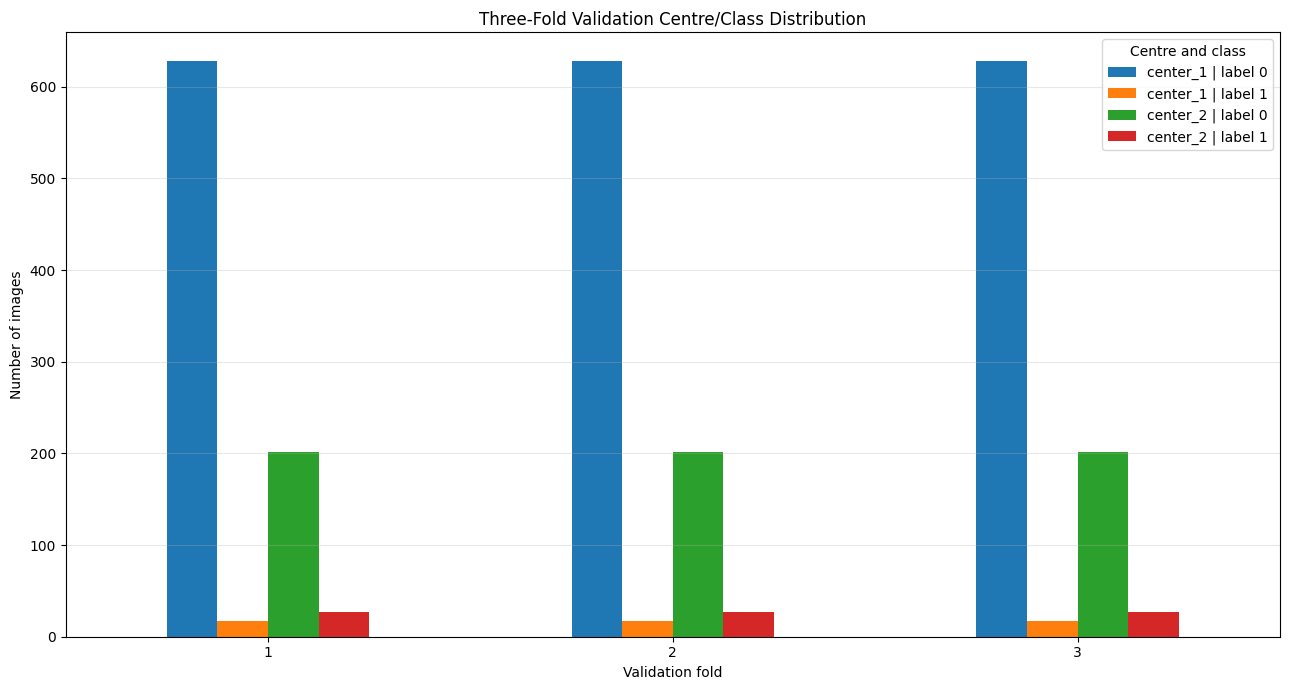


Fold-level summary:


,fold,train_total,train_normal,train_positive,validation_total,validation_normal,validation_positive,validation_center_1_normal,validation_center_1_positive,validation_center_2_normal,validation_center_2_positive,train_validation_overlap,all_train_files_exist,all_validation_files_exist,train_csv,validation_csv
0,1,1746,1658,88,874,830,44,628,17,202,27,0,True,True,/content/drive/MyDrive/RARE26_GastroNet_Weight...,/content/drive/MyDrive/RARE26_GastroNet_Weight...
1,2,1747,1659,88,873,829,44,628,17,201,27,0,True,True,/content/drive/MyDrive/RARE26_GastroNet_Weight...,/content/drive/MyDrive/RARE26_GastroNet_Weight...
2,3,1747,1659,88,873,829,44,628,17,201,27,0,True,True,/content/drive/MyDrive/RARE26_GastroNet_Weight...,/content/drive/MyDrive/RARE26_GastroNet_Weight...



Validation centre/class distribution:


,cv_validation_fold,center,label,case_count
0,1,center_1,0,628
1,1,center_1,1,17
2,1,center_2,0,202
3,1,center_2,1,27
4,2,center_1,0,628
5,2,center_1,1,17
6,2,center_2,0,201
7,2,center_2,1,27
8,3,center_1,0,628
9,3,center_1,1,17



Balance verification:


,center,label,minimum_fold_count,maximum_fold_count,maximum_difference,balanced_within_one_case
0,center_1,0,628,628,0,True
1,center_1,1,17,17,0,True
2,center_2,0,201,202,1,True
3,center_2,1,27,27,0,True



FINAL CELL 11A THREE-FOLD SPLIT REPORT
Development cases: 2620/2620
Normal cases: 2488/2488
Neoplasia cases: 132/132
Duplicate cases: 0
Missing runtime images: 0
Each case assigned to validation exactly once: True
Every fold train/validation overlap: 0
Centre/class balance difference across folds: maximum 1 case

Held-out test loaded: False
Held-out test used: False
Training performed: False
Model inference performed: False

STATUS: THREE_FOLD_DEVELOPMENT_SPLITS_VERIFIED

Saved records:
/content/drive/MyDrive/RARE26_GastroNet_Weights/configs/cross_validation/cell11a_3fold_assignment_manifest.csv
/content/drive/MyDrive/RARE26_GastroNet_Weights/results/cell11a_3fold_split_summary.csv
/content/drive/MyDrive/RARE26_GastroNet_Weights/results/cell11a_3fold_distribution.csv
/content/drive/MyDrive/RARE26_GastroNet_Weights/results/cell11a_3fold_balance_check.csv
/content/drive/MyDrive/RARE26_GastroNet_Weights/configs/cross_validation/cell11a_3fold_configuration.json
/content/drive/MyDrive/RARE

In [8]:
# ============================================================
# RARE26 GastroNet Extension — CELL 11A
# Generate and verify locked 3-fold development splits
#
# Uses:
#   Original train      = 2,159 images
#   Original validation =   461 images
#   Combined development pool = 2,620 images
#
# Does NOT load or use the 468-image held-out test set.
# Does NOT train or evaluate a model.
# ============================================================

from pathlib import Path
from datetime import datetime, timezone
import json
import platform

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import sklearn
from sklearn.model_selection import StratifiedKFold


# ------------------------------------------------------------
# 1. Project paths
# ------------------------------------------------------------
PROJECT_ROOT = Path(
    "/content/drive/MyDrive/RARE26_GastroNet_Weights"
)

RUNTIME_SPLIT_DIR = (
    PROJECT_ROOT
    / "configs"
    / "runtime_splits"
)

TRAIN_RUNTIME_CSV = (
    RUNTIME_SPLIT_DIR
    / "train_runtime_verified.csv"
)

VALIDATION_RUNTIME_CSV = (
    RUNTIME_SPLIT_DIR
    / "validation_runtime_verified.csv"
)

CV_ROOT = (
    PROJECT_ROOT
    / "configs"
    / "cross_validation"
)

RESULTS_DIR = (
    PROJECT_ROOT
    / "results"
)

FIGURES_DIR = (
    PROJECT_ROOT
    / "figures"
)

for directory in [
    CV_ROOT,
    RESULTS_DIR,
    FIGURES_DIR,
]:
    directory.mkdir(
        parents=True,
        exist_ok=True,
    )

required_files = [
    TRAIN_RUNTIME_CSV,
    VALIDATION_RUNTIME_CSV,
]

for required_file in required_files:
    if not required_file.exists():
        raise FileNotFoundError(
            f"Required runtime split file not found:\n"
            f"{required_file}\n\n"
            "Cell 3B must complete successfully first."
        )


print("=" * 82)
print("CELL 11A: GENERATE LOCKED 3-FOLD DEVELOPMENT SPLITS")
print("=" * 82)

print("\nDevelopment sources:")
print(TRAIN_RUNTIME_CSV)
print(VALIDATION_RUNTIME_CSV)

print("\nHeld-out test CSV loaded: False")
print("Held-out test used: False")
print("Model training performed: False")
print("Model inference performed: False")


# ------------------------------------------------------------
# 2. Cross-validation configuration
# ------------------------------------------------------------
NUMBER_OF_FOLDS = 3
CV_SEED = 42

MODEL_CHECKPOINT_NAME = (
    "RN50_GastroNet-5M_DINOv1.pth"
)

STRATIFICATION_METHOD = (
    "combined centre and binary label"
)


# ------------------------------------------------------------
# 3. Load original train and validation records
# ------------------------------------------------------------
original_train_df = pd.read_csv(
    TRAIN_RUNTIME_CSV,
    low_memory=False,
).copy()

original_validation_df = pd.read_csv(
    VALIDATION_RUNTIME_CSV,
    low_memory=False,
).copy()

original_train_df[
    "source_locked_split"
] = "original_train"

original_validation_df[
    "source_locked_split"
] = "original_validation"

development_df = pd.concat(
    [
        original_train_df,
        original_validation_df,
    ],
    ignore_index=True,
)

print("\nOriginal development records:")
print(
    f"Original train:      "
    f"{len(original_train_df)}"
)
print(
    f"Original validation: "
    f"{len(original_validation_df)}"
)
print(
    f"Combined pool:       "
    f"{len(development_df)}"
)

if len(original_train_df) != 2159:
    raise RuntimeError(
        "Original train must contain exactly 2,159 records."
    )

if len(original_validation_df) != 461:
    raise RuntimeError(
        "Original validation must contain exactly 461 records."
    )

if len(development_df) != 2620:
    raise RuntimeError(
        "Combined development pool must contain "
        "exactly 2,620 records."
    )


# ------------------------------------------------------------
# 4. Verify required columns
# ------------------------------------------------------------
required_columns = {
    "relative_path",
    "runtime_path",
    "label",
    "center",
    "class",
    "sha256",
}

missing_columns = (
    required_columns
    - set(development_df.columns)
)

if missing_columns:
    raise RuntimeError(
        "Development data is missing columns:\n"
        f"{sorted(missing_columns)}"
    )

development_df["label"] = (
    development_df["label"]
    .astype(int)
)

development_df["center"] = (
    development_df["center"]
    .astype(str)
    .str.strip()
    .str.lower()
    .str.replace(
        "centre",
        "center",
        regex=False,
    )
    .str.replace(
        "-",
        "_",
        regex=False,
    )
    .str.replace(
        " ",
        "_",
        regex=False,
    )
)

development_df["relative_path"] = (
    development_df["relative_path"]
    .astype(str)
    .str.replace(
        "\\",
        "/",
        regex=False,
    )
    .str.lstrip("./")
)

development_df["sha256"] = (
    development_df["sha256"]
    .astype(str)
    .str.strip()
    .str.lower()
)


# ------------------------------------------------------------
# 5. Verify development distribution
# ------------------------------------------------------------
expected_counts = {
    "total": 2620,
    "normal": 2488,
    "positive": 132,
    "center_1_normal": 1884,
    "center_1_positive": 51,
    "center_2_normal": 604,
    "center_2_positive": 81,
}

actual_counts = {
    "total": len(development_df),

    "normal": int(
        (
            development_df["label"]
            == 0
        ).sum()
    ),

    "positive": int(
        (
            development_df["label"]
            == 1
        ).sum()
    ),

    "center_1_normal": int(
        (
            (
                development_df["center"]
                == "center_1"
            )
            &
            (
                development_df["label"]
                == 0
            )
        ).sum()
    ),

    "center_1_positive": int(
        (
            (
                development_df["center"]
                == "center_1"
            )
            &
            (
                development_df["label"]
                == 1
            )
        ).sum()
    ),

    "center_2_normal": int(
        (
            (
                development_df["center"]
                == "center_2"
            )
            &
            (
                development_df["label"]
                == 0
            )
        ).sum()
    ),

    "center_2_positive": int(
        (
            (
                development_df["center"]
                == "center_2"
            )
            &
            (
                development_df["label"]
                == 1
            )
        ).sum()
    ),
}

print("\nCombined development distribution:")

for key, value in actual_counts.items():
    print(f"{key}: {value}")

if actual_counts != expected_counts:
    raise RuntimeError(
        "Development distribution does not match "
        "the locked project record.\n\n"
        f"Expected:\n{expected_counts}\n\n"
        f"Actual:\n{actual_counts}"
    )


# ------------------------------------------------------------
# 6. Verify all runtime images still exist
# ------------------------------------------------------------
development_df[
    "runtime_file_exists_now"
] = (
    development_df["runtime_path"]
    .apply(
        lambda path_value: (
            Path(str(path_value)).exists()
            and Path(str(path_value)).is_file()
        )
    )
)

missing_runtime_count = int(
    (
        ~development_df[
            "runtime_file_exists_now"
        ]
    ).sum()
)

print(
    f"\nMissing development runtime images: "
    f"{missing_runtime_count}"
)

if missing_runtime_count > 0:
    raise FileNotFoundError(
        f"{missing_runtime_count} development images "
        "are missing from temporary Colab storage.\n"
        "Run Cell 3B again."
    )


# ------------------------------------------------------------
# 7. Create immutable case IDs
# ------------------------------------------------------------
complete_sha_available = bool(
    development_df[
        "sha256"
    ].notna().all()
    and development_df[
        "sha256"
    ].str.strip().ne("").all()
)

if complete_sha_available:
    development_df[
        "cv_case_id"
    ] = development_df[
        "sha256"
    ]

    CASE_ID_SOURCE = "sha256"

else:
    development_df[
        "cv_case_id"
    ] = (
        development_df[
            "relative_path"
        ]
        .str.strip()
        .str.lower()
    )

    CASE_ID_SOURCE = "relative_path"

duplicate_case_df = development_df[
    development_df[
        "cv_case_id"
    ].duplicated(
        keep=False
    )
].copy()

print(
    f"Case identity source: "
    f"{CASE_ID_SOURCE}"
)

print(
    f"Duplicate development cases: "
    f"{len(duplicate_case_df)}"
)

if len(duplicate_case_df) > 0:
    duplicate_case_path = (
        CV_ROOT
        / "cell11a_duplicate_cases.csv"
    )

    duplicate_case_df.to_csv(
        duplicate_case_path,
        index=False,
    )

    raise RuntimeError(
        "Duplicate cases were found in the "
        "development pool.\n"
        f"Review:\n{duplicate_case_path}"
    )


# ------------------------------------------------------------
# 8. Create centre + class stratification key
# ------------------------------------------------------------
development_df[
    "cv_stratum"
] = (
    development_df["center"]
    + "__label_"
    + development_df[
        "label"
    ].astype(str)
)

stratum_counts = (
    development_df[
        "cv_stratum"
    ]
    .value_counts()
    .sort_index()
)

print("\nJoint centre/class strata:")

for stratum_name, count in (
    stratum_counts.items()
):
    print(
        f"{stratum_name}: {count}"
    )

if int(stratum_counts.min()) < NUMBER_OF_FOLDS:
    raise RuntimeError(
        "At least one centre/class stratum contains "
        "fewer records than the number of folds."
    )


# ------------------------------------------------------------
# 9. Generate deterministic 3-fold assignments
# ------------------------------------------------------------
splitter = StratifiedKFold(
    n_splits=NUMBER_OF_FOLDS,
    shuffle=True,
    random_state=CV_SEED,
)

stratification_labels = (
    development_df[
        "cv_stratum"
    ].to_numpy()
)

fold_assignments = np.full(
    len(development_df),
    fill_value=-1,
    dtype=int,
)

fold_summary_rows = []
fold_distribution_rows = []

for fold_number, (
    train_indices,
    validation_indices,
) in enumerate(
    splitter.split(
        np.zeros(
            len(development_df)
        ),
        stratification_labels,
    ),
    start=1,
):

    fold_assignments[
        validation_indices
    ] = fold_number

    fold_train_df = (
        development_df.iloc[
            train_indices
        ]
        .copy()
        .reset_index(drop=True)
    )

    fold_validation_df = (
        development_df.iloc[
            validation_indices
        ]
        .copy()
        .reset_index(drop=True)
    )

    fold_train_df[
        "cv_fold"
    ] = fold_number

    fold_train_df[
        "cv_role"
    ] = "train"

    fold_validation_df[
        "cv_fold"
    ] = fold_number

    fold_validation_df[
        "cv_role"
    ] = "validation"

    # --------------------------------------------------------
    # Verify no overlap
    # --------------------------------------------------------
    train_case_ids = set(
        fold_train_df[
            "cv_case_id"
        ]
    )

    validation_case_ids = set(
        fold_validation_df[
            "cv_case_id"
        ]
    )

    overlap_case_ids = (
        train_case_ids
        & validation_case_ids
    )

    if len(overlap_case_ids) > 0:
        raise RuntimeError(
            f"Fold {fold_number} contains "
            f"{len(overlap_case_ids)} overlapping cases."
        )

    if (
        len(fold_train_df)
        + len(fold_validation_df)
        != 2620
    ):
        raise RuntimeError(
            f"Fold {fold_number} does not cover "
            "all 2,620 development records."
        )

    # --------------------------------------------------------
    # Save fold CSVs
    # --------------------------------------------------------
    fold_directory = (
        CV_ROOT
        / f"fold_{fold_number}"
    )

    fold_directory.mkdir(
        parents=True,
        exist_ok=True,
    )

    fold_train_path = (
        fold_directory
        / f"fold_{fold_number}_train_runtime.csv"
    )

    fold_validation_path = (
        fold_directory
        / f"fold_{fold_number}_validation_runtime.csv"
    )

    fold_train_df.to_csv(
        fold_train_path,
        index=False,
    )

    fold_validation_df.to_csv(
        fold_validation_path,
        index=False,
    )

    # --------------------------------------------------------
    # Fold summary
    # --------------------------------------------------------
    fold_summary_rows.append(
        {
            "fold": fold_number,

            "train_total": len(
                fold_train_df
            ),

            "train_normal": int(
                (
                    fold_train_df[
                        "label"
                    ] == 0
                ).sum()
            ),

            "train_positive": int(
                (
                    fold_train_df[
                        "label"
                    ] == 1
                ).sum()
            ),

            "validation_total": len(
                fold_validation_df
            ),

            "validation_normal": int(
                (
                    fold_validation_df[
                        "label"
                    ] == 0
                ).sum()
            ),

            "validation_positive": int(
                (
                    fold_validation_df[
                        "label"
                    ] == 1
                ).sum()
            ),

            "validation_center_1_normal": int(
                (
                    (
                        fold_validation_df[
                            "center"
                        ]
                        == "center_1"
                    )
                    &
                    (
                        fold_validation_df[
                            "label"
                        ]
                        == 0
                    )
                ).sum()
            ),

            "validation_center_1_positive": int(
                (
                    (
                        fold_validation_df[
                            "center"
                        ]
                        == "center_1"
                    )
                    &
                    (
                        fold_validation_df[
                            "label"
                        ]
                        == 1
                    )
                ).sum()
            ),

            "validation_center_2_normal": int(
                (
                    (
                        fold_validation_df[
                            "center"
                        ]
                        == "center_2"
                    )
                    &
                    (
                        fold_validation_df[
                            "label"
                        ]
                        == 0
                    )
                ).sum()
            ),

            "validation_center_2_positive": int(
                (
                    (
                        fold_validation_df[
                            "center"
                        ]
                        == "center_2"
                    )
                    &
                    (
                        fold_validation_df[
                            "label"
                        ]
                        == 1
                    )
                ).sum()
            ),

            "train_validation_overlap": int(
                len(overlap_case_ids)
            ),

            "all_train_files_exist": bool(
                fold_train_df[
                    "runtime_file_exists_now"
                ].all()
            ),

            "all_validation_files_exist": bool(
                fold_validation_df[
                    "runtime_file_exists_now"
                ].all()
            ),

            "train_csv": str(
                fold_train_path
            ),

            "validation_csv": str(
                fold_validation_path
            ),
        }
    )

    # --------------------------------------------------------
    # Detailed centre/class distributions
    # --------------------------------------------------------
    for role_name, role_df in [
        (
            "train",
            fold_train_df,
        ),
        (
            "validation",
            fold_validation_df,
        ),
    ]:

        role_distribution_df = (
            role_df.groupby(
                [
                    "center",
                    "label",
                ]
            )
            .size()
            .reset_index(
                name="case_count"
            )
        )

        for _, distribution_row in (
            role_distribution_df.iterrows()
        ):

            fold_distribution_rows.append(
                {
                    "fold": fold_number,
                    "role": role_name,
                    "center": (
                        distribution_row[
                            "center"
                        ]
                    ),
                    "label": int(
                        distribution_row[
                            "label"
                        ]
                    ),
                    "case_count": int(
                        distribution_row[
                            "case_count"
                        ]
                    ),
                }
            )


# ------------------------------------------------------------
# 10. Save fold assignment in master manifest
# ------------------------------------------------------------
development_df[
    "cv_validation_fold"
] = fold_assignments

if (
    development_df[
        "cv_validation_fold"
    ] < 1
).any():
    raise RuntimeError(
        "At least one development case was not "
        "assigned to a validation fold."
    )

assignment_counts = (
    development_df[
        "cv_validation_fold"
    ]
    .value_counts()
    .sort_index()
)

print("\nValidation assignment counts:")
print(assignment_counts)

if int(assignment_counts.sum()) != 2620:
    raise RuntimeError(
        "Validation fold assignments do not "
        "cover all development records."
    )


# ------------------------------------------------------------
# 11. Verify centre/class balance across folds
# ------------------------------------------------------------
validation_distribution_df = (
    development_df.groupby(
        [
            "cv_validation_fold",
            "center",
            "label",
        ]
    )
    .size()
    .reset_index(
        name="case_count"
    )
)

balance_rows = []

for (
    center_name,
    label_value,
), group_df in (
    validation_distribution_df.groupby(
        [
            "center",
            "label",
        ]
    )
):

    minimum_count = int(
        group_df[
            "case_count"
        ].min()
    )

    maximum_count = int(
        group_df[
            "case_count"
        ].max()
    )

    maximum_difference = (
        maximum_count
        - minimum_count
    )

    balance_rows.append(
        {
            "center": center_name,
            "label": int(label_value),
            "minimum_fold_count": minimum_count,
            "maximum_fold_count": maximum_count,
            "maximum_difference": maximum_difference,
            "balanced_within_one_case": bool(
                maximum_difference <= 1
            ),
        }
    )

balance_df = pd.DataFrame(
    balance_rows
)

if not balance_df[
    "balanced_within_one_case"
].all():
    raise RuntimeError(
        "At least one centre/class stratum differs "
        "by more than one case across folds."
    )


# ------------------------------------------------------------
# 12. Save manifests and summaries
# ------------------------------------------------------------
MASTER_MANIFEST_PATH = (
    CV_ROOT
    / "cell11a_3fold_assignment_manifest.csv"
)

FOLD_SUMMARY_PATH = (
    RESULTS_DIR
    / "cell11a_3fold_split_summary.csv"
)

FOLD_DISTRIBUTION_PATH = (
    RESULTS_DIR
    / "cell11a_3fold_distribution.csv"
)

BALANCE_PATH = (
    RESULTS_DIR
    / "cell11a_3fold_balance_check.csv"
)

CONFIG_PATH = (
    CV_ROOT
    / "cell11a_3fold_configuration.json"
)

STATUS_PATH = (
    RESULTS_DIR
    / "cell11a_3fold_split_status.json"
)

SUMMARY_TEXT_PATH = (
    RESULTS_DIR
    / "cell11a_3fold_split_summary.txt"
)

development_df.to_csv(
    MASTER_MANIFEST_PATH,
    index=False,
)

fold_summary_df = pd.DataFrame(
    fold_summary_rows
)

fold_distribution_df = pd.DataFrame(
    fold_distribution_rows
)

fold_summary_df.to_csv(
    FOLD_SUMMARY_PATH,
    index=False,
)

fold_distribution_df.to_csv(
    FOLD_DISTRIBUTION_PATH,
    index=False,
)

balance_df.to_csv(
    BALANCE_PATH,
    index=False,
)


# ------------------------------------------------------------
# 13. Save configuration
# ------------------------------------------------------------
configuration_record = {
    "created_utc": datetime.now(
        timezone.utc
    ).isoformat(),

    "number_of_folds": NUMBER_OF_FOLDS,
    "random_seed": CV_SEED,

    "splitter": (
        "StratifiedKFold"
    ),

    "shuffle": True,

    "stratification_method": (
        STRATIFICATION_METHOD
    ),

    "case_identity_source": (
        CASE_ID_SOURCE
    ),

    "development_record_count": int(
        len(development_df)
    ),

    "normal_count": int(
        actual_counts["normal"]
    ),

    "positive_count": int(
        actual_counts["positive"]
    ),

    "planned_model_checkpoint": (
        MODEL_CHECKPOINT_NAME
    ),

    "planned_training_protocol": (
        "Same locked two-stage training protocol "
        "used for GastroNet Experiment 01"
    ),

    "held_out_test_csv_loaded": False,
    "held_out_test_used": False,

    "patient_or_procedure_group_id_available": False,

    "grouping_limitation": (
        "No patient or procedure identifier is "
        "available in the current metadata. "
        "Folds are created at deduplicated image level."
    ),

    "python_version": (
        platform.python_version()
    ),

    "sklearn_version": (
        sklearn.__version__
    ),
}

CONFIG_PATH.write_text(
    json.dumps(
        configuration_record,
        indent=2,
        ensure_ascii=False,
    ),
    encoding="utf-8",
)


# ------------------------------------------------------------
# 14. Create validation distribution figure
# ------------------------------------------------------------
figure_data = (
    validation_distribution_df.copy()
)

figure_data[
    "stratum"
] = (
    figure_data["center"]
    + " | label "
    + figure_data[
        "label"
    ].astype(str)
)

figure_pivot = (
    figure_data.pivot(
        index="cv_validation_fold",
        columns="stratum",
        values="case_count",
    )
    .fillna(0)
)

FIGURE_PATH = (
    FIGURES_DIR
    / "cell11a_3fold_validation_distribution.png"
)

axis = figure_pivot.plot(
    kind="bar",
    figsize=(13, 7),
)

axis.set_title(
    "Three-Fold Validation Centre/Class Distribution"
)

axis.set_xlabel(
    "Validation fold"
)

axis.set_ylabel(
    "Number of images"
)

axis.grid(
    axis="y",
    alpha=0.3,
)

axis.legend(
    title="Centre and class"
)

plt.xticks(
    rotation=0
)

plt.tight_layout()

plt.savefig(
    FIGURE_PATH,
    dpi=200,
    bbox_inches="tight",
)

plt.show()
plt.close()


# ------------------------------------------------------------
# 15. Final verification
# ------------------------------------------------------------
all_checks_passed = bool(
    len(development_df) == 2620
    and len(duplicate_case_df) == 0
    and missing_runtime_count == 0
    and set(
        development_df[
            "cv_validation_fold"
        ].unique()
    ) == {1, 2, 3}
    and balance_df[
        "balanced_within_one_case"
    ].all()
    and fold_summary_df[
        "all_train_files_exist"
    ].all()
    and fold_summary_df[
        "all_validation_files_exist"
    ].all()
    and int(
        fold_summary_df[
            "train_validation_overlap"
        ].sum()
    ) == 0
)

FINAL_STATUS = (
    "THREE_FOLD_DEVELOPMENT_SPLITS_VERIFIED"
    if all_checks_passed
    else
    "THREE_FOLD_SPLITS_NEED_REVIEW"
)

status_record = {
    "created_utc": datetime.now(
        timezone.utc
    ).isoformat(),

    "status": FINAL_STATUS,

    "development_pool_count": int(
        len(development_df)
    ),

    "fold_count": NUMBER_OF_FOLDS,

    "duplicate_case_count": int(
        len(duplicate_case_df)
    ),

    "missing_runtime_image_count": int(
        missing_runtime_count
    ),

    "all_cases_assigned_once_to_validation": bool(
        development_df[
            "cv_validation_fold"
        ].between(
            1,
            NUMBER_OF_FOLDS,
        ).all()
    ),

    "all_strata_balanced_within_one_case": bool(
        balance_df[
            "balanced_within_one_case"
        ].all()
    ),

    "held_out_test_loaded": False,
    "held_out_test_used": False,

    "training_performed": False,
    "model_inference_performed": False,

    "model_for_future_fold_training": (
        MODEL_CHECKPOINT_NAME
    ),
}

STATUS_PATH.write_text(
    json.dumps(
        status_record,
        indent=2,
        ensure_ascii=False,
    ),
    encoding="utf-8",
)


# ------------------------------------------------------------
# 16. Save readable summary
# ------------------------------------------------------------
summary_lines = [
    "RARE26 GastroNet Three-Fold Split Summary",
    "=" * 66,
    "",
    (
        "Model planned for all folds: "
        f"{MODEL_CHECKPOINT_NAME}"
    ),
    "",
    (
        f"Development pool: "
        f"{len(development_df)}"
    ),
    (
        f"Normal images: "
        f"{actual_counts['normal']}"
    ),
    (
        f"Neoplasia images: "
        f"{actual_counts['positive']}"
    ),
    (
        f"Number of folds: "
        f"{NUMBER_OF_FOLDS}"
    ),
    (
        f"Random seed: "
        f"{CV_SEED}"
    ),
    (
        f"Case identity source: "
        f"{CASE_ID_SOURCE}"
    ),
    "",
    (
        "Stratification: centre plus label"
    ),
    (
        "Held-out test loaded: No"
    ),
    (
        "Held-out test used: No"
    ),
    (
        "Training performed: No"
    ),
    (
        "Model inference performed: No"
    ),
    "",
    (
        "Limitation: no patient or procedure ID "
        "is available, so folds are created at "
        "deduplicated image level."
    ),
    "",
    f"Status: {FINAL_STATUS}",
]

SUMMARY_TEXT_PATH.write_text(
    "\n".join(summary_lines),
    encoding="utf-8",
)


# ------------------------------------------------------------
# 17. Final report
# ------------------------------------------------------------
print("\nFold-level summary:")
display(fold_summary_df)

print("\nValidation centre/class distribution:")
display(validation_distribution_df)

print("\nBalance verification:")
display(balance_df)

print("\n" + "=" * 82)
print("FINAL CELL 11A THREE-FOLD SPLIT REPORT")
print("=" * 82)

print(
    f"Development cases: "
    f"{len(development_df)}/2620"
)

print(
    f"Normal cases: "
    f"{actual_counts['normal']}/2488"
)

print(
    f"Neoplasia cases: "
    f"{actual_counts['positive']}/132"
)

print(
    f"Duplicate cases: "
    f"{len(duplicate_case_df)}"
)

print(
    f"Missing runtime images: "
    f"{missing_runtime_count}"
)

print(
    "Each case assigned to validation exactly once: True"
)

print(
    "Every fold train/validation overlap: 0"
)

print(
    "Centre/class balance difference across folds: "
    "maximum 1 case"
)

print("\nHeld-out test loaded: False")
print("Held-out test used: False")
print("Training performed: False")
print("Model inference performed: False")

print(
    f"\nSTATUS: {FINAL_STATUS}"
)

print("\nSaved records:")
print(MASTER_MANIFEST_PATH)
print(FOLD_SUMMARY_PATH)
print(FOLD_DISTRIBUTION_PATH)
print(BALANCE_PATH)
print(CONFIG_PATH)
print(STATUS_PATH)
print(SUMMARY_TEXT_PATH)
print(FIGURE_PATH)

print("\nFold files saved under:")
print(CV_ROOT)

CELL 11B: FOLD 1 TRAINING AND VALIDATION THRESHOLD LOCK

Fold files:
/content/drive/MyDrive/RARE26_GastroNet_Weights/configs/cross_validation/fold_1/fold_1_train_runtime.csv
/content/drive/MyDrive/RARE26_GastroNet_Weights/configs/cross_validation/fold_1/fold_1_validation_runtime.csv

Held-out test CSV loaded: False
Held-out test evaluated: False

Compute device:
cuda
Tesla T4

Pretrained source checkpoint:
/content/drive/MyDrive/RARE26_GastroNet_Weights/source_checkpoints/RN50_GastroNet-5M_DINOv1.pth
Checkpoint size: 89.979 MB

Fold 1 data verified:
Train:      1746 (normal=1658, NEO=88)
Validation: 874 (normal=830, NEO=44)
Train/validation overlap: 0

Data loaders:
Train batches: 55
Validation batches: 28

Pretrained backbone loaded:
Missing parameters: ['fc.weight', 'fc.bias']
Unexpected parameters: []
New classification head: Linear(2048, 1)

Locked Fold 1 protocol:
Positive weight: 18.840909
Stage 1: head only, 3 epochs
Stage 2: layer4 + head, maximum 7 epochs
Checkpoint selection:

Training:   0%|          | 0/55 [00:00<?, ?it/s]

Validation:   0%|          | 0/28 [00:00<?, ?it/s]

Stage 1 | Epoch 1/3 | Train loss 1.086444 | Val loss 1.074929 | AUPRC 0.604382 | AUROC 0.921112


Training:   0%|          | 0/55 [00:00<?, ?it/s]

...

Stage 2 | Epoch 6/7 | Global 9 | Train loss 0.158729 | Val loss 1.018295 | AUPRC 0.881084 | AUROC 0.982900


Training:   0%|          | 0/55 [00:00<?, ?it/s]

Validation:   0%|          | 0/28 [00:00<?, ?it/s]

Stage 2 | Epoch 7/7 | Global 10 | Train loss 0.110795 | Val loss 1.036591 | AUPRC 0.887400 | AUROC 0.984132

Best Fold 1 checkpoint:
Stage: stage_2
Stage epoch: 7
Global epoch: 10
Validation AUPRC: 0.887400
Validation AUROC: 0.984132


Validation:   0%|          | 0/28 [00:00<?, ?it/s]

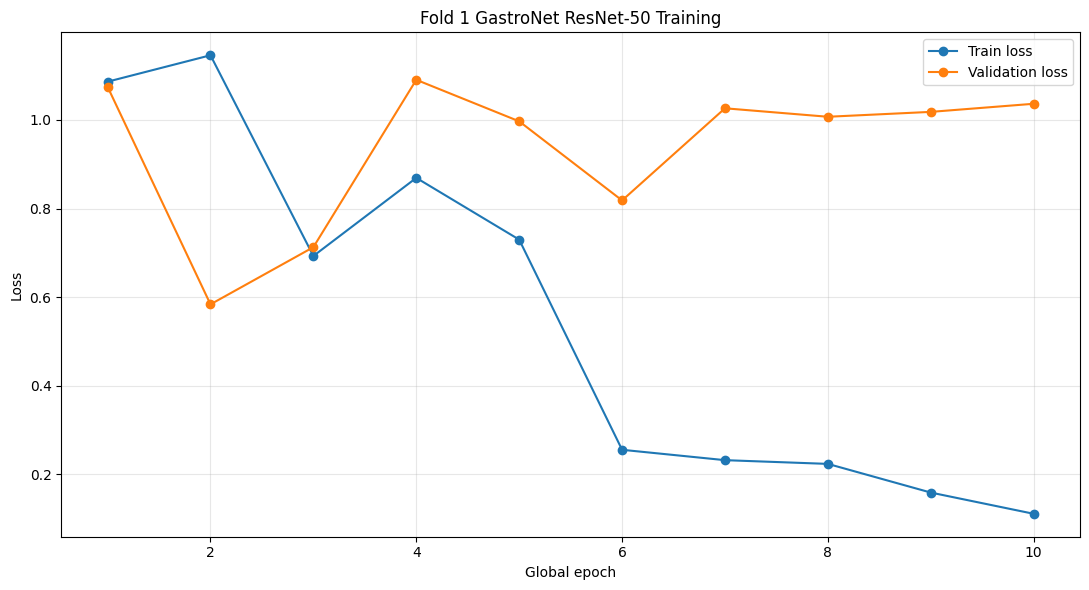

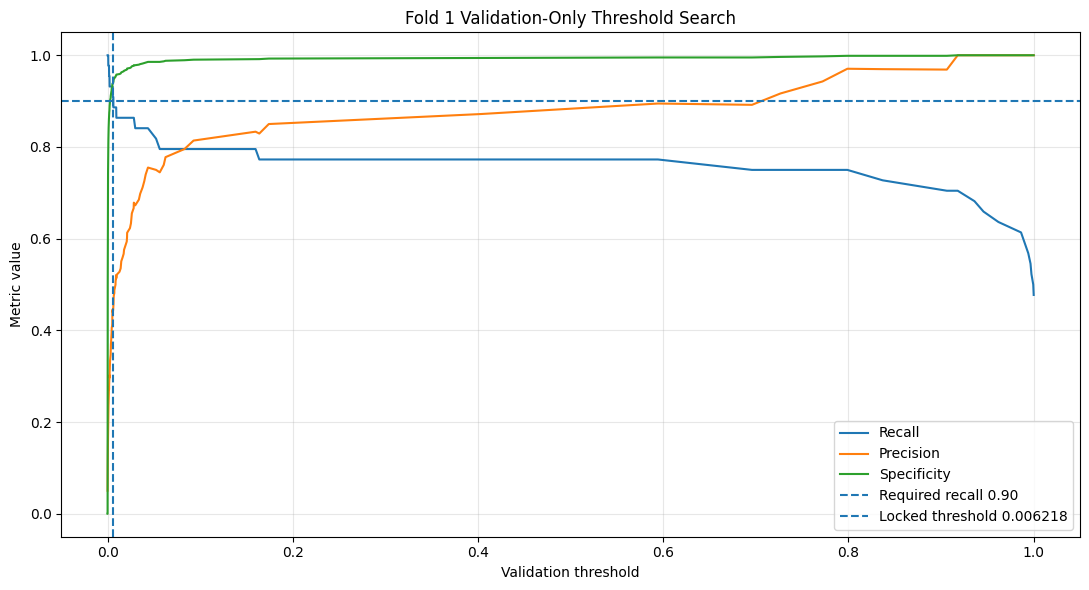


Fold 1 training history:


,fold,stage,stage_epoch,global_epoch,train_loss,validation_loss,validation_auprc,validation_auroc,default_recall,default_precision,default_specificity,learning_rate_backbone,learning_rate_head
0,1,stage_1,1,1,1.086444,1.074929,0.604382,0.921112,0.477273,0.567568,0.980723,0.000000e+00,0.001000
1,1,stage_1,2,2,1.146127,0.583726,0.703781,0.941594,0.863636,0.304000,0.895181,0.000000e+00,0.000750
2,1,stage_1,3,3,0.692895,0.712829,0.715686,0.938582,0.772727,0.539683,0.965060,0.000000e+00,0.000250
3,1,stage_2,1,4,0.869277,1.090698,0.794305,0.955216,0.636364,0.875000,0.995181,1.000000e-05,0.000100
4,1,stage_2,2,5,0.729837,0.996945,0.845969,0.967004,0.681818,0.937500,0.997590,9.504844e-06,0.000095
5,1,stage_2,3,6,0.255316,0.818355,0.880164,0.983311,0.772727,0.871795,0.993976,8.117449e-06,0.000081
6,1,stage_2,4,7,0.231894,1.026386,0.883753,0.983146,0.750000,0.916667,0.996386,6.112605e-06,0.000061
7,1,stage_2,5,8,0.223467,1.007249,0.881406,0.981941,0.772727,0.894737,0.995181,3.887395e-06,0.000039
8,1,stage_2,6,9,0.158729,1.018295,0.881084,0.982900,0.772727,0.894737,0.995181,1.882551e-06,0.000019
9,1,stage_2,7,10,0.110795,1.036591,0.887400,0.984132,0.772727,0.894737,0.995181,4.951557e-07,0.000005



Fold 1 locked validation metrics:


,experiment_id,fold,best_stage,best_stage_epoch,best_global_epoch,selection_mode,threshold,recall,precision,specificity,...,accuracy,f1,tp,tn,fp,fn,auprc,auroc,held_out_test_loaded,held_out_test_evaluated
0,cv_fold_1_rn50_gastronet5m_dinov1,1,stage_2,7,10,overall_recall_0.90_and_minimum_centre_recall_...,0.006218,0.909091,0.454545,0.942169,...,0.940503,0.606061,40,782,48,4,0.8874,0.984132,False,False



Fold 1 per-centre metrics:


,experiment_id,fold,center,sample_count,normal_count,positive_count,threshold,recall,precision,specificity,npv,accuracy,f1,tp,tn,fp,fn,auprc,auroc
0,cv_fold_1_rn50_gastronet5m_dinov1,1,center_1,645,628,17,0.006218,0.882353,0.340909,0.953822,0.996672,0.951938,0.491803,15,599,29,2,0.797898,0.987636
1,cv_fold_1_rn50_gastronet5m_dinov1,1,center_2,229,202,27,0.006218,0.925926,0.568182,0.905941,0.989189,0.908297,0.704225,25,183,19,2,0.928638,0.971580



FINAL CELL 11B FOLD 1 REPORT
Best stage: stage_2
Best global epoch: 10
Validation AUPRC: 0.887400
Validation AUROC: 0.984132
Locked threshold: 0.006217956543
Validation recall: 0.909091
Validation PPV: 0.454545
Validation specificity: 0.942169
TP: 40
FP: 48
FN: 4
TN: 782

Held-out test loaded: False
Held-out test evaluated: False
Held-out test used for model selection: False
Held-out test used for threshold selection: False

STATUS: FOLD_1_TRAINING_AND_THRESHOLD_LOCK_COMPLETE

Saved records:
/content/drive/MyDrive/RARE26_GastroNet_Weights/models/cross_validation/fold_1/cv_fold_1_rn50_gastronet5m_dinov1_best.pth
/content/drive/MyDrive/RARE26_GastroNet_Weights/logs/cross_validation/fold_1/cv_fold_1_rn50_gastronet5m_dinov1_training_history.csv
/content/drive/MyDrive/RARE26_GastroNet_Weights/predictions/cross_validation/fold_1/cv_fold_1_rn50_gastronet5m_dinov1_validation_predictions.csv
/content/drive/MyDrive/RARE26_GastroNet_Weights/predictions/cross_validation/fold_1/cv_fold_1_rn50_gast

In [9]:
# ============================================================
# RARE26 GastroNet Extension — CELL 11B
# Three-fold validation: FOLD 1
#
# Model:
#   RN50_GastroNet-5M_DINOv1.pth
#
# Protocol:
#   Stage 1: classification head only, 3 epochs
#   Stage 2: layer4 + head, maximum 7 epochs
#   Best checkpoint selected by Fold-1 validation AUPRC
#   Threshold selected from Fold-1 validation predictions only
#
# Held-out 468-image test set is NOT loaded or evaluated.
# ============================================================

from pathlib import Path
from datetime import datetime, timezone
import gc
import hashlib
import json
import os
import random
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image
from tqdm.auto import tqdm

import torch
import torch.nn as nn

from torch.utils.data import (
    Dataset,
    DataLoader,
)

from torchvision import (
    models,
    transforms,
)

from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
)


# ============================================================
# 1. CONFIGURATION
# ============================================================

FOLD_NUMBER = 1
SEED = 42

PROJECT_ROOT = Path(
    "/content/drive/MyDrive/RARE26_GastroNet_Weights"
)

CV_CONFIG_ROOT = (
    PROJECT_ROOT
    / "configs"
    / "cross_validation"
)

FOLD_SPLIT_ROOT = (
    CV_CONFIG_ROOT
    / f"fold_{FOLD_NUMBER}"
)

FOLD_TRAIN_CSV = (
    FOLD_SPLIT_ROOT
    / f"fold_{FOLD_NUMBER}_train_runtime.csv"
)

FOLD_VALIDATION_CSV = (
    FOLD_SPLIT_ROOT
    / f"fold_{FOLD_NUMBER}_validation_runtime.csv"
)

SOURCE_CHECKPOINT_FILENAME = (
    "RN50_GastroNet-5M_DINOv1.pth"
)

EXPERIMENT_ID = (
    f"cv_fold_{FOLD_NUMBER}_rn50_gastronet5m_dinov1"
)

MODEL_DIR = (
    PROJECT_ROOT
    / "models"
    / "cross_validation"
    / f"fold_{FOLD_NUMBER}"
)

LOG_DIR = (
    PROJECT_ROOT
    / "logs"
    / "cross_validation"
    / f"fold_{FOLD_NUMBER}"
)

PREDICTION_DIR = (
    PROJECT_ROOT
    / "predictions"
    / "cross_validation"
    / f"fold_{FOLD_NUMBER}"
)

RESULT_DIR = (
    PROJECT_ROOT
    / "results"
    / "cross_validation"
    / f"fold_{FOLD_NUMBER}"
)

THRESHOLD_DIR = (
    PROJECT_ROOT
    / "thresholds"
    / "cross_validation"
    / f"fold_{FOLD_NUMBER}"
)

CENTRE_DIR = (
    PROJECT_ROOT
    / "centre_analysis"
    / "cross_validation"
    / f"fold_{FOLD_NUMBER}"
)

FIGURE_DIR = (
    PROJECT_ROOT
    / "figures"
    / "cross_validation"
    / f"fold_{FOLD_NUMBER}"
)

for directory in [
    MODEL_DIR,
    LOG_DIR,
    PREDICTION_DIR,
    RESULT_DIR,
    THRESHOLD_DIR,
    CENTRE_DIR,
    FIGURE_DIR,
]:
    directory.mkdir(
        parents=True,
        exist_ok=True,
    )

BEST_CHECKPOINT_PATH = (
    MODEL_DIR
    / f"{EXPERIMENT_ID}_best.pth"
)

LATEST_CHECKPOINT_PATH = (
    MODEL_DIR
    / f"{EXPERIMENT_ID}_latest.pth"
)

TRAINING_HISTORY_PATH = (
    LOG_DIR
    / f"{EXPERIMENT_ID}_training_history.csv"
)

VALIDATION_PREDICTIONS_PATH = (
    PREDICTION_DIR
    / f"{EXPERIMENT_ID}_validation_predictions.csv"
)

LOCKED_VALIDATION_PREDICTIONS_PATH = (
    PREDICTION_DIR
    / f"{EXPERIMENT_ID}_validation_predictions_locked_threshold.csv"
)

VALIDATION_METRICS_PATH = (
    RESULT_DIR
    / f"{EXPERIMENT_ID}_validation_metrics.csv"
)

THRESHOLD_SEARCH_PATH = (
    THRESHOLD_DIR
    / f"{EXPERIMENT_ID}_validation_threshold_search.csv"
)

THRESHOLD_OPERATING_POINT_PATH = (
    THRESHOLD_DIR
    / f"{EXPERIMENT_ID}_validation_operating_point.csv"
)

THRESHOLD_LOCK_PATH = (
    THRESHOLD_DIR
    / f"{EXPERIMENT_ID}_threshold_lock.json"
)

CENTRE_METRICS_PATH = (
    CENTRE_DIR
    / f"{EXPERIMENT_ID}_validation_per_centre_metrics.csv"
)

TRAINING_FIGURE_PATH = (
    FIGURE_DIR
    / f"{EXPERIMENT_ID}_training_curves.png"
)

THRESHOLD_FIGURE_PATH = (
    FIGURE_DIR
    / f"{EXPERIMENT_ID}_threshold_analysis.png"
)

CONFIG_OUTPUT_PATH = (
    RESULT_DIR
    / f"{EXPERIMENT_ID}_configuration.json"
)

STATUS_PATH = (
    RESULT_DIR
    / f"{EXPERIMENT_ID}_status.json"
)

SUMMARY_PATH = (
    RESULT_DIR
    / f"{EXPERIMENT_ID}_summary.txt"
)


# ============================================================
# 2. PREVENT ACCIDENTAL REPEAT
# ============================================================

if STATUS_PATH.exists():
    try:
        existing_status = json.loads(
            STATUS_PATH.read_text(
                encoding="utf-8"
            )
        )

        if existing_status.get("status") == (
            "FOLD_1_TRAINING_AND_THRESHOLD_LOCK_COMPLETE"
        ):
            raise FileExistsError(
                "Fold 1 training is already complete.\n"
                f"Status file:\n{STATUS_PATH}"
            )

    except json.JSONDecodeError:
        pass


# ============================================================
# 3. VERIFY REQUIRED FOLD FILES
# ============================================================

print("=" * 82)
print("CELL 11B: FOLD 1 TRAINING AND VALIDATION THRESHOLD LOCK")
print("=" * 82)

required_files = [
    FOLD_TRAIN_CSV,
    FOLD_VALIDATION_CSV,
]

for required_file in required_files:
    if not required_file.exists():
        raise FileNotFoundError(
            f"Required Fold 1 file not found:\n"
            f"{required_file}\n\n"
            "Cell 11A must complete first."
        )

print("\nFold files:")
print(FOLD_TRAIN_CSV)
print(FOLD_VALIDATION_CSV)

print("\nHeld-out test CSV loaded: False")
print("Held-out test evaluated: False")


# ============================================================
# 4. REPRODUCIBILITY
# ============================================================

def set_all_seeds(seed):
    random.seed(seed)
    np.random.seed(seed)

    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


set_all_seeds(SEED)

if not torch.cuda.is_available():
    raise RuntimeError(
        "GPU runtime is required for Fold 1 training.\n"
        "In Colab select Runtime → Change runtime type → T4 GPU."
    )

device = torch.device("cuda")

torch.set_float32_matmul_precision(
    "high"
)

print("\nCompute device:")
print(device)
print(torch.cuda.get_device_name(0))


# ============================================================
# 5. LOCATE THE ORIGINAL PRETRAINED CHECKPOINT
# ============================================================

checkpoint_candidates = sorted(
    PROJECT_ROOT.rglob(
        SOURCE_CHECKPOINT_FILENAME
    ),
    key=lambda path: (
        0
        if path.parent.name == "source_checkpoints"
        else 1,
        len(path.parts),
        str(path),
    ),
)

if len(checkpoint_candidates) == 0:
    raise FileNotFoundError(
        "The original GastroNet checkpoint was not found:\n"
        f"{SOURCE_CHECKPOINT_FILENAME}"
    )

SOURCE_CHECKPOINT_PATH = (
    checkpoint_candidates[0]
)

print("\nPretrained source checkpoint:")
print(SOURCE_CHECKPOINT_PATH)

print(
    f"Checkpoint size: "
    f"{SOURCE_CHECKPOINT_PATH.stat().st_size / (1024 ** 2):.3f} MB"
)


# ============================================================
# 6. LOAD AND VERIFY FOLD DATA
# ============================================================

fold_train_df = pd.read_csv(
    FOLD_TRAIN_CSV,
    low_memory=False,
).copy()

fold_validation_df = pd.read_csv(
    FOLD_VALIDATION_CSV,
    low_memory=False,
).copy()

required_columns = {
    "relative_path",
    "runtime_path",
    "label",
    "center",
    "class",
    "sha256",
    "cv_case_id",
    "cv_fold",
    "cv_role",
}

for dataframe_name, dataframe in [
    ("Fold 1 train", fold_train_df),
    ("Fold 1 validation", fold_validation_df),
]:
    missing_columns = (
        required_columns
        - set(dataframe.columns)
    )

    if missing_columns:
        raise RuntimeError(
            f"{dataframe_name} is missing columns:\n"
            f"{sorted(missing_columns)}"
        )

fold_train_df["label"] = (
    fold_train_df["label"].astype(int)
)

fold_validation_df["label"] = (
    fold_validation_df["label"].astype(int)
)

if len(fold_train_df) != 1746:
    raise RuntimeError(
        f"Fold 1 train should contain 1,746 records, "
        f"found {len(fold_train_df)}."
    )

if len(fold_validation_df) != 874:
    raise RuntimeError(
        f"Fold 1 validation should contain 874 records, "
        f"found {len(fold_validation_df)}."
    )

train_normal_count = int(
    (fold_train_df["label"] == 0).sum()
)

train_positive_count = int(
    (fold_train_df["label"] == 1).sum()
)

validation_normal_count = int(
    (fold_validation_df["label"] == 0).sum()
)

validation_positive_count = int(
    (fold_validation_df["label"] == 1).sum()
)

if (
    train_normal_count != 1658
    or train_positive_count != 88
):
    raise RuntimeError(
        "Fold 1 training class counts are incorrect."
    )

if (
    validation_normal_count != 830
    or validation_positive_count != 44
):
    raise RuntimeError(
        "Fold 1 validation class counts are incorrect."
    )

train_case_ids = set(
    fold_train_df["cv_case_id"]
)

validation_case_ids = set(
    fold_validation_df["cv_case_id"]
)

overlap_count = len(
    train_case_ids
    & validation_case_ids
)

if overlap_count != 0:
    raise RuntimeError(
        f"Fold 1 train/validation overlap: {overlap_count}"
    )

for dataframe_name, dataframe in [
    ("Fold 1 train", fold_train_df),
    ("Fold 1 validation", fold_validation_df),
]:
    missing_images = int(
        (
            ~dataframe[
                "runtime_path"
            ].apply(
                lambda value: (
                    Path(str(value)).exists()
                    and Path(str(value)).is_file()
                )
            )
        ).sum()
    )

    if missing_images > 0:
        raise FileNotFoundError(
            f"{dataframe_name} has "
            f"{missing_images} missing runtime images.\n"
            "Run Cell 3B again."
        )

print("\nFold 1 data verified:")
print(
    f"Train:      {len(fold_train_df)} "
    f"(normal={train_normal_count}, "
    f"NEO={train_positive_count})"
)
print(
    f"Validation: {len(fold_validation_df)} "
    f"(normal={validation_normal_count}, "
    f"NEO={validation_positive_count})"
)
print(f"Train/validation overlap: {overlap_count}")


# ============================================================
# 7. TRANSFORMS
# ============================================================

IMAGE_SIZE = 224
RESIZE_SIZE = 256

IMAGENET_MEAN = (
    0.485,
    0.456,
    0.406,
)

IMAGENET_STD = (
    0.229,
    0.224,
    0.225,
)

ROTATION_FILL = tuple(
    int(value * 255)
    for value in IMAGENET_MEAN
)

train_transform = transforms.Compose(
    [
        transforms.Resize(
            RESIZE_SIZE
        ),

        transforms.RandomResizedCrop(
            IMAGE_SIZE,
            scale=(0.85, 1.00),
            ratio=(0.90, 1.10),
        ),

        transforms.RandomHorizontalFlip(
            p=0.5
        ),

        transforms.RandomRotation(
            degrees=8,
            fill=ROTATION_FILL,
        ),

        transforms.ColorJitter(
            brightness=0.10,
            contrast=0.10,
            saturation=0.05,
            hue=0.02,
        ),

        transforms.ToTensor(),

        transforms.Normalize(
            mean=IMAGENET_MEAN,
            std=IMAGENET_STD,
        ),
    ]
)

validation_transform = transforms.Compose(
    [
        transforms.Resize(
            RESIZE_SIZE
        ),

        transforms.CenterCrop(
            IMAGE_SIZE
        ),

        transforms.ToTensor(),

        transforms.Normalize(
            mean=IMAGENET_MEAN,
            std=IMAGENET_STD,
        ),
    ]
)


# ============================================================
# 8. DATASET
# ============================================================

class RARE26FoldDataset(Dataset):

    def __init__(
        self,
        dataframe,
        transform,
    ):
        self.dataframe = (
            dataframe
            .reset_index(drop=True)
            .copy()
        )

        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):
        row = self.dataframe.iloc[index]

        image_path = Path(
            str(row["runtime_path"])
        )

        with Image.open(image_path) as image:
            image = image.convert("RGB")

        if self.transform is not None:
            image = self.transform(image)

        return {
            "image": image,
            "label": torch.tensor(
                int(row["label"]),
                dtype=torch.float32,
            ),
            "dataset_index": int(index),
            "relative_path": str(
                row["relative_path"]
            ),
            "runtime_path": str(
                row["runtime_path"]
            ),
            "center": str(
                row["center"]
            ),
            "class_name": str(
                row["class"]
            ),
            "sha256": str(
                row["sha256"]
            ),
            "cv_case_id": str(
                row["cv_case_id"]
            ),
        }


train_dataset = RARE26FoldDataset(
    dataframe=fold_train_df,
    transform=train_transform,
)

validation_dataset = RARE26FoldDataset(
    dataframe=fold_validation_df,
    transform=validation_transform,
)


# ============================================================
# 9. DATA LOADERS
# ============================================================

BATCH_SIZE = 32
NUM_WORKERS = 2

def seed_worker(worker_id):
    worker_seed = (
        torch.initial_seed()
        % (2 ** 32)
    )

    np.random.seed(worker_seed)
    random.seed(worker_seed)


loader_generator = torch.Generator()
loader_generator.manual_seed(SEED)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=True,
    drop_last=False,
    worker_init_fn=seed_worker,
    generator=loader_generator,
    persistent_workers=(
        NUM_WORKERS > 0
    ),
)

validation_loader = DataLoader(
    validation_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True,
    drop_last=False,
    worker_init_fn=seed_worker,
    persistent_workers=(
        NUM_WORKERS > 0
    ),
)

print("\nData loaders:")
print(f"Train batches: {len(train_loader)}")
print(
    f"Validation batches: "
    f"{len(validation_loader)}"
)


# ============================================================
# 10. LOAD PRETRAINED RESNET-50 BACKBONE
# ============================================================

def extract_state_dict(checkpoint_object):

    if isinstance(checkpoint_object, dict):

        for possible_key in [
            "state_dict",
            "model_state_dict",
            "model",
            "encoder",
            "backbone",
        ]:
            if (
                possible_key in checkpoint_object
                and isinstance(
                    checkpoint_object[possible_key],
                    dict,
                )
            ):
                return checkpoint_object[
                    possible_key
                ]

        if all(
            torch.is_tensor(value)
            for value in checkpoint_object.values()
        ):
            return checkpoint_object

    raise RuntimeError(
        "Could not identify a state dictionary "
        "inside the pretrained checkpoint."
    )


def remove_uniform_prefix(
    state_dict,
    prefix,
):
    keys = list(state_dict.keys())

    if (
        len(keys) > 0
        and all(
            key.startswith(prefix)
            for key in keys
        )
    ):
        return {
            key[len(prefix):]: value
            for key, value
            in state_dict.items()
        }

    return state_dict


checkpoint_object = torch.load(
    SOURCE_CHECKPOINT_PATH,
    map_location="cpu",
    weights_only=False,
)

pretrained_state_dict = (
    extract_state_dict(
        checkpoint_object
    )
)

for possible_prefix in [
    "module.",
    "model.",
    "backbone.",
    "encoder.",
]:
    pretrained_state_dict = (
        remove_uniform_prefix(
            pretrained_state_dict,
            possible_prefix,
        )
    )

model = models.resnet50(
    weights=None
)

load_result = model.load_state_dict(
    pretrained_state_dict,
    strict=False,
)

missing_keys = list(
    load_result.missing_keys
)

unexpected_keys = list(
    load_result.unexpected_keys
)

allowed_missing_keys = {
    "fc.weight",
    "fc.bias",
}

if set(missing_keys) != allowed_missing_keys:
    raise RuntimeError(
        "Unexpected missing checkpoint parameters:\n"
        f"{missing_keys}"
    )

if len(unexpected_keys) > 0:
    raise RuntimeError(
        "Unexpected checkpoint parameters:\n"
        f"{unexpected_keys}"
    )

original_fc_features = (
    model.fc.in_features
)

model.fc = nn.Linear(
    original_fc_features,
    1,
)

model = model.to(device)

print("\nPretrained backbone loaded:")
print(
    f"Missing parameters: "
    f"{missing_keys}"
)
print(
    f"Unexpected parameters: "
    f"{unexpected_keys}"
)
print(
    f"New classification head: "
    f"Linear({original_fc_features}, 1)"
)


# ============================================================
# 11. LOSS AND TRAINING PROTOCOL
# ============================================================

POS_WEIGHT = (
    train_normal_count
    / train_positive_count
)

pos_weight_tensor = torch.tensor(
    [POS_WEIGHT],
    dtype=torch.float32,
    device=device,
)

criterion = nn.BCEWithLogitsLoss(
    pos_weight=pos_weight_tensor
)

STAGE_1_EPOCHS = 3
STAGE_1_LR = 1e-3

STAGE_2_MAX_EPOCHS = 7
STAGE_2_BACKBONE_LR = 1e-5
STAGE_2_HEAD_LR = 1e-4

WEIGHT_DECAY = 1e-4
EARLY_STOPPING_PATIENCE = 3
GRADIENT_CLIP_NORM = 1.0

AMP_ENABLED = True

try:
    scaler = torch.amp.GradScaler(
        "cuda",
        enabled=AMP_ENABLED,
    )
except Exception:
    scaler = torch.cuda.amp.GradScaler(
        enabled=AMP_ENABLED
    )

print("\nLocked Fold 1 protocol:")
print(f"Positive weight: {POS_WEIGHT:.6f}")
print(
    f"Stage 1: head only, "
    f"{STAGE_1_EPOCHS} epochs"
)
print(
    f"Stage 2: layer4 + head, "
    f"maximum {STAGE_2_MAX_EPOCHS} epochs"
)
print(
    "Checkpoint selection: "
    "Fold-1 validation AUPRC"
)
print(
    "Threshold selection: "
    "Fold-1 validation predictions only"
)


# ============================================================
# 12. METRIC HELPERS
# ============================================================

def binary_metrics(
    labels,
    probabilities,
    threshold,
):
    labels = np.asarray(
        labels,
        dtype=int,
    )

    probabilities = np.asarray(
        probabilities,
        dtype=float,
    )

    predictions = (
        probabilities >= threshold
    ).astype(int)

    tp = int(
        (
            (labels == 1)
            & (predictions == 1)
        ).sum()
    )

    tn = int(
        (
            (labels == 0)
            & (predictions == 0)
        ).sum()
    )

    fp = int(
        (
            (labels == 0)
            & (predictions == 1)
        ).sum()
    )

    fn = int(
        (
            (labels == 1)
            & (predictions == 0)
        ).sum()
    )

    recall = (
        tp / (tp + fn)
        if (tp + fn) > 0
        else np.nan
    )

    precision = (
        tp / (tp + fp)
        if (tp + fp) > 0
        else 0.0
    )

    specificity = (
        tn / (tn + fp)
        if (tn + fp) > 0
        else np.nan
    )

    npv = (
        tn / (tn + fn)
        if (tn + fn) > 0
        else np.nan
    )

    accuracy = (
        (tp + tn) / len(labels)
    )

    f1 = (
        2 * precision * recall
        / (precision + recall)
        if (precision + recall) > 0
        else 0.0
    )

    return {
        "threshold": float(threshold),
        "recall": float(recall),
        "precision": float(precision),
        "specificity": float(specificity),
        "npv": float(npv),
        "accuracy": float(accuracy),
        "f1": float(f1),
        "tp": tp,
        "tn": tn,
        "fp": fp,
        "fn": fn,
    }


# ============================================================
# 13. TRAIN/EVALUATION HELPERS
# ============================================================

def train_one_epoch(
    model,
    data_loader,
    optimizer,
):
    model.train()

    running_loss = 0.0
    processed_samples = 0

    progress_bar = tqdm(
        data_loader,
        leave=False,
        desc="Training",
    )

    for batch in progress_bar:
        images = batch["image"].to(
            device,
            non_blocking=True,
        )

        labels = batch["label"].to(
            device,
            non_blocking=True,
        )

        optimizer.zero_grad(
            set_to_none=True
        )

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16,
            enabled=AMP_ENABLED,
        ):
            logits = model(
                images
            ).squeeze(1)

            loss = criterion(
                logits,
                labels,
            )

        scaler.scale(
            loss
        ).backward()

        scaler.unscale_(
            optimizer
        )

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=GRADIENT_CLIP_NORM,
        )

        scaler.step(
            optimizer
        )

        scaler.update()

        batch_size = images.size(0)

        running_loss += (
            float(loss.item())
            * batch_size
        )

        processed_samples += batch_size

        progress_bar.set_postfix(
            loss=f"{loss.item():.4f}"
        )

    return (
        running_loss
        / processed_samples
    )


@torch.no_grad()
def evaluate_model(
    model,
    data_loader,
    collect_records=False,
):
    model.eval()

    running_loss = 0.0
    processed_samples = 0

    labels_list = []
    probability_list = []
    logit_list = []
    record_rows = []

    for batch in tqdm(
        data_loader,
        leave=False,
        desc="Validation",
    ):
        images = batch["image"].to(
            device,
            non_blocking=True,
        )

        labels = batch["label"].to(
            device,
            non_blocking=True,
        )

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16,
            enabled=AMP_ENABLED,
        ):
            logits = model(
                images
            ).squeeze(1)

            loss = criterion(
                logits,
                labels,
            )

        probabilities = torch.sigmoid(
            logits
        )

        batch_size = images.size(0)

        running_loss += (
            float(loss.item())
            * batch_size
        )

        processed_samples += batch_size

        labels_numpy = (
            labels.detach()
            .cpu()
            .numpy()
            .astype(int)
        )

        probabilities_numpy = (
            probabilities.detach()
            .cpu()
            .float()
            .numpy()
        )

        logits_numpy = (
            logits.detach()
            .cpu()
            .float()
            .numpy()
        )

        labels_list.extend(
            labels_numpy.tolist()
        )

        probability_list.extend(
            probabilities_numpy.tolist()
        )

        logit_list.extend(
            logits_numpy.tolist()
        )

        if collect_records:
            for item_index in range(
                batch_size
            ):
                record_rows.append(
                    {
                        "dataset_index": int(
                            batch[
                                "dataset_index"
                            ][item_index]
                        ),
                        "relative_path": (
                            batch[
                                "relative_path"
                            ][item_index]
                        ),
                        "runtime_path": (
                            batch[
                                "runtime_path"
                            ][item_index]
                        ),
                        "center": (
                            batch[
                                "center"
                            ][item_index]
                        ),
                        "class_name": (
                            batch[
                                "class_name"
                            ][item_index]
                        ),
                        "sha256": (
                            batch[
                                "sha256"
                            ][item_index]
                        ),
                        "cv_case_id": (
                            batch[
                                "cv_case_id"
                            ][item_index]
                        ),
                        "label": int(
                            labels_numpy[
                                item_index
                            ]
                        ),
                        "logit": float(
                            logits_numpy[
                                item_index
                            ]
                        ),
                        "probability": float(
                            probabilities_numpy[
                                item_index
                            ]
                        ),
                    }
                )

    labels_array = np.asarray(
        labels_list,
        dtype=int,
    )

    probability_array = np.asarray(
        probability_list,
        dtype=float,
    )

    validation_auprc = float(
        average_precision_score(
            labels_array,
            probability_array,
        )
    )

    validation_auroc = float(
        roc_auc_score(
            labels_array,
            probability_array,
        )
    )

    default_metrics = binary_metrics(
        labels_array,
        probability_array,
        threshold=0.5,
    )

    return {
        "loss": (
            running_loss
            / processed_samples
        ),
        "auprc": validation_auprc,
        "auroc": validation_auroc,
        "default_metrics": default_metrics,
        "labels": labels_array,
        "probabilities": probability_array,
        "logits": np.asarray(
            logit_list,
            dtype=float,
        ),
        "records": record_rows,
    }


# ============================================================
# 14. CHECKPOINT SAVE HELPER
# ============================================================

def atomic_torch_save(
    checkpoint_record,
    destination_path,
):
    temporary_path = Path(
        str(destination_path)
        + ".tmp"
    )

    torch.save(
        checkpoint_record,
        temporary_path,
    )

    os.replace(
        temporary_path,
        destination_path,
    )


# ============================================================
# 15. TRAINING LOOP
# ============================================================

training_history = []

global_epoch = 0
best_global_auprc = -np.inf
best_checkpoint_metadata = None

training_start_time = time.time()


def save_epoch_checkpoint(
    path,
    stage_name,
    stage_epoch,
    global_epoch,
    validation_result,
    optimizer,
    scheduler,
):
    atomic_torch_save(
        {
            "experiment_id": EXPERIMENT_ID,
            "fold": FOLD_NUMBER,
            "stage": stage_name,
            "stage_epoch": stage_epoch,
            "global_epoch": global_epoch,
            "model_state_dict": (
                model.state_dict()
            ),
            "optimizer_state_dict": (
                optimizer.state_dict()
            ),
            "scheduler_state_dict": (
                scheduler.state_dict()
            ),
            "validation_metrics": {
                "validation_loss": float(
                    validation_result[
                        "loss"
                    ]
                ),
                "validation_auprc": float(
                    validation_result[
                        "auprc"
                    ]
                ),
                "validation_auroc": float(
                    validation_result[
                        "auroc"
                    ]
                ),
            },
            "source_pretrained_checkpoint": str(
                SOURCE_CHECKPOINT_PATH
            ),
            "held_out_test_loaded": False,
            "held_out_test_evaluated": False,
        },
        path,
    )


# ------------------------------------------------------------
# Stage 1: classification head only
# ------------------------------------------------------------
for parameter in model.parameters():
    parameter.requires_grad = False

for parameter in model.fc.parameters():
    parameter.requires_grad = True

stage_1_optimizer = torch.optim.AdamW(
    model.fc.parameters(),
    lr=STAGE_1_LR,
    weight_decay=WEIGHT_DECAY,
)

stage_1_scheduler = (
    torch.optim.lr_scheduler.CosineAnnealingLR(
        stage_1_optimizer,
        T_max=STAGE_1_EPOCHS,
    )
)

print("\n" + "-" * 82)
print("STAGE 1: CLASSIFICATION HEAD ONLY")
print("-" * 82)

for stage_epoch in range(
    1,
    STAGE_1_EPOCHS + 1,
):
    global_epoch += 1

    train_loss = train_one_epoch(
        model,
        train_loader,
        stage_1_optimizer,
    )

    validation_result = evaluate_model(
        model,
        validation_loader,
    )

    current_lr = (
        stage_1_optimizer
        .param_groups[0]["lr"]
    )

    training_history.append(
        {
            "fold": FOLD_NUMBER,
            "stage": "stage_1",
            "stage_epoch": stage_epoch,
            "global_epoch": global_epoch,
            "train_loss": train_loss,
            "validation_loss": (
                validation_result["loss"]
            ),
            "validation_auprc": (
                validation_result["auprc"]
            ),
            "validation_auroc": (
                validation_result["auroc"]
            ),
            "default_recall": (
                validation_result[
                    "default_metrics"
                ]["recall"]
            ),
            "default_precision": (
                validation_result[
                    "default_metrics"
                ]["precision"]
            ),
            "default_specificity": (
                validation_result[
                    "default_metrics"
                ]["specificity"]
            ),
            "learning_rate_backbone": 0.0,
            "learning_rate_head": current_lr,
        }
    )

    print(
        f"Stage 1 | Epoch {stage_epoch}/"
        f"{STAGE_1_EPOCHS} | "
        f"Train loss {train_loss:.6f} | "
        f"Val loss {validation_result['loss']:.6f} | "
        f"AUPRC {validation_result['auprc']:.6f} | "
        f"AUROC {validation_result['auroc']:.6f}"
    )

    save_epoch_checkpoint(
        LATEST_CHECKPOINT_PATH,
        "stage_1",
        stage_epoch,
        global_epoch,
        validation_result,
        stage_1_optimizer,
        stage_1_scheduler,
    )

    if (
        validation_result["auprc"]
        > best_global_auprc
    ):
        best_global_auprc = (
            validation_result["auprc"]
        )

        best_checkpoint_metadata = {
            "stage": "stage_1",
            "stage_epoch": stage_epoch,
            "global_epoch": global_epoch,
            "validation_auprc": (
                validation_result["auprc"]
            ),
            "validation_auroc": (
                validation_result["auroc"]
            ),
        }

        save_epoch_checkpoint(
            BEST_CHECKPOINT_PATH,
            "stage_1",
            stage_epoch,
            global_epoch,
            validation_result,
            stage_1_optimizer,
            stage_1_scheduler,
        )

    stage_1_scheduler.step()


# ------------------------------------------------------------
# Stage 2: layer4 + classification head
# ------------------------------------------------------------
for parameter in model.parameters():
    parameter.requires_grad = False

for parameter in model.layer4.parameters():
    parameter.requires_grad = True

for parameter in model.fc.parameters():
    parameter.requires_grad = True

stage_2_optimizer = torch.optim.AdamW(
    [
        {
            "params": (
                model.layer4.parameters()
            ),
            "lr": STAGE_2_BACKBONE_LR,
        },
        {
            "params": (
                model.fc.parameters()
            ),
            "lr": STAGE_2_HEAD_LR,
        },
    ],
    weight_decay=WEIGHT_DECAY,
)

stage_2_scheduler = (
    torch.optim.lr_scheduler.CosineAnnealingLR(
        stage_2_optimizer,
        T_max=STAGE_2_MAX_EPOCHS,
    )
)

stage_2_best_auprc = -np.inf
stage_2_no_improvement = 0

print("\n" + "-" * 82)
print("STAGE 2: LAYER4 AND CLASSIFICATION HEAD")
print("-" * 82)

for stage_epoch in range(
    1,
    STAGE_2_MAX_EPOCHS + 1,
):
    global_epoch += 1

    train_loss = train_one_epoch(
        model,
        train_loader,
        stage_2_optimizer,
    )

    validation_result = evaluate_model(
        model,
        validation_loader,
    )

    backbone_lr = (
        stage_2_optimizer
        .param_groups[0]["lr"]
    )

    head_lr = (
        stage_2_optimizer
        .param_groups[1]["lr"]
    )

    training_history.append(
        {
            "fold": FOLD_NUMBER,
            "stage": "stage_2",
            "stage_epoch": stage_epoch,
            "global_epoch": global_epoch,
            "train_loss": train_loss,
            "validation_loss": (
                validation_result["loss"]
            ),
            "validation_auprc": (
                validation_result["auprc"]
            ),
            "validation_auroc": (
                validation_result["auroc"]
            ),
            "default_recall": (
                validation_result[
                    "default_metrics"
                ]["recall"]
            ),
            "default_precision": (
                validation_result[
                    "default_metrics"
                ]["precision"]
            ),
            "default_specificity": (
                validation_result[
                    "default_metrics"
                ]["specificity"]
            ),
            "learning_rate_backbone": (
                backbone_lr
            ),
            "learning_rate_head": (
                head_lr
            ),
        }
    )

    print(
        f"Stage 2 | Epoch {stage_epoch}/"
        f"{STAGE_2_MAX_EPOCHS} | "
        f"Global {global_epoch} | "
        f"Train loss {train_loss:.6f} | "
        f"Val loss {validation_result['loss']:.6f} | "
        f"AUPRC {validation_result['auprc']:.6f} | "
        f"AUROC {validation_result['auroc']:.6f}"
    )

    save_epoch_checkpoint(
        LATEST_CHECKPOINT_PATH,
        "stage_2",
        stage_epoch,
        global_epoch,
        validation_result,
        stage_2_optimizer,
        stage_2_scheduler,
    )

    if (
        validation_result["auprc"]
        > best_global_auprc
    ):
        best_global_auprc = (
            validation_result["auprc"]
        )

        best_checkpoint_metadata = {
            "stage": "stage_2",
            "stage_epoch": stage_epoch,
            "global_epoch": global_epoch,
            "validation_auprc": (
                validation_result["auprc"]
            ),
            "validation_auroc": (
                validation_result["auroc"]
            ),
        }

        save_epoch_checkpoint(
            BEST_CHECKPOINT_PATH,
            "stage_2",
            stage_epoch,
            global_epoch,
            validation_result,
            stage_2_optimizer,
            stage_2_scheduler,
        )

    if (
        validation_result["auprc"]
        > stage_2_best_auprc
    ):
        stage_2_best_auprc = (
            validation_result["auprc"]
        )

        stage_2_no_improvement = 0

    else:
        stage_2_no_improvement += 1

    stage_2_scheduler.step()

    if (
        stage_2_no_improvement
        >= EARLY_STOPPING_PATIENCE
    ):
        print(
            "\nEarly stopping activated: "
            f"{EARLY_STOPPING_PATIENCE} consecutive "
            "Stage-2 epochs without AUPRC improvement."
        )
        break


training_duration_seconds = (
    time.time()
    - training_start_time
)

training_history_df = pd.DataFrame(
    training_history
)

training_history_df.to_csv(
    TRAINING_HISTORY_PATH,
    index=False,
)


# ============================================================
# 16. LOAD BEST FOLD-1 CHECKPOINT
# ============================================================

if not BEST_CHECKPOINT_PATH.exists():
    raise RuntimeError(
        "Best Fold 1 checkpoint was not saved."
    )

best_checkpoint = torch.load(
    BEST_CHECKPOINT_PATH,
    map_location=device,
    weights_only=False,
)

model.load_state_dict(
    best_checkpoint[
        "model_state_dict"
    ]
)

model.eval()

print("\nBest Fold 1 checkpoint:")
print(
    f"Stage: "
    f"{best_checkpoint['stage']}"
)
print(
    f"Stage epoch: "
    f"{best_checkpoint['stage_epoch']}"
)
print(
    f"Global epoch: "
    f"{best_checkpoint['global_epoch']}"
)
print(
    "Validation AUPRC: "
    f"{best_checkpoint['validation_metrics']['validation_auprc']:.6f}"
)
print(
    "Validation AUROC: "
    f"{best_checkpoint['validation_metrics']['validation_auroc']:.6f}"
)


# ============================================================
# 17. FINAL FOLD-1 VALIDATION PREDICTIONS
# ============================================================

final_validation_result = evaluate_model(
    model,
    validation_loader,
    collect_records=True,
)

validation_predictions_df = pd.DataFrame(
    final_validation_result[
        "records"
    ]
).sort_values(
    by="dataset_index"
).reset_index(drop=True)

if len(validation_predictions_df) != 874:
    raise RuntimeError(
        "Fold 1 did not produce exactly "
        "874 validation predictions."
    )

validation_predictions_df[
    "experiment_id"
] = EXPERIMENT_ID

validation_predictions_df[
    "fold"
] = FOLD_NUMBER

validation_predictions_df.to_csv(
    VALIDATION_PREDICTIONS_PATH,
    index=False,
)


# ============================================================
# 18. VALIDATION-ONLY THRESHOLD SEARCH
# ============================================================

labels = (
    validation_predictions_df[
        "label"
    ].to_numpy(dtype=int)
)

probabilities = (
    validation_predictions_df[
        "probability"
    ].to_numpy(dtype=float)
)

candidate_thresholds = np.unique(
    np.concatenate(
        [
            np.array([0.0]),
            probabilities,
            np.array([1.0]),
        ]
    )
)

threshold_rows = []

for threshold in candidate_thresholds:

    overall = binary_metrics(
        labels,
        probabilities,
        threshold,
    )

    centre_recalls = {}

    for centre_name, centre_group in (
        validation_predictions_df.groupby(
            "center"
        )
    ):
        centre_metrics = binary_metrics(
            centre_group[
                "label"
            ].to_numpy(dtype=int),

            centre_group[
                "probability"
            ].to_numpy(dtype=float),

            threshold,
        )

        centre_recalls[
            centre_name
        ] = centre_metrics[
            "recall"
        ]

    minimum_centre_recall = float(
        min(
            centre_recalls.values()
        )
    )

    threshold_rows.append(
        {
            **overall,
            "center_1_recall": float(
                centre_recalls[
                    "center_1"
                ]
            ),
            "center_2_recall": float(
                centre_recalls[
                    "center_2"
                ]
            ),
            "minimum_centre_recall": (
                minimum_centre_recall
            ),
            "overall_recall_requirement_met": bool(
                overall["recall"] >= 0.90
            ),
            "centre_recall_requirement_met": bool(
                minimum_centre_recall >= 0.80
            ),
            "strict_eligible": bool(
                overall["recall"] >= 0.90
                and minimum_centre_recall >= 0.80
            ),
        }
    )

threshold_search_df = pd.DataFrame(
    threshold_rows
)

strict_eligible_df = (
    threshold_search_df[
        threshold_search_df[
            "strict_eligible"
        ]
    ].copy()
)

if len(strict_eligible_df) > 0:
    selection_mode = (
        "overall_recall_0.90_and_"
        "minimum_centre_recall_0.80"
    )

    eligible_df = strict_eligible_df

else:
    selection_mode = (
        "fallback_overall_recall_0.90"
    )

    eligible_df = (
        threshold_search_df[
            threshold_search_df[
                "overall_recall_requirement_met"
            ]
        ].copy()
    )

if len(eligible_df) == 0:
    selection_mode = (
        "fallback_highest_recall"
    )

    highest_recall = (
        threshold_search_df[
            "recall"
        ].max()
    )

    eligible_df = (
        threshold_search_df[
            threshold_search_df[
                "recall"
            ] == highest_recall
        ].copy()
    )

selected_row = (
    eligible_df.sort_values(
        by=[
            "precision",
            "minimum_centre_recall",
            "specificity",
            "threshold",
        ],
        ascending=[
            False,
            False,
            False,
            False,
        ],
    )
    .iloc[0]
)

LOCKED_THRESHOLD = float(
    selected_row[
        "threshold"
    ]
)

threshold_search_df.to_csv(
    THRESHOLD_SEARCH_PATH,
    index=False,
)

pd.DataFrame(
    [selected_row.to_dict()]
).to_csv(
    THRESHOLD_OPERATING_POINT_PATH,
    index=False,
)


# ============================================================
# 19. APPLY LOCKED FOLD-1 THRESHOLD
# ============================================================

validation_predictions_df[
    "locked_threshold"
] = LOCKED_THRESHOLD

validation_predictions_df[
    "prediction"
] = (
    validation_predictions_df[
        "probability"
    ]
    >= LOCKED_THRESHOLD
).astype(int)

validation_predictions_df[
    "prediction_correct"
] = (
    validation_predictions_df[
        "prediction"
    ]
    ==
    validation_predictions_df[
        "label"
    ]
)

def error_type(row):
    if (
        row["label"] == 1
        and row["prediction"] == 1
    ):
        return "TP"

    if (
        row["label"] == 0
        and row["prediction"] == 0
    ):
        return "TN"

    if (
        row["label"] == 0
        and row["prediction"] == 1
    ):
        return "FP"

    return "FN"


validation_predictions_df[
    "error_type"
] = validation_predictions_df.apply(
    error_type,
    axis=1,
)

validation_predictions_df.to_csv(
    LOCKED_VALIDATION_PREDICTIONS_PATH,
    index=False,
)


# ============================================================
# 20. OVERALL AND PER-CENTRE METRICS
# ============================================================

locked_overall_metrics = binary_metrics(
    labels,
    probabilities,
    LOCKED_THRESHOLD,
)

locked_overall_metrics[
    "auprc"
] = float(
    average_precision_score(
        labels,
        probabilities,
    )
)

locked_overall_metrics[
    "auroc"
] = float(
    roc_auc_score(
        labels,
        probabilities,
    )
)

overall_metrics_record = {
    "experiment_id": EXPERIMENT_ID,
    "fold": FOLD_NUMBER,
    "best_stage": (
        best_checkpoint["stage"]
    ),
    "best_stage_epoch": int(
        best_checkpoint[
            "stage_epoch"
        ]
    ),
    "best_global_epoch": int(
        best_checkpoint[
            "global_epoch"
        ]
    ),
    "selection_mode": (
        selection_mode
    ),
    **locked_overall_metrics,
    "held_out_test_loaded": False,
    "held_out_test_evaluated": False,
}

overall_metrics_df = pd.DataFrame(
    [overall_metrics_record]
)

overall_metrics_df.to_csv(
    VALIDATION_METRICS_PATH,
    index=False,
)

centre_metric_rows = []

for centre_name, centre_group in (
    validation_predictions_df.groupby(
        "center"
    )
):
    centre_labels = (
        centre_group[
            "label"
        ].to_numpy(dtype=int)
    )

    centre_probabilities = (
        centre_group[
            "probability"
        ].to_numpy(dtype=float)
    )

    centre_metrics = binary_metrics(
        centre_labels,
        centre_probabilities,
        LOCKED_THRESHOLD,
    )

    centre_metrics["auprc"] = float(
        average_precision_score(
            centre_labels,
            centre_probabilities,
        )
    )

    centre_metrics["auroc"] = float(
        roc_auc_score(
            centre_labels,
            centre_probabilities,
        )
    )

    centre_metric_rows.append(
        {
            "experiment_id": (
                EXPERIMENT_ID
            ),
            "fold": FOLD_NUMBER,
            "center": centre_name,
            "sample_count": int(
                len(centre_group)
            ),
            "normal_count": int(
                (
                    centre_labels == 0
                ).sum()
            ),
            "positive_count": int(
                (
                    centre_labels == 1
                ).sum()
            ),
            **centre_metrics,
        }
    )

centre_metrics_df = pd.DataFrame(
    centre_metric_rows
)

centre_metrics_df.to_csv(
    CENTRE_METRICS_PATH,
    index=False,
)


# ============================================================
# 21. SAVE THRESHOLD LOCK
# ============================================================

threshold_lock_record = {
    "created_utc": datetime.now(
        timezone.utc
    ).isoformat(),

    "experiment_id": EXPERIMENT_ID,
    "fold": FOLD_NUMBER,

    "status": (
        "FOLD_1_VALIDATION_THRESHOLD_LOCKED"
    ),

    "selected_threshold": (
        LOCKED_THRESHOLD
    ),

    "selection_mode": (
        selection_mode
    ),

    "validation_sample_count": int(
        len(validation_predictions_df)
    ),

    "validation_positive_count": int(
        validation_positive_count
    ),

    "validation_normal_count": int(
        validation_normal_count
    ),

    "validation_auprc": float(
        locked_overall_metrics[
            "auprc"
        ]
    ),

    "validation_auroc": float(
        locked_overall_metrics[
            "auroc"
        ]
    ),

    "validation_recall": float(
        locked_overall_metrics[
            "recall"
        ]
    ),

    "validation_precision": float(
        locked_overall_metrics[
            "precision"
        ]
    ),

    "validation_specificity": float(
        locked_overall_metrics[
            "specificity"
        ]
    ),

    "validation_tp": int(
        locked_overall_metrics[
            "tp"
        ]
    ),

    "validation_tn": int(
        locked_overall_metrics[
            "tn"
        ]
    ),

    "validation_fp": int(
        locked_overall_metrics[
            "fp"
        ]
    ),

    "validation_fn": int(
        locked_overall_metrics[
            "fn"
        ]
    ),

    "threshold_selected_from": (
        "fold_1_validation_predictions_only"
    ),

    "held_out_test_loaded": False,
    "held_out_test_evaluated": False,
    "held_out_test_used_for_threshold": False,
}

THRESHOLD_LOCK_PATH.write_text(
    json.dumps(
        threshold_lock_record,
        indent=2,
        ensure_ascii=False,
    ),
    encoding="utf-8",
)


# ============================================================
# 22. TRAINING CURVE FIGURE
# ============================================================

figure = plt.figure(
    figsize=(11, 6)
)

plt.plot(
    training_history_df[
        "global_epoch"
    ],
    training_history_df[
        "train_loss"
    ],
    marker="o",
    label="Train loss",
)

plt.plot(
    training_history_df[
        "global_epoch"
    ],
    training_history_df[
        "validation_loss"
    ],
    marker="o",
    label="Validation loss",
)

plt.xlabel("Global epoch")
plt.ylabel("Loss")
plt.title(
    "Fold 1 GastroNet ResNet-50 Training"
)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()

figure.savefig(
    TRAINING_FIGURE_PATH,
    dpi=200,
    bbox_inches="tight",
)

plt.show()
plt.close(figure)


# ============================================================
# 23. THRESHOLD ANALYSIS FIGURE
# ============================================================

figure = plt.figure(
    figsize=(11, 6)
)

plt.plot(
    threshold_search_df[
        "threshold"
    ],
    threshold_search_df[
        "recall"
    ],
    label="Recall",
)

plt.plot(
    threshold_search_df[
        "threshold"
    ],
    threshold_search_df[
        "precision"
    ],
    label="Precision",
)

plt.plot(
    threshold_search_df[
        "threshold"
    ],
    threshold_search_df[
        "specificity"
    ],
    label="Specificity",
)

plt.axhline(
    0.90,
    linestyle="--",
    label="Required recall 0.90",
)

plt.axvline(
    LOCKED_THRESHOLD,
    linestyle="--",
    label=(
        f"Locked threshold "
        f"{LOCKED_THRESHOLD:.6f}"
    ),
)

plt.xlabel("Validation threshold")
plt.ylabel("Metric value")
plt.title(
    "Fold 1 Validation-Only Threshold Search"
)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()

figure.savefig(
    THRESHOLD_FIGURE_PATH,
    dpi=200,
    bbox_inches="tight",
)

plt.show()
plt.close(figure)


# ============================================================
# 24. SAVE CONFIGURATION AND STATUS
# ============================================================

configuration_record = {
    "created_utc": datetime.now(
        timezone.utc
    ).isoformat(),

    "experiment_id": EXPERIMENT_ID,
    "fold": FOLD_NUMBER,
    "random_seed": SEED,

    "source_pretrained_checkpoint": str(
        SOURCE_CHECKPOINT_PATH
    ),

    "train_csv": str(
        FOLD_TRAIN_CSV
    ),

    "validation_csv": str(
        FOLD_VALIDATION_CSV
    ),

    "train_sample_count": int(
        len(fold_train_df)
    ),

    "validation_sample_count": int(
        len(fold_validation_df)
    ),

    "image_size": IMAGE_SIZE,
    "resize_size": RESIZE_SIZE,
    "batch_size": BATCH_SIZE,

    "positive_weight": float(
        POS_WEIGHT
    ),

    "stage_1_epochs": (
        STAGE_1_EPOCHS
    ),

    "stage_1_head_lr": (
        STAGE_1_LR
    ),

    "stage_2_max_epochs": (
        STAGE_2_MAX_EPOCHS
    ),

    "stage_2_backbone_lr": (
        STAGE_2_BACKBONE_LR
    ),

    "stage_2_head_lr": (
        STAGE_2_HEAD_LR
    ),

    "weight_decay": (
        WEIGHT_DECAY
    ),

    "early_stopping_patience": (
        EARLY_STOPPING_PATIENCE
    ),

    "checkpoint_selection_metric": (
        "fold_validation_auprc"
    ),

    "threshold_selection_source": (
        "fold_validation_predictions_only"
    ),

    "held_out_test_loaded": False,
    "held_out_test_evaluated": False,
}

CONFIG_OUTPUT_PATH.write_text(
    json.dumps(
        configuration_record,
        indent=2,
        ensure_ascii=False,
    ),
    encoding="utf-8",
)

status_record = {
    "created_utc": datetime.now(
        timezone.utc
    ).isoformat(),

    "status": (
        "FOLD_1_TRAINING_AND_THRESHOLD_LOCK_COMPLETE"
    ),

    "experiment_id": EXPERIMENT_ID,
    "fold": FOLD_NUMBER,

    "best_checkpoint_path": str(
        BEST_CHECKPOINT_PATH
    ),

    "best_stage": (
        best_checkpoint[
            "stage"
        ]
    ),

    "best_stage_epoch": int(
        best_checkpoint[
            "stage_epoch"
        ]
    ),

    "best_global_epoch": int(
        best_checkpoint[
            "global_epoch"
        ]
    ),

    "best_validation_auprc": float(
        locked_overall_metrics[
            "auprc"
        ]
    ),

    "best_validation_auroc": float(
        locked_overall_metrics[
            "auroc"
        ]
    ),

    "locked_threshold": float(
        LOCKED_THRESHOLD
    ),

    "training_duration_seconds": float(
        training_duration_seconds
    ),

    "held_out_test_loaded": False,
    "held_out_test_evaluated": False,
    "held_out_test_used_for_model_selection": False,
    "held_out_test_used_for_threshold_selection": False,
}

STATUS_PATH.write_text(
    json.dumps(
        status_record,
        indent=2,
        ensure_ascii=False,
    ),
    encoding="utf-8",
)


# ============================================================
# 25. READABLE SUMMARY
# ============================================================

summary_lines = [
    "RARE26 GastroNet Three-Fold Validation",
    "Fold 1 Training and Threshold Lock",
    "=" * 66,
    "",
    (
        f"Model: "
        f"{SOURCE_CHECKPOINT_FILENAME}"
    ),
    (
        f"Train images: "
        f"{len(fold_train_df)}"
    ),
    (
        f"Validation images: "
        f"{len(fold_validation_df)}"
    ),
    "",
    (
        f"Best stage: "
        f"{best_checkpoint['stage']}"
    ),
    (
        f"Best global epoch: "
        f"{best_checkpoint['global_epoch']}"
    ),
    (
        f"Validation AUPRC: "
        f"{locked_overall_metrics['auprc']:.6f}"
    ),
    (
        f"Validation AUROC: "
        f"{locked_overall_metrics['auroc']:.6f}"
    ),
    "",
    (
        f"Locked threshold: "
        f"{LOCKED_THRESHOLD:.12f}"
    ),
    (
        f"Recall: "
        f"{locked_overall_metrics['recall']:.6f}"
    ),
    (
        f"Precision/PPV: "
        f"{locked_overall_metrics['precision']:.6f}"
    ),
    (
        f"Specificity: "
        f"{locked_overall_metrics['specificity']:.6f}"
    ),
    (
        f"TP / FP / FN / TN: "
        f"{locked_overall_metrics['tp']} / "
        f"{locked_overall_metrics['fp']} / "
        f"{locked_overall_metrics['fn']} / "
        f"{locked_overall_metrics['tn']}"
    ),
    "",
    "Held-out test loaded: No",
    "Held-out test evaluated: No",
    "",
    (
        "Status: "
        "FOLD_1_TRAINING_AND_THRESHOLD_LOCK_COMPLETE"
    ),
]

SUMMARY_PATH.write_text(
    "\n".join(summary_lines),
    encoding="utf-8",
)


# ============================================================
# 26. FINAL REPORT
# ============================================================

print("\nFold 1 training history:")
display(training_history_df)

print("\nFold 1 locked validation metrics:")
display(overall_metrics_df)

print("\nFold 1 per-centre metrics:")
display(centre_metrics_df)

print("\n" + "=" * 82)
print("FINAL CELL 11B FOLD 1 REPORT")
print("=" * 82)

print(
    f"Best stage: "
    f"{best_checkpoint['stage']}"
)

print(
    f"Best global epoch: "
    f"{best_checkpoint['global_epoch']}"
)

print(
    f"Validation AUPRC: "
    f"{locked_overall_metrics['auprc']:.6f}"
)

print(
    f"Validation AUROC: "
    f"{locked_overall_metrics['auroc']:.6f}"
)

print(
    f"Locked threshold: "
    f"{LOCKED_THRESHOLD:.12f}"
)

print(
    f"Validation recall: "
    f"{locked_overall_metrics['recall']:.6f}"
)

print(
    f"Validation PPV: "
    f"{locked_overall_metrics['precision']:.6f}"
)

print(
    f"Validation specificity: "
    f"{locked_overall_metrics['specificity']:.6f}"
)

print(
    f"TP: {locked_overall_metrics['tp']}"
)

print(
    f"FP: {locked_overall_metrics['fp']}"
)

print(
    f"FN: {locked_overall_metrics['fn']}"
)

print(
    f"TN: {locked_overall_metrics['tn']}"
)

print("\nHeld-out test loaded: False")
print("Held-out test evaluated: False")
print(
    "Held-out test used for model selection: False"
)
print(
    "Held-out test used for threshold selection: False"
)

print(
    "\nSTATUS: "
    "FOLD_1_TRAINING_AND_THRESHOLD_LOCK_COMPLETE"
)

print("\nSaved records:")
print(BEST_CHECKPOINT_PATH)
print(TRAINING_HISTORY_PATH)
print(VALIDATION_PREDICTIONS_PATH)
print(LOCKED_VALIDATION_PREDICTIONS_PATH)
print(VALIDATION_METRICS_PATH)
print(THRESHOLD_SEARCH_PATH)
print(THRESHOLD_LOCK_PATH)
print(CENTRE_METRICS_PATH)
print(TRAINING_FIGURE_PATH)
print(THRESHOLD_FIGURE_PATH)
print(STATUS_PATH)
print(SUMMARY_PATH)

gc.collect()
torch.cuda.empty_cache()

CELL 11C: FOLD 2 TRAINING AND VALIDATION THRESHOLD LOCK

Fold files:
/content/drive/MyDrive/RARE26_GastroNet_Weights/configs/cross_validation/fold_2/fold_2_train_runtime.csv
/content/drive/MyDrive/RARE26_GastroNet_Weights/configs/cross_validation/fold_2/fold_2_validation_runtime.csv

Device:
Tesla T4

Held-out test loaded: False
Held-out test evaluated: False

Pretrained checkpoint:
/content/drive/MyDrive/RARE26_GastroNet_Weights/source_checkpoints/RN50_GastroNet-5M_DINOv1.pth

Fold 2 data:
Train: 1747 (normal=1659, NEO=88)
Validation: 873 (normal=829, NEO=44)
Overlap: 0

Loaders:
Train batches: 55
Validation batches: 28

GastroNet backbone loaded successfully.

Protocol:
Positive weight: 18.852273
Stage 1: head only, 3 epochs
Stage 2: layer4 + head, maximum 7 epochs

----------------------------------------------------------------------------------
STAGE 1: CLASSIFICATION HEAD ONLY
----------------------------------------------------------------------------------


Training:   0%|          | 0/55 [00:00<?, ?it/s]

Validation:   0%|          | 0/28 [00:00<?, ?it/s]

Stage 1 | Epoch 1/3 | Train loss 1.440535 | Val loss 0.711933 | AUPRC 0.548415 | AUROC 0.914314


Training:   0%|          | 0/55 [00:00<?, ?it/s]

...

Stage 2 | Epoch 6/7 | Global 9 | Train loss 0.176849 | Val loss 1.024923 | AUPRC 0.900823 | AUROC 0.977615


Training:   0%|          | 0/55 [00:00<?, ?it/s]

Validation:   0%|          | 0/28 [00:00<?, ?it/s]

Stage 2 | Epoch 7/7 | Global 10 | Train loss 0.168494 | Val loss 1.013861 | AUPRC 0.902969 | AUROC 0.979973

Best checkpoint:
Stage: stage_2
Stage epoch: 7
Global epoch: 10
Validation AUPRC: 0.902969
Validation AUROC: 0.979973


Validation:   0%|          | 0/28 [00:00<?, ?it/s]

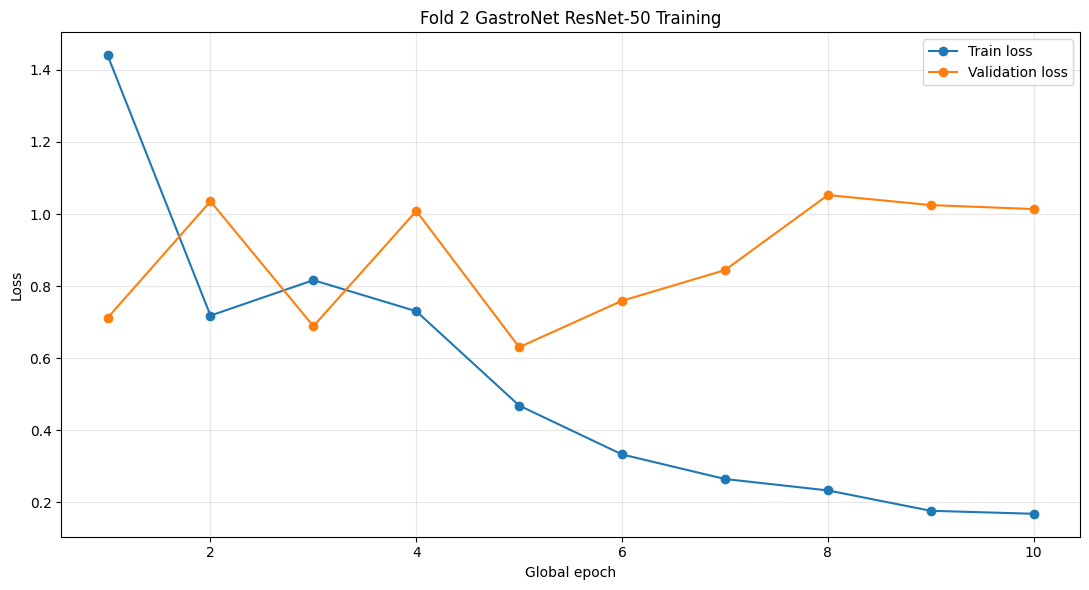

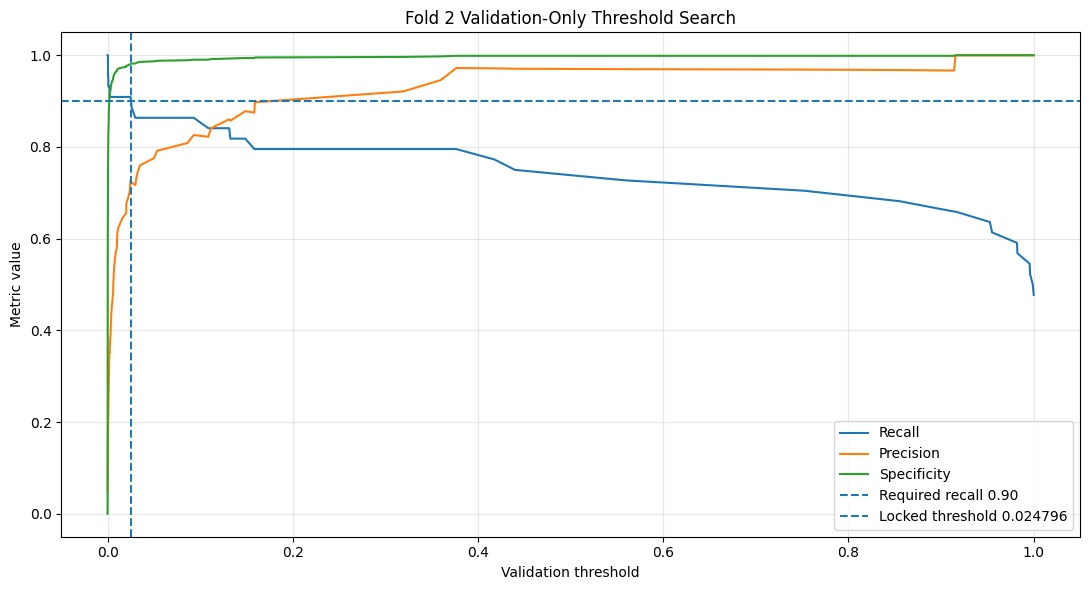


Training history:


,fold,stage,stage_epoch,global_epoch,train_loss,validation_loss,validation_auprc,validation_auroc
0,2,stage_1,1,1,1.440535,0.711933,0.548415,0.914314
1,2,stage_1,2,2,0.718342,1.035428,0.646379,0.943442
2,2,stage_1,3,3,0.816698,0.688878,0.672594,0.948199
3,2,stage_2,1,4,0.730418,1.008561,0.811793,0.969473
4,2,stage_2,2,5,0.468689,0.630713,0.878718,0.979466
5,2,stage_2,3,6,0.333112,0.759538,0.893307,0.977067
6,2,stage_2,4,7,0.264986,0.844520,0.893990,0.976656
7,2,stage_2,5,8,0.233325,1.052707,0.897976,0.978260
8,2,stage_2,6,9,0.176849,1.024923,0.900823,0.977615
9,2,stage_2,7,10,0.168494,1.013861,0.902969,0.979973



Locked validation metrics:


,experiment_id,fold,best_stage,best_stage_epoch,best_global_epoch,selection_mode,threshold,recall,precision,specificity,tp,tn,fp,fn,auprc,auroc,held_out_test_loaded,held_out_test_evaluated
0,cv_fold_2_rn50_gastronet5m_dinov1,2,stage_2,7,10,overall_recall_0.90_and_minimum_centre_recall_...,0.024796,0.909091,0.727273,0.981906,40,814,15,4,0.902969,0.979973,False,False



Per-centre validation metrics:


,experiment_id,fold,center,sample_count,normal_count,positive_count,threshold,recall,precision,specificity,tp,tn,fp,fn,auprc,auroc
0,cv_fold_2_rn50_gastronet5m_dinov1,2,center_1,645,628,17,0.024796,0.882353,0.714286,0.990446,15,622,6,2,0.841713,0.976021
1,cv_fold_2_rn50_gastronet5m_dinov1,2,center_2,228,201,27,0.024796,0.925926,0.735294,0.955224,25,192,9,2,0.941754,0.977059



FINAL FOLD 2 REPORT
Best stage: stage_2
Best global epoch: 10
Validation AUPRC: 0.902969
Validation AUROC: 0.979973
Locked threshold: 0.024795532227
Validation recall: 0.909091
Validation PPV: 0.727273
Validation specificity: 0.981906
TP: 40
FP: 15
FN: 4
TN: 814

Held-out test loaded: False
Held-out test evaluated: False
Held-out test used for model selection: False
Held-out test used for threshold selection: False

STATUS: FOLD_2_TRAINING_AND_THRESHOLD_LOCK_COMPLETE

Saved records:
/content/drive/MyDrive/RARE26_GastroNet_Weights/models/cross_validation/fold_2/cv_fold_2_rn50_gastronet5m_dinov1_best.pth
/content/drive/MyDrive/RARE26_GastroNet_Weights/logs/cross_validation/fold_2/cv_fold_2_rn50_gastronet5m_dinov1_training_history.csv
/content/drive/MyDrive/RARE26_GastroNet_Weights/predictions/cross_validation/fold_2/cv_fold_2_rn50_gastronet5m_dinov1_validation_predictions.csv
/content/drive/MyDrive/RARE26_GastroNet_Weights/predictions/cross_validation/fold_2/cv_fold_2_rn50_gastronet5m_d

In [10]:
# ============================================================
# RARE26 GastroNet Extension — CELL 11C
# Three-fold validation: FOLD 2
#
# Same locked protocol as Fold 1:
# Stage 1: classification head only — 3 epochs
# Stage 2: layer4 + head — max 7 epochs
# Checkpoint selected by Fold-2 validation AUPRC
# Threshold selected using Fold-2 validation only
#
# Held-out test is NOT loaded or evaluated.
# ============================================================

from pathlib import Path
from datetime import datetime, timezone
import gc
import json
import os
import random
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image
from tqdm.auto import tqdm

import torch
import torch.nn as nn

from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms

from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
)


# ============================================================
# 1. FOLD CONFIGURATION
# ============================================================

FOLD_NUMBER = 2
SEED = 42

PROJECT_ROOT = Path(
    "/content/drive/MyDrive/RARE26_GastroNet_Weights"
)

CV_ROOT = (
    PROJECT_ROOT
    / "configs"
    / "cross_validation"
)

FOLD_ROOT = (
    CV_ROOT
    / f"fold_{FOLD_NUMBER}"
)

TRAIN_CSV = (
    FOLD_ROOT
    / f"fold_{FOLD_NUMBER}_train_runtime.csv"
)

VALIDATION_CSV = (
    FOLD_ROOT
    / f"fold_{FOLD_NUMBER}_validation_runtime.csv"
)

SOURCE_CHECKPOINT_NAME = (
    "RN50_GastroNet-5M_DINOv1.pth"
)

EXPERIMENT_ID = (
    f"cv_fold_{FOLD_NUMBER}_rn50_gastronet5m_dinov1"
)

MODEL_DIR = (
    PROJECT_ROOT
    / "models"
    / "cross_validation"
    / f"fold_{FOLD_NUMBER}"
)

LOG_DIR = (
    PROJECT_ROOT
    / "logs"
    / "cross_validation"
    / f"fold_{FOLD_NUMBER}"
)

PREDICTION_DIR = (
    PROJECT_ROOT
    / "predictions"
    / "cross_validation"
    / f"fold_{FOLD_NUMBER}"
)

RESULT_DIR = (
    PROJECT_ROOT
    / "results"
    / "cross_validation"
    / f"fold_{FOLD_NUMBER}"
)

THRESHOLD_DIR = (
    PROJECT_ROOT
    / "thresholds"
    / "cross_validation"
    / f"fold_{FOLD_NUMBER}"
)

CENTRE_DIR = (
    PROJECT_ROOT
    / "centre_analysis"
    / "cross_validation"
    / f"fold_{FOLD_NUMBER}"
)

FIGURE_DIR = (
    PROJECT_ROOT
    / "figures"
    / "cross_validation"
    / f"fold_{FOLD_NUMBER}"
)

for directory in [
    MODEL_DIR,
    LOG_DIR,
    PREDICTION_DIR,
    RESULT_DIR,
    THRESHOLD_DIR,
    CENTRE_DIR,
    FIGURE_DIR,
]:
    directory.mkdir(
        parents=True,
        exist_ok=True,
    )

BEST_CHECKPOINT_PATH = (
    MODEL_DIR
    / f"{EXPERIMENT_ID}_best.pth"
)

LATEST_CHECKPOINT_PATH = (
    MODEL_DIR
    / f"{EXPERIMENT_ID}_latest.pth"
)

HISTORY_PATH = (
    LOG_DIR
    / f"{EXPERIMENT_ID}_training_history.csv"
)

RAW_PREDICTIONS_PATH = (
    PREDICTION_DIR
    / f"{EXPERIMENT_ID}_validation_predictions.csv"
)

LOCKED_PREDICTIONS_PATH = (
    PREDICTION_DIR
    / f"{EXPERIMENT_ID}_validation_predictions_locked_threshold.csv"
)

METRICS_PATH = (
    RESULT_DIR
    / f"{EXPERIMENT_ID}_validation_metrics.csv"
)

THRESHOLD_SEARCH_PATH = (
    THRESHOLD_DIR
    / f"{EXPERIMENT_ID}_validation_threshold_search.csv"
)

THRESHOLD_LOCK_PATH = (
    THRESHOLD_DIR
    / f"{EXPERIMENT_ID}_threshold_lock.json"
)

CENTRE_METRICS_PATH = (
    CENTRE_DIR
    / f"{EXPERIMENT_ID}_validation_per_centre_metrics.csv"
)

TRAINING_FIGURE_PATH = (
    FIGURE_DIR
    / f"{EXPERIMENT_ID}_training_curves.png"
)

THRESHOLD_FIGURE_PATH = (
    FIGURE_DIR
    / f"{EXPERIMENT_ID}_threshold_analysis.png"
)

CONFIG_PATH = (
    RESULT_DIR
    / f"{EXPERIMENT_ID}_configuration.json"
)

STATUS_PATH = (
    RESULT_DIR
    / f"{EXPERIMENT_ID}_status.json"
)

SUMMARY_PATH = (
    RESULT_DIR
    / f"{EXPERIMENT_ID}_summary.txt"
)

FINAL_STATUS = (
    f"FOLD_{FOLD_NUMBER}_TRAINING_AND_THRESHOLD_LOCK_COMPLETE"
)


# ============================================================
# 2. SAFETY CHECKS
# ============================================================

print("=" * 82)
print(
    f"CELL 11C: FOLD {FOLD_NUMBER} TRAINING "
    "AND VALIDATION THRESHOLD LOCK"
)
print("=" * 82)

if STATUS_PATH.exists():
    try:
        previous_status = json.loads(
            STATUS_PATH.read_text(
                encoding="utf-8"
            )
        )

        if previous_status.get("status") == FINAL_STATUS:
            raise FileExistsError(
                f"Fold {FOLD_NUMBER} is already complete.\n"
                f"Status file:\n{STATUS_PATH}"
            )
    except json.JSONDecodeError:
        pass

for required_file in [
    TRAIN_CSV,
    VALIDATION_CSV,
]:
    if not required_file.exists():
        raise FileNotFoundError(
            f"Required fold file not found:\n"
            f"{required_file}\n\n"
            "Cell 11A must be completed first."
        )

if not torch.cuda.is_available():
    raise RuntimeError(
        "GPU is not active.\n"
        "Select Runtime → Change runtime type → T4 GPU."
    )

device = torch.device("cuda")

gc.collect()
torch.cuda.empty_cache()

print("\nFold files:")
print(TRAIN_CSV)
print(VALIDATION_CSV)

print("\nDevice:")
print(torch.cuda.get_device_name(0))

print("\nHeld-out test loaded: False")
print("Held-out test evaluated: False")


# ============================================================
# 3. REPRODUCIBILITY
# ============================================================

def set_all_seeds(seed):
    random.seed(seed)
    np.random.seed(seed)

    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


set_all_seeds(SEED)

torch.set_float32_matmul_precision(
    "high"
)


# ============================================================
# 4. LOCATE PRETRAINED CHECKPOINT
# ============================================================

checkpoint_candidates = sorted(
    PROJECT_ROOT.rglob(
        SOURCE_CHECKPOINT_NAME
    ),
    key=lambda path: (
        0
        if path.parent.name
        == "source_checkpoints"
        else 1,
        len(path.parts),
        str(path),
    ),
)

if not checkpoint_candidates:
    raise FileNotFoundError(
        f"Pretrained checkpoint not found:\n"
        f"{SOURCE_CHECKPOINT_NAME}"
    )

SOURCE_CHECKPOINT_PATH = (
    checkpoint_candidates[0]
)

print("\nPretrained checkpoint:")
print(SOURCE_CHECKPOINT_PATH)


# ============================================================
# 5. LOAD AND VERIFY FOLD DATA
# ============================================================

train_df = pd.read_csv(
    TRAIN_CSV,
    low_memory=False,
).copy()

validation_df = pd.read_csv(
    VALIDATION_CSV,
    low_memory=False,
).copy()

required_columns = {
    "relative_path",
    "runtime_path",
    "label",
    "center",
    "class",
    "sha256",
    "cv_case_id",
    "cv_fold",
    "cv_role",
}

for dataframe_name, dataframe in [
    ("Fold train", train_df),
    ("Fold validation", validation_df),
]:
    missing_columns = (
        required_columns
        - set(dataframe.columns)
    )

    if missing_columns:
        raise RuntimeError(
            f"{dataframe_name} is missing columns:\n"
            f"{sorted(missing_columns)}"
        )

train_df["label"] = (
    train_df["label"].astype(int)
)

validation_df["label"] = (
    validation_df["label"].astype(int)
)

if set(train_df["cv_fold"].astype(int)) != {
    FOLD_NUMBER
}:
    raise RuntimeError(
        "Training CSV fold number is incorrect."
    )

if set(
    validation_df["cv_fold"].astype(int)
) != {FOLD_NUMBER}:
    raise RuntimeError(
        "Validation CSV fold number is incorrect."
    )

train_ids = set(
    train_df["cv_case_id"]
)

validation_ids = set(
    validation_df["cv_case_id"]
)

overlap_count = len(
    train_ids & validation_ids
)

if overlap_count != 0:
    raise RuntimeError(
        f"Train/validation overlap: {overlap_count}"
    )

for dataframe_name, dataframe in [
    ("Train", train_df),
    ("Validation", validation_df),
]:
    missing_images = int(
        (
            ~dataframe["runtime_path"].apply(
                lambda value: (
                    Path(str(value)).exists()
                    and Path(str(value)).is_file()
                )
            )
        ).sum()
    )

    if missing_images > 0:
        raise FileNotFoundError(
            f"{dataframe_name} contains "
            f"{missing_images} missing images.\n"
            "Run Cell 3B again."
        )

train_normal = int(
    (train_df["label"] == 0).sum()
)

train_positive = int(
    (train_df["label"] == 1).sum()
)

validation_normal = int(
    (validation_df["label"] == 0).sum()
)

validation_positive = int(
    (validation_df["label"] == 1).sum()
)

print(f"\nFold {FOLD_NUMBER} data:")
print(
    f"Train: {len(train_df)} "
    f"(normal={train_normal}, NEO={train_positive})"
)
print(
    f"Validation: {len(validation_df)} "
    f"(normal={validation_normal}, "
    f"NEO={validation_positive})"
)
print(f"Overlap: {overlap_count}")


# ============================================================
# 6. TRANSFORMS
# ============================================================

IMAGE_SIZE = 224
RESIZE_SIZE = 256

IMAGENET_MEAN = (
    0.485,
    0.456,
    0.406,
)

IMAGENET_STD = (
    0.229,
    0.224,
    0.225,
)

ROTATION_FILL = tuple(
    int(value * 255)
    for value in IMAGENET_MEAN
)

train_transform = transforms.Compose(
    [
        transforms.Resize(
            RESIZE_SIZE
        ),

        transforms.RandomResizedCrop(
            IMAGE_SIZE,
            scale=(0.85, 1.00),
            ratio=(0.90, 1.10),
        ),

        transforms.RandomHorizontalFlip(
            p=0.5
        ),

        transforms.RandomRotation(
            degrees=8,
            fill=ROTATION_FILL,
        ),

        transforms.ColorJitter(
            brightness=0.10,
            contrast=0.10,
            saturation=0.05,
            hue=0.02,
        ),

        transforms.ToTensor(),

        transforms.Normalize(
            mean=IMAGENET_MEAN,
            std=IMAGENET_STD,
        ),
    ]
)

validation_transform = transforms.Compose(
    [
        transforms.Resize(
            RESIZE_SIZE
        ),

        transforms.CenterCrop(
            IMAGE_SIZE
        ),

        transforms.ToTensor(),

        transforms.Normalize(
            mean=IMAGENET_MEAN,
            std=IMAGENET_STD,
        ),
    ]
)


# ============================================================
# 7. DATASET AND LOADERS
# ============================================================

class RARE26CVDataset(Dataset):

    def __init__(
        self,
        dataframe,
        transform,
    ):
        self.dataframe = (
            dataframe
            .reset_index(drop=True)
            .copy()
        )

        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):
        row = self.dataframe.iloc[index]

        with Image.open(
            Path(str(row["runtime_path"]))
        ) as image:
            image = image.convert("RGB")

        image = self.transform(image)

        return {
            "image": image,

            "label": torch.tensor(
                int(row["label"]),
                dtype=torch.float32,
            ),

            "dataset_index": int(index),

            "relative_path": str(
                row["relative_path"]
            ),

            "runtime_path": str(
                row["runtime_path"]
            ),

            "center": str(
                row["center"]
            ),

            "class_name": str(
                row["class"]
            ),

            "sha256": str(
                row["sha256"]
            ),

            "cv_case_id": str(
                row["cv_case_id"]
            ),
        }


train_dataset = RARE26CVDataset(
    train_df,
    train_transform,
)

validation_dataset = RARE26CVDataset(
    validation_df,
    validation_transform,
)

BATCH_SIZE = 32
NUM_WORKERS = 2

def seed_worker(worker_id):
    worker_seed = (
        torch.initial_seed()
        % (2 ** 32)
    )

    np.random.seed(worker_seed)
    random.seed(worker_seed)


loader_generator = torch.Generator()
loader_generator.manual_seed(SEED)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=True,
    drop_last=False,
    worker_init_fn=seed_worker,
    generator=loader_generator,
    persistent_workers=True,
)

validation_loader = DataLoader(
    validation_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True,
    drop_last=False,
    worker_init_fn=seed_worker,
    persistent_workers=True,
)

print("\nLoaders:")
print(f"Train batches: {len(train_loader)}")
print(
    f"Validation batches: "
    f"{len(validation_loader)}"
)


# ============================================================
# 8. LOAD GASTRONET RESNET-50
# ============================================================

def extract_state_dict(checkpoint):

    if isinstance(checkpoint, dict):

        for key in [
            "state_dict",
            "model_state_dict",
            "model",
            "encoder",
            "backbone",
        ]:
            if (
                key in checkpoint
                and isinstance(
                    checkpoint[key],
                    dict,
                )
            ):
                return checkpoint[key]

        if all(
            torch.is_tensor(value)
            for value in checkpoint.values()
        ):
            return checkpoint

    raise RuntimeError(
        "Could not identify checkpoint state dictionary."
    )


def remove_uniform_prefix(
    state_dict,
    prefix,
):
    keys = list(state_dict.keys())

    if keys and all(
        key.startswith(prefix)
        for key in keys
    ):
        return {
            key[len(prefix):]: value
            for key, value
            in state_dict.items()
        }

    return state_dict


checkpoint = torch.load(
    SOURCE_CHECKPOINT_PATH,
    map_location="cpu",
    weights_only=False,
)

state_dict = extract_state_dict(
    checkpoint
)

for prefix in [
    "module.",
    "model.",
    "backbone.",
    "encoder.",
]:
    state_dict = remove_uniform_prefix(
        state_dict,
        prefix,
    )

model = models.resnet50(
    weights=None
)

load_result = model.load_state_dict(
    state_dict,
    strict=False,
)

if set(load_result.missing_keys) != {
    "fc.weight",
    "fc.bias",
}:
    raise RuntimeError(
        f"Unexpected missing parameters:\n"
        f"{load_result.missing_keys}"
    )

if load_result.unexpected_keys:
    raise RuntimeError(
        f"Unexpected checkpoint parameters:\n"
        f"{load_result.unexpected_keys}"
    )

model.fc = nn.Linear(
    model.fc.in_features,
    1,
)

model = model.to(device)

print("\nGastroNet backbone loaded successfully.")


# ============================================================
# 9. LOCKED TRAINING PROTOCOL
# ============================================================

POS_WEIGHT = (
    train_normal
    / train_positive
)

criterion = nn.BCEWithLogitsLoss(
    pos_weight=torch.tensor(
        [POS_WEIGHT],
        dtype=torch.float32,
        device=device,
    )
)

STAGE_1_EPOCHS = 3
STAGE_1_LR = 1e-3

STAGE_2_MAX_EPOCHS = 7
STAGE_2_BACKBONE_LR = 1e-5
STAGE_2_HEAD_LR = 1e-4

WEIGHT_DECAY = 1e-4
PATIENCE = 3
GRADIENT_CLIP = 1.0

scaler = torch.amp.GradScaler(
    "cuda",
    enabled=True,
)

print("\nProtocol:")
print(f"Positive weight: {POS_WEIGHT:.6f}")
print("Stage 1: head only, 3 epochs")
print("Stage 2: layer4 + head, maximum 7 epochs")


# ============================================================
# 10. METRIC FUNCTIONS
# ============================================================

def binary_metrics(
    labels,
    probabilities,
    threshold,
):
    labels = np.asarray(
        labels,
        dtype=int,
    )

    probabilities = np.asarray(
        probabilities,
        dtype=float,
    )

    predictions = (
        probabilities >= threshold
    ).astype(int)

    tp = int(
        (
            (labels == 1)
            & (predictions == 1)
        ).sum()
    )

    tn = int(
        (
            (labels == 0)
            & (predictions == 0)
        ).sum()
    )

    fp = int(
        (
            (labels == 0)
            & (predictions == 1)
        ).sum()
    )

    fn = int(
        (
            (labels == 1)
            & (predictions == 0)
        ).sum()
    )

    recall = (
        tp / (tp + fn)
        if (tp + fn) > 0
        else np.nan
    )

    precision = (
        tp / (tp + fp)
        if (tp + fp) > 0
        else 0.0
    )

    specificity = (
        tn / (tn + fp)
        if (tn + fp) > 0
        else np.nan
    )

    return {
        "threshold": float(threshold),
        "recall": float(recall),
        "precision": float(precision),
        "specificity": float(specificity),
        "tp": tp,
        "tn": tn,
        "fp": fp,
        "fn": fn,
    }


# ============================================================
# 11. TRAINING AND VALIDATION FUNCTIONS
# ============================================================

def train_epoch(
    optimizer,
):
    model.train()

    running_loss = 0.0
    total_samples = 0

    for batch in tqdm(
        train_loader,
        leave=False,
        desc="Training",
    ):
        images = batch["image"].to(
            device,
            non_blocking=True,
        )

        labels = batch["label"].to(
            device,
            non_blocking=True,
        )

        optimizer.zero_grad(
            set_to_none=True
        )

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16,
        ):
            logits = model(
                images
            ).squeeze(1)

            loss = criterion(
                logits,
                labels,
            )

        scaler.scale(
            loss
        ).backward()

        scaler.unscale_(
            optimizer
        )

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            GRADIENT_CLIP,
        )

        scaler.step(
            optimizer
        )

        scaler.update()

        batch_size = images.size(0)

        running_loss += (
            float(loss.item())
            * batch_size
        )

        total_samples += batch_size

    return running_loss / total_samples


@torch.no_grad()
def evaluate(
    collect_records=False,
):
    model.eval()

    running_loss = 0.0
    total_samples = 0

    labels_all = []
    probabilities_all = []
    records = []

    for batch in tqdm(
        validation_loader,
        leave=False,
        desc="Validation",
    ):
        images = batch["image"].to(
            device,
            non_blocking=True,
        )

        labels = batch["label"].to(
            device,
            non_blocking=True,
        )

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16,
        ):
            logits = model(
                images
            ).squeeze(1)

            loss = criterion(
                logits,
                labels,
            )

        probabilities = torch.sigmoid(
            logits
        )

        labels_np = (
            labels.detach()
            .cpu()
            .numpy()
            .astype(int)
        )

        probabilities_np = (
            probabilities.detach()
            .cpu()
            .float()
            .numpy()
        )

        logits_np = (
            logits.detach()
            .cpu()
            .float()
            .numpy()
        )

        batch_size = images.size(0)

        running_loss += (
            float(loss.item())
            * batch_size
        )

        total_samples += batch_size

        labels_all.extend(
            labels_np.tolist()
        )

        probabilities_all.extend(
            probabilities_np.tolist()
        )

        if collect_records:
            for index in range(batch_size):
                records.append(
                    {
                        "dataset_index": int(
                            batch[
                                "dataset_index"
                            ][index]
                        ),

                        "relative_path": (
                            batch[
                                "relative_path"
                            ][index]
                        ),

                        "runtime_path": (
                            batch[
                                "runtime_path"
                            ][index]
                        ),

                        "center": (
                            batch[
                                "center"
                            ][index]
                        ),

                        "class_name": (
                            batch[
                                "class_name"
                            ][index]
                        ),

                        "sha256": (
                            batch[
                                "sha256"
                            ][index]
                        ),

                        "cv_case_id": (
                            batch[
                                "cv_case_id"
                            ][index]
                        ),

                        "label": int(
                            labels_np[index]
                        ),

                        "logit": float(
                            logits_np[index]
                        ),

                        "probability": float(
                            probabilities_np[index]
                        ),
                    }
                )

    labels_array = np.asarray(
        labels_all,
        dtype=int,
    )

    probabilities_array = np.asarray(
        probabilities_all,
        dtype=float,
    )

    return {
        "loss": (
            running_loss
            / total_samples
        ),

        "auprc": float(
            average_precision_score(
                labels_array,
                probabilities_array,
            )
        ),

        "auroc": float(
            roc_auc_score(
                labels_array,
                probabilities_array,
            )
        ),

        "labels": labels_array,

        "probabilities": (
            probabilities_array
        ),

        "records": records,
    }


# ============================================================
# 12. CHECKPOINT HELPER
# ============================================================

def save_checkpoint(
    destination,
    stage,
    stage_epoch,
    global_epoch,
    validation_result,
    optimizer,
    scheduler,
):
    temporary_path = Path(
        str(destination) + ".tmp"
    )

    torch.save(
        {
            "experiment_id": EXPERIMENT_ID,
            "fold": FOLD_NUMBER,
            "stage": stage,
            "stage_epoch": stage_epoch,
            "global_epoch": global_epoch,

            "model_state_dict": (
                model.state_dict()
            ),

            "optimizer_state_dict": (
                optimizer.state_dict()
            ),

            "scheduler_state_dict": (
                scheduler.state_dict()
            ),

            "validation_metrics": {
                "validation_loss": float(
                    validation_result["loss"]
                ),

                "validation_auprc": float(
                    validation_result["auprc"]
                ),

                "validation_auroc": float(
                    validation_result["auroc"]
                ),
            },

            "source_checkpoint": str(
                SOURCE_CHECKPOINT_PATH
            ),

            "held_out_test_loaded": False,
            "held_out_test_evaluated": False,
        },
        temporary_path,
    )

    os.replace(
        temporary_path,
        destination,
    )


# ============================================================
# 13. TRAIN MODEL
# ============================================================

history = []

global_epoch = 0
best_auprc = -np.inf

start_time = time.time()

# Stage 1
for parameter in model.parameters():
    parameter.requires_grad = False

for parameter in model.fc.parameters():
    parameter.requires_grad = True

optimizer_1 = torch.optim.AdamW(
    model.fc.parameters(),
    lr=STAGE_1_LR,
    weight_decay=WEIGHT_DECAY,
)

scheduler_1 = (
    torch.optim.lr_scheduler.CosineAnnealingLR(
        optimizer_1,
        T_max=STAGE_1_EPOCHS,
    )
)

print("\n" + "-" * 82)
print("STAGE 1: CLASSIFICATION HEAD ONLY")
print("-" * 82)

for epoch in range(
    1,
    STAGE_1_EPOCHS + 1,
):
    global_epoch += 1

    train_loss = train_epoch(
        optimizer_1
    )

    validation_result = evaluate()

    history.append(
        {
            "fold": FOLD_NUMBER,
            "stage": "stage_1",
            "stage_epoch": epoch,
            "global_epoch": global_epoch,
            "train_loss": train_loss,
            "validation_loss": (
                validation_result["loss"]
            ),
            "validation_auprc": (
                validation_result["auprc"]
            ),
            "validation_auroc": (
                validation_result["auroc"]
            ),
        }
    )

    print(
        f"Stage 1 | Epoch {epoch}/3 | "
        f"Train loss {train_loss:.6f} | "
        f"Val loss {validation_result['loss']:.6f} | "
        f"AUPRC {validation_result['auprc']:.6f} | "
        f"AUROC {validation_result['auroc']:.6f}"
    )

    save_checkpoint(
        LATEST_CHECKPOINT_PATH,
        "stage_1",
        epoch,
        global_epoch,
        validation_result,
        optimizer_1,
        scheduler_1,
    )

    if validation_result["auprc"] > best_auprc:
        best_auprc = (
            validation_result["auprc"]
        )

        save_checkpoint(
            BEST_CHECKPOINT_PATH,
            "stage_1",
            epoch,
            global_epoch,
            validation_result,
            optimizer_1,
            scheduler_1,
        )

    scheduler_1.step()


# Stage 2
for parameter in model.parameters():
    parameter.requires_grad = False

for parameter in model.layer4.parameters():
    parameter.requires_grad = True

for parameter in model.fc.parameters():
    parameter.requires_grad = True

optimizer_2 = torch.optim.AdamW(
    [
        {
            "params": (
                model.layer4.parameters()
            ),
            "lr": STAGE_2_BACKBONE_LR,
        },
        {
            "params": (
                model.fc.parameters()
            ),
            "lr": STAGE_2_HEAD_LR,
        },
    ],
    weight_decay=WEIGHT_DECAY,
)

scheduler_2 = (
    torch.optim.lr_scheduler.CosineAnnealingLR(
        optimizer_2,
        T_max=STAGE_2_MAX_EPOCHS,
    )
)

stage_2_best = -np.inf
no_improvement = 0

print("\n" + "-" * 82)
print("STAGE 2: LAYER4 AND CLASSIFICATION HEAD")
print("-" * 82)

for epoch in range(
    1,
    STAGE_2_MAX_EPOCHS + 1,
):
    global_epoch += 1

    train_loss = train_epoch(
        optimizer_2
    )

    validation_result = evaluate()

    history.append(
        {
            "fold": FOLD_NUMBER,
            "stage": "stage_2",
            "stage_epoch": epoch,
            "global_epoch": global_epoch,
            "train_loss": train_loss,
            "validation_loss": (
                validation_result["loss"]
            ),
            "validation_auprc": (
                validation_result["auprc"]
            ),
            "validation_auroc": (
                validation_result["auroc"]
            ),
        }
    )

    print(
        f"Stage 2 | Epoch {epoch}/7 | "
        f"Global {global_epoch} | "
        f"Train loss {train_loss:.6f} | "
        f"Val loss {validation_result['loss']:.6f} | "
        f"AUPRC {validation_result['auprc']:.6f} | "
        f"AUROC {validation_result['auroc']:.6f}"
    )

    save_checkpoint(
        LATEST_CHECKPOINT_PATH,
        "stage_2",
        epoch,
        global_epoch,
        validation_result,
        optimizer_2,
        scheduler_2,
    )

    if validation_result["auprc"] > best_auprc:
        best_auprc = (
            validation_result["auprc"]
        )

        save_checkpoint(
            BEST_CHECKPOINT_PATH,
            "stage_2",
            epoch,
            global_epoch,
            validation_result,
            optimizer_2,
            scheduler_2,
        )

    if validation_result["auprc"] > stage_2_best:
        stage_2_best = (
            validation_result["auprc"]
        )

        no_improvement = 0

    else:
        no_improvement += 1

    scheduler_2.step()

    if no_improvement >= PATIENCE:
        print(
            "\nEarly stopping activated after "
            f"{PATIENCE} non-improving epochs."
        )
        break


training_seconds = (
    time.time() - start_time
)

history_df = pd.DataFrame(
    history
)

history_df.to_csv(
    HISTORY_PATH,
    index=False,
)


# ============================================================
# 14. LOAD BEST CHECKPOINT
# ============================================================

best_checkpoint = torch.load(
    BEST_CHECKPOINT_PATH,
    map_location=device,
    weights_only=False,
)

model.load_state_dict(
    best_checkpoint[
        "model_state_dict"
    ]
)

model.eval()

print("\nBest checkpoint:")
print(
    f"Stage: {best_checkpoint['stage']}"
)
print(
    f"Stage epoch: "
    f"{best_checkpoint['stage_epoch']}"
)
print(
    f"Global epoch: "
    f"{best_checkpoint['global_epoch']}"
)
print(
    "Validation AUPRC: "
    f"{best_checkpoint['validation_metrics']['validation_auprc']:.6f}"
)
print(
    "Validation AUROC: "
    f"{best_checkpoint['validation_metrics']['validation_auroc']:.6f}"
)


# ============================================================
# 15. FINAL VALIDATION PREDICTIONS
# ============================================================

final_result = evaluate(
    collect_records=True
)

predictions_df = pd.DataFrame(
    final_result["records"]
).sort_values(
    "dataset_index"
).reset_index(drop=True)

if len(predictions_df) != len(
    validation_df
):
    raise RuntimeError(
        "Validation prediction count mismatch."
    )

predictions_df[
    "experiment_id"
] = EXPERIMENT_ID

predictions_df[
    "fold"
] = FOLD_NUMBER

predictions_df.to_csv(
    RAW_PREDICTIONS_PATH,
    index=False,
)


# ============================================================
# 16. VALIDATION-ONLY THRESHOLD SEARCH
# ============================================================

labels = predictions_df[
    "label"
].to_numpy(dtype=int)

probabilities = predictions_df[
    "probability"
].to_numpy(dtype=float)

candidate_thresholds = np.unique(
    np.concatenate(
        [
            [0.0],
            probabilities,
            [1.0],
        ]
    )
)

threshold_rows = []

for threshold in candidate_thresholds:

    overall = binary_metrics(
        labels,
        probabilities,
        threshold,
    )

    centre_recalls = {}

    for centre, group in (
        predictions_df.groupby(
            "center"
        )
    ):
        centre_result = binary_metrics(
            group["label"].to_numpy(
                dtype=int
            ),
            group["probability"].to_numpy(
                dtype=float
            ),
            threshold,
        )

        centre_recalls[
            centre
        ] = centre_result[
            "recall"
        ]

    minimum_centre_recall = float(
        min(centre_recalls.values())
    )

    threshold_rows.append(
        {
            **overall,

            "center_1_recall": float(
                centre_recalls[
                    "center_1"
                ]
            ),

            "center_2_recall": float(
                centre_recalls[
                    "center_2"
                ]
            ),

            "minimum_centre_recall": (
                minimum_centre_recall
            ),

            "overall_recall_met": bool(
                overall["recall"] >= 0.90
            ),

            "centre_recall_met": bool(
                minimum_centre_recall >= 0.80
            ),

            "strict_eligible": bool(
                overall["recall"] >= 0.90
                and minimum_centre_recall >= 0.80
            ),
        }
    )

threshold_df = pd.DataFrame(
    threshold_rows
)

eligible_df = threshold_df[
    threshold_df[
        "strict_eligible"
    ]
].copy()

if not eligible_df.empty:
    selection_mode = (
        "overall_recall_0.90_and_"
        "minimum_centre_recall_0.80"
    )

else:
    eligible_df = threshold_df[
        threshold_df[
            "overall_recall_met"
        ]
    ].copy()

    selection_mode = (
        "fallback_overall_recall_0.90"
    )

if eligible_df.empty:
    maximum_recall = threshold_df[
        "recall"
    ].max()

    eligible_df = threshold_df[
        threshold_df[
            "recall"
        ] == maximum_recall
    ].copy()

    selection_mode = (
        "fallback_highest_recall"
    )

selected_row = (
    eligible_df.sort_values(
        [
            "precision",
            "minimum_centre_recall",
            "specificity",
            "threshold",
        ],
        ascending=[
            False,
            False,
            False,
            False,
        ],
    )
    .iloc[0]
)

LOCKED_THRESHOLD = float(
    selected_row["threshold"]
)

threshold_df.to_csv(
    THRESHOLD_SEARCH_PATH,
    index=False,
)


# ============================================================
# 17. LOCKED OPERATING METRICS
# ============================================================

predictions_df[
    "locked_threshold"
] = LOCKED_THRESHOLD

predictions_df[
    "prediction"
] = (
    predictions_df["probability"]
    >= LOCKED_THRESHOLD
).astype(int)

predictions_df[
    "prediction_correct"
] = (
    predictions_df["prediction"]
    == predictions_df["label"]
)

predictions_df["error_type"] = np.select(
    [
        (
            (predictions_df["label"] == 1)
            & (predictions_df["prediction"] == 1)
        ),

        (
            (predictions_df["label"] == 0)
            & (predictions_df["prediction"] == 0)
        ),

        (
            (predictions_df["label"] == 0)
            & (predictions_df["prediction"] == 1)
        ),
    ],
    [
        "TP",
        "TN",
        "FP",
    ],
    default="FN",
)

predictions_df.to_csv(
    LOCKED_PREDICTIONS_PATH,
    index=False,
)

overall_metrics = binary_metrics(
    labels,
    probabilities,
    LOCKED_THRESHOLD,
)

overall_metrics["auprc"] = float(
    average_precision_score(
        labels,
        probabilities,
    )
)

overall_metrics["auroc"] = float(
    roc_auc_score(
        labels,
        probabilities,
    )
)

metrics_df = pd.DataFrame(
    [
        {
            "experiment_id": EXPERIMENT_ID,
            "fold": FOLD_NUMBER,

            "best_stage": (
                best_checkpoint["stage"]
            ),

            "best_stage_epoch": int(
                best_checkpoint[
                    "stage_epoch"
                ]
            ),

            "best_global_epoch": int(
                best_checkpoint[
                    "global_epoch"
                ]
            ),

            "selection_mode": (
                selection_mode
            ),

            **overall_metrics,

            "held_out_test_loaded": False,
            "held_out_test_evaluated": False,
        }
    ]
)

metrics_df.to_csv(
    METRICS_PATH,
    index=False,
)


# ============================================================
# 18. PER-CENTRE METRICS
# ============================================================

centre_rows = []

for centre, group in (
    predictions_df.groupby(
        "center"
    )
):
    centre_labels = group[
        "label"
    ].to_numpy(dtype=int)

    centre_probabilities = group[
        "probability"
    ].to_numpy(dtype=float)

    centre_metrics = binary_metrics(
        centre_labels,
        centre_probabilities,
        LOCKED_THRESHOLD,
    )

    centre_metrics["auprc"] = float(
        average_precision_score(
            centre_labels,
            centre_probabilities,
        )
    )

    centre_metrics["auroc"] = float(
        roc_auc_score(
            centre_labels,
            centre_probabilities,
        )
    )

    centre_rows.append(
        {
            "experiment_id": EXPERIMENT_ID,
            "fold": FOLD_NUMBER,
            "center": centre,

            "sample_count": len(group),

            "normal_count": int(
                (centre_labels == 0).sum()
            ),

            "positive_count": int(
                (centre_labels == 1).sum()
            ),

            **centre_metrics,
        }
    )

centre_metrics_df = pd.DataFrame(
    centre_rows
)

centre_metrics_df.to_csv(
    CENTRE_METRICS_PATH,
    index=False,
)


# ============================================================
# 19. SAVE LOCK AND STATUS
# ============================================================

threshold_lock = {
    "created_utc": datetime.now(
        timezone.utc
    ).isoformat(),

    "status": (
        f"FOLD_{FOLD_NUMBER}_VALIDATION_THRESHOLD_LOCKED"
    ),

    "experiment_id": EXPERIMENT_ID,
    "fold": FOLD_NUMBER,

    "selected_threshold": (
        LOCKED_THRESHOLD
    ),

    "selection_mode": (
        selection_mode
    ),

    "validation_auprc": float(
        overall_metrics["auprc"]
    ),

    "validation_auroc": float(
        overall_metrics["auroc"]
    ),

    "validation_recall": float(
        overall_metrics["recall"]
    ),

    "validation_precision": float(
        overall_metrics["precision"]
    ),

    "validation_specificity": float(
        overall_metrics["specificity"]
    ),

    "validation_tp": int(
        overall_metrics["tp"]
    ),

    "validation_tn": int(
        overall_metrics["tn"]
    ),

    "validation_fp": int(
        overall_metrics["fp"]
    ),

    "validation_fn": int(
        overall_metrics["fn"]
    ),

    "threshold_selected_from": (
        f"fold_{FOLD_NUMBER}_validation_only"
    ),

    "held_out_test_loaded": False,
    "held_out_test_evaluated": False,
    "held_out_test_used_for_threshold": False,
}

THRESHOLD_LOCK_PATH.write_text(
    json.dumps(
        threshold_lock,
        indent=2,
    ),
    encoding="utf-8",
)

configuration = {
    "experiment_id": EXPERIMENT_ID,
    "fold": FOLD_NUMBER,
    "random_seed": SEED,

    "train_images": len(train_df),
    "validation_images": len(
        validation_df
    ),

    "positive_weight": POS_WEIGHT,

    "source_checkpoint": str(
        SOURCE_CHECKPOINT_PATH
    ),

    "checkpoint_selection": (
        "validation_auprc"
    ),

    "threshold_selection": (
        "fold_validation_only"
    ),

    "held_out_test_loaded": False,
    "held_out_test_evaluated": False,
}

CONFIG_PATH.write_text(
    json.dumps(
        configuration,
        indent=2,
    ),
    encoding="utf-8",
)

status = {
    "created_utc": datetime.now(
        timezone.utc
    ).isoformat(),

    "status": FINAL_STATUS,

    "experiment_id": EXPERIMENT_ID,
    "fold": FOLD_NUMBER,

    "best_checkpoint": str(
        BEST_CHECKPOINT_PATH
    ),

    "best_stage": (
        best_checkpoint["stage"]
    ),

    "best_stage_epoch": int(
        best_checkpoint[
            "stage_epoch"
        ]
    ),

    "best_global_epoch": int(
        best_checkpoint[
            "global_epoch"
        ]
    ),

    "validation_auprc": float(
        overall_metrics["auprc"]
    ),

    "validation_auroc": float(
        overall_metrics["auroc"]
    ),

    "locked_threshold": float(
        LOCKED_THRESHOLD
    ),

    "training_seconds": (
        training_seconds
    ),

    "held_out_test_loaded": False,
    "held_out_test_evaluated": False,
    "held_out_test_used_for_model_selection": False,
    "held_out_test_used_for_threshold_selection": False,
}

STATUS_PATH.write_text(
    json.dumps(
        status,
        indent=2,
    ),
    encoding="utf-8",
)


# ============================================================
# 20. FIGURES
# ============================================================

figure = plt.figure(
    figsize=(11, 6)
)

plt.plot(
    history_df["global_epoch"],
    history_df["train_loss"],
    marker="o",
    label="Train loss",
)

plt.plot(
    history_df["global_epoch"],
    history_df["validation_loss"],
    marker="o",
    label="Validation loss",
)

plt.xlabel("Global epoch")
plt.ylabel("Loss")

plt.title(
    f"Fold {FOLD_NUMBER} GastroNet ResNet-50 Training"
)

plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()

figure.savefig(
    TRAINING_FIGURE_PATH,
    dpi=200,
    bbox_inches="tight",
)

plt.show()
plt.close(figure)

figure = plt.figure(
    figsize=(11, 6)
)

plt.plot(
    threshold_df["threshold"],
    threshold_df["recall"],
    label="Recall",
)

plt.plot(
    threshold_df["threshold"],
    threshold_df["precision"],
    label="Precision",
)

plt.plot(
    threshold_df["threshold"],
    threshold_df["specificity"],
    label="Specificity",
)

plt.axhline(
    0.90,
    linestyle="--",
    label="Required recall 0.90",
)

plt.axvline(
    LOCKED_THRESHOLD,
    linestyle="--",
    label=(
        f"Locked threshold "
        f"{LOCKED_THRESHOLD:.6f}"
    ),
)

plt.xlabel("Validation threshold")
plt.ylabel("Metric value")

plt.title(
    f"Fold {FOLD_NUMBER} Validation-Only Threshold Search"
)

plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()

figure.savefig(
    THRESHOLD_FIGURE_PATH,
    dpi=200,
    bbox_inches="tight",
)

plt.show()
plt.close(figure)


# ============================================================
# 21. SUMMARY AND FINAL REPORT
# ============================================================

summary_text = f"""
RARE26 GastroNet Three-Fold Validation
Fold {FOLD_NUMBER}
============================================================

Model:
{SOURCE_CHECKPOINT_NAME}

Train images:
{len(train_df)}

Validation images:
{len(validation_df)}

Best stage:
{best_checkpoint['stage']}

Best global epoch:
{best_checkpoint['global_epoch']}

Validation AUPRC:
{overall_metrics['auprc']:.6f}

Validation AUROC:
{overall_metrics['auroc']:.6f}

Locked threshold:
{LOCKED_THRESHOLD:.12f}

Recall:
{overall_metrics['recall']:.6f}

Precision:
{overall_metrics['precision']:.6f}

Specificity:
{overall_metrics['specificity']:.6f}

TP / FP / FN / TN:
{overall_metrics['tp']} / {overall_metrics['fp']} / {overall_metrics['fn']} / {overall_metrics['tn']}

Held-out test loaded:
No

Held-out test evaluated:
No

Status:
{FINAL_STATUS}
""".strip()

SUMMARY_PATH.write_text(
    summary_text,
    encoding="utf-8",
)

print("\nTraining history:")
display(history_df)

print("\nLocked validation metrics:")
display(metrics_df)

print("\nPer-centre validation metrics:")
display(centre_metrics_df)

print("\n" + "=" * 82)
print(
    f"FINAL FOLD {FOLD_NUMBER} REPORT"
)
print("=" * 82)

print(
    f"Best stage: "
    f"{best_checkpoint['stage']}"
)

print(
    f"Best global epoch: "
    f"{best_checkpoint['global_epoch']}"
)

print(
    f"Validation AUPRC: "
    f"{overall_metrics['auprc']:.6f}"
)

print(
    f"Validation AUROC: "
    f"{overall_metrics['auroc']:.6f}"
)

print(
    f"Locked threshold: "
    f"{LOCKED_THRESHOLD:.12f}"
)

print(
    f"Validation recall: "
    f"{overall_metrics['recall']:.6f}"
)

print(
    f"Validation PPV: "
    f"{overall_metrics['precision']:.6f}"
)

print(
    f"Validation specificity: "
    f"{overall_metrics['specificity']:.6f}"
)

print(
    f"TP: {overall_metrics['tp']}"
)

print(
    f"FP: {overall_metrics['fp']}"
)

print(
    f"FN: {overall_metrics['fn']}"
)

print(
    f"TN: {overall_metrics['tn']}"
)

print("\nHeld-out test loaded: False")
print("Held-out test evaluated: False")
print(
    "Held-out test used for model selection: False"
)
print(
    "Held-out test used for threshold selection: False"
)

print(
    f"\nSTATUS: {FINAL_STATUS}"
)

print("\nSaved records:")
print(BEST_CHECKPOINT_PATH)
print(HISTORY_PATH)
print(RAW_PREDICTIONS_PATH)
print(LOCKED_PREDICTIONS_PATH)
print(METRICS_PATH)
print(THRESHOLD_SEARCH_PATH)
print(THRESHOLD_LOCK_PATH)
print(CENTRE_METRICS_PATH)
print(STATUS_PATH)
print(SUMMARY_PATH)

gc.collect()
torch.cuda.empty_cache()

CELL 11D: FOLD 3 TRAINING AND VALIDATION THRESHOLD LOCK

Fold 3 files:
/content/drive/MyDrive/RARE26_GastroNet_Weights/configs/cross_validation/fold_3/fold_3_train_runtime.csv
/content/drive/MyDrive/RARE26_GastroNet_Weights/configs/cross_validation/fold_3/fold_3_validation_runtime.csv

Compute device:
cuda
Tesla T4

Held-out test CSV loaded: False
Held-out test evaluated: False

Pretrained source checkpoint:
/content/drive/MyDrive/RARE26_GastroNet_Weights/source_checkpoints/RN50_GastroNet-5M_DINOv1.pth
Checkpoint size: 89.979 MB

Fold 3 data verified:
Train: 1747 (normal=1659, NEO=88)
Validation: 873 (normal=829, NEO=44)
Train/validation overlap: 0

Data loaders:
Train batches: 55
Validation batches: 28

GastroNet ResNet-50 backbone loaded:
Missing parameters: ['fc.weight', 'fc.bias']
Unexpected parameters: []
New classification head: Linear(2048, 1)

Locked Fold 3 protocol:
Positive weight: 18.852273
Stage 1: classification head only, 3 epochs
Stage 2: layer4 + classification head, ma

Training:   0%|          | 0/55 [00:00<?, ?it/s]

Validation:   0%|          | 0/28 [00:00<?, ?it/s]

Stage 1 | Epoch 1/3 | Train loss 1.150624 | Val loss 0.929181 | AUPRC 0.589981 | AUROC 0.874575


Training:   0%|          | 0/55 [00:00<?, ?it/s]

...

Stage 2 | Epoch 6/7 | Global 9 | Train loss 0.142652 | Val loss 1.533481 | AUPRC 0.865793 | AUROC 0.945704


Training:   0%|          | 0/55 [00:00<?, ?it/s]

Validation:   0%|          | 0/28 [00:00<?, ?it/s]

Stage 2 | Epoch 7/7 | Global 10 | Train loss 0.133186 | Val loss 1.566153 | AUPRC 0.869296 | AUROC 0.948418

Early stopping activated after 3 consecutive Stage-2 epochs without AUPRC improvement.

Best Fold 3 checkpoint:
Stage: stage_2
Stage epoch: 4
Global epoch: 7
Validation AUPRC: 0.869713
Validation AUROC: 0.948829


Validation:   0%|          | 0/28 [00:00<?, ?it/s]

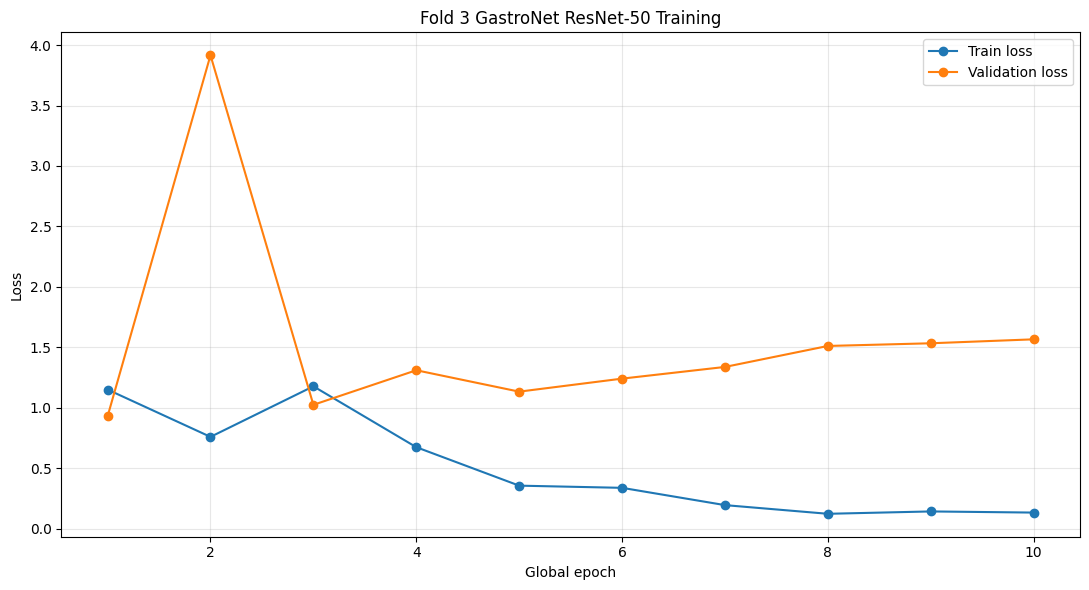

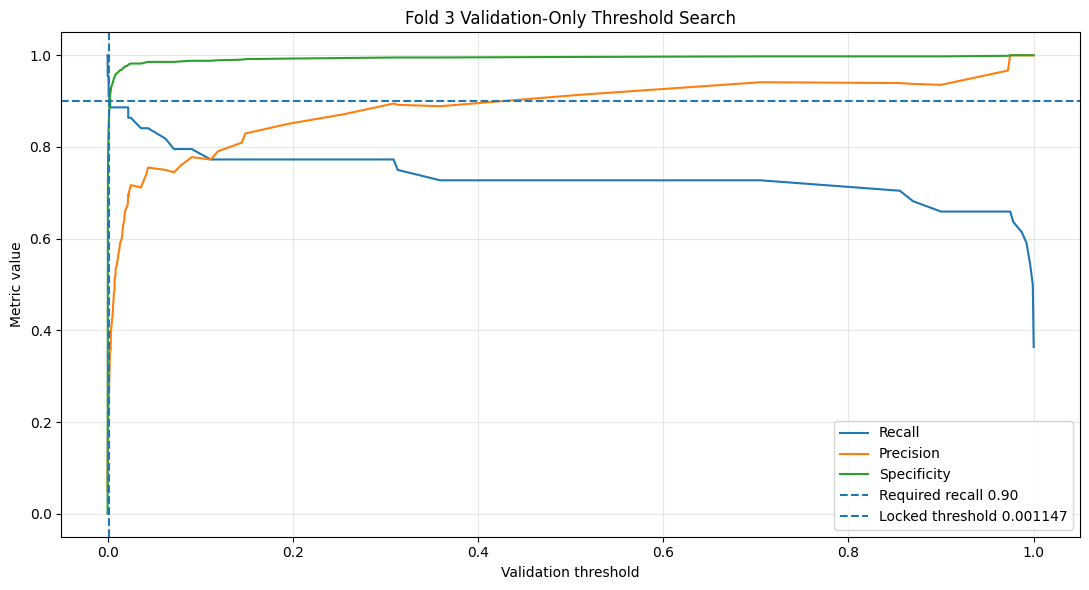


Fold 3 training history:


,fold,stage,stage_epoch,global_epoch,train_loss,validation_loss,validation_auprc,validation_auroc,learning_rate_backbone,learning_rate_head
0,3,stage_1,1,1,1.150624,0.929181,0.589981,0.874575,0.000000e+00,0.001000
1,3,stage_1,2,2,0.759333,3.915626,0.609982,0.882731,0.000000e+00,0.000750
2,3,stage_1,3,3,1.177571,1.024497,0.663971,0.895164,0.000000e+00,0.000250
3,3,stage_2,1,4,0.674113,1.310371,0.778928,0.926678,1.000000e-05,0.000100
4,3,stage_2,2,5,0.355931,1.133435,0.850627,0.950365,9.504844e-06,0.000095
5,3,stage_2,3,6,0.337834,1.241121,0.866287,0.950680,8.117449e-06,0.000081
6,3,stage_2,4,7,0.194862,1.337817,0.869713,0.948829,6.112605e-06,0.000061
7,3,stage_2,5,8,0.123140,1.511317,0.863652,0.946636,3.887395e-06,0.000039
8,3,stage_2,6,9,0.142652,1.533481,0.865793,0.945704,1.882551e-06,0.000019
9,3,stage_2,7,10,0.133186,1.566153,0.869296,0.948418,4.951557e-07,0.000005



Fold 3 locked validation metrics:


,experiment_id,fold,best_stage,best_stage_epoch,best_global_epoch,selection_mode,threshold,recall,precision,specificity,...,accuracy,f1,tp,tn,fp,fn,auprc,auroc,held_out_test_loaded,held_out_test_evaluated
0,cv_fold_3_rn50_gastronet5m_dinov1,3,stage_2,4,7,overall_recall_0.90_and_minimum_centre_recall_...,0.001147,0.931818,0.248485,0.850422,...,0.854525,0.392344,41,705,124,3,0.869713,0.948829,False,False



Fold 3 per-centre validation metrics:


,experiment_id,fold,center,sample_count,normal_count,positive_count,threshold,recall,precision,specificity,npv,accuracy,f1,tp,tn,fp,fn,auprc,auroc
0,cv_fold_3_rn50_gastronet5m_dinov1,3,center_1,645,628,17,0.001147,0.823529,0.205882,0.914013,0.994801,0.911628,0.329412,14,574,54,3,0.686313,0.884601
1,cv_fold_3_rn50_gastronet5m_dinov1,3,center_2,228,201,27,0.001147,1.000000,0.278351,0.651741,1.000000,0.692982,0.435484,27,131,70,0,0.976115,0.995946



FINAL CELL 11D FOLD 3 REPORT
Best stage: stage_2
Best stage epoch: 4
Best global epoch: 7
Validation AUPRC: 0.869713
Validation AUROC: 0.948829
Locked threshold: 0.001147270203
Validation recall: 0.931818
Validation PPV: 0.248485
Validation specificity: 0.850422
TP: 41
FP: 124
FN: 3
TN: 705

Held-out test loaded: False
Held-out test evaluated: False
Held-out test used for model selection: False
Held-out test used for threshold selection: False

STATUS: FOLD_3_TRAINING_AND_THRESHOLD_LOCK_COMPLETE

Saved Fold 3 records:
/content/drive/MyDrive/RARE26_GastroNet_Weights/models/cross_validation/fold_3/cv_fold_3_rn50_gastronet5m_dinov1_best.pth
/content/drive/MyDrive/RARE26_GastroNet_Weights/logs/cross_validation/fold_3/cv_fold_3_rn50_gastronet5m_dinov1_training_history.csv
/content/drive/MyDrive/RARE26_GastroNet_Weights/predictions/cross_validation/fold_3/cv_fold_3_rn50_gastronet5m_dinov1_validation_predictions.csv
/content/drive/MyDrive/RARE26_GastroNet_Weights/predictions/cross_validation

In [11]:
# ============================================================
# RARE26 GastroNet Extension — CELL 11D
# THREE-FOLD VALIDATION: FOLD 3
#
# Pretrained model:
#   RN50_GastroNet-5M_DINOv1.pth
#
# Locked protocol:
#   Stage 1: classification head only — 3 epochs
#   Stage 2: layer4 + head — maximum 7 epochs
#   Best checkpoint: Fold-3 validation AUPRC
#   Threshold: Fold-3 validation predictions only
#
# The original 468-image held-out test set is NOT loaded,
# evaluated, or used for any decision.
# ============================================================

from pathlib import Path
from datetime import datetime, timezone
import gc
import json
import os
import random
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image
from tqdm.auto import tqdm

import torch
import torch.nn as nn

from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms

from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
)


# ============================================================
# 1. FOLD-3 CONFIGURATION
# ============================================================

FOLD_NUMBER = 3
SEED = 42

PROJECT_ROOT = Path(
    "/content/drive/MyDrive/RARE26_GastroNet_Weights"
)

CV_ROOT = (
    PROJECT_ROOT
    / "configs"
    / "cross_validation"
)

FOLD_SPLIT_ROOT = (
    CV_ROOT
    / f"fold_{FOLD_NUMBER}"
)

FOLD_TRAIN_CSV = (
    FOLD_SPLIT_ROOT
    / f"fold_{FOLD_NUMBER}_train_runtime.csv"
)

FOLD_VALIDATION_CSV = (
    FOLD_SPLIT_ROOT
    / f"fold_{FOLD_NUMBER}_validation_runtime.csv"
)

SOURCE_CHECKPOINT_NAME = (
    "RN50_GastroNet-5M_DINOv1.pth"
)

EXPERIMENT_ID = (
    f"cv_fold_{FOLD_NUMBER}_rn50_gastronet5m_dinov1"
)

FINAL_STATUS = (
    "FOLD_3_TRAINING_AND_THRESHOLD_LOCK_COMPLETE"
)


# ============================================================
# 2. OUTPUT DIRECTORIES
# ============================================================

MODEL_DIR = (
    PROJECT_ROOT
    / "models"
    / "cross_validation"
    / "fold_3"
)

LOG_DIR = (
    PROJECT_ROOT
    / "logs"
    / "cross_validation"
    / "fold_3"
)

PREDICTION_DIR = (
    PROJECT_ROOT
    / "predictions"
    / "cross_validation"
    / "fold_3"
)

RESULT_DIR = (
    PROJECT_ROOT
    / "results"
    / "cross_validation"
    / "fold_3"
)

THRESHOLD_DIR = (
    PROJECT_ROOT
    / "thresholds"
    / "cross_validation"
    / "fold_3"
)

CENTRE_DIR = (
    PROJECT_ROOT
    / "centre_analysis"
    / "cross_validation"
    / "fold_3"
)

FIGURE_DIR = (
    PROJECT_ROOT
    / "figures"
    / "cross_validation"
    / "fold_3"
)

for directory in [
    MODEL_DIR,
    LOG_DIR,
    PREDICTION_DIR,
    RESULT_DIR,
    THRESHOLD_DIR,
    CENTRE_DIR,
    FIGURE_DIR,
]:
    directory.mkdir(
        parents=True,
        exist_ok=True,
    )


# ============================================================
# 3. OUTPUT FILE PATHS
# ============================================================

BEST_CHECKPOINT_PATH = (
    MODEL_DIR
    / f"{EXPERIMENT_ID}_best.pth"
)

LATEST_CHECKPOINT_PATH = (
    MODEL_DIR
    / f"{EXPERIMENT_ID}_latest.pth"
)

TRAINING_HISTORY_PATH = (
    LOG_DIR
    / f"{EXPERIMENT_ID}_training_history.csv"
)

RAW_VALIDATION_PREDICTIONS_PATH = (
    PREDICTION_DIR
    / f"{EXPERIMENT_ID}_validation_predictions.csv"
)

LOCKED_VALIDATION_PREDICTIONS_PATH = (
    PREDICTION_DIR
    / f"{EXPERIMENT_ID}_validation_predictions_locked_threshold.csv"
)

VALIDATION_METRICS_PATH = (
    RESULT_DIR
    / f"{EXPERIMENT_ID}_validation_metrics.csv"
)

THRESHOLD_SEARCH_PATH = (
    THRESHOLD_DIR
    / f"{EXPERIMENT_ID}_validation_threshold_search.csv"
)

THRESHOLD_OPERATING_POINT_PATH = (
    THRESHOLD_DIR
    / f"{EXPERIMENT_ID}_validation_operating_point.csv"
)

THRESHOLD_LOCK_PATH = (
    THRESHOLD_DIR
    / f"{EXPERIMENT_ID}_threshold_lock.json"
)

CENTRE_METRICS_PATH = (
    CENTRE_DIR
    / f"{EXPERIMENT_ID}_validation_per_centre_metrics.csv"
)

TRAINING_FIGURE_PATH = (
    FIGURE_DIR
    / f"{EXPERIMENT_ID}_training_curves.png"
)

THRESHOLD_FIGURE_PATH = (
    FIGURE_DIR
    / f"{EXPERIMENT_ID}_threshold_analysis.png"
)

CONFIG_PATH = (
    RESULT_DIR
    / f"{EXPERIMENT_ID}_configuration.json"
)

STATUS_PATH = (
    RESULT_DIR
    / f"{EXPERIMENT_ID}_status.json"
)

SUMMARY_PATH = (
    RESULT_DIR
    / f"{EXPERIMENT_ID}_summary.txt"
)


# ============================================================
# 4. PREVENT ACCIDENTAL REPEAT
# ============================================================

print("=" * 82)
print("CELL 11D: FOLD 3 TRAINING AND VALIDATION THRESHOLD LOCK")
print("=" * 82)

if STATUS_PATH.exists():
    try:
        existing_status = json.loads(
            STATUS_PATH.read_text(
                encoding="utf-8"
            )
        )

        if (
            existing_status.get("status")
            == FINAL_STATUS
        ):
            raise FileExistsError(
                "Fold 3 training is already complete.\n"
                f"Status file:\n{STATUS_PATH}"
            )

    except json.JSONDecodeError:
        pass


# ============================================================
# 5. VERIFY REQUIRED FILES AND GPU
# ============================================================

for required_file in [
    FOLD_TRAIN_CSV,
    FOLD_VALIDATION_CSV,
]:
    if not required_file.exists():
        raise FileNotFoundError(
            f"Required Fold 3 file was not found:\n"
            f"{required_file}\n\n"
            "Cell 11A must complete successfully first."
        )

if not torch.cuda.is_available():
    raise RuntimeError(
        "GPU runtime is not active.\n"
        "In Colab select Runtime → Change runtime type → T4 GPU."
    )

device = torch.device("cuda")

gc.collect()
torch.cuda.empty_cache()

print("\nFold 3 files:")
print(FOLD_TRAIN_CSV)
print(FOLD_VALIDATION_CSV)

print("\nCompute device:")
print(device)
print(torch.cuda.get_device_name(0))

print("\nHeld-out test CSV loaded: False")
print("Held-out test evaluated: False")


# ============================================================
# 6. REPRODUCIBILITY
# ============================================================

def set_all_seeds(seed):
    random.seed(seed)
    np.random.seed(seed)

    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


set_all_seeds(SEED)

torch.set_float32_matmul_precision(
    "high"
)


# ============================================================
# 7. LOCATE ORIGINAL PRETRAINED CHECKPOINT
# ============================================================

checkpoint_candidates = sorted(
    PROJECT_ROOT.rglob(
        SOURCE_CHECKPOINT_NAME
    ),
    key=lambda path: (
        0
        if path.parent.name
        == "source_checkpoints"
        else 1,
        len(path.parts),
        str(path),
    ),
)

if len(checkpoint_candidates) == 0:
    raise FileNotFoundError(
        "Original GastroNet checkpoint was not found:\n"
        f"{SOURCE_CHECKPOINT_NAME}"
    )

SOURCE_CHECKPOINT_PATH = (
    checkpoint_candidates[0]
)

print("\nPretrained source checkpoint:")
print(SOURCE_CHECKPOINT_PATH)

print(
    f"Checkpoint size: "
    f"{SOURCE_CHECKPOINT_PATH.stat().st_size / (1024 ** 2):.3f} MB"
)


# ============================================================
# 8. LOAD AND VERIFY FOLD-3 DATA
# ============================================================

fold_train_df = pd.read_csv(
    FOLD_TRAIN_CSV,
    low_memory=False,
).copy()

fold_validation_df = pd.read_csv(
    FOLD_VALIDATION_CSV,
    low_memory=False,
).copy()

required_columns = {
    "relative_path",
    "runtime_path",
    "label",
    "center",
    "class",
    "sha256",
    "cv_case_id",
    "cv_fold",
    "cv_role",
}

for dataframe_name, dataframe in [
    ("Fold 3 train", fold_train_df),
    ("Fold 3 validation", fold_validation_df),
]:
    missing_columns = (
        required_columns
        - set(dataframe.columns)
    )

    if missing_columns:
        raise RuntimeError(
            f"{dataframe_name} is missing columns:\n"
            f"{sorted(missing_columns)}"
        )

fold_train_df["label"] = (
    fold_train_df["label"].astype(int)
)

fold_validation_df["label"] = (
    fold_validation_df["label"].astype(int)
)

fold_train_df["cv_fold"] = (
    fold_train_df["cv_fold"].astype(int)
)

fold_validation_df["cv_fold"] = (
    fold_validation_df["cv_fold"].astype(int)
)

if set(fold_train_df["cv_fold"].unique()) != {3}:
    raise RuntimeError(
        "Training CSV does not belong to Fold 3."
    )

if (
    set(
        fold_validation_df[
            "cv_fold"
        ].unique()
    )
    != {3}
):
    raise RuntimeError(
        "Validation CSV does not belong to Fold 3."
    )

if len(fold_train_df) != 1747:
    raise RuntimeError(
        f"Fold 3 train should contain 1,747 records, "
        f"but contains {len(fold_train_df)}."
    )

if len(fold_validation_df) != 873:
    raise RuntimeError(
        f"Fold 3 validation should contain 873 records, "
        f"but contains {len(fold_validation_df)}."
    )

train_normal_count = int(
    (fold_train_df["label"] == 0).sum()
)

train_positive_count = int(
    (fold_train_df["label"] == 1).sum()
)

validation_normal_count = int(
    (fold_validation_df["label"] == 0).sum()
)

validation_positive_count = int(
    (fold_validation_df["label"] == 1).sum()
)

if (
    train_normal_count != 1659
    or train_positive_count != 88
):
    raise RuntimeError(
        "Fold 3 training class counts are incorrect."
    )

if (
    validation_normal_count != 829
    or validation_positive_count != 44
):
    raise RuntimeError(
        "Fold 3 validation class counts are incorrect."
    )

train_case_ids = set(
    fold_train_df["cv_case_id"]
)

validation_case_ids = set(
    fold_validation_df["cv_case_id"]
)

overlap_count = len(
    train_case_ids
    & validation_case_ids
)

if overlap_count != 0:
    raise RuntimeError(
        f"Fold 3 train/validation overlap: {overlap_count}"
    )

for dataframe_name, dataframe in [
    ("Fold 3 train", fold_train_df),
    ("Fold 3 validation", fold_validation_df),
]:
    missing_images = int(
        (
            ~dataframe[
                "runtime_path"
            ].apply(
                lambda path_value: (
                    Path(str(path_value)).exists()
                    and Path(str(path_value)).is_file()
                )
            )
        ).sum()
    )

    if missing_images > 0:
        raise FileNotFoundError(
            f"{dataframe_name} contains "
            f"{missing_images} missing runtime images.\n"
            "Run Cell 3B again."
        )

print("\nFold 3 data verified:")

print(
    f"Train: {len(fold_train_df)} "
    f"(normal={train_normal_count}, "
    f"NEO={train_positive_count})"
)

print(
    f"Validation: {len(fold_validation_df)} "
    f"(normal={validation_normal_count}, "
    f"NEO={validation_positive_count})"
)

print(
    f"Train/validation overlap: "
    f"{overlap_count}"
)


# ============================================================
# 9. IMAGE TRANSFORMS
# ============================================================

IMAGE_SIZE = 224
RESIZE_SIZE = 256

IMAGENET_MEAN = (
    0.485,
    0.456,
    0.406,
)

IMAGENET_STD = (
    0.229,
    0.224,
    0.225,
)

ROTATION_FILL = tuple(
    int(value * 255)
    for value in IMAGENET_MEAN
)

train_transform = transforms.Compose(
    [
        transforms.Resize(
            RESIZE_SIZE
        ),

        transforms.RandomResizedCrop(
            IMAGE_SIZE,
            scale=(0.85, 1.00),
            ratio=(0.90, 1.10),
        ),

        transforms.RandomHorizontalFlip(
            p=0.5
        ),

        transforms.RandomRotation(
            degrees=8,
            fill=ROTATION_FILL,
        ),

        transforms.ColorJitter(
            brightness=0.10,
            contrast=0.10,
            saturation=0.05,
            hue=0.02,
        ),

        transforms.ToTensor(),

        transforms.Normalize(
            mean=IMAGENET_MEAN,
            std=IMAGENET_STD,
        ),
    ]
)

validation_transform = transforms.Compose(
    [
        transforms.Resize(
            RESIZE_SIZE
        ),

        transforms.CenterCrop(
            IMAGE_SIZE
        ),

        transforms.ToTensor(),

        transforms.Normalize(
            mean=IMAGENET_MEAN,
            std=IMAGENET_STD,
        ),
    ]
)


# ============================================================
# 10. DATASET CLASS
# ============================================================

class RARE26FoldDataset(Dataset):

    def __init__(
        self,
        dataframe,
        transform,
    ):
        self.dataframe = (
            dataframe
            .reset_index(drop=True)
            .copy()
        )

        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):
        row = self.dataframe.iloc[index]

        image_path = Path(
            str(row["runtime_path"])
        )

        with Image.open(
            image_path
        ) as image:
            image = image.convert("RGB")

        image = self.transform(image)

        return {
            "image": image,

            "label": torch.tensor(
                int(row["label"]),
                dtype=torch.float32,
            ),

            "dataset_index": int(index),

            "relative_path": str(
                row["relative_path"]
            ),

            "runtime_path": str(
                row["runtime_path"]
            ),

            "center": str(
                row["center"]
            ),

            "class_name": str(
                row["class"]
            ),

            "sha256": str(
                row["sha256"]
            ),

            "cv_case_id": str(
                row["cv_case_id"]
            ),
        }


train_dataset = RARE26FoldDataset(
    fold_train_df,
    train_transform,
)

validation_dataset = RARE26FoldDataset(
    fold_validation_df,
    validation_transform,
)


# ============================================================
# 11. DATA LOADERS
# ============================================================

BATCH_SIZE = 32
NUM_WORKERS = 2

def seed_worker(worker_id):
    worker_seed = (
        torch.initial_seed()
        % (2 ** 32)
    )

    np.random.seed(worker_seed)
    random.seed(worker_seed)


loader_generator = torch.Generator()
loader_generator.manual_seed(SEED)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=True,
    drop_last=False,
    worker_init_fn=seed_worker,
    generator=loader_generator,
    persistent_workers=(
        NUM_WORKERS > 0
    ),
)

validation_loader = DataLoader(
    validation_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True,
    drop_last=False,
    worker_init_fn=seed_worker,
    persistent_workers=(
        NUM_WORKERS > 0
    ),
)

print("\nData loaders:")
print(
    f"Train batches: "
    f"{len(train_loader)}"
)

print(
    f"Validation batches: "
    f"{len(validation_loader)}"
)


# ============================================================
# 12. LOAD GASTRONET RESNET-50 BACKBONE
# ============================================================

def extract_state_dict(
    checkpoint_object,
):
    if isinstance(
        checkpoint_object,
        dict,
    ):
        for possible_key in [
            "state_dict",
            "model_state_dict",
            "model",
            "encoder",
            "backbone",
        ]:
            if (
                possible_key
                in checkpoint_object
                and isinstance(
                    checkpoint_object[
                        possible_key
                    ],
                    dict,
                )
            ):
                return checkpoint_object[
                    possible_key
                ]

        if all(
            torch.is_tensor(value)
            for value
            in checkpoint_object.values()
        ):
            return checkpoint_object

    raise RuntimeError(
        "Could not identify a state dictionary "
        "inside the pretrained checkpoint."
    )


def remove_uniform_prefix(
    state_dictionary,
    prefix,
):
    keys = list(
        state_dictionary.keys()
    )

    if (
        len(keys) > 0
        and all(
            key.startswith(prefix)
            for key in keys
        )
    ):
        return {
            key[len(prefix):]: value
            for key, value
            in state_dictionary.items()
        }

    return state_dictionary


checkpoint_object = torch.load(
    SOURCE_CHECKPOINT_PATH,
    map_location="cpu",
    weights_only=False,
)

pretrained_state_dict = extract_state_dict(
    checkpoint_object
)

for possible_prefix in [
    "module.",
    "model.",
    "backbone.",
    "encoder.",
]:
    pretrained_state_dict = (
        remove_uniform_prefix(
            pretrained_state_dict,
            possible_prefix,
        )
    )

model = models.resnet50(
    weights=None
)

load_result = model.load_state_dict(
    pretrained_state_dict,
    strict=False,
)

expected_missing_keys = {
    "fc.weight",
    "fc.bias",
}

if (
    set(load_result.missing_keys)
    != expected_missing_keys
):
    raise RuntimeError(
        "Unexpected missing parameters:\n"
        f"{load_result.missing_keys}"
    )

if len(
    load_result.unexpected_keys
) > 0:
    raise RuntimeError(
        "Unexpected pretrained parameters:\n"
        f"{load_result.unexpected_keys}"
    )

classification_features = (
    model.fc.in_features
)

model.fc = nn.Linear(
    classification_features,
    1,
)

model = model.to(device)

print("\nGastroNet ResNet-50 backbone loaded:")

print(
    f"Missing parameters: "
    f"{load_result.missing_keys}"
)

print(
    f"Unexpected parameters: "
    f"{load_result.unexpected_keys}"
)

print(
    f"New classification head: "
    f"Linear({classification_features}, 1)"
)


# ============================================================
# 13. LOCKED TRAINING PROTOCOL
# ============================================================

POS_WEIGHT = (
    train_normal_count
    / train_positive_count
)

criterion = nn.BCEWithLogitsLoss(
    pos_weight=torch.tensor(
        [POS_WEIGHT],
        dtype=torch.float32,
        device=device,
    )
)

STAGE_1_EPOCHS = 3
STAGE_1_LEARNING_RATE = 1e-3

STAGE_2_MAX_EPOCHS = 7
STAGE_2_BACKBONE_LEARNING_RATE = 1e-5
STAGE_2_HEAD_LEARNING_RATE = 1e-4

WEIGHT_DECAY = 1e-4
EARLY_STOPPING_PATIENCE = 3
GRADIENT_CLIP_NORM = 1.0

AMP_ENABLED = True

try:
    scaler = torch.amp.GradScaler(
        "cuda",
        enabled=AMP_ENABLED,
    )

except Exception:
    scaler = torch.cuda.amp.GradScaler(
        enabled=AMP_ENABLED
    )

print("\nLocked Fold 3 protocol:")

print(
    f"Positive weight: "
    f"{POS_WEIGHT:.6f}"
)

print(
    "Stage 1: classification head only, "
    "3 epochs"
)

print(
    "Stage 2: layer4 + classification head, "
    "maximum 7 epochs"
)

print(
    "Checkpoint selection: "
    "Fold-3 validation AUPRC"
)

print(
    "Threshold selection: "
    "Fold-3 validation predictions only"
)


# ============================================================
# 14. METRIC FUNCTION
# ============================================================

def calculate_binary_metrics(
    labels,
    probabilities,
    threshold,
):
    labels = np.asarray(
        labels,
        dtype=int,
    )

    probabilities = np.asarray(
        probabilities,
        dtype=float,
    )

    predictions = (
        probabilities >= threshold
    ).astype(int)

    tp = int(
        (
            (labels == 1)
            & (predictions == 1)
        ).sum()
    )

    tn = int(
        (
            (labels == 0)
            & (predictions == 0)
        ).sum()
    )

    fp = int(
        (
            (labels == 0)
            & (predictions == 1)
        ).sum()
    )

    fn = int(
        (
            (labels == 1)
            & (predictions == 0)
        ).sum()
    )

    recall = (
        tp / (tp + fn)
        if (tp + fn) > 0
        else np.nan
    )

    precision = (
        tp / (tp + fp)
        if (tp + fp) > 0
        else 0.0
    )

    specificity = (
        tn / (tn + fp)
        if (tn + fp) > 0
        else np.nan
    )

    npv = (
        tn / (tn + fn)
        if (tn + fn) > 0
        else np.nan
    )

    accuracy = (
        (tp + tn)
        / len(labels)
    )

    f1_score = (
        2 * precision * recall
        / (precision + recall)
        if (precision + recall) > 0
        else 0.0
    )

    return {
        "threshold": float(
            threshold
        ),
        "recall": float(
            recall
        ),
        "precision": float(
            precision
        ),
        "specificity": float(
            specificity
        ),
        "npv": float(
            npv
        ),
        "accuracy": float(
            accuracy
        ),
        "f1": float(
            f1_score
        ),
        "tp": tp,
        "tn": tn,
        "fp": fp,
        "fn": fn,
    }


# ============================================================
# 15. TRAINING FUNCTION
# ============================================================

def train_one_epoch(
    optimizer,
):
    model.train()

    accumulated_loss = 0.0
    processed_samples = 0

    progress_bar = tqdm(
        train_loader,
        leave=False,
        desc="Training",
    )

    for batch in progress_bar:
        images = batch["image"].to(
            device,
            non_blocking=True,
        )

        labels = batch["label"].to(
            device,
            non_blocking=True,
        )

        optimizer.zero_grad(
            set_to_none=True
        )

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16,
            enabled=AMP_ENABLED,
        ):
            logits = model(
                images
            ).squeeze(1)

            loss = criterion(
                logits,
                labels,
            )

        scaler.scale(
            loss
        ).backward()

        scaler.unscale_(
            optimizer
        )

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=GRADIENT_CLIP_NORM,
        )

        scaler.step(
            optimizer
        )

        scaler.update()

        batch_size = images.size(0)

        accumulated_loss += (
            float(loss.item())
            * batch_size
        )

        processed_samples += (
            batch_size
        )

        progress_bar.set_postfix(
            loss=f"{loss.item():.4f}"
        )

    return (
        accumulated_loss
        / processed_samples
    )


# ============================================================
# 16. VALIDATION FUNCTION
# ============================================================

@torch.no_grad()
def evaluate_validation(
    collect_records=False,
):
    model.eval()

    accumulated_loss = 0.0
    processed_samples = 0

    all_labels = []
    all_probabilities = []
    all_logits = []
    prediction_records = []

    for batch in tqdm(
        validation_loader,
        leave=False,
        desc="Validation",
    ):
        images = batch["image"].to(
            device,
            non_blocking=True,
        )

        labels = batch["label"].to(
            device,
            non_blocking=True,
        )

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16,
            enabled=AMP_ENABLED,
        ):
            logits = model(
                images
            ).squeeze(1)

            loss = criterion(
                logits,
                labels,
            )

        probabilities = torch.sigmoid(
            logits
        )

        labels_numpy = (
            labels.detach()
            .cpu()
            .numpy()
            .astype(int)
        )

        probabilities_numpy = (
            probabilities.detach()
            .cpu()
            .float()
            .numpy()
        )

        logits_numpy = (
            logits.detach()
            .cpu()
            .float()
            .numpy()
        )

        batch_size = images.size(0)

        accumulated_loss += (
            float(loss.item())
            * batch_size
        )

        processed_samples += (
            batch_size
        )

        all_labels.extend(
            labels_numpy.tolist()
        )

        all_probabilities.extend(
            probabilities_numpy.tolist()
        )

        all_logits.extend(
            logits_numpy.tolist()
        )

        if collect_records:
            for item_index in range(
                batch_size
            ):
                prediction_records.append(
                    {
                        "dataset_index": int(
                            batch[
                                "dataset_index"
                            ][item_index]
                        ),

                        "relative_path": (
                            batch[
                                "relative_path"
                            ][item_index]
                        ),

                        "runtime_path": (
                            batch[
                                "runtime_path"
                            ][item_index]
                        ),

                        "center": (
                            batch[
                                "center"
                            ][item_index]
                        ),

                        "class_name": (
                            batch[
                                "class_name"
                            ][item_index]
                        ),

                        "sha256": (
                            batch[
                                "sha256"
                            ][item_index]
                        ),

                        "cv_case_id": (
                            batch[
                                "cv_case_id"
                            ][item_index]
                        ),

                        "label": int(
                            labels_numpy[
                                item_index
                            ]
                        ),

                        "logit": float(
                            logits_numpy[
                                item_index
                            ]
                        ),

                        "probability": float(
                            probabilities_numpy[
                                item_index
                            ]
                        ),
                    }
                )

    labels_array = np.asarray(
        all_labels,
        dtype=int,
    )

    probabilities_array = np.asarray(
        all_probabilities,
        dtype=float,
    )

    validation_auprc = float(
        average_precision_score(
            labels_array,
            probabilities_array,
        )
    )

    validation_auroc = float(
        roc_auc_score(
            labels_array,
            probabilities_array,
        )
    )

    return {
        "loss": (
            accumulated_loss
            / processed_samples
        ),

        "auprc": (
            validation_auprc
        ),

        "auroc": (
            validation_auroc
        ),

        "labels": (
            labels_array
        ),

        "probabilities": (
            probabilities_array
        ),

        "logits": np.asarray(
            all_logits,
            dtype=float,
        ),

        "records": (
            prediction_records
        ),
    }


# ============================================================
# 17. CHECKPOINT SAVE FUNCTION
# ============================================================

def save_checkpoint(
    destination_path,
    stage_name,
    stage_epoch,
    global_epoch,
    validation_result,
    optimizer,
    scheduler,
):
    temporary_path = Path(
        str(destination_path)
        + ".tmp"
    )

    checkpoint_record = {
        "experiment_id": (
            EXPERIMENT_ID
        ),

        "fold": (
            FOLD_NUMBER
        ),

        "stage": (
            stage_name
        ),

        "stage_epoch": int(
            stage_epoch
        ),

        "global_epoch": int(
            global_epoch
        ),

        "model_state_dict": (
            model.state_dict()
        ),

        "optimizer_state_dict": (
            optimizer.state_dict()
        ),

        "scheduler_state_dict": (
            scheduler.state_dict()
        ),

        "validation_metrics": {
            "validation_loss": float(
                validation_result[
                    "loss"
                ]
            ),

            "validation_auprc": float(
                validation_result[
                    "auprc"
                ]
            ),

            "validation_auroc": float(
                validation_result[
                    "auroc"
                ]
            ),
        },

        "source_pretrained_checkpoint": str(
            SOURCE_CHECKPOINT_PATH
        ),

        "held_out_test_loaded": False,
        "held_out_test_evaluated": False,
    }

    torch.save(
        checkpoint_record,
        temporary_path,
    )

    os.replace(
        temporary_path,
        destination_path,
    )


# ============================================================
# 18. TRAINING LOOP
# ============================================================

training_history = []

global_epoch = 0
best_global_auprc = -np.inf

training_start_time = (
    time.time()
)


# ------------------------------------------------------------
# Stage 1: classification head only
# ------------------------------------------------------------

for parameter in model.parameters():
    parameter.requires_grad = False

for parameter in model.fc.parameters():
    parameter.requires_grad = True

stage_1_optimizer = torch.optim.AdamW(
    model.fc.parameters(),
    lr=STAGE_1_LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,
)

stage_1_scheduler = (
    torch.optim.lr_scheduler.CosineAnnealingLR(
        stage_1_optimizer,
        T_max=STAGE_1_EPOCHS,
    )
)

print("\n" + "-" * 82)
print("STAGE 1: CLASSIFICATION HEAD ONLY")
print("-" * 82)

for stage_epoch in range(
    1,
    STAGE_1_EPOCHS + 1,
):
    global_epoch += 1

    train_loss = train_one_epoch(
        stage_1_optimizer
    )

    validation_result = (
        evaluate_validation()
    )

    training_history.append(
        {
            "fold": FOLD_NUMBER,

            "stage": "stage_1",

            "stage_epoch": (
                stage_epoch
            ),

            "global_epoch": (
                global_epoch
            ),

            "train_loss": (
                train_loss
            ),

            "validation_loss": (
                validation_result[
                    "loss"
                ]
            ),

            "validation_auprc": (
                validation_result[
                    "auprc"
                ]
            ),

            "validation_auroc": (
                validation_result[
                    "auroc"
                ]
            ),

            "learning_rate_backbone": 0.0,

            "learning_rate_head": (
                stage_1_optimizer
                .param_groups[0]["lr"]
            ),
        }
    )

    print(
        f"Stage 1 | Epoch {stage_epoch}/3 | "
        f"Train loss {train_loss:.6f} | "
        f"Val loss {validation_result['loss']:.6f} | "
        f"AUPRC {validation_result['auprc']:.6f} | "
        f"AUROC {validation_result['auroc']:.6f}"
    )

    save_checkpoint(
        LATEST_CHECKPOINT_PATH,
        "stage_1",
        stage_epoch,
        global_epoch,
        validation_result,
        stage_1_optimizer,
        stage_1_scheduler,
    )

    if (
        validation_result["auprc"]
        > best_global_auprc
    ):
        best_global_auprc = (
            validation_result[
                "auprc"
            ]
        )

        save_checkpoint(
            BEST_CHECKPOINT_PATH,
            "stage_1",
            stage_epoch,
            global_epoch,
            validation_result,
            stage_1_optimizer,
            stage_1_scheduler,
        )

    stage_1_scheduler.step()


# ------------------------------------------------------------
# Stage 2: layer4 and classification head
# ------------------------------------------------------------

for parameter in model.parameters():
    parameter.requires_grad = False

for parameter in model.layer4.parameters():
    parameter.requires_grad = True

for parameter in model.fc.parameters():
    parameter.requires_grad = True

stage_2_optimizer = torch.optim.AdamW(
    [
        {
            "params": (
                model.layer4.parameters()
            ),

            "lr": (
                STAGE_2_BACKBONE_LEARNING_RATE
            ),
        },

        {
            "params": (
                model.fc.parameters()
            ),

            "lr": (
                STAGE_2_HEAD_LEARNING_RATE
            ),
        },
    ],

    weight_decay=(
        WEIGHT_DECAY
    ),
)

stage_2_scheduler = (
    torch.optim.lr_scheduler.CosineAnnealingLR(
        stage_2_optimizer,
        T_max=STAGE_2_MAX_EPOCHS,
    )
)

stage_2_best_auprc = -np.inf
stage_2_no_improvement = 0

print("\n" + "-" * 82)
print("STAGE 2: LAYER4 AND CLASSIFICATION HEAD")
print("-" * 82)

for stage_epoch in range(
    1,
    STAGE_2_MAX_EPOCHS + 1,
):
    global_epoch += 1

    train_loss = train_one_epoch(
        stage_2_optimizer
    )

    validation_result = (
        evaluate_validation()
    )

    training_history.append(
        {
            "fold": FOLD_NUMBER,

            "stage": "stage_2",

            "stage_epoch": (
                stage_epoch
            ),

            "global_epoch": (
                global_epoch
            ),

            "train_loss": (
                train_loss
            ),

            "validation_loss": (
                validation_result[
                    "loss"
                ]
            ),

            "validation_auprc": (
                validation_result[
                    "auprc"
                ]
            ),

            "validation_auroc": (
                validation_result[
                    "auroc"
                ]
            ),

            "learning_rate_backbone": (
                stage_2_optimizer
                .param_groups[0]["lr"]
            ),

            "learning_rate_head": (
                stage_2_optimizer
                .param_groups[1]["lr"]
            ),
        }
    )

    print(
        f"Stage 2 | Epoch {stage_epoch}/7 | "
        f"Global {global_epoch} | "
        f"Train loss {train_loss:.6f} | "
        f"Val loss {validation_result['loss']:.6f} | "
        f"AUPRC {validation_result['auprc']:.6f} | "
        f"AUROC {validation_result['auroc']:.6f}"
    )

    save_checkpoint(
        LATEST_CHECKPOINT_PATH,
        "stage_2",
        stage_epoch,
        global_epoch,
        validation_result,
        stage_2_optimizer,
        stage_2_scheduler,
    )

    if (
        validation_result["auprc"]
        > best_global_auprc
    ):
        best_global_auprc = (
            validation_result[
                "auprc"
            ]
        )

        save_checkpoint(
            BEST_CHECKPOINT_PATH,
            "stage_2",
            stage_epoch,
            global_epoch,
            validation_result,
            stage_2_optimizer,
            stage_2_scheduler,
        )

    if (
        validation_result["auprc"]
        > stage_2_best_auprc
    ):
        stage_2_best_auprc = (
            validation_result[
                "auprc"
            ]
        )

        stage_2_no_improvement = 0

    else:
        stage_2_no_improvement += 1

    stage_2_scheduler.step()

    if (
        stage_2_no_improvement
        >= EARLY_STOPPING_PATIENCE
    ):
        print(
            "\nEarly stopping activated after "
            f"{EARLY_STOPPING_PATIENCE} consecutive "
            "Stage-2 epochs without AUPRC improvement."
        )

        break


training_duration_seconds = (
    time.time()
    - training_start_time
)

training_history_df = pd.DataFrame(
    training_history
)

training_history_df.to_csv(
    TRAINING_HISTORY_PATH,
    index=False,
)


# ============================================================
# 19. LOAD BEST FOLD-3 CHECKPOINT
# ============================================================

if not BEST_CHECKPOINT_PATH.exists():
    raise RuntimeError(
        "Best Fold 3 checkpoint was not saved."
    )

best_checkpoint = torch.load(
    BEST_CHECKPOINT_PATH,
    map_location=device,
    weights_only=False,
)

model.load_state_dict(
    best_checkpoint[
        "model_state_dict"
    ]
)

model.eval()

print("\nBest Fold 3 checkpoint:")

print(
    f"Stage: "
    f"{best_checkpoint['stage']}"
)

print(
    f"Stage epoch: "
    f"{best_checkpoint['stage_epoch']}"
)

print(
    f"Global epoch: "
    f"{best_checkpoint['global_epoch']}"
)

print(
    "Validation AUPRC: "
    f"{best_checkpoint['validation_metrics']['validation_auprc']:.6f}"
)

print(
    "Validation AUROC: "
    f"{best_checkpoint['validation_metrics']['validation_auroc']:.6f}"
)


# ============================================================
# 20. FINAL FOLD-3 VALIDATION PREDICTIONS
# ============================================================

final_validation_result = (
    evaluate_validation(
        collect_records=True
    )
)

validation_predictions_df = (
    pd.DataFrame(
        final_validation_result[
            "records"
        ]
    )
    .sort_values(
        by="dataset_index"
    )
    .reset_index(
        drop=True
    )
)

if (
    len(validation_predictions_df)
    != 873
):
    raise RuntimeError(
        "Fold 3 did not produce exactly "
        "873 validation predictions."
    )

validation_predictions_df[
    "experiment_id"
] = EXPERIMENT_ID

validation_predictions_df[
    "fold"
] = FOLD_NUMBER

validation_predictions_df.to_csv(
    RAW_VALIDATION_PREDICTIONS_PATH,
    index=False,
)


# ============================================================
# 21. VALIDATION-ONLY THRESHOLD SEARCH
# ============================================================

validation_labels = (
    validation_predictions_df[
        "label"
    ].to_numpy(
        dtype=int
    )
)

validation_probabilities = (
    validation_predictions_df[
        "probability"
    ].to_numpy(
        dtype=float
    )
)

candidate_thresholds = np.unique(
    np.concatenate(
        [
            np.array([0.0]),
            validation_probabilities,
            np.array([1.0]),
        ]
    )
)

threshold_rows = []

for threshold in candidate_thresholds:
    overall_metrics = (
        calculate_binary_metrics(
            validation_labels,
            validation_probabilities,
            threshold,
        )
    )

    centre_recalls = {}

    for centre_name, centre_group in (
        validation_predictions_df.groupby(
            "center"
        )
    ):
        centre_metrics = (
            calculate_binary_metrics(
                centre_group[
                    "label"
                ].to_numpy(
                    dtype=int
                ),

                centre_group[
                    "probability"
                ].to_numpy(
                    dtype=float
                ),

                threshold,
            )
        )

        centre_recalls[
            centre_name
        ] = centre_metrics[
            "recall"
        ]

    minimum_centre_recall = float(
        min(
            centre_recalls.values()
        )
    )

    threshold_rows.append(
        {
            **overall_metrics,

            "center_1_recall": float(
                centre_recalls[
                    "center_1"
                ]
            ),

            "center_2_recall": float(
                centre_recalls[
                    "center_2"
                ]
            ),

            "minimum_centre_recall": (
                minimum_centre_recall
            ),

            "overall_recall_requirement_met": bool(
                overall_metrics[
                    "recall"
                ]
                >= 0.90
            ),

            "centre_recall_requirement_met": bool(
                minimum_centre_recall
                >= 0.80
            ),

            "strict_eligible": bool(
                overall_metrics[
                    "recall"
                ]
                >= 0.90

                and minimum_centre_recall
                >= 0.80
            ),
        }
    )

threshold_search_df = pd.DataFrame(
    threshold_rows
)

strict_eligible_df = (
    threshold_search_df[
        threshold_search_df[
            "strict_eligible"
        ]
    ].copy()
)

if len(strict_eligible_df) > 0:
    selection_mode = (
        "overall_recall_0.90_and_"
        "minimum_centre_recall_0.80"
    )

    eligible_df = (
        strict_eligible_df
    )

else:
    selection_mode = (
        "fallback_overall_recall_0.90"
    )

    eligible_df = (
        threshold_search_df[
            threshold_search_df[
                "overall_recall_requirement_met"
            ]
        ].copy()
    )

if len(eligible_df) == 0:
    selection_mode = (
        "fallback_highest_recall"
    )

    maximum_recall = (
        threshold_search_df[
            "recall"
        ].max()
    )

    eligible_df = (
        threshold_search_df[
            threshold_search_df[
                "recall"
            ]
            == maximum_recall
        ].copy()
    )

selected_threshold_row = (
    eligible_df.sort_values(
        by=[
            "precision",
            "minimum_centre_recall",
            "specificity",
            "threshold",
        ],

        ascending=[
            False,
            False,
            False,
            False,
        ],
    )
    .iloc[0]
)

LOCKED_THRESHOLD = float(
    selected_threshold_row[
        "threshold"
    ]
)

threshold_search_df.to_csv(
    THRESHOLD_SEARCH_PATH,
    index=False,
)

pd.DataFrame(
    [
        selected_threshold_row.to_dict()
    ]
).to_csv(
    THRESHOLD_OPERATING_POINT_PATH,
    index=False,
)


# ============================================================
# 22. APPLY LOCKED FOLD-3 THRESHOLD
# ============================================================

validation_predictions_df[
    "locked_threshold"
] = LOCKED_THRESHOLD

validation_predictions_df[
    "prediction"
] = (
    validation_predictions_df[
        "probability"
    ]
    >= LOCKED_THRESHOLD
).astype(int)

validation_predictions_df[
    "prediction_correct"
] = (
    validation_predictions_df[
        "prediction"
    ]
    ==
    validation_predictions_df[
        "label"
    ]
)

validation_predictions_df[
    "error_type"
] = np.select(
    [
        (
            (
                validation_predictions_df[
                    "label"
                ]
                == 1
            )
            &
            (
                validation_predictions_df[
                    "prediction"
                ]
                == 1
            )
        ),

        (
            (
                validation_predictions_df[
                    "label"
                ]
                == 0
            )
            &
            (
                validation_predictions_df[
                    "prediction"
                ]
                == 0
            )
        ),

        (
            (
                validation_predictions_df[
                    "label"
                ]
                == 0
            )
            &
            (
                validation_predictions_df[
                    "prediction"
                ]
                == 1
            )
        ),
    ],

    [
        "TP",
        "TN",
        "FP",
    ],

    default="FN",
)

validation_predictions_df.to_csv(
    LOCKED_VALIDATION_PREDICTIONS_PATH,
    index=False,
)


# ============================================================
# 23. OVERALL LOCKED FOLD-3 METRICS
# ============================================================

locked_overall_metrics = (
    calculate_binary_metrics(
        validation_labels,
        validation_probabilities,
        LOCKED_THRESHOLD,
    )
)

locked_overall_metrics[
    "auprc"
] = float(
    average_precision_score(
        validation_labels,
        validation_probabilities,
    )
)

locked_overall_metrics[
    "auroc"
] = float(
    roc_auc_score(
        validation_labels,
        validation_probabilities,
    )
)

overall_metrics_df = pd.DataFrame(
    [
        {
            "experiment_id": (
                EXPERIMENT_ID
            ),

            "fold": (
                FOLD_NUMBER
            ),

            "best_stage": (
                best_checkpoint[
                    "stage"
                ]
            ),

            "best_stage_epoch": int(
                best_checkpoint[
                    "stage_epoch"
                ]
            ),

            "best_global_epoch": int(
                best_checkpoint[
                    "global_epoch"
                ]
            ),

            "selection_mode": (
                selection_mode
            ),

            **locked_overall_metrics,

            "held_out_test_loaded": False,

            "held_out_test_evaluated": False,
        }
    ]
)

overall_metrics_df.to_csv(
    VALIDATION_METRICS_PATH,
    index=False,
)


# ============================================================
# 24. PER-CENTRE LOCKED METRICS
# ============================================================

centre_metric_rows = []

for centre_name, centre_group in (
    validation_predictions_df.groupby(
        "center"
    )
):
    centre_labels = (
        centre_group[
            "label"
        ].to_numpy(
            dtype=int
        )
    )

    centre_probabilities = (
        centre_group[
            "probability"
        ].to_numpy(
            dtype=float
        )
    )

    centre_metrics = (
        calculate_binary_metrics(
            centre_labels,
            centre_probabilities,
            LOCKED_THRESHOLD,
        )
    )

    centre_metrics[
        "auprc"
    ] = float(
        average_precision_score(
            centre_labels,
            centre_probabilities,
        )
    )

    centre_metrics[
        "auroc"
    ] = float(
        roc_auc_score(
            centre_labels,
            centre_probabilities,
        )
    )

    centre_metric_rows.append(
        {
            "experiment_id": (
                EXPERIMENT_ID
            ),

            "fold": (
                FOLD_NUMBER
            ),

            "center": (
                centre_name
            ),

            "sample_count": int(
                len(centre_group)
            ),

            "normal_count": int(
                (
                    centre_labels == 0
                ).sum()
            ),

            "positive_count": int(
                (
                    centre_labels == 1
                ).sum()
            ),

            **centre_metrics,
        }
    )

centre_metrics_df = pd.DataFrame(
    centre_metric_rows
)

centre_metrics_df.to_csv(
    CENTRE_METRICS_PATH,
    index=False,
)


# ============================================================
# 25. SAVE THRESHOLD LOCK
# ============================================================

threshold_lock_record = {
    "created_utc": datetime.now(
        timezone.utc
    ).isoformat(),

    "status": (
        "FOLD_3_VALIDATION_THRESHOLD_LOCKED"
    ),

    "experiment_id": (
        EXPERIMENT_ID
    ),

    "fold": (
        FOLD_NUMBER
    ),

    "selected_threshold": (
        LOCKED_THRESHOLD
    ),

    "selection_mode": (
        selection_mode
    ),

    "validation_sample_count": int(
        len(
            validation_predictions_df
        )
    ),

    "validation_normal_count": int(
        validation_normal_count
    ),

    "validation_positive_count": int(
        validation_positive_count
    ),

    "validation_auprc": float(
        locked_overall_metrics[
            "auprc"
        ]
    ),

    "validation_auroc": float(
        locked_overall_metrics[
            "auroc"
        ]
    ),

    "validation_recall": float(
        locked_overall_metrics[
            "recall"
        ]
    ),

    "validation_precision": float(
        locked_overall_metrics[
            "precision"
        ]
    ),

    "validation_specificity": float(
        locked_overall_metrics[
            "specificity"
        ]
    ),

    "validation_tp": int(
        locked_overall_metrics[
            "tp"
        ]
    ),

    "validation_tn": int(
        locked_overall_metrics[
            "tn"
        ]
    ),

    "validation_fp": int(
        locked_overall_metrics[
            "fp"
        ]
    ),

    "validation_fn": int(
        locked_overall_metrics[
            "fn"
        ]
    ),

    "threshold_selected_from": (
        "fold_3_validation_predictions_only"
    ),

    "held_out_test_loaded": False,

    "held_out_test_evaluated": False,

    "held_out_test_used_for_threshold": False,
}

THRESHOLD_LOCK_PATH.write_text(
    json.dumps(
        threshold_lock_record,
        indent=2,
        ensure_ascii=False,
    ),
    encoding="utf-8",
)


# ============================================================
# 26. SAVE CONFIGURATION AND STATUS
# ============================================================

configuration_record = {
    "created_utc": datetime.now(
        timezone.utc
    ).isoformat(),

    "experiment_id": (
        EXPERIMENT_ID
    ),

    "fold": (
        FOLD_NUMBER
    ),

    "random_seed": (
        SEED
    ),

    "source_pretrained_checkpoint": str(
        SOURCE_CHECKPOINT_PATH
    ),

    "train_csv": str(
        FOLD_TRAIN_CSV
    ),

    "validation_csv": str(
        FOLD_VALIDATION_CSV
    ),

    "train_sample_count": int(
        len(fold_train_df)
    ),

    "validation_sample_count": int(
        len(fold_validation_df)
    ),

    "image_size": (
        IMAGE_SIZE
    ),

    "resize_size": (
        RESIZE_SIZE
    ),

    "batch_size": (
        BATCH_SIZE
    ),

    "positive_weight": float(
        POS_WEIGHT
    ),

    "stage_1_epochs": (
        STAGE_1_EPOCHS
    ),

    "stage_1_head_learning_rate": (
        STAGE_1_LEARNING_RATE
    ),

    "stage_2_max_epochs": (
        STAGE_2_MAX_EPOCHS
    ),

    "stage_2_backbone_learning_rate": (
        STAGE_2_BACKBONE_LEARNING_RATE
    ),

    "stage_2_head_learning_rate": (
        STAGE_2_HEAD_LEARNING_RATE
    ),

    "weight_decay": (
        WEIGHT_DECAY
    ),

    "early_stopping_patience": (
        EARLY_STOPPING_PATIENCE
    ),

    "checkpoint_selection_metric": (
        "fold_3_validation_auprc"
    ),

    "threshold_selection_source": (
        "fold_3_validation_predictions_only"
    ),

    "held_out_test_loaded": False,

    "held_out_test_evaluated": False,
}

CONFIG_PATH.write_text(
    json.dumps(
        configuration_record,
        indent=2,
        ensure_ascii=False,
    ),
    encoding="utf-8",
)

status_record = {
    "created_utc": datetime.now(
        timezone.utc
    ).isoformat(),

    "status": (
        FINAL_STATUS
    ),

    "experiment_id": (
        EXPERIMENT_ID
    ),

    "fold": (
        FOLD_NUMBER
    ),

    "best_checkpoint_path": str(
        BEST_CHECKPOINT_PATH
    ),

    "best_stage": (
        best_checkpoint[
            "stage"
        ]
    ),

    "best_stage_epoch": int(
        best_checkpoint[
            "stage_epoch"
        ]
    ),

    "best_global_epoch": int(
        best_checkpoint[
            "global_epoch"
        ]
    ),

    "best_validation_auprc": float(
        locked_overall_metrics[
            "auprc"
        ]
    ),

    "best_validation_auroc": float(
        locked_overall_metrics[
            "auroc"
        ]
    ),

    "locked_threshold": float(
        LOCKED_THRESHOLD
    ),

    "training_duration_seconds": float(
        training_duration_seconds
    ),

    "held_out_test_loaded": False,

    "held_out_test_evaluated": False,

    "held_out_test_used_for_model_selection": False,

    "held_out_test_used_for_threshold_selection": False,
}

STATUS_PATH.write_text(
    json.dumps(
        status_record,
        indent=2,
        ensure_ascii=False,
    ),
    encoding="utf-8",
)


# ============================================================
# 27. TRAINING CURVE FIGURE
# ============================================================

figure = plt.figure(
    figsize=(11, 6)
)

plt.plot(
    training_history_df[
        "global_epoch"
    ],

    training_history_df[
        "train_loss"
    ],

    marker="o",

    label="Train loss",
)

plt.plot(
    training_history_df[
        "global_epoch"
    ],

    training_history_df[
        "validation_loss"
    ],

    marker="o",

    label="Validation loss",
)

plt.xlabel(
    "Global epoch"
)

plt.ylabel(
    "Loss"
)

plt.title(
    "Fold 3 GastroNet ResNet-50 Training"
)

plt.grid(
    alpha=0.3
)

plt.legend()

plt.tight_layout()

figure.savefig(
    TRAINING_FIGURE_PATH,
    dpi=200,
    bbox_inches="tight",
)

plt.show()
plt.close(figure)


# ============================================================
# 28. THRESHOLD SEARCH FIGURE
# ============================================================

figure = plt.figure(
    figsize=(11, 6)
)

plt.plot(
    threshold_search_df[
        "threshold"
    ],

    threshold_search_df[
        "recall"
    ],

    label="Recall",
)

plt.plot(
    threshold_search_df[
        "threshold"
    ],

    threshold_search_df[
        "precision"
    ],

    label="Precision",
)

plt.plot(
    threshold_search_df[
        "threshold"
    ],

    threshold_search_df[
        "specificity"
    ],

    label="Specificity",
)

plt.axhline(
    0.90,
    linestyle="--",
    label="Required recall 0.90",
)

plt.axvline(
    LOCKED_THRESHOLD,
    linestyle="--",
    label=(
        f"Locked threshold "
        f"{LOCKED_THRESHOLD:.6f}"
    ),
)

plt.xlabel(
    "Validation threshold"
)

plt.ylabel(
    "Metric value"
)

plt.title(
    "Fold 3 Validation-Only Threshold Search"
)

plt.grid(
    alpha=0.3
)

plt.legend()

plt.tight_layout()

figure.savefig(
    THRESHOLD_FIGURE_PATH,
    dpi=200,
    bbox_inches="tight",
)

plt.show()
plt.close(figure)


# ============================================================
# 29. SAVE READABLE SUMMARY
# ============================================================

summary_lines = [
    "RARE26 GastroNet Three-Fold Validation",
    "Fold 3 Training and Threshold Lock",
    "=" * 66,
    "",
    (
        f"Model: "
        f"{SOURCE_CHECKPOINT_NAME}"
    ),
    (
        f"Train images: "
        f"{len(fold_train_df)}"
    ),
    (
        f"Validation images: "
        f"{len(fold_validation_df)}"
    ),
    "",
    (
        f"Best stage: "
        f"{best_checkpoint['stage']}"
    ),
    (
        f"Best stage epoch: "
        f"{best_checkpoint['stage_epoch']}"
    ),
    (
        f"Best global epoch: "
        f"{best_checkpoint['global_epoch']}"
    ),
    (
        f"Validation AUPRC: "
        f"{locked_overall_metrics['auprc']:.6f}"
    ),
    (
        f"Validation AUROC: "
        f"{locked_overall_metrics['auroc']:.6f}"
    ),
    "",
    (
        f"Locked threshold: "
        f"{LOCKED_THRESHOLD:.12f}"
    ),
    (
        f"Validation recall: "
        f"{locked_overall_metrics['recall']:.6f}"
    ),
    (
        f"Validation PPV: "
        f"{locked_overall_metrics['precision']:.6f}"
    ),
    (
        f"Validation specificity: "
        f"{locked_overall_metrics['specificity']:.6f}"
    ),
    (
        f"TP / FP / FN / TN: "
        f"{locked_overall_metrics['tp']} / "
        f"{locked_overall_metrics['fp']} / "
        f"{locked_overall_metrics['fn']} / "
        f"{locked_overall_metrics['tn']}"
    ),
    "",
    "Held-out test loaded: No",
    "Held-out test evaluated: No",
    "",
    (
        f"Status: "
        f"{FINAL_STATUS}"
    ),
]

SUMMARY_PATH.write_text(
    "\n".join(
        summary_lines
    ),
    encoding="utf-8",
)


# ============================================================
# 30. FINAL REPORT
# ============================================================

print("\nFold 3 training history:")
display(training_history_df)

print("\nFold 3 locked validation metrics:")
display(overall_metrics_df)

print("\nFold 3 per-centre validation metrics:")
display(centre_metrics_df)

print("\n" + "=" * 82)
print("FINAL CELL 11D FOLD 3 REPORT")
print("=" * 82)

print(
    f"Best stage: "
    f"{best_checkpoint['stage']}"
)

print(
    f"Best stage epoch: "
    f"{best_checkpoint['stage_epoch']}"
)

print(
    f"Best global epoch: "
    f"{best_checkpoint['global_epoch']}"
)

print(
    f"Validation AUPRC: "
    f"{locked_overall_metrics['auprc']:.6f}"
)

print(
    f"Validation AUROC: "
    f"{locked_overall_metrics['auroc']:.6f}"
)

print(
    f"Locked threshold: "
    f"{LOCKED_THRESHOLD:.12f}"
)

print(
    f"Validation recall: "
    f"{locked_overall_metrics['recall']:.6f}"
)

print(
    f"Validation PPV: "
    f"{locked_overall_metrics['precision']:.6f}"
)

print(
    f"Validation specificity: "
    f"{locked_overall_metrics['specificity']:.6f}"
)

print(
    f"TP: "
    f"{locked_overall_metrics['tp']}"
)

print(
    f"FP: "
    f"{locked_overall_metrics['fp']}"
)

print(
    f"FN: "
    f"{locked_overall_metrics['fn']}"
)

print(
    f"TN: "
    f"{locked_overall_metrics['tn']}"
)

print("\nHeld-out test loaded: False")
print("Held-out test evaluated: False")

print(
    "Held-out test used for model selection: False"
)

print(
    "Held-out test used for threshold selection: False"
)

print(
    f"\nSTATUS: "
    f"{FINAL_STATUS}"
)

print("\nSaved Fold 3 records:")

print(BEST_CHECKPOINT_PATH)
print(TRAINING_HISTORY_PATH)
print(RAW_VALIDATION_PREDICTIONS_PATH)
print(LOCKED_VALIDATION_PREDICTIONS_PATH)
print(VALIDATION_METRICS_PATH)
print(THRESHOLD_SEARCH_PATH)
print(THRESHOLD_OPERATING_POINT_PATH)
print(THRESHOLD_LOCK_PATH)
print(CENTRE_METRICS_PATH)
print(TRAINING_FIGURE_PATH)
print(THRESHOLD_FIGURE_PATH)
print(CONFIG_PATH)
print(STATUS_PATH)
print(SUMMARY_PATH)

gc.collect()
torch.cuda.empty_cache()

CELL 12: THREE-FOLD CROSS-VALIDATION AGGREGATE ANALYSIS

Fold prediction files:
Fold 1: /content/drive/MyDrive/RARE26_GastroNet_Weights/predictions/cross_validation/fold_1/cv_fold_1_rn50_gastronet5m_dinov1_validation_predictions_locked_threshold.csv
Fold 2: /content/drive/MyDrive/RARE26_GastroNet_Weights/predictions/cross_validation/fold_2/cv_fold_2_rn50_gastronet5m_dinov1_validation_predictions_locked_threshold.csv
Fold 3: /content/drive/MyDrive/RARE26_GastroNet_Weights/predictions/cross_validation/fold_3/cv_fold_3_rn50_gastronet5m_dinov1_validation_predictions_locked_threshold.csv

Held-out test CSV loaded: False
Held-out test predictions loaded: False
Held-out test evaluated: False
New model inference performed: False
Model training performed: False
New threshold search performed: False

All three fold status files verified: True

Fold 1 verified:
Records: 874
Threshold: 0.006217956543
AUPRC: 0.887400
AUROC: 0.984132
Recall: 0.909091
PPV: 0.454545
Specificity: 0.942169

Fold 2 verif

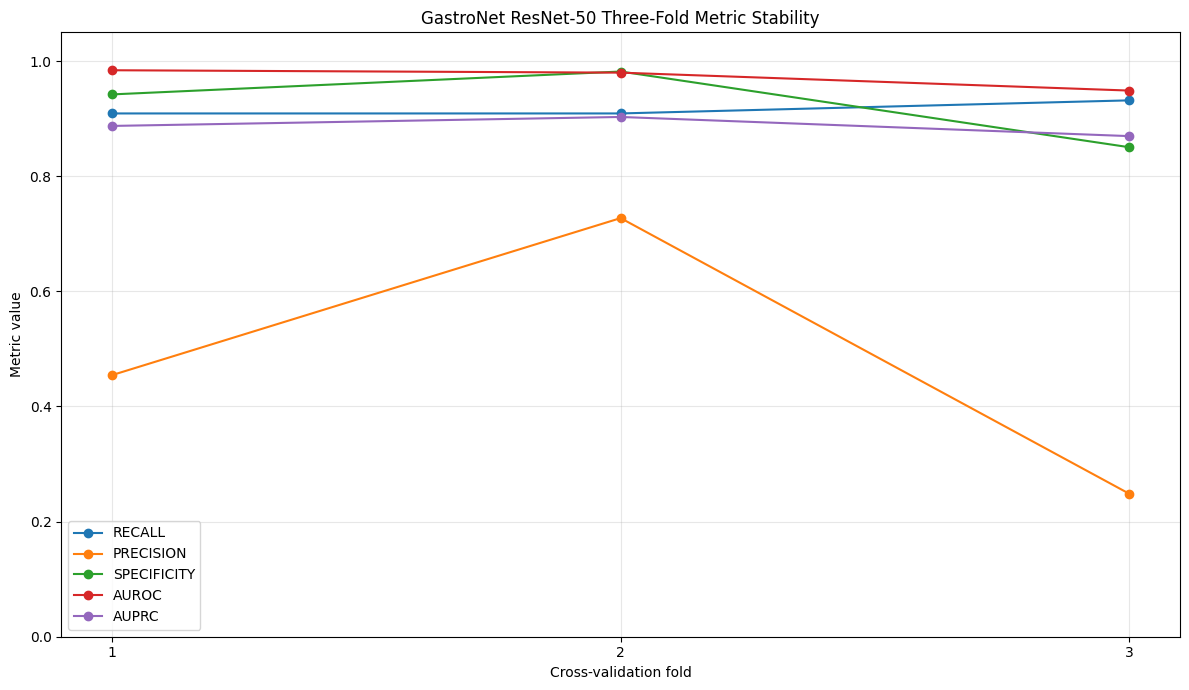

<Figure size 1000x600 with 0 Axes>

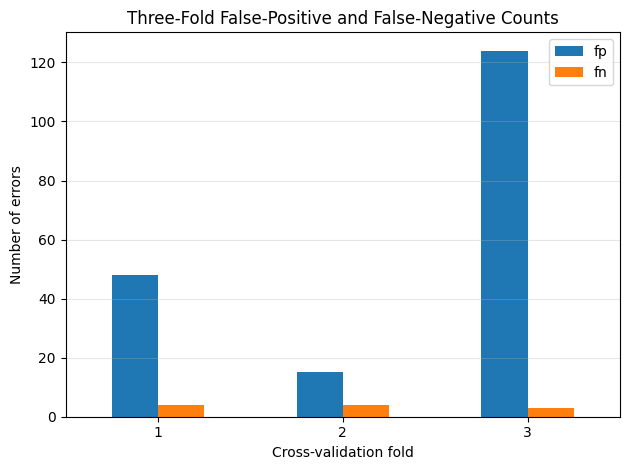

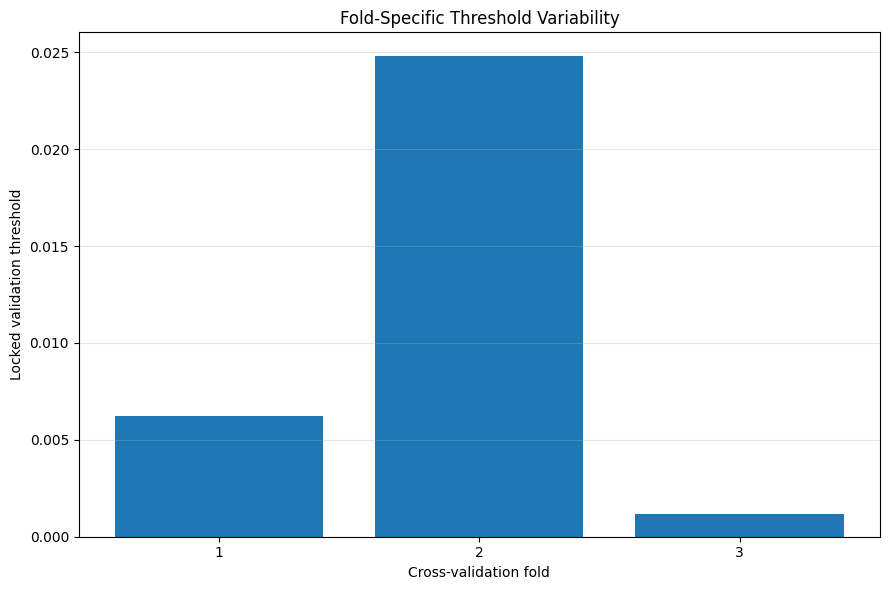

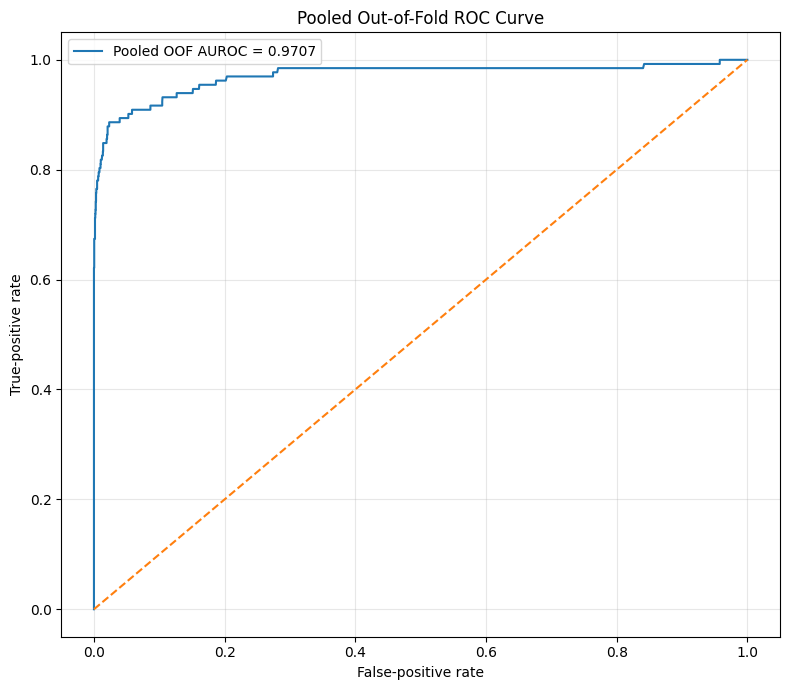

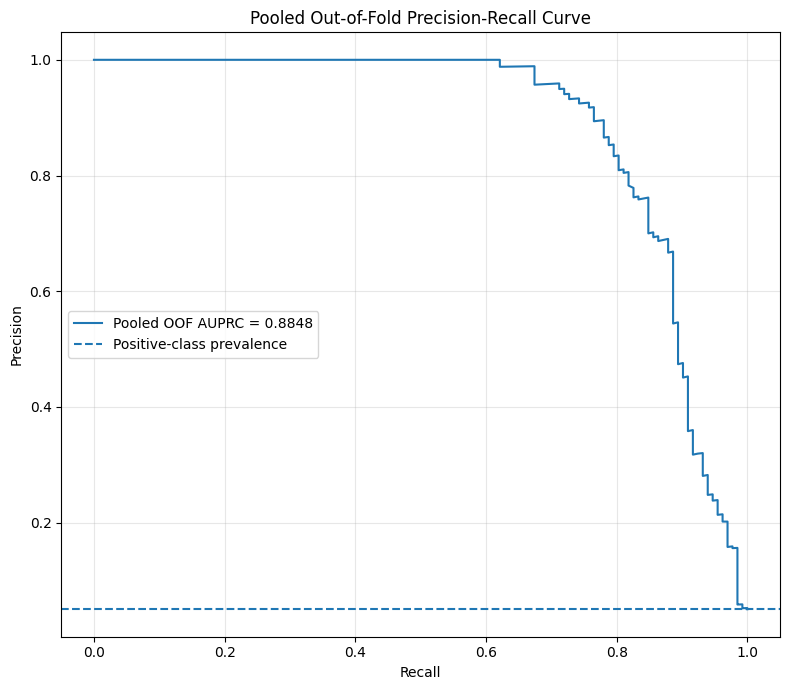


Fold-by-fold metrics:


,fold,threshold,sample_count,normal_count,positive_count,recall,precision,specificity,npv,accuracy,balanced_accuracy,f1,auroc,auprc,tp,tn,fp,fn
0,1,0.006218,874,830,44,0.909091,0.454545,0.942169,0.994911,0.940503,0.925630,0.606061,0.984132,0.887400,40,782,48,4
1,2,0.024796,873,829,44,0.909091,0.727273,0.981906,0.995110,0.978236,0.945498,0.808081,0.979973,0.902969,40,814,15,4
2,3,0.001147,873,829,44,0.931818,0.248485,0.850422,0.995763,0.854525,0.891120,0.392344,0.948829,0.869713,41,705,124,3



Macro mean and variability:


,metric,fold_1,fold_2,fold_3,mean,standard_deviation,minimum,maximum,range
0,recall,0.909091,0.909091,0.931818,0.916667,0.013122,0.909091,0.931818,0.022727
1,precision,0.454545,0.727273,0.248485,0.476768,0.240166,0.248485,0.727273,0.478788
2,specificity,0.942169,0.981906,0.850422,0.924832,0.067434,0.850422,0.981906,0.131484
3,npv,0.994911,0.995110,0.995763,0.995261,0.000446,0.994911,0.995763,0.000852
4,accuracy,0.940503,0.978236,0.854525,0.924421,0.063404,0.854525,0.978236,0.123711
5,balanced_accuracy,0.925630,0.945498,0.891120,0.920749,0.027516,0.891120,0.945498,0.054378
6,f1,0.606061,0.808081,0.392344,0.602162,0.207896,0.392344,0.808081,0.415736
7,auroc,0.984132,0.979973,0.948829,0.970978,0.019294,0.948829,0.984132,0.035303
8,auprc,0.887400,0.902969,0.869713,0.886694,0.016639,0.869713,0.902969,0.033256



Pooled OOF metrics:


...


Threshold summary:


,fold_count,mean_threshold,standard_deviation,median_threshold,minimum_threshold,maximum_threshold,threshold_range,maximum_to_minimum_ratio
0,3,0.01072,0.01245,0.006218,0.001147,0.024796,0.023648,21.612635



Variability assessment:


,measure,value,interpretation
0,auprc_range,0.033256,Ranking performance variability across folds
1,auroc_range,0.035303,Discrimination variability across folds
2,recall_range,0.022727,Sensitivity variability across fold-specific o...
3,ppv_range,0.478788,False-positive burden and calibration variabil...
4,specificity_range,0.131484,Negative-class operating variability across folds
5,threshold_range,0.023648,Probability calibration variability across sep...



FINAL CELL 12 THREE-FOLD AGGREGATE REPORT
OOF records: 2620/2620
Unique OOF cases: 2620/2620
Duplicate OOF cases: 0

Macro three-fold performance:
Mean AUPRC: 0.886694 ± 0.016639
Mean AUROC: 0.970978 ± 0.019294
Mean recall: 0.916667 ± 0.013122
Mean PPV: 0.476768 ± 0.240166
Mean specificity: 0.924832 ± 0.067434

Pooled OOF operating performance:
Recall: 0.916667
PPV: 0.392857
Specificity: 0.924839
AUROC: 0.970680
AUPRC: 0.884831
TP: 121
FP: 187
FN: 11
TN: 2301

Scientific assessment:
The GastroNet RN50 model shows consistently strong ranking performance and maintains at least 0.90 recall across all three folds. However, PPV, specificity and fold-specific thresholds vary substantially, indicating probability-calibration and false-positive instability.

Held-out test loaded: False
Held-out test evaluated: False
New training performed: False
New inference performed: False
New threshold search performed: False

STATUS: THREE_FOLD_CROSS_VALIDATION_AGGREGATE_COMPLETE

Saved records:
/content

In [12]:
# ============================================================
# RARE26 GastroNet Extension — CELL 12
# THREE-FOLD CROSS-VALIDATION AGGREGATE ANALYSIS
#
# Combines:
#   Fold 1 locked validation predictions
#   Fold 2 locked validation predictions
#   Fold 3 locked validation predictions
#
# Produces:
#   - Fold-by-fold metric comparison
#   - Mean, standard deviation, minimum and maximum
#   - Complete out-of-fold predictions for 2,620 images
#   - Pooled OOF operating metrics
#   - Per-centre pooled OOF metrics
#   - Threshold variability analysis
#   - Figures and final reproducibility status
#
# The original 468-image held-out test is NOT loaded or used.
# No model training or new inference is performed.
# ============================================================

from pathlib import Path
from datetime import datetime, timezone
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    roc_curve,
    precision_recall_curve,
)


# ============================================================
# 1. PROJECT PATHS
# ============================================================

PROJECT_ROOT = Path(
    "/content/drive/MyDrive/RARE26_GastroNet_Weights"
)

PREDICTION_ROOT = (
    PROJECT_ROOT
    / "predictions"
    / "cross_validation"
)

RESULT_ROOT = (
    PROJECT_ROOT
    / "results"
    / "cross_validation"
)

CENTRE_ROOT = (
    PROJECT_ROOT
    / "centre_analysis"
    / "cross_validation"
)

FIGURE_ROOT = (
    PROJECT_ROOT
    / "figures"
    / "cross_validation"
)

THRESHOLD_ROOT = (
    PROJECT_ROOT
    / "thresholds"
    / "cross_validation"
)

AGGREGATE_PREDICTION_DIR = (
    PREDICTION_ROOT
    / "aggregate"
)

AGGREGATE_RESULT_DIR = (
    RESULT_ROOT
    / "aggregate"
)

AGGREGATE_CENTRE_DIR = (
    CENTRE_ROOT
    / "aggregate"
)

AGGREGATE_FIGURE_DIR = (
    FIGURE_ROOT
    / "aggregate"
)

AGGREGATE_THRESHOLD_DIR = (
    THRESHOLD_ROOT
    / "aggregate"
)

for directory in [
    AGGREGATE_PREDICTION_DIR,
    AGGREGATE_RESULT_DIR,
    AGGREGATE_CENTRE_DIR,
    AGGREGATE_FIGURE_DIR,
    AGGREGATE_THRESHOLD_DIR,
]:
    directory.mkdir(
        parents=True,
        exist_ok=True,
    )


# ============================================================
# 2. INPUT FILES
# ============================================================

FOLD_FILES = {
    1: (
        PREDICTION_ROOT
        / "fold_1"
        / (
            "cv_fold_1_rn50_gastronet5m_dinov1_"
            "validation_predictions_locked_threshold.csv"
        )
    ),

    2: (
        PREDICTION_ROOT
        / "fold_2"
        / (
            "cv_fold_2_rn50_gastronet5m_dinov1_"
            "validation_predictions_locked_threshold.csv"
        )
    ),

    3: (
        PREDICTION_ROOT
        / "fold_3"
        / (
            "cv_fold_3_rn50_gastronet5m_dinov1_"
            "validation_predictions_locked_threshold.csv"
        )
    ),
}

STATUS_FILES = {
    1: (
        RESULT_ROOT
        / "fold_1"
        / (
            "cv_fold_1_rn50_gastronet5m_dinov1_"
            "status.json"
        )
    ),

    2: (
        RESULT_ROOT
        / "fold_2"
        / (
            "cv_fold_2_rn50_gastronet5m_dinov1_"
            "status.json"
        )
    ),

    3: (
        RESULT_ROOT
        / "fold_3"
        / (
            "cv_fold_3_rn50_gastronet5m_dinov1_"
            "status.json"
        )
    ),
}


# ============================================================
# 3. OUTPUT FILES
# ============================================================

OOF_PREDICTIONS_PATH = (
    AGGREGATE_PREDICTION_DIR
    / "cell12_three_fold_oof_predictions.csv"
)

FOLD_METRICS_PATH = (
    AGGREGATE_RESULT_DIR
    / "cell12_three_fold_metrics_by_fold.csv"
)

MACRO_SUMMARY_PATH = (
    AGGREGATE_RESULT_DIR
    / "cell12_three_fold_macro_summary.csv"
)

POOLED_METRICS_PATH = (
    AGGREGATE_RESULT_DIR
    / "cell12_three_fold_pooled_oof_metrics.csv"
)

POOLED_CENTRE_METRICS_PATH = (
    AGGREGATE_CENTRE_DIR
    / "cell12_three_fold_pooled_oof_per_centre.csv"
)

FOLD_CENTRE_METRICS_PATH = (
    AGGREGATE_CENTRE_DIR
    / "cell12_three_fold_per_fold_per_centre_metrics.csv"
)

THRESHOLD_TABLE_PATH = (
    AGGREGATE_THRESHOLD_DIR
    / "cell12_three_fold_thresholds.csv"
)

THRESHOLD_SUMMARY_PATH = (
    AGGREGATE_THRESHOLD_DIR
    / "cell12_three_fold_threshold_summary.csv"
)

VARIABILITY_PATH = (
    AGGREGATE_RESULT_DIR
    / "cell12_three_fold_variability_assessment.csv"
)

STATUS_PATH = (
    AGGREGATE_RESULT_DIR
    / "cell12_three_fold_aggregate_status.json"
)

SUMMARY_TEXT_PATH = (
    AGGREGATE_RESULT_DIR
    / "cell12_three_fold_aggregate_summary.txt"
)

METRIC_FIGURE_PATH = (
    AGGREGATE_FIGURE_DIR
    / "cell12_three_fold_metric_comparison.png"
)

ERROR_FIGURE_PATH = (
    AGGREGATE_FIGURE_DIR
    / "cell12_three_fold_error_counts.png"
)

THRESHOLD_FIGURE_PATH = (
    AGGREGATE_FIGURE_DIR
    / "cell12_three_fold_threshold_variability.png"
)

ROC_FIGURE_PATH = (
    AGGREGATE_FIGURE_DIR
    / "cell12_pooled_oof_roc_curve.png"
)

PR_FIGURE_PATH = (
    AGGREGATE_FIGURE_DIR
    / "cell12_pooled_oof_precision_recall_curve.png"
)


# ============================================================
# 4. INITIAL REPORT
# ============================================================

print("=" * 86)
print("CELL 12: THREE-FOLD CROSS-VALIDATION AGGREGATE ANALYSIS")
print("=" * 86)

print("\nFold prediction files:")

for fold_number, fold_path in FOLD_FILES.items():
    print(
        f"Fold {fold_number}: "
        f"{fold_path}"
    )

print("\nHeld-out test CSV loaded: False")
print("Held-out test predictions loaded: False")
print("Held-out test evaluated: False")
print("New model inference performed: False")
print("Model training performed: False")
print("New threshold search performed: False")


# ============================================================
# 5. VERIFY FOLD STATUS FILES
# ============================================================

expected_statuses = {
    1: (
        "FOLD_1_TRAINING_AND_THRESHOLD_LOCK_COMPLETE"
    ),

    2: (
        "FOLD_2_TRAINING_AND_THRESHOLD_LOCK_COMPLETE"
    ),

    3: (
        "FOLD_3_TRAINING_AND_THRESHOLD_LOCK_COMPLETE"
    ),
}

status_records = {}

for fold_number in [1, 2, 3]:

    status_path = STATUS_FILES[
        fold_number
    ]

    if not status_path.exists():
        raise FileNotFoundError(
            f"Fold {fold_number} status file was not found:\n"
            f"{status_path}"
        )

    status_record = json.loads(
        status_path.read_text(
            encoding="utf-8"
        )
    )

    actual_status = status_record.get(
        "status"
    )

    expected_status = expected_statuses[
        fold_number
    ]

    if actual_status != expected_status:
        raise RuntimeError(
            f"Fold {fold_number} is not fully complete.\n"
            f"Expected status: {expected_status}\n"
            f"Actual status: {actual_status}"
        )

    if status_record.get(
        "held_out_test_loaded",
        False,
    ):
        raise RuntimeError(
            f"Fold {fold_number} reports that the "
            "held-out test was loaded."
        )

    if status_record.get(
        "held_out_test_evaluated",
        False,
    ):
        raise RuntimeError(
            f"Fold {fold_number} reports that the "
            "held-out test was evaluated."
        )

    status_records[
        fold_number
    ] = status_record

print("\nAll three fold status files verified: True")


# ============================================================
# 6. METRIC HELPER
# ============================================================

def calculate_metrics_from_predictions(
    labels,
    probabilities,
    predictions,
):
    labels = np.asarray(
        labels,
        dtype=int,
    )

    probabilities = np.asarray(
        probabilities,
        dtype=float,
    )

    predictions = np.asarray(
        predictions,
        dtype=int,
    )

    tp = int(
        (
            (labels == 1)
            & (predictions == 1)
        ).sum()
    )

    tn = int(
        (
            (labels == 0)
            & (predictions == 0)
        ).sum()
    )

    fp = int(
        (
            (labels == 0)
            & (predictions == 1)
        ).sum()
    )

    fn = int(
        (
            (labels == 1)
            & (predictions == 0)
        ).sum()
    )

    recall = (
        tp / (tp + fn)
        if (tp + fn) > 0
        else np.nan
    )

    precision = (
        tp / (tp + fp)
        if (tp + fp) > 0
        else 0.0
    )

    specificity = (
        tn / (tn + fp)
        if (tn + fp) > 0
        else np.nan
    )

    npv = (
        tn / (tn + fn)
        if (tn + fn) > 0
        else np.nan
    )

    accuracy = (
        (tp + tn)
        / len(labels)
    )

    balanced_accuracy = (
        (recall + specificity)
        / 2
    )

    f1_score = (
        2 * precision * recall
        / (precision + recall)
        if (precision + recall) > 0
        else 0.0
    )

    if len(np.unique(labels)) == 2:
        auroc = float(
            roc_auc_score(
                labels,
                probabilities,
            )
        )

        auprc = float(
            average_precision_score(
                labels,
                probabilities,
            )
        )

    else:
        auroc = np.nan
        auprc = np.nan

    return {
        "sample_count": int(
            len(labels)
        ),

        "normal_count": int(
            (labels == 0).sum()
        ),

        "positive_count": int(
            (labels == 1).sum()
        ),

        "recall": float(
            recall
        ),

        "precision": float(
            precision
        ),

        "specificity": float(
            specificity
        ),

        "npv": float(
            npv
        ),

        "accuracy": float(
            accuracy
        ),

        "balanced_accuracy": float(
            balanced_accuracy
        ),

        "f1": float(
            f1_score
        ),

        "auroc": float(
            auroc
        ),

        "auprc": float(
            auprc
        ),

        "tp": tp,
        "tn": tn,
        "fp": fp,
        "fn": fn,
    }


# ============================================================
# 7. LOAD AND VERIFY EACH FOLD
# ============================================================

expected_fold_sizes = {
    1: 874,
    2: 873,
    3: 873,
}

expected_fold_class_counts = {
    1: {
        "normal": 830,
        "positive": 44,
    },

    2: {
        "normal": 829,
        "positive": 44,
    },

    3: {
        "normal": 829,
        "positive": 44,
    },
}

fold_dataframes = []
fold_metric_rows = []
fold_centre_metric_rows = []
threshold_rows = []

required_columns = {
    "relative_path",
    "center",
    "label",
    "probability",
    "locked_threshold",
    "prediction",
    "cv_case_id",
}

for fold_number in [1, 2, 3]:

    fold_path = FOLD_FILES[
        fold_number
    ]

    if not fold_path.exists():
        raise FileNotFoundError(
            f"Fold {fold_number} locked prediction file "
            f"was not found:\n{fold_path}"
        )

    fold_df = pd.read_csv(
        fold_path,
        low_memory=False,
    ).copy()

    missing_columns = (
        required_columns
        - set(fold_df.columns)
    )

    if missing_columns:
        raise RuntimeError(
            f"Fold {fold_number} is missing columns:\n"
            f"{sorted(missing_columns)}"
        )

    fold_df["fold"] = (
        fold_number
    )

    fold_df["label"] = (
        fold_df["label"]
        .astype(int)
    )

    fold_df["prediction"] = (
        fold_df["prediction"]
        .astype(int)
    )

    fold_df["probability"] = (
        fold_df["probability"]
        .astype(float)
    )

    fold_df["locked_threshold"] = (
        fold_df["locked_threshold"]
        .astype(float)
    )

    expected_size = (
        expected_fold_sizes[
            fold_number
        ]
    )

    if len(fold_df) != expected_size:
        raise RuntimeError(
            f"Fold {fold_number} should contain "
            f"{expected_size} predictions, "
            f"but contains {len(fold_df)}."
        )

    expected_normal = (
        expected_fold_class_counts[
            fold_number
        ]["normal"]
    )

    expected_positive = (
        expected_fold_class_counts[
            fold_number
        ]["positive"]
    )

    actual_normal = int(
        (fold_df["label"] == 0).sum()
    )

    actual_positive = int(
        (fold_df["label"] == 1).sum()
    )

    if (
        actual_normal != expected_normal
        or actual_positive != expected_positive
    ):
        raise RuntimeError(
            f"Fold {fold_number} class counts do not match.\n"
            f"Expected normal={expected_normal}, "
            f"positive={expected_positive}\n"
            f"Actual normal={actual_normal}, "
            f"positive={actual_positive}"
        )

    unique_thresholds = (
        fold_df[
            "locked_threshold"
        ].dropna().unique()
    )

    if len(unique_thresholds) != 1:
        raise RuntimeError(
            f"Fold {fold_number} does not contain "
            "one constant locked threshold."
        )

    locked_threshold = float(
        unique_thresholds[0]
    )

    reconstructed_predictions = (
        fold_df["probability"]
        >= locked_threshold
    ).astype(int)

    disagreement_count = int(
        (
            reconstructed_predictions
            != fold_df["prediction"]
        ).sum()
    )

    if disagreement_count != 0:
        raise RuntimeError(
            f"Fold {fold_number} contains "
            f"{disagreement_count} stored prediction "
            "disagreements."
        )

    fold_metrics = (
        calculate_metrics_from_predictions(
            labels=fold_df["label"],
            probabilities=fold_df["probability"],
            predictions=fold_df["prediction"],
        )
    )

    fold_metric_rows.append(
        {
            "fold": fold_number,
            "threshold": locked_threshold,
            **fold_metrics,
        }
    )

    threshold_rows.append(
        {
            "fold": fold_number,
            "locked_threshold": (
                locked_threshold
            ),
        }
    )

    for centre_name, centre_df in (
        fold_df.groupby(
            "center"
        )
    ):
        centre_metrics = (
            calculate_metrics_from_predictions(
                labels=centre_df["label"],
                probabilities=centre_df["probability"],
                predictions=centre_df["prediction"],
            )
        )

        fold_centre_metric_rows.append(
            {
                "fold": fold_number,
                "center": centre_name,
                "threshold": (
                    locked_threshold
                ),
                **centre_metrics,
            }
        )

    fold_dataframes.append(
        fold_df
    )

    print(
        f"\nFold {fold_number} verified:"
    )

    print(
        f"Records: {len(fold_df)}"
    )

    print(
        f"Threshold: "
        f"{locked_threshold:.12f}"
    )

    print(
        f"AUPRC: "
        f"{fold_metrics['auprc']:.6f}"
    )

    print(
        f"AUROC: "
        f"{fold_metrics['auroc']:.6f}"
    )

    print(
        f"Recall: "
        f"{fold_metrics['recall']:.6f}"
    )

    print(
        f"PPV: "
        f"{fold_metrics['precision']:.6f}"
    )

    print(
        f"Specificity: "
        f"{fold_metrics['specificity']:.6f}"
    )


# ============================================================
# 8. CREATE COMPLETE OOF DATASET
# ============================================================

oof_df = pd.concat(
    fold_dataframes,
    ignore_index=True,
)

oof_df = oof_df.sort_values(
    by=[
        "fold",
        "dataset_index",
    ],
).reset_index(
    drop=True
)

if len(oof_df) != 2620:
    raise RuntimeError(
        f"OOF predictions must contain 2,620 records, "
        f"but contain {len(oof_df)}."
    )

duplicate_case_count = int(
    oof_df[
        "cv_case_id"
    ].duplicated().sum()
)

if duplicate_case_count != 0:
    raise RuntimeError(
        f"OOF predictions contain "
        f"{duplicate_case_count} duplicate cases."
    )

if oof_df[
    "cv_case_id"
].nunique() != 2620:
    raise RuntimeError(
        "OOF predictions do not contain "
        "2,620 unique cases."
    )

oof_normal_count = int(
    (oof_df["label"] == 0).sum()
)

oof_positive_count = int(
    (oof_df["label"] == 1).sum()
)

if (
    oof_normal_count != 2488
    or oof_positive_count != 132
):
    raise RuntimeError(
        "OOF class distribution does not match "
        "the complete development pool."
    )

expected_centre_counts = {
    ("center_1", 0): 1884,
    ("center_1", 1): 51,
    ("center_2", 0): 604,
    ("center_2", 1): 81,
}

actual_centre_counts = (
    oof_df.groupby(
        [
            "center",
            "label",
        ]
    )
    .size()
    .to_dict()
)

if actual_centre_counts != expected_centre_counts:
    raise RuntimeError(
        "OOF centre/class distribution does not "
        "match the locked development pool.\n\n"
        f"Expected:\n{expected_centre_counts}\n\n"
        f"Actual:\n{actual_centre_counts}"
    )

oof_df[
    "oof_prediction_source"
] = (
    "fold_specific_model_and_locked_threshold"
)

oof_df.to_csv(
    OOF_PREDICTIONS_PATH,
    index=False,
)

print("\nComplete OOF verification:")
print(f"Records: {len(oof_df)}/2620")
print(
    f"Unique cases: "
    f"{oof_df['cv_case_id'].nunique()}/2620"
)
print(
    f"Duplicate cases: "
    f"{duplicate_case_count}"
)
print(
    f"Normal cases: "
    f"{oof_normal_count}/2488"
)
print(
    f"Neoplasia cases: "
    f"{oof_positive_count}/132"
)


# ============================================================
# 9. FOLD-BY-FOLD METRIC TABLE
# ============================================================

fold_metrics_df = pd.DataFrame(
    fold_metric_rows
).sort_values(
    "fold"
).reset_index(
    drop=True
)

fold_metrics_df.to_csv(
    FOLD_METRICS_PATH,
    index=False,
)

fold_centre_metrics_df = pd.DataFrame(
    fold_centre_metric_rows
).sort_values(
    [
        "fold",
        "center",
    ]
).reset_index(
    drop=True
)

fold_centre_metrics_df.to_csv(
    FOLD_CENTRE_METRICS_PATH,
    index=False,
)


# ============================================================
# 10. MACRO MEAN AND STANDARD DEVIATION
# ============================================================

macro_metric_names = [
    "recall",
    "precision",
    "specificity",
    "npv",
    "accuracy",
    "balanced_accuracy",
    "f1",
    "auroc",
    "auprc",
]

macro_rows = []

for metric_name in macro_metric_names:

    metric_values = (
        fold_metrics_df[
            metric_name
        ].astype(float)
    )

    macro_rows.append(
        {
            "metric": metric_name,

            "fold_1": float(
                metric_values.iloc[0]
            ),

            "fold_2": float(
                metric_values.iloc[1]
            ),

            "fold_3": float(
                metric_values.iloc[2]
            ),

            "mean": float(
                metric_values.mean()
            ),

            "standard_deviation": float(
                metric_values.std(
                    ddof=1
                )
            ),

            "minimum": float(
                metric_values.min()
            ),

            "maximum": float(
                metric_values.max()
            ),

            "range": float(
                metric_values.max()
                - metric_values.min()
            ),
        }
    )

macro_summary_df = pd.DataFrame(
    macro_rows
)

macro_summary_df.to_csv(
    MACRO_SUMMARY_PATH,
    index=False,
)


# ============================================================
# 11. POOLED OOF METRICS
# ============================================================

pooled_metrics = (
    calculate_metrics_from_predictions(
        labels=oof_df["label"],
        probabilities=oof_df["probability"],
        predictions=oof_df["prediction"],
    )
)

pooled_metrics_record = {
    "evaluation_type": (
        "pooled_out_of_fold"
    ),

    "threshold_type": (
        "fold_specific_locked_thresholds"
    ),

    **pooled_metrics,

    "important_probability_note": (
        "Pooled AUROC and AUPRC are descriptive because "
        "probabilities originate from three separately "
        "trained fold models with different calibration."
    ),

    "held_out_test_loaded": False,
    "held_out_test_evaluated": False,
}

pooled_metrics_df = pd.DataFrame(
    [
        pooled_metrics_record
    ]
)

pooled_metrics_df.to_csv(
    POOLED_METRICS_PATH,
    index=False,
)


# ============================================================
# 12. POOLED OOF PER-CENTRE METRICS
# ============================================================

pooled_centre_rows = []

for centre_name, centre_df in (
    oof_df.groupby(
        "center"
    )
):
    centre_metrics = (
        calculate_metrics_from_predictions(
            labels=centre_df["label"],
            probabilities=centre_df["probability"],
            predictions=centre_df["prediction"],
        )
    )

    pooled_centre_rows.append(
        {
            "center": centre_name,

            "threshold_type": (
                "fold_specific_locked_thresholds"
            ),

            **centre_metrics,
        }
    )

pooled_centre_metrics_df = pd.DataFrame(
    pooled_centre_rows
).sort_values(
    "center"
).reset_index(
    drop=True
)

pooled_centre_metrics_df.to_csv(
    POOLED_CENTRE_METRICS_PATH,
    index=False,
)


# ============================================================
# 13. THRESHOLD VARIABILITY
# ============================================================

threshold_df = pd.DataFrame(
    threshold_rows
).sort_values(
    "fold"
).reset_index(
    drop=True
)

threshold_df.to_csv(
    THRESHOLD_TABLE_PATH,
    index=False,
)

threshold_values = (
    threshold_df[
        "locked_threshold"
    ].astype(float)
)

threshold_summary_df = pd.DataFrame(
    [
        {
            "fold_count": 3,

            "mean_threshold": float(
                threshold_values.mean()
            ),

            "standard_deviation": float(
                threshold_values.std(
                    ddof=1
                )
            ),

            "median_threshold": float(
                threshold_values.median()
            ),

            "minimum_threshold": float(
                threshold_values.min()
            ),

            "maximum_threshold": float(
                threshold_values.max()
            ),

            "threshold_range": float(
                threshold_values.max()
                - threshold_values.min()
            ),

            "maximum_to_minimum_ratio": float(
                threshold_values.max()
                / threshold_values.min()
            ),
        }
    ]
)

threshold_summary_df.to_csv(
    THRESHOLD_SUMMARY_PATH,
    index=False,
)


# ============================================================
# 14. VARIABILITY ASSESSMENT
# ============================================================

def metric_range(
    metric_name,
):
    values = fold_metrics_df[
        metric_name
    ].astype(float)

    return float(
        values.max()
        - values.min()
    )


variability_rows = [
    {
        "measure": "auprc_range",
        "value": metric_range(
            "auprc"
        ),
        "interpretation": (
            "Ranking performance variability "
            "across folds"
        ),
    },

    {
        "measure": "auroc_range",
        "value": metric_range(
            "auroc"
        ),
        "interpretation": (
            "Discrimination variability "
            "across folds"
        ),
    },

    {
        "measure": "recall_range",
        "value": metric_range(
            "recall"
        ),
        "interpretation": (
            "Sensitivity variability "
            "across fold-specific operating points"
        ),
    },

    {
        "measure": "ppv_range",
        "value": metric_range(
            "precision"
        ),
        "interpretation": (
            "False-positive burden and calibration "
            "variability across folds"
        ),
    },

    {
        "measure": "specificity_range",
        "value": metric_range(
            "specificity"
        ),
        "interpretation": (
            "Negative-class operating variability "
            "across folds"
        ),
    },

    {
        "measure": "threshold_range",
        "value": float(
            threshold_values.max()
            - threshold_values.min()
        ),
        "interpretation": (
            "Probability calibration variability "
            "across separately trained fold models"
        ),
    },
]

variability_df = pd.DataFrame(
    variability_rows
)

variability_df.to_csv(
    VARIABILITY_PATH,
    index=False,
)


# ============================================================
# 15. METRIC COMPARISON FIGURE
# ============================================================

plot_metric_names = [
    "recall",
    "precision",
    "specificity",
    "auroc",
    "auprc",
]

figure = plt.figure(
    figsize=(12, 7)
)

for metric_name in plot_metric_names:
    plt.plot(
        fold_metrics_df[
            "fold"
        ],

        fold_metrics_df[
            metric_name
        ],

        marker="o",

        label=metric_name.upper(),
    )

plt.xticks(
    [
        1,
        2,
        3,
    ]
)

plt.ylim(
    0,
    1.05,
)

plt.xlabel(
    "Cross-validation fold"
)

plt.ylabel(
    "Metric value"
)

plt.title(
    "GastroNet ResNet-50 Three-Fold Metric Stability"
)

plt.grid(
    alpha=0.3
)

plt.legend()

plt.tight_layout()

figure.savefig(
    METRIC_FIGURE_PATH,
    dpi=200,
    bbox_inches="tight",
)

plt.show()
plt.close(figure)


# ============================================================
# 16. ERROR COUNT FIGURE
# ============================================================

error_plot_df = (
    fold_metrics_df[
        [
            "fold",
            "fp",
            "fn",
        ]
    ]
    .set_index(
        "fold"
    )
)

figure = plt.figure(
    figsize=(10, 6)
)

axis = error_plot_df.plot(
    kind="bar",
)

axis.set_xlabel(
    "Cross-validation fold"
)

axis.set_ylabel(
    "Number of errors"
)

axis.set_title(
    "Three-Fold False-Positive and False-Negative Counts"
)

axis.grid(
    axis="y",
    alpha=0.3,
)

plt.xticks(
    rotation=0
)

plt.tight_layout()

plt.savefig(
    ERROR_FIGURE_PATH,
    dpi=200,
    bbox_inches="tight",
)

plt.show()
plt.close()


# ============================================================
# 17. THRESHOLD FIGURE
# ============================================================

figure = plt.figure(
    figsize=(9, 6)
)

plt.bar(
    threshold_df[
        "fold"
    ].astype(str),

    threshold_df[
        "locked_threshold"
    ],
)

plt.xlabel(
    "Cross-validation fold"
)

plt.ylabel(
    "Locked validation threshold"
)

plt.title(
    "Fold-Specific Threshold Variability"
)

plt.grid(
    axis="y",
    alpha=0.3,
)

plt.tight_layout()

figure.savefig(
    THRESHOLD_FIGURE_PATH,
    dpi=200,
    bbox_inches="tight",
)

plt.show()
plt.close(figure)


# ============================================================
# 18. POOLED OOF ROC CURVE
# ============================================================

oof_labels = (
    oof_df[
        "label"
    ].to_numpy(
        dtype=int
    )
)

oof_probabilities = (
    oof_df[
        "probability"
    ].to_numpy(
        dtype=float
    )
)

false_positive_rates, true_positive_rates, _ = (
    roc_curve(
        oof_labels,
        oof_probabilities,
    )
)

figure = plt.figure(
    figsize=(8, 7)
)

plt.plot(
    false_positive_rates,
    true_positive_rates,
    label=(
        f"Pooled OOF AUROC = "
        f"{pooled_metrics['auroc']:.4f}"
    ),
)

plt.plot(
    [
        0,
        1,
    ],

    [
        0,
        1,
    ],

    linestyle="--",
)

plt.xlabel(
    "False-positive rate"
)

plt.ylabel(
    "True-positive rate"
)

plt.title(
    "Pooled Out-of-Fold ROC Curve"
)

plt.grid(
    alpha=0.3
)

plt.legend()

plt.tight_layout()

figure.savefig(
    ROC_FIGURE_PATH,
    dpi=200,
    bbox_inches="tight",
)

plt.show()
plt.close(figure)


# ============================================================
# 19. POOLED OOF PRECISION-RECALL CURVE
# ============================================================

precision_values, recall_values, _ = (
    precision_recall_curve(
        oof_labels,
        oof_probabilities,
    )
)

figure = plt.figure(
    figsize=(8, 7)
)

plt.plot(
    recall_values,
    precision_values,
    label=(
        f"Pooled OOF AUPRC = "
        f"{pooled_metrics['auprc']:.4f}"
    ),
)

plt.axhline(
    y=(
        oof_positive_count
        / len(oof_df)
    ),
    linestyle="--",
    label="Positive-class prevalence",
)

plt.xlabel(
    "Recall"
)

plt.ylabel(
    "Precision"
)

plt.title(
    "Pooled Out-of-Fold Precision-Recall Curve"
)

plt.grid(
    alpha=0.3
)

plt.legend()

plt.tight_layout()

figure.savefig(
    PR_FIGURE_PATH,
    dpi=200,
    bbox_inches="tight",
)

plt.show()
plt.close(figure)


# ============================================================
# 20. FINAL ASSESSMENT
# ============================================================

minimum_fold_recall = float(
    fold_metrics_df[
        "recall"
    ].min()
)

minimum_fold_auprc = float(
    fold_metrics_df[
        "auprc"
    ].min()
)

minimum_fold_auroc = float(
    fold_metrics_df[
        "auroc"
    ].min()
)

ppv_range = metric_range(
    "precision"
)

specificity_range = metric_range(
    "specificity"
)

high_sensitivity_consistent = bool(
    minimum_fold_recall >= 0.90
)

ranking_performance_strong = bool(
    minimum_fold_auprc >= 0.85
    and minimum_fold_auroc >= 0.94
)

operating_point_variability_present = bool(
    ppv_range > 0.20
    or specificity_range > 0.10
)

if (
    high_sensitivity_consistent
    and ranking_performance_strong
    and operating_point_variability_present
):
    scientific_assessment = (
        "The GastroNet RN50 model shows consistently strong "
        "ranking performance and maintains at least 0.90 recall "
        "across all three folds. However, PPV, specificity and "
        "fold-specific thresholds vary substantially, indicating "
        "probability-calibration and false-positive instability."
    )

elif (
    high_sensitivity_consistent
    and ranking_performance_strong
):
    scientific_assessment = (
        "The GastroNet RN50 model shows strong and stable "
        "three-fold performance at the selected sensitivity target."
    )

else:
    scientific_assessment = (
        "The GastroNet RN50 model shows meaningful fold-level "
        "variability that requires additional validation before "
        "final model locking."
    )


# ============================================================
# 21. SAVE STATUS
# ============================================================

FINAL_STATUS = (
    "THREE_FOLD_CROSS_VALIDATION_AGGREGATE_COMPLETE"
)

status_record = {
    "created_utc": datetime.now(
        timezone.utc
    ).isoformat(),

    "status": FINAL_STATUS,

    "model": (
        "RN50_GastroNet-5M_DINOv1.pth"
    ),

    "fold_count": 3,

    "oof_sample_count": int(
        len(oof_df)
    ),

    "oof_unique_case_count": int(
        oof_df[
            "cv_case_id"
        ].nunique()
    ),

    "oof_duplicate_case_count": int(
        duplicate_case_count
    ),

    "oof_normal_count": int(
        oof_normal_count
    ),

    "oof_positive_count": int(
        oof_positive_count
    ),

    "macro_mean_auprc": float(
        fold_metrics_df[
            "auprc"
        ].mean()
    ),

    "macro_std_auprc": float(
        fold_metrics_df[
            "auprc"
        ].std(
            ddof=1
        )
    ),

    "macro_mean_auroc": float(
        fold_metrics_df[
            "auroc"
        ].mean()
    ),

    "macro_std_auroc": float(
        fold_metrics_df[
            "auroc"
        ].std(
            ddof=1
        )
    ),

    "macro_mean_recall": float(
        fold_metrics_df[
            "recall"
        ].mean()
    ),

    "macro_mean_precision": float(
        fold_metrics_df[
            "precision"
        ].mean()
    ),

    "macro_mean_specificity": float(
        fold_metrics_df[
            "specificity"
        ].mean()
    ),

    "pooled_oof_recall": float(
        pooled_metrics[
            "recall"
        ]
    ),

    "pooled_oof_precision": float(
        pooled_metrics[
            "precision"
        ]
    ),

    "pooled_oof_specificity": float(
        pooled_metrics[
            "specificity"
        ]
    ),

    "pooled_oof_auroc": float(
        pooled_metrics[
            "auroc"
        ]
    ),

    "pooled_oof_auprc": float(
        pooled_metrics[
            "auprc"
        ]
    ),

    "high_sensitivity_consistent": (
        high_sensitivity_consistent
    ),

    "ranking_performance_strong": (
        ranking_performance_strong
    ),

    "operating_point_variability_present": (
        operating_point_variability_present
    ),

    "scientific_assessment": (
        scientific_assessment
    ),

    "held_out_test_loaded": False,
    "held_out_test_evaluated": False,
    "new_model_inference_performed": False,
    "model_training_performed": False,
    "new_threshold_search_performed": False,
}

STATUS_PATH.write_text(
    json.dumps(
        status_record,
        indent=2,
        ensure_ascii=False,
    ),
    encoding="utf-8",
)


# ============================================================
# 22. SAVE READABLE SUMMARY
# ============================================================

summary_lines = [
    "RARE26 GastroNet ResNet-50",
    "Three-Fold Cross-Validation Aggregate Summary",
    "=" * 72,
    "",
    "Model:",
    "RN50_GastroNet-5M_DINOv1.pth",
    "",
    f"OOF records: {len(oof_df)}",
    f"Unique OOF cases: {oof_df['cv_case_id'].nunique()}",
    f"Normal cases: {oof_normal_count}",
    f"Neoplasia cases: {oof_positive_count}",
    "",
    "Fold results:",
]

for _, fold_row in fold_metrics_df.iterrows():

    summary_lines.extend(
        [
            "",
            (
                f"Fold {int(fold_row['fold'])}:"
            ),
            (
                f"  Threshold: "
                f"{fold_row['threshold']:.12f}"
            ),
            (
                f"  AUPRC: "
                f"{fold_row['auprc']:.6f}"
            ),
            (
                f"  AUROC: "
                f"{fold_row['auroc']:.6f}"
            ),
            (
                f"  Recall: "
                f"{fold_row['recall']:.6f}"
            ),
            (
                f"  PPV: "
                f"{fold_row['precision']:.6f}"
            ),
            (
                f"  Specificity: "
                f"{fold_row['specificity']:.6f}"
            ),
            (
                f"  TP / FP / FN / TN: "
                f"{int(fold_row['tp'])} / "
                f"{int(fold_row['fp'])} / "
                f"{int(fold_row['fn'])} / "
                f"{int(fold_row['tn'])}"
            ),
        ]
    )

summary_lines.extend(
    [
        "",
        "Macro three-fold performance:",
        (
            f"Mean AUPRC: "
            f"{fold_metrics_df['auprc'].mean():.6f} "
            f"± {fold_metrics_df['auprc'].std(ddof=1):.6f}"
        ),
        (
            f"Mean AUROC: "
            f"{fold_metrics_df['auroc'].mean():.6f} "
            f"± {fold_metrics_df['auroc'].std(ddof=1):.6f}"
        ),
        (
            f"Mean recall: "
            f"{fold_metrics_df['recall'].mean():.6f} "
            f"± {fold_metrics_df['recall'].std(ddof=1):.6f}"
        ),
        (
            f"Mean PPV: "
            f"{fold_metrics_df['precision'].mean():.6f} "
            f"± {fold_metrics_df['precision'].std(ddof=1):.6f}"
        ),
        (
            f"Mean specificity: "
            f"{fold_metrics_df['specificity'].mean():.6f} "
            f"± {fold_metrics_df['specificity'].std(ddof=1):.6f}"
        ),
        "",
        "Pooled OOF operating performance:",
        (
            f"Recall: "
            f"{pooled_metrics['recall']:.6f}"
        ),
        (
            f"PPV: "
            f"{pooled_metrics['precision']:.6f}"
        ),
        (
            f"Specificity: "
            f"{pooled_metrics['specificity']:.6f}"
        ),
        (
            f"AUROC: "
            f"{pooled_metrics['auroc']:.6f}"
        ),
        (
            f"AUPRC: "
            f"{pooled_metrics['auprc']:.6f}"
        ),
        (
            f"TP / FP / FN / TN: "
            f"{pooled_metrics['tp']} / "
            f"{pooled_metrics['fp']} / "
            f"{pooled_metrics['fn']} / "
            f"{pooled_metrics['tn']}"
        ),
        "",
        "Scientific assessment:",
        scientific_assessment,
        "",
        (
            "Pooled AUROC and AUPRC are descriptive because "
            "probabilities came from separately trained fold models."
        ),
        "",
        "Held-out test loaded: No",
        "Held-out test evaluated: No",
        "New training performed: No",
        "New inference performed: No",
        "New threshold search performed: No",
        "",
        f"Status: {FINAL_STATUS}",
    ]
)

SUMMARY_TEXT_PATH.write_text(
    "\n".join(
        summary_lines
    ),
    encoding="utf-8",
)


# ============================================================
# 23. FINAL DISPLAY
# ============================================================

print("\nFold-by-fold metrics:")
display(fold_metrics_df)

print("\nMacro mean and variability:")
display(macro_summary_df)

print("\nPooled OOF metrics:")
display(pooled_metrics_df)

print("\nPooled OOF per-centre metrics:")
display(pooled_centre_metrics_df)

print("\nFold-specific per-centre metrics:")
display(fold_centre_metrics_df)

print("\nThresholds:")
display(threshold_df)

print("\nThreshold summary:")
display(threshold_summary_df)

print("\nVariability assessment:")
display(variability_df)

print("\n" + "=" * 86)
print("FINAL CELL 12 THREE-FOLD AGGREGATE REPORT")
print("=" * 86)

print(
    f"OOF records: "
    f"{len(oof_df)}/2620"
)

print(
    f"Unique OOF cases: "
    f"{oof_df['cv_case_id'].nunique()}/2620"
)

print(
    f"Duplicate OOF cases: "
    f"{duplicate_case_count}"
)

print("\nMacro three-fold performance:")

print(
    f"Mean AUPRC: "
    f"{fold_metrics_df['auprc'].mean():.6f} "
    f"± {fold_metrics_df['auprc'].std(ddof=1):.6f}"
)

print(
    f"Mean AUROC: "
    f"{fold_metrics_df['auroc'].mean():.6f} "
    f"± {fold_metrics_df['auroc'].std(ddof=1):.6f}"
)

print(
    f"Mean recall: "
    f"{fold_metrics_df['recall'].mean():.6f} "
    f"± {fold_metrics_df['recall'].std(ddof=1):.6f}"
)

print(
    f"Mean PPV: "
    f"{fold_metrics_df['precision'].mean():.6f} "
    f"± {fold_metrics_df['precision'].std(ddof=1):.6f}"
)

print(
    f"Mean specificity: "
    f"{fold_metrics_df['specificity'].mean():.6f} "
    f"± {fold_metrics_df['specificity'].std(ddof=1):.6f}"
)

print("\nPooled OOF operating performance:")

print(
    f"Recall: "
    f"{pooled_metrics['recall']:.6f}"
)

print(
    f"PPV: "
    f"{pooled_metrics['precision']:.6f}"
)

print(
    f"Specificity: "
    f"{pooled_metrics['specificity']:.6f}"
)

print(
    f"AUROC: "
    f"{pooled_metrics['auroc']:.6f}"
)

print(
    f"AUPRC: "
    f"{pooled_metrics['auprc']:.6f}"
)

print(
    f"TP: {pooled_metrics['tp']}"
)

print(
    f"FP: {pooled_metrics['fp']}"
)

print(
    f"FN: {pooled_metrics['fn']}"
)

print(
    f"TN: {pooled_metrics['tn']}"
)

print("\nScientific assessment:")
print(scientific_assessment)

print("\nHeld-out test loaded: False")
print("Held-out test evaluated: False")
print("New training performed: False")
print("New inference performed: False")
print("New threshold search performed: False")

print(
    f"\nSTATUS: "
    f"{FINAL_STATUS}"
)

print("\nSaved records:")
print(OOF_PREDICTIONS_PATH)
print(FOLD_METRICS_PATH)
print(MACRO_SUMMARY_PATH)
print(POOLED_METRICS_PATH)
print(POOLED_CENTRE_METRICS_PATH)
print(FOLD_CENTRE_METRICS_PATH)
print(THRESHOLD_TABLE_PATH)
print(THRESHOLD_SUMMARY_PATH)
print(VARIABILITY_PATH)
print(STATUS_PATH)
print(SUMMARY_TEXT_PATH)
print(METRIC_FIGURE_PATH)
print(ERROR_FIGURE_PATH)
print(THRESHOLD_FIGURE_PATH)
print(ROC_FIGURE_PATH)
print(PR_FIGURE_PATH)

In [13]:
# ============================================================
# RARE26 GastroNet Extension — CELL 13A
# PRETRAINED CHECKPOINT COMPATIBILITY AND PRIORITY AUDIT
#
# Purpose:
#   - Inspect all eight downloaded pretrained checkpoints
#   - Identify which checkpoints are directly compatible with
#     torchvision ResNet-50
#   - Rank compatible checkpoints for the next controlled
#     cross-validation experiment
#
# This cell performs:
#   - No model training
#   - No image inference
#   - No validation threshold search
#   - No held-out test loading or evaluation
# ============================================================

from pathlib import Path
from datetime import datetime, timezone
import gc
import json

import pandas as pd
import torch

from torchvision import models


# ============================================================
# 1. PROJECT PATHS
# ============================================================

PROJECT_ROOT = Path(
    "/content/drive/MyDrive/RARE26_GastroNet_Weights"
)

SOURCE_CHECKPOINT_DIR = (
    PROJECT_ROOT
    / "source_checkpoints"
)

INVENTORY_DIR = (
    PROJECT_ROOT
    / "inventory"
)

RESULTS_DIR = (
    PROJECT_ROOT
    / "results"
)

INVENTORY_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

RESULTS_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

AUDIT_CSV_PATH = (
    INVENTORY_DIR
    / "cell13a_checkpoint_compatibility_audit.csv"
)

PRIORITY_CSV_PATH = (
    INVENTORY_DIR
    / "cell13a_checkpoint_training_priority.csv"
)

STATUS_JSON_PATH = (
    RESULTS_DIR
    / "cell13a_checkpoint_compatibility_status.json"
)

SUMMARY_PATH = (
    RESULTS_DIR
    / "cell13a_checkpoint_compatibility_summary.txt"
)


# ============================================================
# 2. INITIAL REPORT
# ============================================================

print("=" * 88)
print("CELL 13A: PRETRAINED CHECKPOINT COMPATIBILITY AND PRIORITY AUDIT")
print("=" * 88)

print("\nSource checkpoint directory:")
print(SOURCE_CHECKPOINT_DIR)

print("\nHeld-out test CSV loaded: False")
print("Held-out test predictions loaded: False")
print("Held-out test evaluated: False")
print("Model training performed: False")
print("Image inference performed: False")
print("Threshold search performed: False")


# ============================================================
# 3. VERIFY SOURCE DIRECTORY AND CHECKPOINT COUNT
# ============================================================

if not SOURCE_CHECKPOINT_DIR.exists():
    raise FileNotFoundError(
        "Source checkpoint directory was not found:\n"
        f"{SOURCE_CHECKPOINT_DIR}"
    )

checkpoint_paths = sorted(
    SOURCE_CHECKPOINT_DIR.glob("*.pth"),
    key=lambda path: path.name.lower(),
)

print(
    f"\nCheckpoint files found: "
    f"{len(checkpoint_paths)}"
)

for checkpoint_path in checkpoint_paths:
    print(checkpoint_path.name)

if len(checkpoint_paths) != 8:
    raise RuntimeError(
        "Expected exactly eight .pth checkpoints, "
        f"but found {len(checkpoint_paths)}."
    )


# ============================================================
# 4. CREATE REFERENCE RESNET-50 STATE
# ============================================================

reference_model = models.resnet50(
    weights=None
)

reference_state = (
    reference_model.state_dict()
)

reference_keys = set(
    reference_state.keys()
)

reference_backbone_keys = {
    key
    for key in reference_keys
    if key not in {
        "fc.weight",
        "fc.bias",
    }
}

EXPECTED_RESNET50_BACKBONE_TENSORS = (
    len(reference_backbone_keys)
)

print(
    "\nReference torchvision ResNet-50 "
    f"backbone tensors: "
    f"{EXPECTED_RESNET50_BACKBONE_TENSORS}"
)

del reference_model
gc.collect()


# ============================================================
# 5. CHECKPOINT HELPER FUNCTIONS
# ============================================================

def extract_state_dict(
    checkpoint_object,
):
    """
    Extract the most likely model state dictionary from
    common checkpoint formats.
    """

    if isinstance(
        checkpoint_object,
        dict,
    ):

        preferred_keys = [
            "state_dict",
            "model_state_dict",
            "model",
            "backbone",
            "encoder",
            "student",
            "teacher",
        ]

        for preferred_key in preferred_keys:

            candidate = checkpoint_object.get(
                preferred_key
            )

            if (
                isinstance(candidate, dict)
                and len(candidate) > 0
            ):
                tensor_count = sum(
                    torch.is_tensor(value)
                    for value in candidate.values()
                )

                if tensor_count > 0:
                    return (
                        candidate,
                        preferred_key,
                    )

        tensor_values = [
            value
            for value in checkpoint_object.values()
            if torch.is_tensor(value)
        ]

        if (
            len(tensor_values) > 0
            and len(tensor_values)
            == len(checkpoint_object)
        ):
            return (
                checkpoint_object,
                "top_level_state_dict",
            )

    raise RuntimeError(
        "No recognizable tensor state dictionary "
        "was found."
    )


def normalize_parameter_key(
    parameter_key,
):
    """
    Remove common wrapper prefixes without changing
    actual layer names.
    """

    normalized_key = str(
        parameter_key
    )

    removable_prefixes = [
        "module.",
        "model.",
        "network.",
        "net.",
        "encoder.",
        "backbone.",
    ]

    changed = True

    while changed:
        changed = False

        for prefix in removable_prefixes:
            if normalized_key.startswith(
                prefix
            ):
                normalized_key = (
                    normalized_key[
                        len(prefix):
                    ]
                )

                changed = True
                break

    return normalized_key


def normalize_state_dict(
    state_dictionary,
):
    normalized_dictionary = {}

    duplicate_normalized_keys = []

    for original_key, value in (
        state_dictionary.items()
    ):

        normalized_key = (
            normalize_parameter_key(
                original_key
            )
        )

        if normalized_key in normalized_dictionary:
            duplicate_normalized_keys.append(
                normalized_key
            )

        normalized_dictionary[
            normalized_key
        ] = value

    return (
        normalized_dictionary,
        duplicate_normalized_keys,
    )


def identify_architecture_family(
    state_dictionary,
):
    keys = list(
        state_dictionary.keys()
    )

    resnet_signals = [
        key.startswith("conv1.")
        or key.startswith("bn1.")
        or key.startswith("layer1.")
        or key.startswith("layer2.")
        or key.startswith("layer3.")
        or key.startswith("layer4.")
        for key in keys
    ]

    vit_signals = [
        "patch_embed" in key
        or "cls_token" in key
        or key.startswith("blocks.")
        or ".blocks." in key
        or "pos_embed" in key
        for key in keys
    ]

    resnet_signal_count = sum(
        resnet_signals
    )

    vit_signal_count = sum(
        vit_signals
    )

    if (
        resnet_signal_count >= 20
        and resnet_signal_count
        > vit_signal_count
    ):
        return "resnet_like"

    if vit_signal_count >= 10:
        return "vision_transformer_like"

    return "unknown_or_wrapped"


# ============================================================
# 6. AUDIT EACH CHECKPOINT
# ============================================================

audit_rows = []
load_error_rows = []

for checkpoint_index, checkpoint_path in enumerate(
    checkpoint_paths,
    start=1,
):

    print("\n" + "-" * 88)

    print(
        f"Inspecting checkpoint "
        f"{checkpoint_index}/{len(checkpoint_paths)}:"
    )

    print(checkpoint_path.name)

    checkpoint_size_mb = (
        checkpoint_path.stat().st_size
        / (1024 ** 2)
    )

    try:
        checkpoint_object = torch.load(
            checkpoint_path,
            map_location="cpu",
            weights_only=False,
        )

        (
            raw_state_dict,
            extraction_source,
        ) = extract_state_dict(
            checkpoint_object
        )

        (
            normalized_state_dict,
            duplicate_normalized_keys,
        ) = normalize_state_dict(
            raw_state_dict
        )

        architecture_family = (
            identify_architecture_family(
                normalized_state_dict
            )
        )

        normalized_tensor_keys = {
            key
            for key, value
            in normalized_state_dict.items()
            if torch.is_tensor(value)
        }

        matched_keys = []
        matched_backbone_keys = []
        shape_mismatch_keys = []
        unexpected_tensor_keys = []

        for parameter_key in (
            normalized_tensor_keys
        ):

            parameter_value = (
                normalized_state_dict[
                    parameter_key
                ]
            )

            if parameter_key in reference_state:

                expected_shape = tuple(
                    reference_state[
                        parameter_key
                    ].shape
                )

                actual_shape = tuple(
                    parameter_value.shape
                )

                if actual_shape == expected_shape:

                    matched_keys.append(
                        parameter_key
                    )

                    if (
                        parameter_key
                        in reference_backbone_keys
                    ):
                        matched_backbone_keys.append(
                            parameter_key
                        )

                else:
                    shape_mismatch_keys.append(
                        parameter_key
                    )

            else:
                unexpected_tensor_keys.append(
                    parameter_key
                )

        missing_backbone_keys = sorted(
            reference_backbone_keys
            - set(
                matched_backbone_keys
            )
        )

        matched_backbone_count = len(
            matched_backbone_keys
        )

        exact_resnet50_backbone_compatible = bool(
            matched_backbone_count
            == EXPECTED_RESNET50_BACKBONE_TENSORS
            and len(
                missing_backbone_keys
            ) == 0
        )

        if exact_resnet50_backbone_compatible:
            compatibility_class = (
                "EXACT_RESNET50_BACKBONE"
            )

        elif (
            architecture_family
            == "resnet_like"
            and matched_backbone_count > 0
        ):
            compatibility_class = (
                "PARTIAL_RESNET_COMPATIBILITY"
            )

        elif (
            architecture_family
            == "vision_transformer_like"
        ):
            compatibility_class = (
                "SEPARATE_VIT_ARCHITECTURE_REQUIRED"
            )

        else:
            compatibility_class = (
                "UNKNOWN_OR_CUSTOM_ARCHITECTURE"
            )

        audit_row = {
            "checkpoint_filename": (
                checkpoint_path.name
            ),

            "checkpoint_path": str(
                checkpoint_path
            ),

            "checkpoint_size_mb": float(
                checkpoint_size_mb
            ),

            "checkpoint_load_successful": True,

            "state_dict_source": (
                extraction_source
            ),

            "raw_state_entry_count": int(
                len(raw_state_dict)
            ),

            "normalized_tensor_count": int(
                len(
                    normalized_tensor_keys
                )
            ),

            "architecture_family": (
                architecture_family
            ),

            "compatibility_class": (
                compatibility_class
            ),

            "exact_resnet50_backbone_compatible": (
                exact_resnet50_backbone_compatible
            ),

            "matched_reference_tensor_count": int(
                len(matched_keys)
            ),

            "matched_resnet50_backbone_count": int(
                matched_backbone_count
            ),

            "expected_resnet50_backbone_count": int(
                EXPECTED_RESNET50_BACKBONE_TENSORS
            ),

            "missing_resnet50_backbone_count": int(
                len(
                    missing_backbone_keys
                )
            ),

            "shape_mismatch_count": int(
                len(
                    shape_mismatch_keys
                )
            ),

            "unexpected_tensor_count": int(
                len(
                    unexpected_tensor_keys
                )
            ),

            "duplicate_normalized_key_count": int(
                len(
                    duplicate_normalized_keys
                )
            ),

            "missing_backbone_key_examples": (
                " | ".join(
                    missing_backbone_keys[:10]
                )
            ),

            "shape_mismatch_key_examples": (
                " | ".join(
                    sorted(
                        shape_mismatch_keys
                    )[:10]
                )
            ),

            "unexpected_key_examples": (
                " | ".join(
                    sorted(
                        unexpected_tensor_keys
                    )[:10]
                )
            ),

            "load_error": "",
        }

        audit_rows.append(
            audit_row
        )

        print(
            f"Architecture family: "
            f"{architecture_family}"
        )

        print(
            f"Compatibility: "
            f"{compatibility_class}"
        )

        print(
            "Matched ResNet-50 backbone tensors: "
            f"{matched_backbone_count}/"
            f"{EXPECTED_RESNET50_BACKBONE_TENSORS}"
        )

        print(
            f"Shape mismatches: "
            f"{len(shape_mismatch_keys)}"
        )

    except Exception as error:

        error_message = (
            f"{type(error).__name__}: "
            f"{error}"
        )

        audit_rows.append(
            {
                "checkpoint_filename": (
                    checkpoint_path.name
                ),

                "checkpoint_path": str(
                    checkpoint_path
                ),

                "checkpoint_size_mb": float(
                    checkpoint_size_mb
                ),

                "checkpoint_load_successful": False,

                "state_dict_source": "",

                "raw_state_entry_count": 0,

                "normalized_tensor_count": 0,

                "architecture_family": (
                    "inspection_failed"
                ),

                "compatibility_class": (
                    "INSPECTION_FAILED"
                ),

                "exact_resnet50_backbone_compatible": False,

                "matched_reference_tensor_count": 0,

                "matched_resnet50_backbone_count": 0,

                "expected_resnet50_backbone_count": int(
                    EXPECTED_RESNET50_BACKBONE_TENSORS
                ),

                "missing_resnet50_backbone_count": int(
                    EXPECTED_RESNET50_BACKBONE_TENSORS
                ),

                "shape_mismatch_count": 0,

                "unexpected_tensor_count": 0,

                "duplicate_normalized_key_count": 0,

                "missing_backbone_key_examples": "",

                "shape_mismatch_key_examples": "",

                "unexpected_key_examples": "",

                "load_error": error_message,
            }
        )

        load_error_rows.append(
            {
                "checkpoint_filename": (
                    checkpoint_path.name
                ),

                "error": error_message,
            }
        )

        print(
            f"Inspection error: "
            f"{error_message}"
        )

    finally:
        try:
            del checkpoint_object
        except Exception:
            pass

        try:
            del raw_state_dict
        except Exception:
            pass

        try:
            del normalized_state_dict
        except Exception:
            pass

        gc.collect()


# ============================================================
# 7. CREATE AUDIT TABLE
# ============================================================

audit_df = pd.DataFrame(
    audit_rows
)

audit_df = audit_df.sort_values(
    by=[
        "exact_resnet50_backbone_compatible",
        "checkpoint_filename",
    ],
    ascending=[
        False,
        True,
    ],
).reset_index(
    drop=True
)

audit_df.to_csv(
    AUDIT_CSV_PATH,
    index=False,
)


# ============================================================
# 8. ASSIGN SCIENTIFIC TRAINING PRIORITY
# ============================================================

CURRENT_COMPLETED_CHECKPOINT = (
    "RN50_GastroNet-5M_DINOv1.pth"
)

priority_map = {
    (
        "RN50_GastroNet-5M_DINOv1.pth"
    ): 0,

    (
        "RN50_Billion-Scale-SWSL%2B"
        "GastroNet-5M_DINOv1.pth"
    ): 1,

    (
        "RN50_GastroNet-5M_MOCOv2.pth"
    ): 2,

    (
        "RN50_GastroNet-5M_SIMCLRv2.pth"
    ): 3,

    (
        "RN50_GastroNet-1M_DINOv1.pth"
    ): 4,

    (
        "RN50_GastroNet-200K_DINOv1.pth"
    ): 5,

    (
        "VITS_GastroNet-5M_DINOv1.pth"
    ): 6,

    (
        "dinov2.pth"
    ): 7,
}

priority_reason_map = {
    (
        "RN50_GastroNet-5M_DINOv1.pth"
    ): (
        "Current lead candidate; original split, held-out "
        "evaluation and three-fold validation already complete."
    ),

    (
        "RN50_Billion-Scale-SWSL%2B"
        "GastroNet-5M_DINOv1.pth"
    ): (
        "Highest-priority next comparison: same ResNet-50 "
        "architecture and GastroNet-5M DINO objective, with "
        "additional billion-scale SWSL initialization."
    ),

    (
        "RN50_GastroNet-5M_MOCOv2.pth"
    ): (
        "Tests whether the MOCOv2 self-supervised objective "
        "improves calibration or false-positive stability."
    ),

    (
        "RN50_GastroNet-5M_SIMCLRv2.pth"
    ): (
        "Tests whether the SIMCLRv2 self-supervised objective "
        "improves calibration or false-positive stability."
    ),

    (
        "RN50_GastroNet-1M_DINOv1.pth"
    ): (
        "Dataset-scale ablation against the completed "
        "GastroNet-5M DINO model."
    ),

    (
        "RN50_GastroNet-200K_DINOv1.pth"
    ): (
        "Smaller pretraining-scale ablation; lower priority "
        "for challenge performance."
    ),

    (
        "VITS_GastroNet-5M_DINOv1.pth"
    ): (
        "Separate Vision Transformer architecture and training "
        "pipeline required; evaluate after RN50 comparisons."
    ),

    (
        "dinov2.pth"
    ): (
        "Large separate DINOv2 architecture; requires independent "
        "architecture identification and adaptation."
    ),
}

priority_rows = []

for _, audit_row in audit_df.iterrows():

    filename = audit_row[
        "checkpoint_filename"
    ]

    base_priority = priority_map.get(
        filename,
        99,
    )

    if filename == CURRENT_COMPLETED_CHECKPOINT:
        experiment_state = (
            "COMPLETED_CURRENT_LEAD"
        )

    elif bool(
        audit_row[
            "exact_resnet50_backbone_compatible"
        ]
    ):
        experiment_state = (
            "READY_FOR_CONTROLLED_RN50_COMPARISON"
        )

    elif (
        audit_row[
            "architecture_family"
        ]
        == "vision_transformer_like"
    ):
        experiment_state = (
            "REQUIRES_SEPARATE_VIT_PIPELINE"
        )

    else:
        experiment_state = (
            "REQUIRES_MANUAL_ARCHITECTURE_REVIEW"
        )

    effective_priority = (
        base_priority
        if experiment_state
        in {
            "COMPLETED_CURRENT_LEAD",
            "READY_FOR_CONTROLLED_RN50_COMPARISON",
        }
        else
        100 + base_priority
    )

    priority_rows.append(
        {
            "priority_order": int(
                effective_priority
            ),

            "checkpoint_filename": (
                filename
            ),

            "architecture_family": (
                audit_row[
                    "architecture_family"
                ]
            ),

            "compatibility_class": (
                audit_row[
                    "compatibility_class"
                ]
            ),

            "exact_resnet50_backbone_compatible": bool(
                audit_row[
                    "exact_resnet50_backbone_compatible"
                ]
            ),

            "experiment_state": (
                experiment_state
            ),

            "priority_reason": (
                priority_reason_map.get(
                    filename,
                    "No predefined priority reason."
                )
            ),
        }
    )

priority_df = pd.DataFrame(
    priority_rows
).sort_values(
    by=[
        "priority_order",
        "checkpoint_filename",
    ],
).reset_index(
    drop=True
)

priority_df.to_csv(
    PRIORITY_CSV_PATH,
    index=False,
)


# ============================================================
# 9. SELECT RECOMMENDED NEXT CHECKPOINT
# ============================================================

ready_candidates_df = priority_df[
    priority_df[
        "experiment_state"
    ]
    == "READY_FOR_CONTROLLED_RN50_COMPARISON"
].copy()

if len(ready_candidates_df) > 0:

    recommended_row = (
        ready_candidates_df
        .sort_values(
            "priority_order"
        )
        .iloc[0]
    )

    recommended_next_checkpoint = (
        recommended_row[
            "checkpoint_filename"
        ]
    )

    recommended_reason = (
        recommended_row[
            "priority_reason"
        ]
    )

else:
    recommended_next_checkpoint = None

    recommended_reason = (
        "No additional exact ResNet-50-compatible "
        "checkpoint was found."
    )


# ============================================================
# 10. FINAL STATUS
# ============================================================

exact_resnet50_count = int(
    audit_df[
        "exact_resnet50_backbone_compatible"
    ].sum()
)

inspection_failure_count = int(
    (
        ~audit_df[
            "checkpoint_load_successful"
        ]
    ).sum()
)

FINAL_STATUS = (
    "CHECKPOINT_COMPATIBILITY_AND_PRIORITY_AUDIT_COMPLETE"
)

status_record = {
    "created_utc": datetime.now(
        timezone.utc
    ).isoformat(),

    "status": FINAL_STATUS,

    "checkpoint_count": int(
        len(audit_df)
    ),

    "successfully_inspected_count": int(
        audit_df[
            "checkpoint_load_successful"
        ].sum()
    ),

    "inspection_failure_count": (
        inspection_failure_count
    ),

    "exact_resnet50_compatible_count": (
        exact_resnet50_count
    ),

    "current_completed_checkpoint": (
        CURRENT_COMPLETED_CHECKPOINT
    ),

    "recommended_next_checkpoint": (
        recommended_next_checkpoint
    ),

    "recommended_reason": (
        recommended_reason
    ),

    "held_out_test_loaded": False,
    "held_out_test_evaluated": False,
    "model_training_performed": False,
    "image_inference_performed": False,
    "threshold_search_performed": False,
}

STATUS_JSON_PATH.write_text(
    json.dumps(
        status_record,
        indent=2,
        ensure_ascii=False,
    ),
    encoding="utf-8",
)


# ============================================================
# 11. READABLE SUMMARY
# ============================================================

summary_lines = [
    "RARE26 GastroNet Pretrained Checkpoint Audit",
    "=" * 72,
    "",
    (
        f"Checkpoint files inspected: "
        f"{len(audit_df)}"
    ),
    (
        f"Exact ResNet-50-compatible checkpoints: "
        f"{exact_resnet50_count}"
    ),
    (
        f"Inspection failures: "
        f"{inspection_failure_count}"
    ),
    "",
    (
        f"Current completed lead: "
        f"{CURRENT_COMPLETED_CHECKPOINT}"
    ),
    "",
    (
        f"Recommended next checkpoint: "
        f"{recommended_next_checkpoint}"
    ),
    "",
    (
        f"Reason: "
        f"{recommended_reason}"
    ),
    "",
    "Held-out test loaded: No",
    "Held-out test evaluated: No",
    "Training performed: No",
    "Inference performed: No",
    "Threshold search performed: No",
    "",
    f"Status: {FINAL_STATUS}",
]

SUMMARY_PATH.write_text(
    "\n".join(
        summary_lines
    ),
    encoding="utf-8",
)


# ============================================================
# 12. FINAL DISPLAY
# ============================================================

print("\nCheckpoint compatibility audit:")
display(
    audit_df[
        [
            "checkpoint_filename",
            "checkpoint_size_mb",
            "architecture_family",
            "compatibility_class",
            "matched_resnet50_backbone_count",
            "expected_resnet50_backbone_count",
            "shape_mismatch_count",
            "unexpected_tensor_count",
        ]
    ]
)

print("\nControlled experiment priority:")
display(priority_df)

print("\n" + "=" * 88)
print("FINAL CELL 13A CHECKPOINT AUDIT REPORT")
print("=" * 88)

print(
    f"Checkpoints inspected: "
    f"{len(audit_df)}/8"
)

print(
    "Exact ResNet-50-compatible checkpoints: "
    f"{exact_resnet50_count}"
)

print(
    f"Inspection failures: "
    f"{inspection_failure_count}"
)

print("\nCurrent lead checkpoint:")
print(CURRENT_COMPLETED_CHECKPOINT)

print("\nRecommended next checkpoint:")
print(recommended_next_checkpoint)

print("\nRecommendation reason:")
print(recommended_reason)

print("\nHeld-out test loaded: False")
print("Held-out test evaluated: False")
print("Model training performed: False")
print("Image inference performed: False")
print("Threshold search performed: False")

print(
    f"\nSTATUS: "
    f"{FINAL_STATUS}"
)

print("\nSaved records:")
print(AUDIT_CSV_PATH)
print(PRIORITY_CSV_PATH)
print(STATUS_JSON_PATH)
print(SUMMARY_PATH)

CELL 13A: PRETRAINED CHECKPOINT COMPATIBILITY AND PRIORITY AUDIT

Source checkpoint directory:
/content/drive/MyDrive/RARE26_GastroNet_Weights/source_checkpoints

Held-out test CSV loaded: False
Held-out test predictions loaded: False
Held-out test evaluated: False
Model training performed: False
Image inference performed: False
Threshold search performed: False

Checkpoint files found: 8
dinov2.pth
RN50_Billion-Scale-SWSL%2BGastroNet-5M_DINOv1.pth
RN50_GastroNet-1M_DINOv1.pth
RN50_GastroNet-200K_DINOv1.pth
RN50_GastroNet-5M_DINOv1.pth
RN50_GastroNet-5M_MOCOv2.pth
RN50_GastroNet-5M_SIMCLRv2.pth
VITS_GastroNet-5M_DINOv1.pth

Reference torchvision ResNet-50 backbone tensors: 318

----------------------------------------------------------------------------------------
Inspecting checkpoint 1/8:
dinov2.pth
Architecture family: vision_transformer_like
Compatibility: SEPARATE_VIT_ARCHITECTURE_REQUIRED
Matched ResNet-50 backbone tensors: 0/318
Shape mismatches: 0

----------------------------

,checkpoint_filename,checkpoint_size_mb,architecture_family,compatibility_class,matched_resnet50_backbone_count,expected_resnet50_backbone_count,shape_mismatch_count,unexpected_tensor_count
0,RN50_Billion-Scale-SWSL%2BGastroNet-5M_DINOv1.pth,89.985167,resnet_like,EXACT_RESNET50_BACKBONE,318,318,0,0
1,RN50_GastroNet-1M_DINOv1.pth,89.979332,resnet_like,EXACT_RESNET50_BACKBONE,318,318,0,0
2,RN50_GastroNet-200K_DINOv1.pth,89.979946,resnet_like,EXACT_RESNET50_BACKBONE,318,318,0,0
3,RN50_GastroNet-5M_DINOv1.pth,89.979332,resnet_like,EXACT_RESNET50_BACKBONE,318,318,0,0
4,RN50_GastroNet-5M_MOCOv2.pth,89.979332,resnet_like,EXACT_RESNET50_BACKBONE,318,318,0,0
5,RN50_GastroNet-5M_SIMCLRv2.pth,89.979946,resnet_like,EXACT_RESNET50_BACKBONE,318,318,0,0
6,VITS_GastroNet-5M_DINOv1.pth,82.699890,vision_transformer_like,SEPARATE_VIT_ARCHITECTURE_REQUIRED,0,318,0,150
7,dinov2.pth,416.309958,vision_transformer_like,SEPARATE_VIT_ARCHITECTURE_REQUIRED,0,318,0,184



Controlled experiment priority:


,priority_order,checkpoint_filename,architecture_family,compatibility_class,exact_resnet50_backbone_compatible,experiment_state,priority_reason
0,0,RN50_GastroNet-5M_DINOv1.pth,resnet_like,EXACT_RESNET50_BACKBONE,True,COMPLETED_CURRENT_LEAD,"Current lead candidate; original split, held-o..."
1,1,RN50_Billion-Scale-SWSL%2BGastroNet-5M_DINOv1.pth,resnet_like,EXACT_RESNET50_BACKBONE,True,READY_FOR_CONTROLLED_RN50_COMPARISON,Highest-priority next comparison: same ResNet-...
2,2,RN50_GastroNet-5M_MOCOv2.pth,resnet_like,EXACT_RESNET50_BACKBONE,True,READY_FOR_CONTROLLED_RN50_COMPARISON,Tests whether the MOCOv2 self-supervised objec...
3,3,RN50_GastroNet-5M_SIMCLRv2.pth,resnet_like,EXACT_RESNET50_BACKBONE,True,READY_FOR_CONTROLLED_RN50_COMPARISON,Tests whether the SIMCLRv2 self-supervised obj...
4,4,RN50_GastroNet-1M_DINOv1.pth,resnet_like,EXACT_RESNET50_BACKBONE,True,READY_FOR_CONTROLLED_RN50_COMPARISON,Dataset-scale ablation against the completed G...
5,5,RN50_GastroNet-200K_DINOv1.pth,resnet_like,EXACT_RESNET50_BACKBONE,True,READY_FOR_CONTROLLED_RN50_COMPARISON,Smaller pretraining-scale ablation; lower prio...
6,106,VITS_GastroNet-5M_DINOv1.pth,vision_transformer_like,SEPARATE_VIT_ARCHITECTURE_REQUIRED,False,REQUIRES_SEPARATE_VIT_PIPELINE,Separate Vision Transformer architecture and t...
7,107,dinov2.pth,vision_transformer_like,SEPARATE_VIT_ARCHITECTURE_REQUIRED,False,REQUIRES_SEPARATE_VIT_PIPELINE,Large separate DINOv2 architecture; requires i...



FINAL CELL 13A CHECKPOINT AUDIT REPORT
Checkpoints inspected: 8/8
Exact ResNet-50-compatible checkpoints: 6
Inspection failures: 0

Current lead checkpoint:
RN50_GastroNet-5M_DINOv1.pth

Recommended next checkpoint:
RN50_Billion-Scale-SWSL%2BGastroNet-5M_DINOv1.pth

Recommendation reason:
Highest-priority next comparison: same ResNet-50 architecture and GastroNet-5M DINO objective, with additional billion-scale SWSL initialization.

Held-out test loaded: False
Held-out test evaluated: False
Model training performed: False
Image inference performed: False
Threshold search performed: False

STATUS: CHECKPOINT_COMPATIBILITY_AND_PRIORITY_AUDIT_COMPLETE

Saved records:
/content/drive/MyDrive/RARE26_GastroNet_Weights/inventory/cell13a_checkpoint_compatibility_audit.csv
/content/drive/MyDrive/RARE26_GastroNet_Weights/inventory/cell13a_checkpoint_training_priority.csv
/content/drive/MyDrive/RARE26_GastroNet_Weights/results/cell13a_checkpoint_compatibility_status.json
/content/drive/MyDrive/RA